# pC1 → Song Premotor Neuron Path Discovery (per-edge weight + path EW filter)

Identifies all **disynaptic** (pC1 → DN → premotor) paths in the male CNS connectome (`malecns:v0.9`).

**Song premotor targets:** dPR1, vPR9_a/b/c, TN1a_a–i  
**pC1 sources:** all P1_* and pC1x_* subtypes, right hemisphere

## Section 0: Configuration & Imports

In [ ]:
import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
matplotlib.rcParams.update({
    'svg.fonttype':    'none',          # editable text in Illustrator
    'font.family':     'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
})

# =====================================================================
# CONFIGURE PATHS (edit paths if needed)
# =====================================================================
BEHAVIORAL_REPO = Path(os.environ.get(
    'BEHAVIORAL_REPO',
    '/Users/otopalika/Documents/GitHub/pC1BehavioralAnalysis'
))
CONNECTOME_REPO = Path(os.environ.get(
    'CONNECTOME_REPO',
    '/Users/otopalika/Documents/GitHub/connectome_interpreter_Janelia'
))
# =====================================================================

sys.path.insert(0, str(CONNECTOME_REPO / 'src'))
from connectome_interpreter import find_paths_of_length, filter_paths, group_paths, plot_layered_paths

DATA_DIR    = CONNECTOME_REPO / 'data'
RESULTS_DIR = BEHAVIORAL_REPO / 'results' / 'path_discovery'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DATASET          = 'malecns_v0.9'
WEIGHT_THRESHOLD = 10       # minimum synapse count to retain an edge (pre-filter)
EW_THRESHOLD     = 0.0001  # minimum Hoeller EW for full disynaptic path (w_norm_l1 × w_norm_l2)
EW_THRESHOLD_3   = 0.0001  # minimum Hoeller EW for trisynaptic plot (paths are ~10-100× smaller)
NODE_SIZE        = 500     # diameter of nodes in path plots (pixels²)
NODE_OUTLINE          = False   # set True to draw a black border around nodes
CENTER_SEED_ARROWS    = True    # anchor seed-node arrow tails to output-facing circle edge
SEED_COLOR_BY         = 'signed_ew'  # 'signed_ew' | 'ei_ratio' (excit/inhib ratio)
SEED_CMAP             = 'pwg'        # 'bwr' (blue-white-red) | 'pwg' (purple-white-green)
EI_RATIO_MAX          = 60            # clip range for log E/I colormap: [1/MAX, MAX]

# Song premotor neuron targets
PREMOTOR_SUBTYPES = [
    # Pulse-promoting
    'dPR1',
    'vMS12_a', 'vMS12_b', 'vMS12_c', 'vMS12_d', 'vMS12_e',
    'dMS9',
    # Inhibitory switches (vPR9_a suppresses pulse; vPR9_b/c suppress sine)
    'vPR9_a', 'vPR9_b', 'vPR9_c',
    # Sine-promoting
    'dMS2',
    'TN1a_a', 'TN1a_b', 'TN1a_c', 'TN1a_d', 'TN1a_e',
    'TN1a_f', 'TN1a_g', 'TN1a_h', 'TN1a_i',
]

PREMOTOR_GROUPS = {
    'dPR1':  ['dPR1'],
    'vMS12': ['vMS12_a', 'vMS12_b', 'vMS12_c', 'vMS12_d', 'vMS12_e'],
    'TN1a':  ['TN1a_a', 'TN1a_b', 'TN1a_c', 'TN1a_d', 'TN1a_e',
              'TN1a_f', 'TN1a_g', 'TN1a_h', 'TN1a_i'],
    'dMS2':  ['dMS2'],
    'dMS9':  ['dMS9'],
    'vPR9':  ['vPR9_a', 'vPR9_b', 'vPR9_c'],
}
PREMOTOR_TARGETS = list(PREMOTOR_GROUPS.keys())  # 6 grouped names used for features


# NT color scheme (for edges)
#NT_COLOR = {
#    'acetylcholine': '#EE672D',
#    'gaba':          '#1F4695',
#    'glutamate':     '#09A64D',
#    'other':         '#979DA5',
#}

# New NT color scheme (for edges)
NT_COLOR = {
    'acetylcholine': '#09A64D',
    'gaba':          "#DD92F4",
    'glutamate':     '#BC07F3',
    'other':         '#1F4695',
}

# NT sign for effective weight computation
NT_SIGN = {'acetylcholine': 1, 'gaba': -1, 'glutamate': -1}  # 'other' → 0

# Smooth blue-white-red colormap for seed node coloring (shared across sections)
_cmap_colors = [
    (  0/255,   0/255, 255/255),  # pure blue  (#0000ff)
    (255/255, 255/255, 255/255),  # white      (#ffffff)
    (255/255,   0/255,   0/255),  # pure red   (#ff0000)
]
BWR_CMAP = LinearSegmentedColormap.from_list('blue_white_red', _cmap_colors, N=256)

_pwg_colors = [
    (128/255,   0/255, 128/255),  # purple  (128,   0, 128)
    (255/255, 255/255, 255/255),  # white   (255, 255, 255)
    (  0/255, 128/255,   0/255),  # green   (  0, 128,   0)
]
PWG_CMAP = LinearSegmentedColormap.from_list('purple_white_green', _pwg_colors, N=256)

VERTICAL_LAYOUT  = True          # True → seeds top, targets bottom; False → left→right
# Node colour overrides (hex string overrides default; None = use existing logic)
SEED_COLOR   = None#'#CCCCCC'    # None → BWR colourmap per signed EW; '#rrggbb' → uniform
INTER_COLOR  = '#8C6BAE'    # None → default lightblue; '#rrggbb' → uniform
TARGET_COLOR = '#53A78B'    # None → default lightblue; '#rrggbb' → uniform
print('Configuration complete.')

Configuration complete.


## Section 1: Load Connectome Data

In [17]:
# Neuron metadata
meta = pd.read_csv(DATA_DIR / f'{DATASET}_meta.csv', index_col=0)
meta['nt'] = meta['nt'].replace(
    ['histamine', 'dopamine', 'octopamine', 'serotonin', 'unclear'], 'other'
)

# Load manual NT overrides
manual_nt_file = CONNECTOME_REPO / 'src' / 'pC1toSongDNs' / 'manual_nt_identification.csv'
if manual_nt_file.exists():
    manual_nt = pd.read_csv(manual_nt_file, header=None, names=['cell_type', 'nt', 'notes'])
    manual_nt['cell_type'] = manual_nt['cell_type'].str.strip().str.replace('\ufeff', '', regex=False)
    manual_nt['nt'] = manual_nt['nt'].str.strip().replace(
        ['histamine', 'dopamine', 'octopamine', 'serotonin', 'unclear'], 'other'
    )
    for _, row in manual_nt.iterrows():
        meta.loc[meta['cell_type'] == row['cell_type'], 'nt'] = row['nt']
    print(f'Applied {len(manual_nt)} manual NT overrides.')

# Connectivity matrix (rows = pre, columns = post)
prop = sp.sparse.load_npz(DATA_DIR / f'{DATASET}_prop.npz')

# Lookup dicts
idx_to_type       = dict(zip(meta['idx'].astype(int), meta['cell_type']))
idx_to_superclass = dict(zip(meta['idx'].astype(int), meta['superclass']))
type_to_nt        = dict(zip(meta['cell_type'], meta['nt']))

valid_types = {t for t in meta['cell_type'].unique() if isinstance(t, str)}

# Verify targets
missing = [t for t in PREMOTOR_SUBTYPES if t not in valid_types]
if missing:
    print(f'WARNING: missing from connectome: {missing}')
else:
    print(f'All {len(PREMOTOR_SUBTYPES)} premotor subtypes found.')

print(f'Connectome: {len(meta):,} neurons, matrix {prop.shape}')

All 20 premotor subtypes found.
Connectome: 162,065 neurons, matrix (162065, 162065)


## Section 2: Define Sources and Targets

In [18]:
# pC1 source neurons: all P1_* and pC1x_* subtypes, right hemisphere
pC1_types = sorted(t for t in valid_types if t.startswith('P1_') or t.startswith('pC1x_'))
inidx = meta['idx'][
    meta['cell_type'].isin(pC1_types) & (meta['side'] == 'right')
].astype(int).values

# Premotor target neurons (both sides where applicable)
outidx = meta['idx'][meta['cell_type'].isin(PREMOTOR_SUBTYPES)].astype(int).values

print(f'pC1 source types ({len(pC1_types)}): {pC1_types}')
print(f'\npC1 source neurons (right hemisphere): {len(inidx)}')
print(f'Premotor target neurons: {len(outidx)} '
      f'(from {len(PREMOTOR_SUBTYPES)} subtypes, {len(PREMOTOR_TARGETS)} groups)')

pC1 source types (49): ['P1_10a', 'P1_10b', 'P1_10c', 'P1_10d', 'P1_11a', 'P1_11b', 'P1_12a', 'P1_12b', 'P1_13a', 'P1_13b', 'P1_13c', 'P1_14a', 'P1_14b', 'P1_15a', 'P1_15b', 'P1_15c', 'P1_16a', 'P1_16b', 'P1_17a', 'P1_17b', 'P1_18a', 'P1_18b', 'P1_19', 'P1_1a', 'P1_1b', 'P1_2a', 'P1_2a/2b', 'P1_2b', 'P1_2c', 'P1_3a', 'P1_3b', 'P1_3c', 'P1_4a', 'P1_4b', 'P1_5a', 'P1_5b', 'P1_6a', 'P1_6b', 'P1_7a', 'P1_7b', 'P1_8a', 'P1_8b', 'P1_8c', 'P1_9a', 'P1_9b', 'pC1x_a', 'pC1x_b', 'pC1x_c', 'pC1x_d']

pC1 source neurons (right hemisphere): 78
Premotor target neurons: 73 (from 20 subtypes, 6 groups)


## Section 3: Disynaptic Paths  (pC1 → DN → premotor)

In [19]:
# Cache to avoid recomputing
cache_2 = RESULTS_DIR / f'{DATASET}_disynaptic_paths.csv'

if cache_2.exists():
    print('Loading cached disynaptic paths...')
    paths_2 = pd.read_csv(cache_2)
else:
    print('Computing disynaptic paths...')
    paths_2 = find_paths_of_length(prop, inidx, outidx, target_layer_number=2)
    if paths_2 is not None and not paths_2.empty:
        paths_2 = filter_paths(paths_2, threshold=WEIGHT_THRESHOLD)
        paths_2.to_csv(cache_2, index=False)
    else:
        paths_2 = pd.DataFrame()
        print('WARNING: No disynaptic paths found.')

print(f'Disynaptic paths: {len(paths_2):,} edges '
      f'(layer 1: {(paths_2["layer"]==1).sum():,}, '
      f'layer 2: {(paths_2["layer"]==2).sum():,})')

Loading cached disynaptic paths...
Disynaptic paths: 745 edges (layer 1: 319, layer 2: 426)


In [20]:
# Retain only paths where the intermediate is a descending or ascending neuron
VALID_SUPERCLASS = {'descending_neuron', 'ascending_neuron'}

valid_inter_idx = {
    int(i) for i in paths_2.loc[paths_2['layer'] == 1, 'post']
    if idx_to_superclass.get(int(i)) in VALID_SUPERCLASS
}
paths_2_filt = paths_2[
    ((paths_2['layer'] == 1) & paths_2['post'].astype(int).isin(valid_inter_idx)) |
    ((paths_2['layer'] == 2) & paths_2['pre'].astype(int).isin(valid_inter_idx))
]
print(f'After superclass filter (descending/ascending only): '
      f'{len(paths_2_filt):,} edges '
      f'({len(valid_inter_idx)} unique intermediate neurons)')

# Group by cell type and summarise intermediates
paths_2_grouped = group_paths(paths_2_filt, idx_to_type, idx_to_type, combining_method='sum')

intermediates_2 = (
    paths_2_grouped[paths_2_grouped['layer'] == 1]
    .groupby('post')
    .agg(
        n_pC1_types  = ('pre',    'nunique'),
        total_weight = ('weight', 'sum'),
    )
    .reset_index()
    .rename(columns={'post': 'intermediate'})
)
intermediates_2['nt'] = intermediates_2['intermediate'].map(type_to_nt).fillna('other')
intermediates_2.sort_values('total_weight', ascending=False, inplace=True)
intermediates_2.reset_index(drop=True, inplace=True)

print(f'Unique intermediate cell types: {len(intermediates_2)}')
print('\nTop 25 intermediates (by total weight):')
display(intermediates_2.head(25))

intermediates_2.to_csv(RESULTS_DIR / 'disynaptic_intermediates.csv', index=False)

After superclass filter (descending/ascending only): 739 edges (34 unique intermediate neurons)
Unique intermediate cell types: 22

Top 25 intermediates (by total weight):


/Users/otopalika/Documents/GitHub/connectome_interpreter_Janelia/src/connectome_interpreter/path_finding.py:892: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paths["pre_type"] = paths["pre"].map(intermediate_group).astype(str)
/Users/otopalika/Documents/GitHub/connectome_interpreter_Janelia/src/connectome_interpreter/path_finding.py:893: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paths["post_type"] = paths["post"].map(intermediate_group).astype(str)


,intermediate,n_pC1_types,total_weight,nt
0,pIP10,20,893,acetylcholine
1,DNpe025,20,816,acetylcholine
2,DNp13,25,814,acetylcholine
3,pMP2,11,791,acetylcholine
4,aSP22,18,645,acetylcholine
5,DNp36,13,607,glutamate
6,CB0429,10,571,acetylcholine
7,DNg101,10,318,acetylcholine
8,DNpe034,7,162,acetylcholine
9,DNa08,4,50,acetylcholine


In [21]:
# ── Hoeller et al. 2025 effective weight (with sign) ─────────────────────────
# For each disynaptic path pC1_i → DN_j → premotor_k:
#   path_EW        = w_norm(i→j) × w_norm(j→k)
#   signed_path_EW = path_EW × nt_sign(DN_j)
#
#   nt_sign: ACh = +1, GABA = −1, Glu = −1, other = 0 (unknown, excluded from sign)
#
# seed_valence for pC1 type s = Σ_{j,k} signed_path_EW(s→j→k)

NT_SIGN = {'acetylcholine': 1, 'gaba': -1, 'glutamate': -1}  # 'other' → 0

# Column sums give total input synapses per neuron
col_sums = np.array(prop.sum(axis=0)).flatten()

l1 = paths_2_filt[paths_2_filt['layer'] == 1].copy()
l2 = paths_2_filt[paths_2_filt['layer'] == 2].copy()

# Normalize each edge weight by total input of the post-synaptic neuron
l1['w_norm'] = l1['weight'] / l1['post'].astype(int).map(lambda j: col_sums[j])
l2['w_norm'] = l2['weight'] / l2['post'].astype(int).map(lambda j: col_sums[j])

# Match paths at the intermediate neuron level (post of l1 == pre of l2)
merged = pd.merge(l1, l2, left_on='post', right_on='pre', suffixes=('_l1', '_l2'))
merged['path_ew']      = merged['w_norm_l1'] * merged['w_norm_l2']
merged['src_type']     = merged['pre_l1'].astype(int).map(idx_to_type)
merged['inter_type']   = merged['post_l1'].astype(int).map(idx_to_type)
merged['inter_nt']     = merged['inter_type'].map(type_to_nt).fillna('other')
merged['inter_sign']   = merged['inter_nt'].map(NT_SIGN).fillna(0)
merged['signed_path_ew'] = merged['path_ew'] * merged['inter_sign']
merged['post_type']     = merged['post_l2'].astype(int).map(idx_to_type)

# ── Unsigned EW per intermediate type ────────────────────────────────────────
ew_by_inter = (
    merged.groupby('inter_type')['path_ew']
    .sum()
    .reset_index()
    .rename(columns={'path_ew': 'total_ew'})
    .sort_values('total_ew', ascending=False)
    .reset_index(drop=True)
)
ew_by_inter['nt'] = ew_by_inter['inter_type'].map(type_to_nt).fillna('other')

# ── Signed EW (valence) per pC1 seed type ────────────────────────────────────
seed_valence = (
    merged.groupby('src_type')['signed_path_ew']
    .sum()
    .reset_index()
    .rename(columns={'signed_path_ew': 'total_signed_ew'})
    .sort_values('total_signed_ew', ascending=False)
    .reset_index(drop=True)
)
# ── Excitatory / inhibitory EW ratio per seed type ───────────────────────────
# excit_ew: sum of path_ew through ACh intermediates (inter_sign > 0)
# inhib_ew: sum of path_ew through GABA/Glu intermediates (inter_sign < 0)
# ei_ratio: excit_ew / inhib_ew — centred at 1 (equal balance)
# log_ei_ratio: log(ei_ratio) — symmetric: log(60) == -log(1/60), used for coloring
_sv_excit = merged[merged['inter_sign'] > 0].groupby('src_type')['path_ew'].sum()
_sv_inhib = merged[merged['inter_sign'] < 0].groupby('src_type')['path_ew'].sum()
seed_valence['excit_ew'] = seed_valence['src_type'].map(_sv_excit).fillna(0.0)
seed_valence['inhib_ew'] = seed_valence['src_type'].map(_sv_inhib).fillna(0.0)
_sv_inhib_safe = seed_valence['inhib_ew'].replace(0.0, np.nan)
seed_valence['ei_ratio'] = (seed_valence['excit_ew'] / _sv_inhib_safe).fillna(
    seed_valence['excit_ew'].max() * 2 + 2.0)
# Log-transform: clip to [1/EI_RATIO_MAX, EI_RATIO_MAX] then take log
seed_valence['log_ei_ratio'] = np.log(
    seed_valence['ei_ratio'].clip(lower=1.0 / EI_RATIO_MAX, upper=EI_RATIO_MAX))

n_above = (ew_by_inter['total_ew'] >= EW_THRESHOLD).sum()
print(f'Hoeller effective weight (threshold = {EW_THRESHOLD}):')
print(f'  {n_above} / {len(ew_by_inter)} intermediates above threshold\n')
print('Top 25 intermediates (unsigned EW):')
display(ew_by_inter.head(25))

print('\npC1 seed valence (total signed EW, high = net excitatory drive to premotor):')
display(seed_valence)

ew_by_inter.to_csv(RESULTS_DIR / 'disynaptic_intermediates_ew.csv', index=False)
seed_valence.to_csv(RESULTS_DIR / 'pC1_seed_valence.csv', index=False)

# ── Build merged_all from ALL disynaptic paths (no superclass filter) ─────────
# Required by Sections 3 & 4 bar-plot cells before Section 5 re-computes it.
l1_all = paths_2[paths_2['layer'] == 1].copy()
l2_all = paths_2[paths_2['layer'] == 2].copy()
l1_all['w_norm'] = l1_all['weight'] / l1_all['post'].astype(int).map(lambda j: col_sums[j])
l2_all['w_norm'] = l2_all['weight'] / l2_all['post'].astype(int).map(lambda j: col_sums[j])
merged_all = pd.merge(l1_all, l2_all, left_on='post', right_on='pre', suffixes=('_l1', '_l2'))
merged_all['path_ew']        = merged_all['w_norm_l1'] * merged_all['w_norm_l2']
merged_all['src_type']       = merged_all['pre_l1'].astype(int).map(idx_to_type)
merged_all['inter_type']     = merged_all['post_l1'].astype(int).map(idx_to_type)
merged_all['inter_nt']       = merged_all['inter_type'].map(type_to_nt).fillna('other')
merged_all['inter_sign']     = merged_all['inter_nt'].map(NT_SIGN).fillna(0)
merged_all['signed_path_ew'] = merged_all['path_ew'] * merged_all['inter_sign']
merged_all['post_type']      = merged_all['post_l2'].astype(int).map(idx_to_type)
print(f'merged_all: {len(merged_all):,} disynaptic paths (all intermediate types)')

Hoeller effective weight (threshold = 0.0001):
  18 / 22 intermediates above threshold

Top 25 intermediates (unsigned EW):


,inter_type,total_ew,nt
0,pIP10,1.221255e-01,acetylcholine
1,pMP2,6.184175e-02,acetylcholine
2,DNp36,3.355095e-02,glutamate
3,DNp13,1.754778e-02,acetylcholine
4,DNp60,5.853873e-03,acetylcholine
5,CB0429,5.083296e-03,acetylcholine
6,aSP22,1.119729e-03,acetylcholine
7,DNg101,6.171295e-04,acetylcholine
8,DNpe034,6.049840e-04,acetylcholine
9,DNp45,5.747850e-04,acetylcholine



pC1 seed valence (total signed EW, high = net excitatory drive to premotor):


,src_type,total_signed_ew,excit_ew,inhib_ew,ei_ratio,log_ei_ratio
0,P1_14a,0.072927,0.074077,0.001150,64.405033,4.094345
1,P1_7b,0.019091,0.019091,0.000000,2.148154,0.764609
2,P1_7a,0.014119,0.014119,0.000000,2.148154,0.764609
3,P1_14b,0.013690,0.013889,0.000200,69.591770,4.094345
4,pC1x_c,0.013041,0.013327,0.000286,46.643785,3.842540
5,P1_5b,0.012077,0.012077,0.000000,2.148154,0.764609
6,P1_19,0.007763,0.015397,0.007634,2.016958,0.701590
7,P1_13a,0.006192,0.006192,0.000000,2.148154,0.764609
8,P1_5a,0.005867,0.005867,0.000000,2.148154,0.764609
9,P1_11b,0.005238,0.005238,0.000000,2.148154,0.764609


merged_all: 4,983 disynaptic paths (all intermediate types)


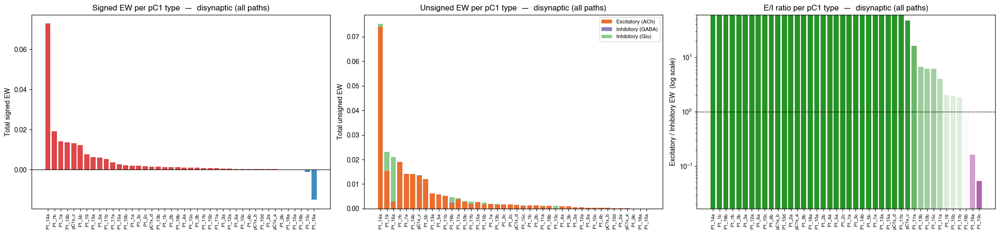

In [22]:
# ── Signed & unsigned EW bar plots per pC1 type — disynaptic (Section 3) ─────
# Uses merged_all (all disynaptic paths, no weight/EW threshold filter).
# Colour scheme: orange = ACh (excit), purple = GABA (inhib), green = Glu (inhib)

_excit2_src = (merged_all[merged_all['inter_nt'] == 'acetylcholine']
               .groupby('src_type')['path_ew'].sum())
_gaba2_src  = (merged_all[merged_all['inter_nt'] == 'gaba']
               .groupby('src_type')['path_ew'].sum())
_glu2_src   = (merged_all[merged_all['inter_nt'] == 'glutamate']
               .groupby('src_type')['path_ew'].sum())

_sv2_signed = (merged_all.groupby('src_type')['signed_path_ew']
               .sum().reset_index()
               .rename(columns={'signed_path_ew': 'total_signed_ew'})
               .sort_values('total_signed_ew', ascending=False)
               .reset_index(drop=True))
_sv2_signed = _sv2_signed[_sv2_signed['src_type'] != 'P1_2a/2b'].reset_index(drop=True)

fig, axes = plt.subplots(1, 3, figsize=(21, 5))

# ── Panel 1: Signed EW ────────────────────────────────────────────────────────
ax = axes[0]
_cols2 = ['#d62728' if v >= 0 else '#1f77b4' for v in _sv2_signed['total_signed_ew']]
ax.bar(range(len(_sv2_signed)), _sv2_signed['total_signed_ew'], color=_cols2, alpha=0.85)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Signed EW per pC1 type  —  disynaptic (all paths)')
ax.set_ylabel('Total signed EW')
ax.set_xticks(range(len(_sv2_signed)))
ax.set_xticklabels(_sv2_signed['src_type'], rotation=90, fontsize=7)

# ── Panel 2: Unsigned EW (stacked ACh / GABA / Glu) ──────────────────────────
_sv2u = _sv2_signed[['src_type']].copy()
_sv2u['excit'] = _sv2u['src_type'].map(_excit2_src).fillna(0)
_sv2u['gaba']  = _sv2u['src_type'].map(_gaba2_src).fillna(0)
_sv2u['glu']   = _sv2u['src_type'].map(_glu2_src).fillna(0)
_sv2u['total'] = _sv2u['excit'] + _sv2u['gaba'] + _sv2u['glu']
_sv2u = _sv2u.sort_values('total', ascending=False).reset_index(drop=True)

ax = axes[1]
ax.bar(range(len(_sv2u)), _sv2u['excit'],
       color='#e6550d', alpha=0.85, label='Excitatory (ACh)')
ax.bar(range(len(_sv2u)), _sv2u['gaba'], bottom=_sv2u['excit'],
       color='#756bb1', alpha=0.85, label='Inhibitory (GABA)')
ax.bar(range(len(_sv2u)), _sv2u['glu'],
       bottom=_sv2u['excit'] + _sv2u['gaba'],
       color='#74c476', alpha=0.85, label='Inhibitory (Glu)')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Unsigned EW per pC1 type  —  disynaptic (all paths)')
ax.set_ylabel('Total unsigned EW')
ax.set_xticks(range(len(_sv2u)))
ax.set_xticklabels(_sv2u['src_type'], rotation=90, fontsize=7)
ax.legend(fontsize=8, loc='upper right')

# ── Panel 3: E/I ratio (log scale, PWG colormap) ─────────────────────────────
_sv2_ei = _sv2_signed[['src_type']].copy()
_sv2_ei['excit'] = _sv2_ei['src_type'].map(_excit2_src).fillna(0.0)
_sv2_ei['inhib'] = (_sv2_ei['src_type'].map(_gaba2_src).fillna(0.0)
                    + _sv2_ei['src_type'].map(_glu2_src).fillna(0.0))
_sv2_ei['ei_ratio'] = (
    _sv2_ei['excit'] / _sv2_ei['inhib'].replace(0.0, float('nan'))
).fillna(float(EI_RATIO_MAX))  # pure-excit types clipped to max
_sv2_ei['ei_ratio'] = _sv2_ei['ei_ratio'].clip(lower=1.0 / EI_RATIO_MAX,
                                                upper=float(EI_RATIO_MAX))
_sv2_ei['log_ei'] = np.log(_sv2_ei['ei_ratio'])
_sv2_ei = _sv2_ei.sort_values('ei_ratio', ascending=False).reset_index(drop=True)

_log_max_ei2 = np.log(EI_RATIO_MAX)
_ei2_norm     = mcolors.TwoSlopeNorm(vmin=-_log_max_ei2, vcenter=0.0, vmax=_log_max_ei2)
_ei2_colors   = [mcolors.to_hex(PWG_CMAP(_ei2_norm(v))) for v in _sv2_ei['log_ei']]

ax = axes[2]
ax.bar(range(len(_sv2_ei)), _sv2_ei['ei_ratio'], color=_ei2_colors, alpha=0.85)
ax.axhline(1.0, color='black', linewidth=0.8, linestyle='--')
ax.set_yscale('log')
ax.set_ylim(1.0 / EI_RATIO_MAX, EI_RATIO_MAX)
ax.set_title('E/I ratio per pC1 type  —  disynaptic (all paths)')
ax.set_ylabel('Excitatory / Inhibitory EW  (log scale)')
ax.set_xticks(range(len(_sv2_ei)))
ax.set_xticklabels(_sv2_ei['src_type'], rotation=90, fontsize=7)


plt.tight_layout()
matplotlib.rcParams['svg.fonttype'] = 'none'  # ensure editable text
plt.savefig(RESULTS_DIR / 'pC1_type_ew_disynaptic.svg', bbox_inches='tight')
plt.show()

Showing 9 intermediates with EW ≥ 0.0001
Graph saved as /Users/otopalika/Documents/GitHub/pC1BehavioralAnalysis/results/path_discovery/disynaptic_paths_ew_filtered.svg


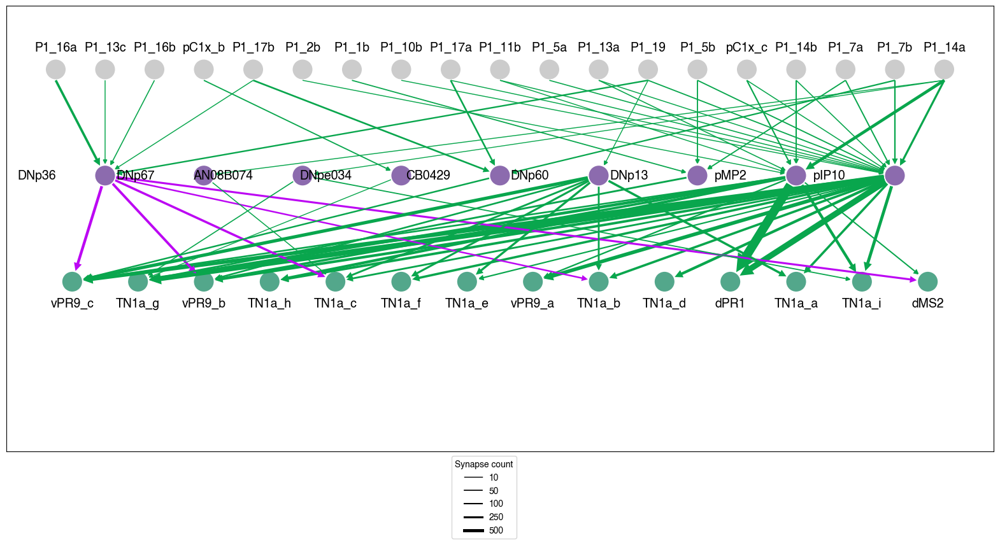

In [23]:
_active_cmap = PWG_CMAP if SEED_CMAP == 'pwg' else BWR_CMAP
# Seed-node coloring: total signed EW (default) or E/I ratio (SEED_COLOR_BY)
if SEED_COLOR_BY == 'ei_ratio':
    # Log scale: log(60) and log(1/60) are equidistant from 0 → equal colour intensity
    _log_max_2 = np.log(EI_RATIO_MAX)
    norm_2 = mcolors.TwoSlopeNorm(vmin=-_log_max_2, vcenter=0.0, vmax=_log_max_2)
    seed_color_2 = {
        row['src_type']: mcolors.to_hex(_active_cmap(norm_2(row['log_ei_ratio'])))
        for _, row in seed_valence.iterrows()
    }
else:
    vmax_2 = seed_valence['total_signed_ew'].abs().max()
    norm_2  = mcolors.TwoSlopeNorm(vmin=-vmax_2, vcenter=0, vmax=vmax_2)
    seed_color_2 = {
        row['src_type']: mcolors.to_hex(_active_cmap(norm_2(row['total_signed_ew'])))
        for _, row in seed_valence.iterrows()
    }

# Filter to intermediates where any qualifying triplet exists; order seeds top→bottom by signed EW
# Paths where the full disynaptic EW meets the threshold
# (per-edge weight >= WEIGHT_THRESHOLD already enforced by filter_paths on paths_2)
_filt    = merged[
    (merged['weight_l1'] >= WEIGHT_THRESHOLD) &
    (merged['weight_l2'] >= WEIGHT_THRESHOLD) &
    (merged['path_ew']   >= EW_THRESHOLD)
]
top_inter = set(_filt['inter_type'])

# Only show edges that participate in at least one qualifying triplet
valid_l1 = set(zip(_filt['src_type'],   _filt['inter_type']))  # pC1_type → DN_type
valid_l2 = set(zip(_filt['inter_type'], _filt['post_type']))   # DN_type  → premotor_type

vis_2 = paths_2_grouped[
    ((paths_2_grouped['layer'] == 1) &
     pd.array([tuple(r) in valid_l1 for r in zip(paths_2_grouped['pre'], paths_2_grouped['post'])])) |
    ((paths_2_grouped['layer'] == 2) &
     pd.array([tuple(r) in valid_l2 for r in zip(paths_2_grouped['pre'], paths_2_grouped['post'])]))
]
# Remove type-level edges whose aggregate synapse count is below threshold
vis_2 = vis_2[vis_2['weight'] >= WEIGHT_THRESHOLD]


if SEED_COLOR_BY == 'ei_ratio':
    seed_sort_2 = dict(zip(seed_valence['src_type'], seed_valence['log_ei_ratio']))
else:
    seed_sort_2 = dict(zip(seed_valence['src_type'], seed_valence['total_signed_ew']))

# Sort intermediate DNs by their total signed EW across all paths
dn_signed_ew = merged.groupby('inter_type')['signed_path_ew'].sum().reset_index()
dn_signed_ew.columns = ['inter_type', 'total_signed_ew']
seed_sort_2.update(dict(zip(dn_signed_ew['inter_type'], dn_signed_ew['total_signed_ew'])))

print(f'Showing {len(top_inter)} intermediates with EW ≥ {EW_THRESHOLD}')
plot_layered_paths(
    vis_2,
    neuron_to_sign=type_to_nt,
    sign_color_map=NT_COLOR,
    neuron_to_color=seed_color_2,
    sort_dict=seed_sort_2,
    edge_text=False,
    figsize=(16, max(8, len(top_inter) // 2 + 6)) if not VERTICAL_LAYOUT else (max(20, len(top_inter) // 12 + 6), 10),
    save_plot=True,
    file_name=str(RESULTS_DIR / 'disynaptic_paths_ew_filtered'),
    font_family='Helvetica',
    legend_weights=[10, 50, 100, 250, 500],
    colorbar_label='Signed EW',
    colorbar_norm=norm_2 if SEED_COLOR is None else None,
    colorbar_cmap=_active_cmap if SEED_COLOR is None else None,
    node_size=NODE_SIZE,
    node_outline=NODE_OUTLINE,
    center_seed_arrows=CENTER_SEED_ARROWS,
    vertical=VERTICAL_LAYOUT,
    seed_color=SEED_COLOR,
    inter_color=INTER_COLOR,
    target_color=TARGET_COLOR,
)
plt.show()

In [25]:
# ── Export disynaptic paths for Cytoscape ──────────────────────────
# Produces two CSVs for Cytoscape import:
#   edges: source, target, layer, weight, interaction
#   nodes: id, node_group, layer, nt, total_signed_ew, total_unsigned_ew
#
# Import steps in Cytoscape:
#   1. File → Import → Network from File → select edges CSV
#      Set: source=source, target=target, interaction=interaction
#   2. File → Import → Table from File → select nodes CSV
#      Set: key column=id, import to Node Table

_cyto = 'weight_ew'

# ── Edge table ───────────────────────────────────────────────
_nt_to_interaction = {'acetylcholine': 'excitatory', 'gaba': 'inhibitory',
                       'glutamate': 'inhibitory', 'other': 'unknown'}

cyto_edges = vis_2[['pre', 'post', 'layer', 'weight']].copy()
cyto_edges.rename(columns={'pre': 'source', 'post': 'target'}, inplace=True)
cyto_edges['nt_source']   = cyto_edges['source'].map(type_to_nt).fillna('other')
cyto_edges['interaction'] = cyto_edges['nt_source'].map(_nt_to_interaction).fillna('unknown')

cyto_edges.to_csv(RESULTS_DIR / f'disynaptic_{_cyto}_cytoscape_edges.csv', index=False)

# ── Node table ───────────────────────────────────────────────
_l1 = vis_2[vis_2['layer'] == 1]
_l2 = vis_2[vis_2['layer'] == 2]
seed_types  = set(_l1['pre'])
dn_types    = set(_l1['post']) | set(_l2['pre'])
prem_types  = set(_l2['post'])

# signed EW per DN (from merged, which covers all qualifying paths)
_dn_signed_ew = merged.groupby('inter_type')['signed_path_ew'].sum().to_dict()
_dn_unsigned_ew = ew_by_inter.set_index('inter_type')['total_ew'].to_dict()
_seed_ew = seed_valence.set_index('src_type')['total_signed_ew'].to_dict()

_nodes = []
for t in sorted(seed_types):
    _nodes.append({'id': t, 'node_group': 'pC1_seed', 'layer': 0,
                   'nt': type_to_nt.get(t, 'unknown'),
                   'total_signed_ew': _seed_ew.get(t, 0.0),
                   'total_unsigned_ew': abs(_seed_ew.get(t, 0.0))})
for t in sorted(dn_types):
    _nodes.append({'id': t, 'node_group': 'DN_intermediate', 'layer': 1,
                   'nt': type_to_nt.get(t, 'unknown'),
                   'total_signed_ew':   _dn_signed_ew.get(t, 0.0),
                   'total_unsigned_ew': _dn_unsigned_ew.get(t, 0.0)})
for t in sorted(prem_types):
    _nodes.append({'id': t, 'node_group': 'premotor_target', 'layer': 2,
                   'nt': type_to_nt.get(t, 'unknown'),
                   'total_signed_ew': float('nan'),
                   'total_unsigned_ew': float('nan')})

cyto_nodes = pd.DataFrame(_nodes)
cyto_nodes.to_csv(RESULTS_DIR / f'disynaptic_{_cyto}_cytoscape_nodes.csv', index=False)

print(f'Cytoscape export ({_cyto}):')
print(f'  {len(cyto_edges)} edges → disynaptic_{_cyto}_cytoscape_edges.csv')
print(f'  {len(cyto_nodes)} nodes → disynaptic_{_cyto}_cytoscape_nodes.csv')
print(f'  Node groups: {cyto_nodes["node_group"].value_counts().to_dict()}')
display(cyto_edges.head())
display(cyto_nodes)


Cytoscape export (weight_ew):
  72 edges → disynaptic_weight_ew_cytoscape_edges.csv
  42 nodes → disynaptic_weight_ew_cytoscape_nodes.csv
  Node groups: {'pC1_seed': 19, 'premotor_target': 14, 'DN_intermediate': 9}


,source,target,layer,weight,nt_source,interaction
7,P1_10b,pIP10,1,15,acetylcholine,excitatory
27,P1_11b,pIP10,1,27,acetylcholine,excitatory
28,P1_11b,pMP2,1,16,acetylcholine,excitatory
32,P1_13a,pIP10,1,22,acetylcholine,excitatory
33,P1_13a,pMP2,1,40,acetylcholine,excitatory


,id,node_group,layer,nt,total_signed_ew,total_unsigned_ew
0,P1_10b,pC1_seed,0,acetylcholine,0.002214,0.002214
1,P1_11b,pC1_seed,0,acetylcholine,0.005238,0.005238
2,P1_13a,pC1_seed,0,acetylcholine,0.006192,0.006192
3,P1_13c,pC1_seed,0,acetylcholine,-0.001052,0.001052
4,P1_14a,pC1_seed,0,acetylcholine,0.072927,0.072927
5,P1_14b,pC1_seed,0,acetylcholine,0.013690,0.013690
6,P1_16a,pC1_seed,0,acetylcholine,-0.015096,0.015096
7,P1_16b,pC1_seed,0,acetylcholine,-0.000293,0.000293
8,P1_17a,pC1_seed,0,acetylcholine,0.003654,0.003654
9,P1_17b,pC1_seed,0,acetylcholine,0.000853,0.000853


## Section 4: Combined Disynaptic + Trisynaptic Paths — EW per pC1 Type

Sums EW contributions from both 2-hop (pC1 → inter → premotor) and 3-hop
(pC1 → inter1 → inter2 → premotor) paths for each pC1 cell type.
No weight or EW threshold filter applied — uses `merged_all` and `merged_3a`.

NT classification for GABA / Glu:
- Disynaptic: interneuron NT (`inter_nt`).
- Trisynaptic: second interneuron (inter2) NT for inhibitory paths (`signed_path_ew < 0`).

In [58]:
# Load or compute trisynaptic paths; filter so layer-2 intermediate is a DN/AN
cache_3 = RESULTS_DIR / f'{DATASET}_trisynaptic_paths.csv'

if cache_3.exists():
    print('Loading cached trisynaptic paths...')
    paths_3_raw = pd.read_csv(cache_3)
else:
    print('Computing trisynaptic paths (this may take a minute)...')
    paths_3_raw = find_paths_of_length(prop, inidx, outidx, target_layer_number=3)
    if paths_3_raw is not None and not paths_3_raw.empty:
        paths_3_raw = filter_paths(paths_3_raw, threshold=WEIGHT_THRESHOLD)
        paths_3_raw.to_csv(cache_3, index=False)
    else:
        paths_3_raw = pd.DataFrame()
        print('WARNING: No trisynaptic paths found.')

print(f'Raw trisynaptic edges: {len(paths_3_raw):,}')

# Filter: layer-2 intermediate (post of layer-2 edge) must be a descending/ascending neuron
valid_dn_idx = {
    int(i) for i in paths_3_raw.loc[paths_3_raw['layer'] == 2, 'post']
    if idx_to_superclass.get(int(i)) in VALID_SUPERCLASS
}
# Propagate: keep layer-1 edges whose post connects to a valid DN
l2_valid = paths_3_raw[(paths_3_raw['layer'] == 2) & paths_3_raw['post'].astype(int).isin(valid_dn_idx)]
valid_l1_post = set(l2_valid['pre'].astype(int))

paths_3_filt = paths_3_raw[
    ((paths_3_raw['layer'] == 1) & paths_3_raw['post'].astype(int).isin(valid_l1_post)) |
    ((paths_3_raw['layer'] == 2) & paths_3_raw['post'].astype(int).isin(valid_dn_idx))   |
    ((paths_3_raw['layer'] == 3) & paths_3_raw['pre'].astype(int).isin(valid_dn_idx))
]
print(f'After layer-2 DN filter: {len(paths_3_filt):,} edges '
      f'({len(valid_dn_idx)} unique layer-2 DNs, {len(valid_l1_post)} unique layer-1 intermediates)')

# Group by cell type for visualisation
paths_3_grouped = group_paths(paths_3_filt, idx_to_type, idx_to_type, combining_method='sum')

# Summarise layer-1 (any cell type) and layer-2 (DN) intermediates
inter3_l1 = (
    paths_3_grouped[paths_3_grouped['layer'] == 1]
    .groupby('post').agg(n_pC1_types=('pre', 'nunique'), total_weight=('weight', 'sum'))
    .reset_index().rename(columns={'post': 'intermediate'})
)
inter3_l1['nt']       = inter3_l1['intermediate'].map(type_to_nt).fillna('other')
inter3_l1['position'] = 'layer_1 (any cell type)'

inter3_l2 = (
    paths_3_grouped[paths_3_grouped['layer'] == 2]
    .groupby('post').agg(n_pC1_types=('pre', 'nunique'), total_weight=('weight', 'sum'))
    .reset_index().rename(columns={'post': 'intermediate'})
)
inter3_l2['nt']       = inter3_l2['intermediate'].map(type_to_nt).fillna('other')
inter3_l2['position'] = 'layer_2 (DN)'

print(f'\nUnique layer-1 intermediates: {len(inter3_l1)}')
print('Top 20 layer-1 intermediates:')
display(inter3_l1.sort_values('total_weight', ascending=False).head(20))
print(f'\nUnique layer-2 DNs: {len(inter3_l2)}')
print('Top 20 layer-2 DNs:')
display(inter3_l2.sort_values('total_weight', ascending=False).head(20))

Loading cached trisynaptic paths...
Raw trisynaptic edges: 19,905
After layer-2 DN filter: 14,136 edges (204 unique layer-2 DNs, 1206 unique layer-1 intermediates)

Unique layer-1 intermediates: 518
Top 20 layer-1 intermediates:


/Users/otopalika/Documents/GitHub/connectome_interpreter_Janelia/src/connectome_interpreter/path_finding.py:892: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/Users/otopalika/Documents/GitHub/connectome_interpreter_Janelia/src/connectome_interpreter/path_finding.py:893: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,intermediate,n_pC1_types,total_weight,nt,position
285,P1_18b,38,2173,acetylcholine,layer_1 (any cell type)
353,SIP106m,35,1902,other,layer_1 (any cell type)
89,AVLP717m,23,1630,acetylcholine,layer_1 (any cell type)
508,mAL_m8,10,1577,gaba,layer_1 (any cell type)
486,aIPg5,21,1409,acetylcholine,layer_1 (any cell type)
380,SIP141m,16,1281,glutamate,layer_1 (any cell type)
374,SIP133m,15,1279,glutamate,layer_1 (any cell type)
367,SIP121m,26,1222,glutamate,layer_1 (any cell type)
514,pC1x_d,14,1036,acetylcholine,layer_1 (any cell type)
490,aIPg_m1,18,984,acetylcholine,layer_1 (any cell type)



Unique layer-2 DNs: 112
Top 20 layer-2 DNs:


,intermediate,n_pC1_types,total_weight,nt,position
109,pIP10,145,12462,acetylcholine,layer_2 (DN)
89,DNp13,164,12339,acetylcholine,layer_2 (DN)
110,pMP2,113,10925,acetylcholine,layer_2 (DN)
108,pIP1,85,7825,acetylcholine,layer_2 (DN)
99,DNpe025,139,7458,acetylcholine,layer_2 (DN)
91,DNp36,122,7356,glutamate,layer_2 (DN)
106,aSP22,112,6207,acetylcholine,layer_2 (DN)
49,DNg100,36,5557,acetylcholine,layer_2 (DN)
71,DNge053,45,4087,acetylcholine,layer_2 (DN)
102,DNpe050,73,3403,acetylcholine,layer_2 (DN)


In [59]:
# ── Hoeller EW for trisynaptic paths (3-hop, with sign from both intermediates) ─
# path_EW(i→j→k→l) = w_norm(i→j) × w_norm(j→k) × w_norm(k→l)
# signed_EW = path_EW × nt_sign(inter1_j) × nt_sign(DN_k)

l1_3 = paths_3_filt[paths_3_filt['layer'] == 1].copy()
l2_3 = paths_3_filt[paths_3_filt['layer'] == 2].copy()
l3_3 = paths_3_filt[paths_3_filt['layer'] == 3].copy()

# col_sums already computed in disynaptic section; reuse
l1_3['w_norm'] = l1_3['weight'] / l1_3['post'].astype(int).map(lambda j: col_sums[j])
l2_3['w_norm'] = l2_3['weight'] / l2_3['post'].astype(int).map(lambda j: col_sums[j])
l3_3['w_norm'] = l3_3['weight'] / l3_3['post'].astype(int).map(lambda j: col_sums[j])

# Rename columns for clarity before merging
l1_3 = l1_3.rename(columns={'pre': 'pC1',    'post': 'inter1', 'w_norm': 'wn1'})[['pC1',    'inter1', 'wn1']]
l2_3 = l2_3.rename(columns={'pre': 'inter1', 'post': 'inter2', 'w_norm': 'wn2'})[['inter1', 'inter2', 'wn2']]
l3_3 = l3_3.rename(columns={'pre': 'inter2', 'post': 'premotor','w_norm': 'wn3'})[['inter2', 'premotor','wn3']]

m12 = pd.merge(l1_3, l2_3, on='inter1')
merged_3 = pd.merge(m12, l3_3, on='inter2')
merged_3['path_ew'] = merged_3['wn1'] * merged_3['wn2'] * merged_3['wn3']

merged_3['src_type']    = merged_3['pC1'].astype(int).map(idx_to_type)
merged_3['inter1_type'] = merged_3['inter1'].astype(int).map(idx_to_type)
merged_3['inter2_type'] = merged_3['inter2'].astype(int).map(idx_to_type)

merged_3['inter1_sign'] = merged_3['inter1_type'].map(type_to_nt).fillna('other').map(NT_SIGN).fillna(0)
merged_3['inter2_sign'] = merged_3['inter2_type'].map(type_to_nt).fillna('other').map(NT_SIGN).fillna(0)
merged_3['signed_path_ew'] = merged_3['path_ew'] * merged_3['inter1_sign'] * merged_3['inter2_sign']

# Unsigned EW per layer-2 DN type (for threshold filter)
ew_by_dn_3 = (
    merged_3.groupby('inter2_type')['path_ew']
    .sum().reset_index()
)
ew_by_dn_3.columns = ['inter2_type', 'total_ew']
ew_by_dn_3['nt'] = ew_by_dn_3['inter2_type'].map(type_to_nt).fillna('other')
ew_by_dn_3.sort_values('total_ew', ascending=False, inplace=True)
ew_by_dn_3.reset_index(drop=True, inplace=True)

# Signed EW (valence) per pC1 seed type
seed_valence_3 = (
    merged_3.groupby('src_type')['signed_path_ew']
    .sum().reset_index()
    .rename(columns={'signed_path_ew': 'total_signed_ew_3'})
    .sort_values('total_signed_ew_3', ascending=False).reset_index(drop=True)
)
# ── E/I ratio for trisynaptic paths ──────────────────────────────────────────
_sv3_combined = merged_3['inter1_sign'] * merged_3['inter2_sign']
_sv3_excit = merged_3[_sv3_combined > 0].groupby('src_type')['path_ew'].sum()
_sv3_inhib = merged_3[_sv3_combined < 0].groupby('src_type')['path_ew'].sum()
seed_valence_3['excit_ew'] = seed_valence_3['src_type'].map(_sv3_excit).fillna(0.0)
seed_valence_3['inhib_ew'] = seed_valence_3['src_type'].map(_sv3_inhib).fillna(0.0)
_sv3_inhib_safe = seed_valence_3['inhib_ew'].replace(0.0, np.nan)
seed_valence_3['ei_ratio'] = (seed_valence_3['excit_ew'] / _sv3_inhib_safe).fillna(
    seed_valence_3['excit_ew'].max() * 2 + 2.0)
seed_valence_3['log_ei_ratio'] = np.log(
    seed_valence_3['ei_ratio'].clip(lower=1.0 / EI_RATIO_MAX, upper=EI_RATIO_MAX))

n_above_3 = (ew_by_dn_3['total_ew'] >= EW_THRESHOLD_3).sum()
print(f'Hoeller EW for trisynaptic paths (threshold = {EW_THRESHOLD_3}):')
print(f'  {n_above_3} / {len(ew_by_dn_3)} layer-2 DNs above threshold\n')
print('Top 20 layer-2 DNs (by unsigned EW):')
display(ew_by_dn_3.head(20))
print('\npC1 seed valence — trisynaptic:')
display(seed_valence_3)

ew_by_dn_3.to_csv(RESULTS_DIR / 'trisynaptic_dn_ew.csv', index=False)
seed_valence_3.to_csv(RESULTS_DIR / 'pC1_seed_valence_3hop.csv', index=False)

Hoeller EW for trisynaptic paths (threshold = 0.0005):
  18 / 112 layer-2 DNs above threshold

Top 20 layer-2 DNs (by unsigned EW):


,inter2_type,total_ew,nt
0,pIP10,0.068179,acetylcholine
1,pMP2,0.035184,acetylcholine
2,DNp60,0.019856,acetylcholine
3,DNp36,0.014743,glutamate
4,DNp13,0.008804,acetylcholine
5,AN08B061,0.007302,acetylcholine
6,DNp45,0.002632,acetylcholine
7,DNge079,0.002397,gaba
8,ANXXX152,0.001664,acetylcholine
9,DNp67,0.001630,acetylcholine



pC1 seed valence — trisynaptic:


,src_type,total_signed_ew_3,excit_ew,inhib_ew,ei_ratio,log_ei_ratio
0,P1_14a,0.008025,0.012029,0.004003,3.004526,1.100120
1,P1_7b,0.005541,0.006043,0.000503,12.025144,2.487000
2,P1_7a,0.005297,0.005951,0.000654,9.097047,2.207950
3,P1_16a,0.002807,0.006675,0.003868,1.725720,0.545644
4,P1_14b,0.002554,0.003457,0.000903,3.829567,1.342752
5,P1_3b,0.002254,0.002875,0.000622,4.625512,1.531587
6,P1_15b,0.002118,0.003055,0.000937,3.259369,1.181534
7,P1_11b,0.002075,0.002759,0.000683,4.036271,1.395321
8,P1_13a,0.002027,0.002940,0.000912,3.221745,1.169923
9,P1_15c,0.002007,0.002748,0.000741,3.710560,1.311183


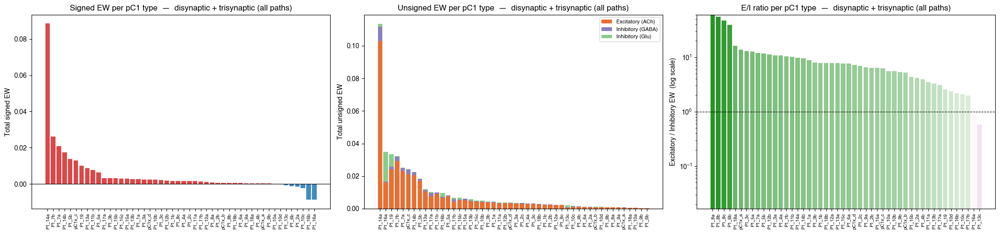

In [60]:
# ── Signed & unsigned EW bar plots per pC1 type — combined paths (Section 4) ──
# Combines merged_all (disynaptic) + merged_3a (trisynaptic), unfiltered.
# NT classification: disynaptic uses inter_nt; trisynaptic uses inter2 NT
# for inhibitory paths (signed_path_ew < 0).

# ── Disynaptic contributions ──────────────────────────────────────────────────
_excit_d = (merged_all[merged_all['inter_nt'] == 'acetylcholine']
            .groupby('src_type')['path_ew'].sum())
_gaba_d  = (merged_all[merged_all['inter_nt'] == 'gaba']
            .groupby('src_type')['path_ew'].sum())
_glu_d   = (merged_all[merged_all['inter_nt'] == 'glutamate']
            .groupby('src_type')['path_ew'].sum())
_signed_d = merged_all.groupby('src_type')['signed_path_ew'].sum()

# ── Trisynaptic contributions (if available) ──────────────────────────────────
_excit_t  = {}
_gaba_t   = {}
_glu_t    = {}
_signed_t = {}
if 'merged_3a' in vars():
    _inter2_nt_s4 = merged_3a['inter2_type'].map(type_to_nt).fillna('other')
    _excit_t  = (merged_3a[merged_3a['signed_path_ew'] > 0]
                 .groupby('src_type')['path_ew'].sum())
    _gaba_t   = (merged_3a[(merged_3a['signed_path_ew'] < 0) & (_inter2_nt_s4 == 'gaba')]
                 .groupby('src_type')['path_ew'].sum())
    _glu_t    = (merged_3a[(merged_3a['signed_path_ew'] < 0) & (_inter2_nt_s4 == 'glutamate')]
                 .groupby('src_type')['path_ew'].sum())
    _signed_t = merged_3a.groupby('src_type')['signed_path_ew'].sum()

# ── Combine into a single DataFrame indexed by src_type ──────────────────────
import pandas as _pd_s4
_all_types = sorted(set(merged_all['src_type'].unique()) |
                    (set(merged_3a['src_type'].unique()) if 'merged_3a' in vars() else set()))

_sv_comb = _pd_s4.DataFrame({'src_type': _all_types})
_sv_comb['excit']      = _sv_comb['src_type'].map(
    lambda t: _excit_d.get(t, 0.) + (_excit_t.get(t, 0.) if hasattr(_excit_t, 'get') else 0.))
_sv_comb['gaba']       = _sv_comb['src_type'].map(
    lambda t: _gaba_d.get(t,  0.) + (_gaba_t.get(t,  0.) if hasattr(_gaba_t,  'get') else 0.))
_sv_comb['glu']        = _sv_comb['src_type'].map(
    lambda t: _glu_d.get(t,   0.) + (_glu_t.get(t,   0.) if hasattr(_glu_t,   'get') else 0.))
_sv_comb['signed_ew']  = _sv_comb['src_type'].map(
    lambda t: _signed_d.get(t, 0.) + (_signed_t.get(t, 0.) if hasattr(_signed_t, 'get') else 0.))
_sv_comb['total_unsigned'] = _sv_comb['excit'] + _sv_comb['gaba'] + _sv_comb['glu']
_sv_comb = _sv_comb[_sv_comb['src_type'] != 'P1_2a/2b'].reset_index(drop=True)

fig, axes = plt.subplots(1, 3, figsize=(21, 5))

# ── Panel 1: Signed EW ────────────────────────────────────────────────────────
_sv_sign = _sv_comb.sort_values('signed_ew', ascending=False).reset_index(drop=True)
ax = axes[0]
_cols_c = ['#d62728' if v >= 0 else '#1f77b4' for v in _sv_sign['signed_ew']]
ax.bar(range(len(_sv_sign)), _sv_sign['signed_ew'], color=_cols_c, alpha=0.85)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Signed EW per pC1 type  —  disynaptic + trisynaptic (all paths)')
ax.set_ylabel('Total signed EW')
ax.set_xticks(range(len(_sv_sign)))
ax.set_xticklabels(_sv_sign['src_type'], rotation=90, fontsize=7)

# ── Panel 2: Unsigned EW (stacked ACh / GABA / Glu) ──────────────────────────
_sv_u = _sv_comb.sort_values('total_unsigned', ascending=False).reset_index(drop=True)
ax = axes[1]
ax.bar(range(len(_sv_u)), _sv_u['excit'],
       color='#e6550d', alpha=0.85, label='Excitatory (ACh)')
ax.bar(range(len(_sv_u)), _sv_u['gaba'], bottom=_sv_u['excit'],
       color='#756bb1', alpha=0.85, label='Inhibitory (GABA)')
ax.bar(range(len(_sv_u)), _sv_u['glu'],
       bottom=_sv_u['excit'] + _sv_u['gaba'],
       color='#74c476', alpha=0.85, label='Inhibitory (Glu)')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Unsigned EW per pC1 type  —  disynaptic + trisynaptic (all paths)')
ax.set_ylabel('Total unsigned EW')
ax.set_xticks(range(len(_sv_u)))
ax.set_xticklabels(_sv_u['src_type'], rotation=90, fontsize=7)
ax.legend(fontsize=8, loc='upper right')

# ── Panel 3: E/I ratio (log scale, PWG colormap) ─────────────────────────────
_sv4_ei = _sv_comb.copy()
_sv4_ei['inhib'] = _sv4_ei['gaba'] + _sv4_ei['glu']
_sv4_ei['ei_ratio'] = (
    _sv4_ei['excit'] / _sv4_ei['inhib'].replace(0., float('nan'))
).fillna(float(EI_RATIO_MAX))
_sv4_ei['ei_ratio'] = _sv4_ei['ei_ratio'].clip(lower=1./EI_RATIO_MAX,
                                                upper=float(EI_RATIO_MAX))
_sv4_ei['log_ei'] = np.log(_sv4_ei['ei_ratio'])
_sv4_ei = _sv4_ei.sort_values('ei_ratio', ascending=False).reset_index(drop=True)
_log_max_ei4   = np.log(EI_RATIO_MAX)
_ei4_norm      = mcolors.TwoSlopeNorm(vmin=-_log_max_ei4, vcenter=0., vmax=_log_max_ei4)
_ei4_colors    = [mcolors.to_hex(PWG_CMAP(_ei4_norm(v))) for v in _sv4_ei['log_ei']]
ax = axes[2]
ax.bar(range(len(_sv4_ei)), _sv4_ei['ei_ratio'], color=_ei4_colors, alpha=0.85)
ax.axhline(1., color='black', linewidth=0.8, linestyle='--')
ax.set_yscale('log')
ax.set_ylim(1./EI_RATIO_MAX, EI_RATIO_MAX)
ax.set_title('E/I ratio per pC1 type  —  disynaptic + trisynaptic (all paths)')
ax.set_ylabel('Excitatory / Inhibitory EW  (log scale)')
ax.set_xticks(range(len(_sv4_ei)))
ax.set_xticklabels(_sv4_ei['src_type'], rotation=90, fontsize=7)


plt.tight_layout()
matplotlib.rcParams['svg.fonttype'] = 'none'  # ensure editable text
plt.savefig(RESULTS_DIR / 'pC1_type_ew_combined.svg', bbox_inches='tight')
plt.show()

Showing 18 layer-2 DNs with EW ≥ 0.0005
Graph saved as /Users/otopalika/Documents/GitHub/pC1BehavioralAnalysis/results/path_discovery/trisynaptic_paths_ew_filtered.svg


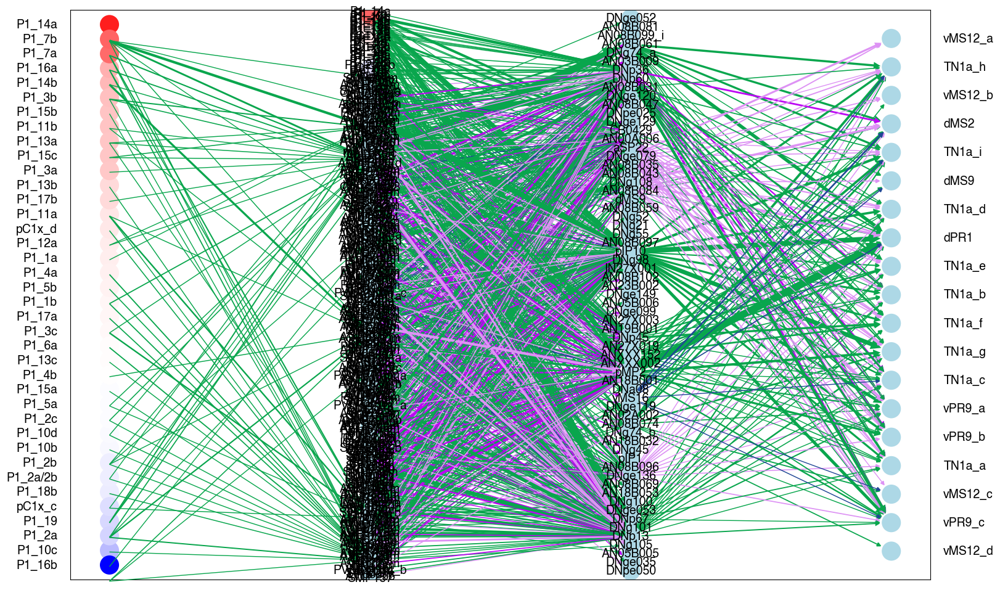

In [61]:
_active_cmap = PWG_CMAP if SEED_CMAP == 'pwg' else BWR_CMAP
# Seed-node coloring: total signed EW (default) or E/I ratio (SEED_COLOR_BY)
if SEED_COLOR_BY == 'ei_ratio':
    _log_max_3 = np.log(EI_RATIO_MAX)
    norm_3 = mcolors.TwoSlopeNorm(vmin=-_log_max_3, vcenter=0.0, vmax=_log_max_3)
    seed_color_3 = {
        row['src_type']: mcolors.to_hex(_active_cmap(norm_3(row['log_ei_ratio'])))
        for _, row in seed_valence_3.iterrows()
    }
else:
    vmax_3 = seed_valence_3['total_signed_ew_3'].abs().max()
    norm_3  = mcolors.TwoSlopeNorm(vmin=-vmax_3, vcenter=0, vmax=vmax_3)
    seed_color_3 = {
        row['src_type']: mcolors.to_hex(_active_cmap(norm_3(row['total_signed_ew_3'])))
        for _, row in seed_valence_3.iterrows()
    }

# Filter to layer-2 DNs above EW_THRESHOLD_3; order seeds top→bottom by signed EW
top_dn_3 = set(ew_by_dn_3.loc[ew_by_dn_3['total_ew'] >= EW_THRESHOLD_3, 'inter2_type'])
vis_3 = paths_3_grouped[
    paths_3_grouped['post'].isin(top_dn_3) |
    paths_3_grouped['pre'].isin(top_dn_3)
]

# Apply cell-type-level weight threshold (filters weak type→type connections)
vis_3 = vis_3[vis_3['weight'] >= WEIGHT_THRESHOLD]

if SEED_COLOR_BY == 'ei_ratio':
    seed_sort_3 = dict(zip(seed_valence_3['src_type'], seed_valence_3['log_ei_ratio']))
else:
    seed_sort_3 = dict(zip(seed_valence_3['src_type'], seed_valence_3['total_signed_ew_3']))

print(f'Showing {len(top_dn_3)} layer-2 DNs with EW ≥ {EW_THRESHOLD_3}')
plot_layered_paths(
    vis_3,
    neuron_to_sign=type_to_nt,
    sign_color_map=NT_COLOR,
    neuron_to_color=seed_color_3,
    sort_dict=seed_sort_3,
    edge_text=False,
    figsize=(18, max(10, len(top_dn_3) // 4 + 8)),
    save_plot=True,
    file_name=str(RESULTS_DIR / 'trisynaptic_paths_ew_filtered'),
    node_size=NODE_SIZE,
    node_outline=NODE_OUTLINE,
    center_seed_arrows=CENTER_SEED_ARROWS,
)
plt.show()

## Section 5: SS Line Composite Effective Weight

For each experimental SS line (pC1_1a through pC1x_abd), parse the component pC1 subtypes,
look up their signed EWs from Section 3 (disynaptic), and compute composite sum and mean EW.

In [62]:
import re

BEH_CSV = BEHAVIORAL_REPO / 'data' / 'CourtingMaleActivation_Zscores_Pvalues.csv'

def parse_pC1_types(cell_type_str):
    """Parse CellType string → list of connectome type names.
    Classical: pC1_4a,6b → [P1_4a, P1_6b]; pC1_2abc → [P1_2a, P1_2b, P1_2c]; pC1_19 → [P1_19]
    pC1x:      pC1x_abd  → [pC1x_a, pC1x_b, pC1x_d]; PC1x_ac → [pC1x_a, pC1x_c]
    """
    s = cell_type_str.strip().lower()
    if s.startswith('pc1x_'):
        suffix = re.sub(r'[,\s]', '', s[5:])           # remove commas/spaces → e.g. "abd"
        return [f'pC1x_{c}' for c in suffix]
    if s.startswith('pc1_'):
        tokens = [t.strip() for t in s[4:].split(',')]  # split by comma after stripping prefix
        result = []
        for tok in tokens:
            m = re.match(r'^(\d+)([a-z]*)$', tok)
            if m:
                num, letters = m.groups()
                result += [f'P1_{num}{c}' for c in letters] if letters else [f'P1_{num}']
        return result
    return []  # Empty Split, pIP10, pMP2, etc. → skip

# ── Recompute signed EW from ALL disynaptic paths (no superclass or EW threshold) ──
# col_sums already computed in Section 3; paths_2 is the full unfiltered cache.
l1_all = paths_2[paths_2['layer'] == 1].copy()
l2_all = paths_2[paths_2['layer'] == 2].copy()
l1_all['w_norm'] = l1_all['weight'] / l1_all['post'].astype(int).map(lambda j: col_sums[j])
l2_all['w_norm'] = l2_all['weight'] / l2_all['post'].astype(int).map(lambda j: col_sums[j])

merged_all = pd.merge(l1_all, l2_all, left_on='post', right_on='pre', suffixes=('_l1', '_l2'))
merged_all['path_ew']        = merged_all['w_norm_l1'] * merged_all['w_norm_l2']
merged_all['src_type']       = merged_all['pre_l1'].astype(int).map(idx_to_type)
merged_all['inter_type']     = merged_all['post_l1'].astype(int).map(idx_to_type)
merged_all['inter_nt']       = merged_all['inter_type'].map(type_to_nt).fillna('other')
merged_all['inter_sign']     = merged_all['inter_nt'].map(NT_SIGN).fillna(0)
merged_all['signed_path_ew'] = merged_all['path_ew'] * merged_all['inter_sign']
merged_all['post_type']     = merged_all['post_l2'].astype(int).map(idx_to_type)

sv2_all = (
    merged_all.groupby('src_type')['signed_path_ew']
    .sum()
    .to_dict()
)

beh = pd.read_csv(BEH_CSV)
rows = []

for _, row in beh.iterrows():
    types = parse_pC1_types(str(row['CellType']))
    if not types:
        continue
    # Missing = parsed types with no disynaptic paths at all (EW → 0)
    missing = [t for t in types if t not in sv2_all]
    ews2 = [sv2_all.get(t, 0.0) for t in types]
    rows.append({
        'LineName':               row['LineName'],
        'CellType':               row['CellType'],
        'component_types':        ', '.join(types),
        'n_components':           len(types),
        'missing_types':          ', '.join(missing) if missing else '',
        'composite_sum_ew_2hop':  sum(ews2),
        'composite_mean_ew_2hop': sum(ews2) / len(ews2),
    })

ss_ew = pd.DataFrame(rows).sort_values('composite_sum_ew_2hop', ascending=False).reset_index(drop=True)

print(f'{len(ss_ew)} SS lines parsed')
print(f'{(ss_ew["missing_types"] != "").sum()} lines have component types with no disynaptic paths (EW=0)')
display(ss_ew)
ss_ew.to_csv(RESULTS_DIR / 'SS_line_composite_ew.csv', index=False)

33 SS lines parsed
8 lines have component types with no disynaptic paths (EW=0)


,LineName,CellType,component_types,n_components,missing_types,composite_sum_ew_2hop,composite_mean_ew_2hop
0,SS101156,"pC1_13abc, 14ab","P1_13a, P1_13b, P1_13c, P1_14a, P1_14b",5,,0.093142,0.018628
1,SS106638,"pC1_13a,14ab","P1_13a, P1_14a, P1_14b",3,,0.092809,0.030936
2,SS59900,pC1_14a,P1_14a,1,,0.072927,0.072927
3,SS39313,PC1x_ac,"pC1x_a, pC1x_c",2,,0.013224,0.006612
4,SS100234,"pC1_4a, 5b, 6b","P1_4a, P1_5b, P1_6b",3,P1_6b,0.013111,0.004370
5,SS100232,"pC1_4a, 6b, 19","P1_4a, P1_6b, P1_19",3,P1_6b,0.008797,0.002932
6,SS106227,"pC1_4b, 8c,19","P1_4b, P1_8c, P1_19",3,P1_8c,0.008067,0.002689
7,SS99807,"pC1_8a, 19","P1_8a, P1_19",2,P1_8a,0.007763,0.003882
8,SS100895,pC1_19,P1_19,1,,0.007763,0.007763
9,SS59821,"pC1_1a, 2abc, 3c","P1_1a, P1_2a, P1_2b, P1_2c, P1_3c",5,,0.007073,0.001415


In [63]:
# ── Excitatory / inhibitory EW split per SS line (disynaptic) ───────────────
# excit_sum_ew: sum of path_ew routed through ACh (excitatory) DNs
# inhib_sum_ew: sum of path_ew routed through GABA/Glu (inhibitory) DNs
excit_by_type = (
    merged_all[merged_all['inter_sign'] > 0]
    .groupby('src_type')['path_ew'].sum()
    .to_dict()
)
inhib_by_type = (
    merged_all[merged_all['inter_sign'] < 0]
    .groupby('src_type')['path_ew'].sum()
    .to_dict()
)

rows_ei = []
for _, row in beh.iterrows():
    types = parse_pC1_types(str(row['CellType']))
    if not types:
        continue
    rows_ei.append({
        'LineName':     row['LineName'],
        'excit_sum_ew': sum(excit_by_type.get(t, 0.0) for t in types),
        'inhib_sum_ew': sum(inhib_by_type.get(t, 0.0) for t in types),
    })

ss_ew_ei = pd.DataFrame(rows_ei)
ss_ew_ei.to_csv(RESULTS_DIR / 'SS_line_excit_inhib_ew_2hop.csv', index=False)
print(f'Saved excit/inhib EW for {len(ss_ew_ei)} SS lines')
display(ss_ew_ei.sort_values('excit_sum_ew', ascending=False))


Saved excit/inhib EW for 33 SS lines


,LineName,excit_sum_ew,inhib_sum_ew
19,SS101156,0.095848,0.002706
17,SS106638,0.094158,0.001350
20,SS59900,0.074077,0.001150
8,SS100232,0.016431,0.007634
9,SS106227,0.015701,0.007634
10,SS99807,0.015397,0.007634
27,SS100895,0.015397,0.007634
31,SS39313,0.013510,0.000286
7,SS100234,0.013111,0.000000
22,SS100896,0.007816,0.003521


In [64]:
# ── Excit/inhib EW split per SS line × premotor target (disynaptic) ───────────
excit_by_type_pm = (
    merged_all[merged_all['inter_sign'] > 0]
    .groupby(['src_type', 'post_type'])['path_ew'].sum()
    .to_dict()
)
inhib_by_type_pm = (
    merged_all[merged_all['inter_sign'] < 0]
    .groupby(['src_type', 'post_type'])['path_ew'].sum()
    .to_dict()
)

rows_ei_pm = []
for _, row in beh.iterrows():
    types = parse_pC1_types(str(row['CellType']))
    if not types:
        continue
    entry = {'LineName': row['LineName']}
    for pm_grp, pm_subs in PREMOTOR_GROUPS.items():
        entry[f'excit_ew_{pm_grp}'] = sum(excit_by_type_pm.get((t, sub), 0.0) for t in types for sub in pm_subs)
        entry[f'inhib_ew_{pm_grp}'] = sum(inhib_by_type_pm.get((t, sub), 0.0) for t in types for sub in pm_subs)
    rows_ei_pm.append(entry)

ss_ew_ei_pm = pd.DataFrame(rows_ei_pm)
ss_ew_ei_pm.to_csv(RESULTS_DIR / 'SS_line_x_premotor_excit_inhib_ew_2hop.csv', index=False)
print(f'Saved per-premotor excit/inhib EW for {len(ss_ew_ei_pm)} SS lines')
display(ss_ew_ei_pm.head())


Saved per-premotor excit/inhib EW for 33 SS lines


,LineName,excit_ew_dPR1,inhib_ew_dPR1,excit_ew_vMS12_a,inhib_ew_vMS12_a,excit_ew_vMS12_b,inhib_ew_vMS12_b,excit_ew_vMS12_c,inhib_ew_vMS12_c,excit_ew_vMS12_d,...,excit_ew_TN1a_e,inhib_ew_TN1a_e,excit_ew_TN1a_f,inhib_ew_TN1a_f,excit_ew_TN1a_g,inhib_ew_TN1a_g,excit_ew_TN1a_h,inhib_ew_TN1a_h,excit_ew_TN1a_i,inhib_ew_TN1a_i
0,SS100769,0.000019,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000049,0.0,0.000123,0.0,0.000654,0.0,0.000097,0.0,0.000289,0.0
1,SS45469,0.000383,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000028,0.0,0.000058,0.0,0.000760,0.0,0.000417,0.0,0.000447,0.0
2,SS100593,0.000173,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000012,0.0,0.000026,0.0,0.000337,0.0,0.000203,0.0,0.000199,0.0
3,SS59821,0.000419,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000136,0.0,0.000284,0.0,0.001984,0.0,0.000621,0.0,0.000993,0.0
4,SS101336,0.000046,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000080,0.0,0.000152,0.0,0.000770,0.0,0.000162,0.0,0.000345,0.0


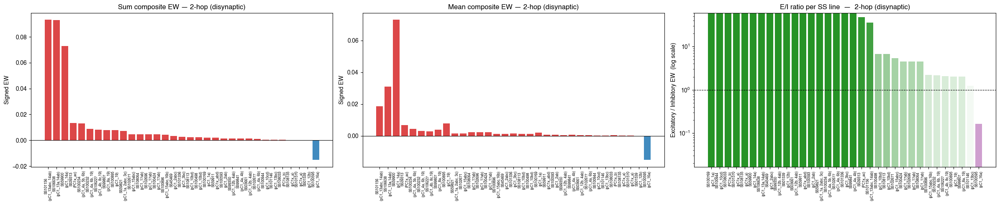

In [65]:
labels = ss_ew['LineName'] + '\n(' + ss_ew['CellType'].str[:18] + ')'
x = range(len(ss_ew))

fig, axes = plt.subplots(1, 3, figsize=(24, 5), sharey=False)

for ax, col, title in zip(axes,
    ['composite_sum_ew_2hop', 'composite_mean_ew_2hop'],
    ['Sum composite EW — 2-hop (disynaptic)', 'Mean composite EW — 2-hop (disynaptic)'],
):
    colors = ['#d62728' if v >= 0 else '#1f77b4' for v in ss_ew[col]]
    ax.bar(x, ss_ew[col], color=colors, alpha=0.85)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel('Signed EW')
    ax.set_xticks(list(x))
    ax.set_xticklabels(labels, rotation=90, fontsize=6)

# ── Panel 3: E/I ratio (log scale, PWG colormap) ─────────────────────────────
_rows_ei5 = []
for _, _row5 in beh.iterrows():
    _types5 = parse_pC1_types(str(_row5['CellType']))
    if not _types5:
        continue
    _rows_ei5.append({
        'LineName': _row5['LineName'],
        'CellType': _row5['CellType'],
        'excit_ew': sum(excit_by_type.get(t, 0.) for t in _types5),
        'inhib_ew': sum(inhib_by_type.get(t, 0.) for t in _types5),
    })
_ss_ei5 = pd.DataFrame(_rows_ei5)
_ss_ei5['ei_ratio'] = (
    _ss_ei5['excit_ew'] / _ss_ei5['inhib_ew'].replace(0., float('nan'))
).fillna(float(EI_RATIO_MAX))
_ss_ei5['ei_ratio'] = _ss_ei5['ei_ratio'].clip(lower=1./EI_RATIO_MAX,
                                                upper=float(EI_RATIO_MAX))
_ss_ei5['log_ei'] = np.log(_ss_ei5['ei_ratio'])
_ss_ei5 = _ss_ei5.sort_values('ei_ratio', ascending=False).reset_index(drop=True)
_labels_ei5  = _ss_ei5['LineName'] + '\n(' + _ss_ei5['CellType'].str[:18] + ')'
_log_max_ei5 = np.log(EI_RATIO_MAX)
_ei5_norm    = mcolors.TwoSlopeNorm(vmin=-_log_max_ei5, vcenter=0., vmax=_log_max_ei5)
_ei5_colors  = [mcolors.to_hex(PWG_CMAP(_ei5_norm(v))) for v in _ss_ei5['log_ei']]
ax = axes[2]
ax.bar(range(len(_ss_ei5)), _ss_ei5['ei_ratio'], color=_ei5_colors, alpha=0.85)
ax.axhline(1., color='black', linewidth=0.8, linestyle='--')
ax.set_yscale('log')
ax.set_ylim(1./EI_RATIO_MAX, EI_RATIO_MAX)
ax.set_title('E/I ratio per SS line  —  2-hop (disynaptic)')
ax.set_ylabel('Excitatory / Inhibitory EW  (log scale)')
ax.set_xticks(range(len(_ss_ei5)))
ax.set_xticklabels(_labels_ei5, rotation=90, fontsize=6)


plt.tight_layout()
matplotlib.rcParams['svg.fonttype'] = 'none'  # ensure editable text
plt.savefig(RESULTS_DIR / 'SS_line_composite_ew.svg', bbox_inches='tight')
plt.show()

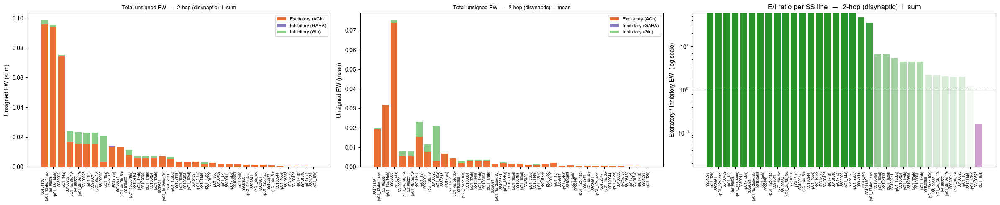

In [66]:
# ── Unsigned composite EW (ACh / GABA / Glu) per SS line — disynaptic ────────
_gaba2_type = (merged_all[merged_all['inter_nt'] == 'gaba']
               .groupby('src_type')['path_ew'].sum().to_dict())
_glu2_type  = (merged_all[merged_all['inter_nt'] == 'glutamate']
               .groupby('src_type')['path_ew'].sum().to_dict())

_rows_u5 = []
for _, row in beh.iterrows():
    types = parse_pC1_types(str(row['CellType']))
    if not types:
        continue
    _n = len(types)
    _rows_u5.append({
        'LineName':   row['LineName'],
        'CellType':   row['CellType'],
        'n_components': _n,
        'excit_ew':   sum(excit_by_type.get(t, 0.0) for t in types),
        'gaba_ew':    sum(_gaba2_type.get(t, 0.0)   for t in types),
        'glu_ew':     sum(_glu2_type.get(t, 0.0)    for t in types),
    })

ss_ew_unsigned = (pd.DataFrame(_rows_u5)
                  .assign(unsigned_sum_ew=lambda d: d['excit_ew']+d['gaba_ew']+d['glu_ew'])
                  .sort_values('unsigned_sum_ew', ascending=False)
                  .reset_index(drop=True))
ss_ew_unsigned['unsigned_mean_ew'] = (ss_ew_unsigned['unsigned_sum_ew']
                                      / ss_ew_unsigned['n_components'])

labels_u = ss_ew_unsigned['LineName'] + '\n(' + ss_ew_unsigned['CellType'].str[:18] + ')'
x_u = range(len(ss_ew_unsigned))

fig, axes = plt.subplots(1, 3, figsize=(24, 5), sharey=False)
for ax, use_mean, title, ylabel in zip(
    axes,
    [False, True],
    ['Total unsigned EW  —  2-hop (disynaptic)  |  sum',
     'Total unsigned EW  —  2-hop (disynaptic)  |  mean'],
    ['Unsigned EW (sum)', 'Unsigned EW (mean)'],
):
    _d = ss_ew_unsigned.copy()
    _div = _d['n_components'] if use_mean else 1
    _e, _g, _gl = _d['excit_ew']/_div, _d['gaba_ew']/_div, _d['glu_ew']/_div
    ax.bar(x_u, _e,  color='#e6550d', alpha=0.85, label='Excitatory (ACh)')
    ax.bar(x_u, _g,  bottom=_e,      color='#756bb1', alpha=0.85, label='Inhibitory (GABA)')
    ax.bar(x_u, _gl, bottom=_e+_g,   color='#74c476', alpha=0.85, label='Inhibitory (Glu)')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(title, fontsize=9)
    ax.set_ylabel(ylabel)
    ax.set_xticks(list(x_u))
    ax.set_xticklabels(labels_u, rotation=90, fontsize=6)
    ax.legend(fontsize=8, loc='upper right')

# ── Panel 3: E/I ratio (log scale, PWG colormap) ─────────────────────────────
_ss_ei5u = ss_ew_unsigned.copy()
_ss_ei5u['inhib_ew'] = _ss_ei5u['gaba_ew'] + _ss_ei5u['glu_ew']
_ss_ei5u['ei_ratio'] = (
    _ss_ei5u['excit_ew'] / _ss_ei5u['inhib_ew'].replace(0., float('nan'))
).fillna(float(EI_RATIO_MAX))
_ss_ei5u['ei_ratio'] = _ss_ei5u['ei_ratio'].clip(lower=1./EI_RATIO_MAX,
                                                  upper=float(EI_RATIO_MAX))
_ss_ei5u['log_ei'] = np.log(_ss_ei5u['ei_ratio'])
_ss_ei5u = _ss_ei5u.sort_values('ei_ratio', ascending=False).reset_index(drop=True)
_labels_ei5u  = _ss_ei5u['LineName'] + '\n(' + _ss_ei5u['CellType'].str[:18] + ')'
_log_max_ei5u = np.log(EI_RATIO_MAX)
_ei5u_norm    = mcolors.TwoSlopeNorm(vmin=-_log_max_ei5u, vcenter=0., vmax=_log_max_ei5u)
_ei5u_colors  = [mcolors.to_hex(PWG_CMAP(_ei5u_norm(v))) for v in _ss_ei5u['log_ei']]
ax = axes[2]
ax.bar(range(len(_ss_ei5u)), _ss_ei5u['ei_ratio'], color=_ei5u_colors, alpha=0.85)
ax.axhline(1., color='black', linewidth=0.8, linestyle='--')
ax.set_yscale('log')
ax.set_ylim(1./EI_RATIO_MAX, EI_RATIO_MAX)
ax.set_title('E/I ratio per SS line  —  2-hop (disynaptic)  |  sum')
ax.set_ylabel('Excitatory / Inhibitory EW  (log scale)')
ax.set_xticks(range(len(_ss_ei5u)))
ax.set_xticklabels(_labels_ei5u, rotation=90, fontsize=6)


plt.tight_layout()
matplotlib.rcParams['svg.fonttype'] = 'none'  # ensure editable text
plt.savefig(RESULTS_DIR / 'SS_line_unsigned_ew.svg', bbox_inches='tight')
plt.show()

## Section 6: SS Line Composite Effective Weight — Disynaptic + Trisynaptic

Same as Section 5 but sums EW contributions from both disynaptic (2-hop) and trisynaptic (3-hop) paths,
using all intermediates (no superclass filter). Per-type combined EW = disynaptic EW + trisynaptic EW.
Types with no paths of either length contribute EW = 0.

In [67]:
# ── Signed EW from ALL trisynaptic paths (no intermediate superclass filter) ──
# Uses paths_3_raw (full cache); sign = nt_sign(inter1) × nt_sign(inter2)
l1_3a = paths_3_raw[paths_3_raw['layer'] == 1].copy()
l2_3a = paths_3_raw[paths_3_raw['layer'] == 2].copy()
l3_3a = paths_3_raw[paths_3_raw['layer'] == 3].copy()

l1_3a['w_norm'] = l1_3a['weight'] / l1_3a['post'].astype(int).map(lambda j: col_sums[j])
l2_3a['w_norm'] = l2_3a['weight'] / l2_3a['post'].astype(int).map(lambda j: col_sums[j])
l3_3a['w_norm'] = l3_3a['weight'] / l3_3a['post'].astype(int).map(lambda j: col_sums[j])

l1_3a = l1_3a.rename(columns={'pre': 'pC1',    'post': 'inter1', 'w_norm': 'wn1'})[['pC1',    'inter1', 'wn1']]
l2_3a = l2_3a.rename(columns={'pre': 'inter1', 'post': 'inter2', 'w_norm': 'wn2'})[['inter1', 'inter2', 'wn2']]
l3_3a = l3_3a.rename(columns={'pre': 'inter2', 'post': 'premotor','w_norm': 'wn3'})[['inter2', 'premotor','wn3']]

m12a = pd.merge(l1_3a, l2_3a, on='inter1')
merged_3a = pd.merge(m12a, l3_3a, on='inter2')
merged_3a['path_ew']      = merged_3a['wn1'] * merged_3a['wn2'] * merged_3a['wn3']
merged_3a['src_type']     = merged_3a['pC1'].astype(int).map(idx_to_type)
merged_3a['inter1_type']  = merged_3a['inter1'].astype(int).map(idx_to_type)
merged_3a['inter2_type']  = merged_3a['inter2'].astype(int).map(idx_to_type)
merged_3a['inter1_sign']  = merged_3a['inter1_type'].map(type_to_nt).fillna('other').map(NT_SIGN).fillna(0)
merged_3a['inter2_sign']  = merged_3a['inter2_type'].map(type_to_nt).fillna('other').map(NT_SIGN).fillna(0)
merged_3a['signed_path_ew'] = merged_3a['path_ew'] * merged_3a['inter1_sign'] * merged_3a['inter2_sign']

sv3_all = merged_3a.groupby('src_type')['signed_path_ew'].sum().to_dict()

# ── Combined EW per SS line ────────────────────────────────────────────────────
all_pC1_types = set(sv2_all) | set(sv3_all)
rows6 = []

for _, row in beh.iterrows():
    types = parse_pC1_types(str(row['CellType']))
    if not types:
        continue
    missing = [t for t in types if t not in all_pC1_types]
    ews = [sv2_all.get(t, 0.0) + sv3_all.get(t, 0.0) for t in types]
    rows6.append({
        'LineName':                   row['LineName'],
        'CellType':                   row['CellType'],
        'component_types':            ', '.join(types),
        'n_components':               len(types),
        'missing_types':              ', '.join(missing) if missing else '',
        'composite_sum_ew_combined':  sum(ews),
        'composite_mean_ew_combined': sum(ews) / len(ews),
    })

ss_ew_combined = pd.DataFrame(rows6).sort_values('composite_sum_ew_combined', ascending=False).reset_index(drop=True)

print(f'{len(ss_ew_combined)} SS lines; '
      f'{(ss_ew_combined["missing_types"] != "").sum()} have types with no paths (EW=0)')
display(ss_ew_combined)
ss_ew_combined.to_csv(RESULTS_DIR / 'SS_line_composite_ew_combined.csv', index=False)

33 SS lines; 0 have types with no paths (EW=0)


,LineName,CellType,component_types,n_components,missing_types,composite_sum_ew_combined,composite_mean_ew_combined
0,SS101156,"pC1_13abc, 14ab","P1_13a, P1_13b, P1_13c, P1_14a, P1_14b",5,,0.116999,0.023400
1,SS106638,"pC1_13a,14ab","P1_13a, P1_14a, P1_14b",3,,0.114942,0.038314
2,SS59900,pC1_14a,P1_14a,1,,0.088558,0.088558
3,SS100234,"pC1_4a, 5b, 6b","P1_4a, P1_5b, P1_6b",3,,0.014487,0.004829
4,SS39313,PC1x_ac,"pC1x_a, pC1x_c",2,,0.013223,0.006612
5,SS106227,"pC1_4b, 8c,19","P1_4b, P1_8c, P1_19",3,,0.012172,0.004057
6,SS99807,"pC1_8a, 19","P1_8a, P1_19",2,,0.010850,0.005425
7,SS100232,"pC1_4a, 6b, 19","P1_4a, P1_6b, P1_19",3,,0.010620,0.003540
8,SS100895,pC1_19,P1_19,1,,0.010043,0.010043
9,SS102671,pC1_15abc,"P1_15a, P1_15b, P1_15c",3,,0.009185,0.003062


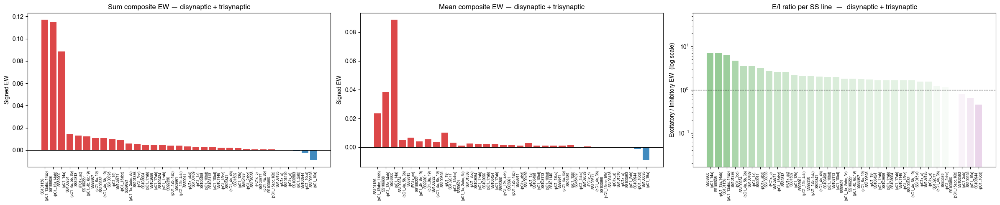

In [68]:
labels6 = ss_ew_combined['LineName'] + '\n(' + ss_ew_combined['CellType'].str[:18] + ')'
x6 = range(len(ss_ew_combined))

fig, axes = plt.subplots(1, 3, figsize=(24, 5), sharey=False)

for ax, col, title in zip(axes,
    ['composite_sum_ew_combined', 'composite_mean_ew_combined'],
    ['Sum composite EW — disynaptic + trisynaptic', 'Mean composite EW — disynaptic + trisynaptic'],
):
    colors = ['#d62728' if v >= 0 else '#1f77b4' for v in ss_ew_combined[col]]
    ax.bar(x6, ss_ew_combined[col], color=colors, alpha=0.85)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel('Signed EW')
    ax.set_xticks(list(x6))
    ax.set_xticklabels(labels6, rotation=90, fontsize=6)

# ── Panel 3: E/I ratio (log scale, PWG colormap) ─────────────────────────────
# Combined excit/inhib EW: disynaptic (excit_by_type / inhib_by_type) +
# trisynaptic (signed_path_ew sign on merged_3a).
_excit3a_ei6 = (merged_3a[merged_3a['signed_path_ew'] > 0]
                .groupby('src_type')['path_ew'].sum().to_dict())
_inhib3a_ei6 = (merged_3a[merged_3a['signed_path_ew'] < 0]
                .groupby('src_type')['path_ew'].sum().to_dict())
_rows_ei6 = []
for _, _row6 in beh.iterrows():
    _types6 = parse_pC1_types(str(_row6['CellType']))
    if not _types6:
        continue
    _rows_ei6.append({
        'LineName': _row6['LineName'],
        'CellType': _row6['CellType'],
        'excit_ew': sum(excit_by_type.get(t, 0.) + _excit3a_ei6.get(t, 0.) for t in _types6),
        'inhib_ew': sum(inhib_by_type.get(t, 0.) + _inhib3a_ei6.get(t, 0.) for t in _types6),
    })
_ss_ei6 = pd.DataFrame(_rows_ei6)
_ss_ei6['ei_ratio'] = (
    _ss_ei6['excit_ew'] / _ss_ei6['inhib_ew'].replace(0., float('nan'))
).fillna(float(EI_RATIO_MAX))
_ss_ei6['ei_ratio'] = _ss_ei6['ei_ratio'].clip(lower=1./EI_RATIO_MAX,
                                                upper=float(EI_RATIO_MAX))
_ss_ei6['log_ei'] = np.log(_ss_ei6['ei_ratio'])
_ss_ei6 = _ss_ei6.sort_values('ei_ratio', ascending=False).reset_index(drop=True)
_labels_ei6  = _ss_ei6['LineName'] + '\n(' + _ss_ei6['CellType'].str[:18] + ')'
_log_max_ei6 = np.log(EI_RATIO_MAX)
_ei6_norm    = mcolors.TwoSlopeNorm(vmin=-_log_max_ei6, vcenter=0., vmax=_log_max_ei6)
_ei6_colors  = [mcolors.to_hex(PWG_CMAP(_ei6_norm(v))) for v in _ss_ei6['log_ei']]
ax = axes[2]
ax.bar(range(len(_ss_ei6)), _ss_ei6['ei_ratio'], color=_ei6_colors, alpha=0.85)
ax.axhline(1., color='black', linewidth=0.8, linestyle='--')
ax.set_yscale('log')
ax.set_ylim(1./EI_RATIO_MAX, EI_RATIO_MAX)
ax.set_title('E/I ratio per SS line  —  disynaptic + trisynaptic')
ax.set_ylabel('Excitatory / Inhibitory EW  (log scale)')
ax.set_xticks(range(len(_ss_ei6)))
ax.set_xticklabels(_labels_ei6, rotation=90, fontsize=6)


plt.tight_layout()
matplotlib.rcParams['svg.fonttype'] = 'none'  # ensure editable text
plt.savefig(RESULTS_DIR / 'SS_line_composite_ew_combined.svg', bbox_inches='tight')
plt.show()

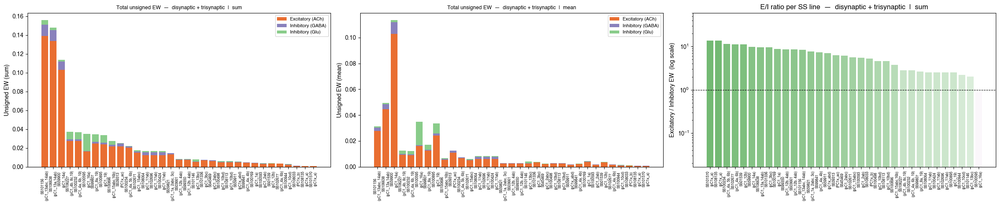

In [69]:
# ── Unsigned composite EW (ACh / GABA / Glu) per SS line — disynaptic + trisynaptic ──
# Disynaptic: from excit_by_type, _gaba2_type, _glu2_type (computed in sec5 cell above)
# Trisynaptic: classify by DN (inter2) NT for inhibitory paths
_inter2a_nt = merged_3a['inter2_type'].map(type_to_nt).fillna('other')

_excit3a_type = (merged_3a[merged_3a['signed_path_ew'] > 0]
                 .groupby('src_type')['path_ew'].sum().to_dict())
_gaba3a_type  = (merged_3a[(merged_3a['signed_path_ew'] < 0) & (_inter2a_nt == 'gaba')]
                 .groupby('src_type')['path_ew'].sum().to_dict())
_glu3a_type   = (merged_3a[(merged_3a['signed_path_ew'] < 0) & (_inter2a_nt == 'glutamate')]
                 .groupby('src_type')['path_ew'].sum().to_dict())

_rows_u6 = []
for _, row in beh.iterrows():
    types = parse_pC1_types(str(row['CellType']))
    if not types:
        continue
    _n = len(types)
    _rows_u6.append({
        'LineName':   row['LineName'],
        'CellType':   row['CellType'],
        'n_components': _n,
        'excit_ew':   sum(excit_by_type.get(t,0.) + _excit3a_type.get(t,0.) for t in types),
        'gaba_ew':    sum(_gaba2_type.get(t,0.)   + _gaba3a_type.get(t,0.)  for t in types),
        'glu_ew':     sum(_glu2_type.get(t,0.)    + _glu3a_type.get(t,0.)   for t in types),
    })

ss_ew_unsigned_comb = (pd.DataFrame(_rows_u6)
                       .assign(unsigned_sum_ew=lambda d: d['excit_ew']+d['gaba_ew']+d['glu_ew'])
                       .sort_values('unsigned_sum_ew', ascending=False)
                       .reset_index(drop=True))
ss_ew_unsigned_comb['unsigned_mean_ew'] = (ss_ew_unsigned_comb['unsigned_sum_ew']
                                           / ss_ew_unsigned_comb['n_components'])

labels_u6 = (ss_ew_unsigned_comb['LineName'] + '\n('
             + ss_ew_unsigned_comb['CellType'].str[:18] + ')')
x_u6 = range(len(ss_ew_unsigned_comb))

fig, axes = plt.subplots(1, 3, figsize=(24, 5), sharey=False)
for ax, use_mean, title, ylabel in zip(
    axes,
    [False, True],
    ['Total unsigned EW  —  disynaptic + trisynaptic  |  sum',
     'Total unsigned EW  —  disynaptic + trisynaptic  |  mean'],
    ['Unsigned EW (sum)', 'Unsigned EW (mean)'],
):
    _d = ss_ew_unsigned_comb.copy()
    _div = _d['n_components'] if use_mean else 1
    _e, _g, _gl = _d['excit_ew']/_div, _d['gaba_ew']/_div, _d['glu_ew']/_div
    ax.bar(x_u6, _e,  color='#e6550d', alpha=0.85, label='Excitatory (ACh)')
    ax.bar(x_u6, _g,  bottom=_e,      color='#756bb1', alpha=0.85, label='Inhibitory (GABA)')
    ax.bar(x_u6, _gl, bottom=_e+_g,   color='#74c476', alpha=0.85, label='Inhibitory (Glu)')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(title, fontsize=9)
    ax.set_ylabel(ylabel)
    ax.set_xticks(list(x_u6))
    ax.set_xticklabels(labels_u6, rotation=90, fontsize=6)
    ax.legend(fontsize=8, loc='upper right')

# ── Panel 3: E/I ratio (log scale, PWG colormap) ─────────────────────────────
_ss_ei6u = ss_ew_unsigned_comb.copy()
_ss_ei6u['inhib_ew'] = _ss_ei6u['gaba_ew'] + _ss_ei6u['glu_ew']
_ss_ei6u['ei_ratio'] = (
    _ss_ei6u['excit_ew'] / _ss_ei6u['inhib_ew'].replace(0., float('nan'))
).fillna(float(EI_RATIO_MAX))
_ss_ei6u['ei_ratio'] = _ss_ei6u['ei_ratio'].clip(lower=1./EI_RATIO_MAX,
                                                  upper=float(EI_RATIO_MAX))
_ss_ei6u['log_ei'] = np.log(_ss_ei6u['ei_ratio'])
_ss_ei6u = _ss_ei6u.sort_values('ei_ratio', ascending=False).reset_index(drop=True)
_labels_ei6u  = _ss_ei6u['LineName'] + '\n(' + _ss_ei6u['CellType'].str[:18] + ')'
_log_max_ei6u = np.log(EI_RATIO_MAX)
_ei6u_norm    = mcolors.TwoSlopeNorm(vmin=-_log_max_ei6u, vcenter=0., vmax=_log_max_ei6u)
_ei6u_colors  = [mcolors.to_hex(PWG_CMAP(_ei6u_norm(v))) for v in _ss_ei6u['log_ei']]
ax = axes[2]
ax.bar(range(len(_ss_ei6u)), _ss_ei6u['ei_ratio'], color=_ei6u_colors, alpha=0.85)
ax.axhline(1., color='black', linewidth=0.8, linestyle='--')
ax.set_yscale('log')
ax.set_ylim(1./EI_RATIO_MAX, EI_RATIO_MAX)
ax.set_title('E/I ratio per SS line  —  disynaptic + trisynaptic  |  sum')
ax.set_ylabel('Excitatory / Inhibitory EW  (log scale)')
ax.set_xticks(range(len(_ss_ei6u)))
ax.set_xticklabels(_labels_ei6u, rotation=90, fontsize=6)


plt.tight_layout()
matplotlib.rcParams['svg.fonttype'] = 'none'  # ensure editable text
plt.savefig(RESULTS_DIR / 'SS_line_unsigned_ew_combined.svg', bbox_inches='tight')
plt.show()

# Cache to avoid recomputing
cache_4 = RESULTS_DIR / f'{DATASET}_4hop_paths.csv'

if cache_4.exists():
    print('Loading cached 4-hop paths...')
    paths_4_raw = pd.read_csv(cache_4)
else:
    print('Computing 4-hop paths (this may take several minutes)...')
    paths_4_raw = find_paths_of_length(prop, inidx, outidx, target_layer_number=4)
    if paths_4_raw is not None and not paths_4_raw.empty:
        paths_4_raw = filter_paths(paths_4_raw, threshold=WEIGHT_THRESHOLD)
        paths_4_raw.to_csv(cache_4, index=False)
    else:
        paths_4_raw = pd.DataFrame()
        print('WARNING: No 4-hop paths found.')

print(f'Raw 4-hop edges: {len(paths_4_raw):,}')

# ── Hoeller EW for 4-hop paths (no intermediate superclass filter) ────────────
l1_4a = paths_4_raw[paths_4_raw['layer'] == 1].copy()
l2_4a = paths_4_raw[paths_4_raw['layer'] == 2].copy()
l3_4a = paths_4_raw[paths_4_raw['layer'] == 3].copy()
l4_4a = paths_4_raw[paths_4_raw['layer'] == 4].copy()

for ldf in [l1_4a, l2_4a, l3_4a, l4_4a]:
    ldf['w_norm'] = ldf['weight'] / ldf['post'].astype(int).map(lambda j: col_sums[j])

l1_4a = l1_4a.rename(columns={'pre': 'pC1',    'post': 'inter1', 'w_norm': 'wn1'})[['pC1',    'inter1', 'wn1']]
l2_4a = l2_4a.rename(columns={'pre': 'inter1', 'post': 'inter2', 'w_norm': 'wn2'})[['inter1', 'inter2', 'wn2']]
l3_4a = l3_4a.rename(columns={'pre': 'inter2', 'post': 'inter3', 'w_norm': 'wn3'})[['inter2', 'inter3', 'wn3']]
l4_4a = l4_4a.rename(columns={'pre': 'inter3', 'post': 'premotor','w_norm': 'wn4'})[['inter3', 'premotor', 'wn4']]

m12_4 = pd.merge(l1_4a, l2_4a, on='inter1')
m123_4 = pd.merge(m12_4, l3_4a, on='inter2')
merged_4a = pd.merge(m123_4, l4_4a, on='inter3')
merged_4a['path_ew']     = merged_4a['wn1'] * merged_4a['wn2'] * merged_4a['wn3'] * merged_4a['wn4']
merged_4a['src_type']    = merged_4a['pC1'].astype(int).map(idx_to_type)
merged_4a['inter1_type'] = merged_4a['inter1'].astype(int).map(idx_to_type)
merged_4a['inter2_type'] = merged_4a['inter2'].astype(int).map(idx_to_type)
merged_4a['inter3_type'] = merged_4a['inter3'].astype(int).map(idx_to_type)
merged_4a['inter1_sign'] = merged_4a['inter1_type'].map(type_to_nt).fillna('other').map(NT_SIGN).fillna(0)
merged_4a['inter2_sign'] = merged_4a['inter2_type'].map(type_to_nt).fillna('other').map(NT_SIGN).fillna(0)
merged_4a['inter3_sign'] = merged_4a['inter3_type'].map(type_to_nt).fillna('other').map(NT_SIGN).fillna(0)
merged_4a['signed_path_ew'] = (merged_4a['path_ew']
                                * merged_4a['inter1_sign']
                                * merged_4a['inter2_sign']
                                * merged_4a['inter3_sign'])

print(f'4-hop merged paths: {len(merged_4a):,}')


## Section 7: Per-Premotor-Target EW (Lilivis-guided song type decomposition)

Decompose composite EW by individual premotor target type instead of summing across all targets.
Based on Lilivis et al. 2024: dPR1 = pulse, TN1a a–i = sine, vPR9_a inhibits pulse, vPR9_b/c inhibit sine.

In [70]:
# Add premotor type label to merged_all (disynaptic, Section 5)
merged_all['premotor_type'] = merged_all['post_l2'].astype(int).map(idx_to_type)

# Add premotor type label to merged_3a (trisynaptic, Section 6)
if 'merged_3a' in vars():
    merged_3a['premotor_type'] = merged_3a['premotor'].astype(int).map(idx_to_type)

# Add premotor type label to merged_4a (4-hop, Section 8)
if 'merged_4a' in vars():
    merged_4a['premotor_type'] = merged_4a['premotor'].astype(int).map(idx_to_type)

# Combined disynaptic + trisynaptic
_frames_2_3 = [merged_all[['src_type', 'premotor_type', 'signed_path_ew']]]
if 'merged_3a' in vars():
    _frames_2_3.append(merged_3a[['src_type', 'premotor_type', 'signed_path_ew']])
combined_paths = pd.concat(_frames_2_3, ignore_index=True)

# Combined disynaptic + trisynaptic + 4-hop
_frames_4hop = [merged_all[['src_type', 'premotor_type', 'signed_path_ew']]]
if 'merged_3a' in vars():
    _frames_4hop.append(merged_3a[['src_type', 'premotor_type', 'signed_path_ew']])
if 'merged_4a' in vars():
    _frames_4hop.append(merged_4a[['src_type', 'premotor_type', 'signed_path_ew']])
combined_paths_4hop = pd.concat(_frames_4hop, ignore_index=True)

def build_ss_ew_pt(path_df):
    """Aggregate per-(pC1_type, premotor_type) signed EW to SS line level."""
    ew_dict = (
        path_df.groupby(['src_type', 'premotor_type'])['signed_path_ew']
        .sum()
        .to_dict()
    )
    pos_dict = (
        path_df[path_df['signed_path_ew'] > 0]
        .groupby(['src_type', 'premotor_type'])['signed_path_ew']
        .sum().to_dict()
    )
    neg_dict = (
        path_df[path_df['signed_path_ew'] < 0]
        .groupby(['src_type', 'premotor_type'])['signed_path_ew']
        .sum().to_dict()
    )
    rows = []
    for _, row in beh.iterrows():
        types = parse_pC1_types(str(row['CellType']))
        if not types:
            continue
        entry = {'LineName': row['LineName'], 'CellType': row['CellType'],
                 'n_components': len(types)}
        for pm_grp, pm_subs in PREMOTOR_GROUPS.items():
            ews = [ew_dict.get((t, sub), 0.0) for t in types for sub in pm_subs]
            entry[f'sum_ew_{pm_grp}']  = sum(ews)
            entry[f'mean_ew_{pm_grp}'] = sum(ews) / len(types)
            entry[f'pos_ew_{pm_grp}']  = sum(pos_dict.get((t, sub), 0.0) for t in types for sub in pm_subs)
            entry[f'neg_ew_{pm_grp}']  = sum(neg_dict.get((t, sub), 0.0) for t in types for sub in pm_subs)
        rows.append(entry)
    df_out = pd.DataFrame(rows)
    # Derived song-drive metrics (Lilivis 2024)
    pulse_premotor = ['dPR1', 'vMS12', 'dMS9']
    sine_premotor  = ['dMS2', 'TN1a']
    df_out['pulse_drive'] = (
        sum(df_out[f'sum_ew_{p}'] for p in pulse_premotor)
        - df_out['sum_ew_vPR9']
    )
    df_out['sine_drive'] = (
        sum(df_out[f'sum_ew_{p}'] for p in sine_premotor)
        - df_out['sum_ew_vPR9']
    )
    return df_out

ss_ew_pt_2hop          = build_ss_ew_pt(merged_all)
ss_ew_pt_combined      = build_ss_ew_pt(combined_paths)
ss_ew_pt_4hop_included = build_ss_ew_pt(combined_paths_4hop)

print(f'{len(ss_ew_pt_2hop)} SS lines')
display(ss_ew_pt_2hop[['LineName', 'CellType', 'pulse_drive', 'sine_drive']])

ss_ew_pt_2hop.to_csv(RESULTS_DIR / 'SS_line_x_premotor_ew_2hop.csv', index=False)
ss_ew_pt_combined.to_csv(RESULTS_DIR / 'SS_line_x_premotor_ew_combined.csv', index=False)
ss_ew_pt_4hop_included.to_csv(RESULTS_DIR / 'SS_line_x_premotor_ew_4hop_included.csv', index=False)


33 SS lines


,LineName,CellType,pulse_drive,sine_drive
0,SS100769,pC1_1a,-2.231330e-04,0.001364
1,SS45469,pC1_2abc,1.003587e-04,0.001315
2,SS100593,pC1_2ab,3.704504e-05,0.000572
3,SS59821,"pC1_1a, 2abc, 3c",-3.843289e-04,0.003884
4,SS101336,pC1_3bc,-3.350968e-04,0.001695
5,SS99841,"pC1_4a, 4b",-1.519518e-04,0.000930
6,SS102677,"pC1_4a, 6b",-1.211194e-04,0.000713
7,SS100234,"pC1_4a, 5b, 6b",-8.290525e-04,0.007132
8,SS100232,"pC1_4a, 6b, 19",-8.868153e-04,0.008297
9,SS106227,"pC1_4b, 8c,19",-7.965283e-04,0.007802


In [71]:
# ── Excit/inhib EW split for combined paths (disynaptic + trisynaptic) ───────
# Uses sign of signed_path_ew to split excitatory (>0) vs inhibitory (<0)
_excit_comb = (
    combined_paths[combined_paths['signed_path_ew'] > 0]
    .groupby('src_type')['signed_path_ew'].sum().to_dict()
)
_inhib_comb = (
    combined_paths[combined_paths['signed_path_ew'] < 0]
    .groupby('src_type')['signed_path_ew'].sum().to_dict()
)

_rows_ei_comb = []
for _, row in beh.iterrows():
    types = parse_pC1_types(str(row['CellType']))
    if not types:
        continue
    _rows_ei_comb.append({
        'LineName':     row['LineName'],
        'excit_sum_ew': sum(_excit_comb.get(t, 0.0) for t in types),
        'inhib_sum_ew': sum(_inhib_comb.get(t, 0.0) for t in types),
    })

ss_ew_ei_combined = pd.DataFrame(_rows_ei_comb)
ss_ew_ei_combined.to_csv(RESULTS_DIR / 'SS_line_excit_inhib_ew_combined.csv', index=False)
print(f'Saved combined excit/inhib EW for {len(ss_ew_ei_combined)} SS lines')
display(ss_ew_ei_combined.sort_values('excit_sum_ew', ascending=False))

Saved combined excit/inhib EW for 33 SS lines


,LineName,excit_sum_ew,inhib_sum_ew
19,SS101156,0.139174,-0.022175
17,SS106638,0.133909,-0.018967
20,SS59900,0.102905,-0.014347
9,SS106227,0.027399,-0.015227
8,SS100232,0.027256,-0.016636
10,SS99807,0.024950,-0.014101
27,SS100895,0.024066,-0.014023
31,SS39313,0.021688,-0.008464
22,SS100896,0.021635,-0.021155
7,SS100234,0.020132,-0.005645


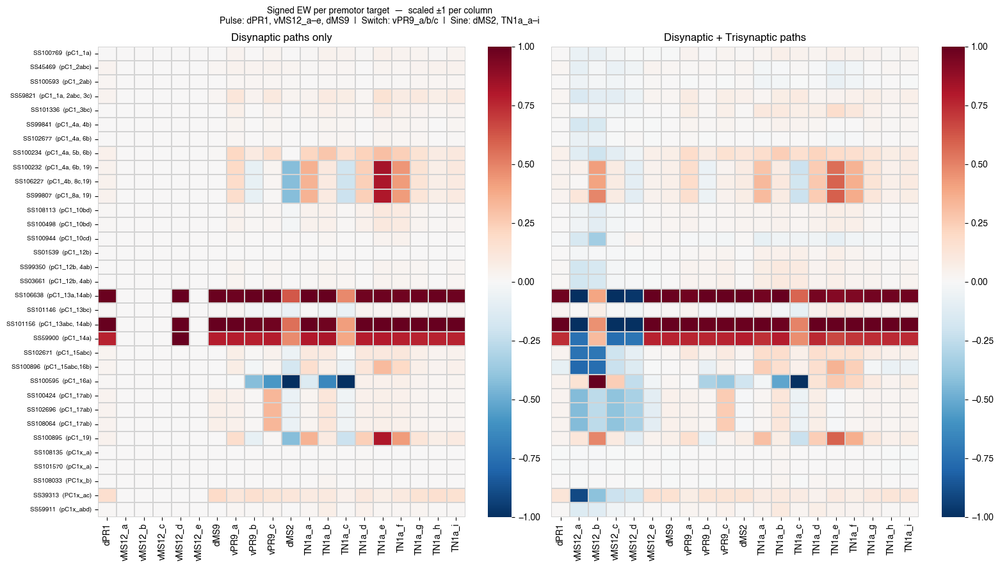

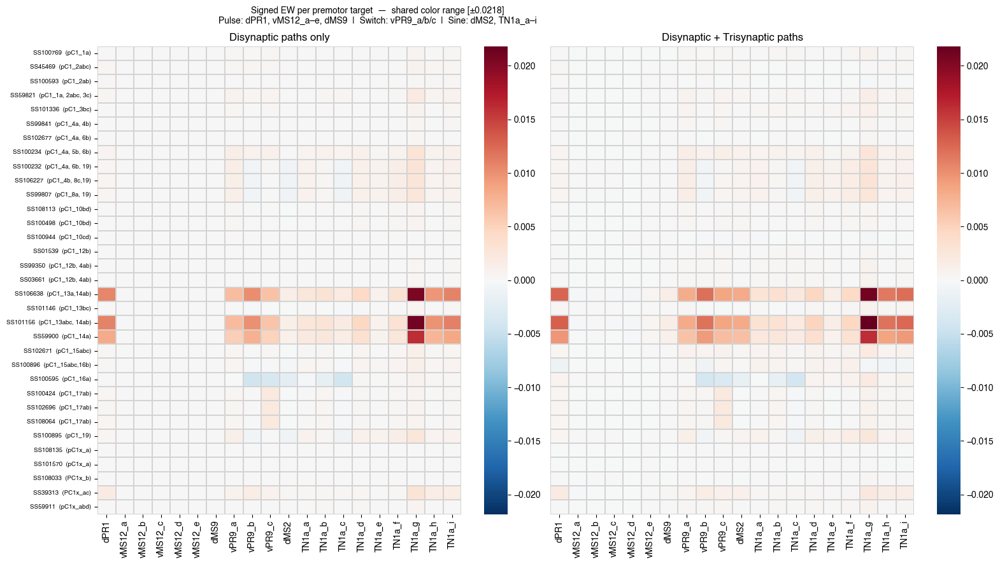

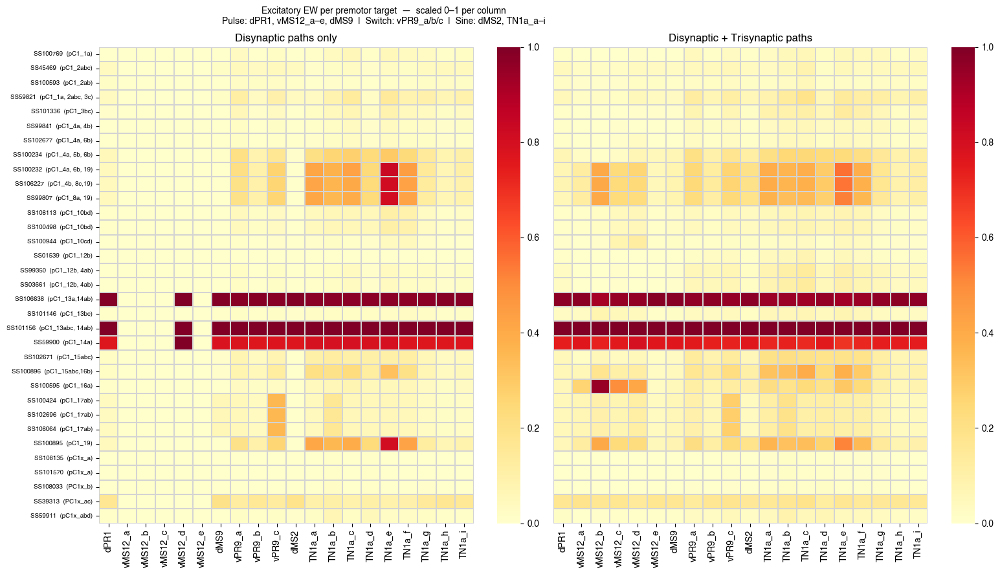

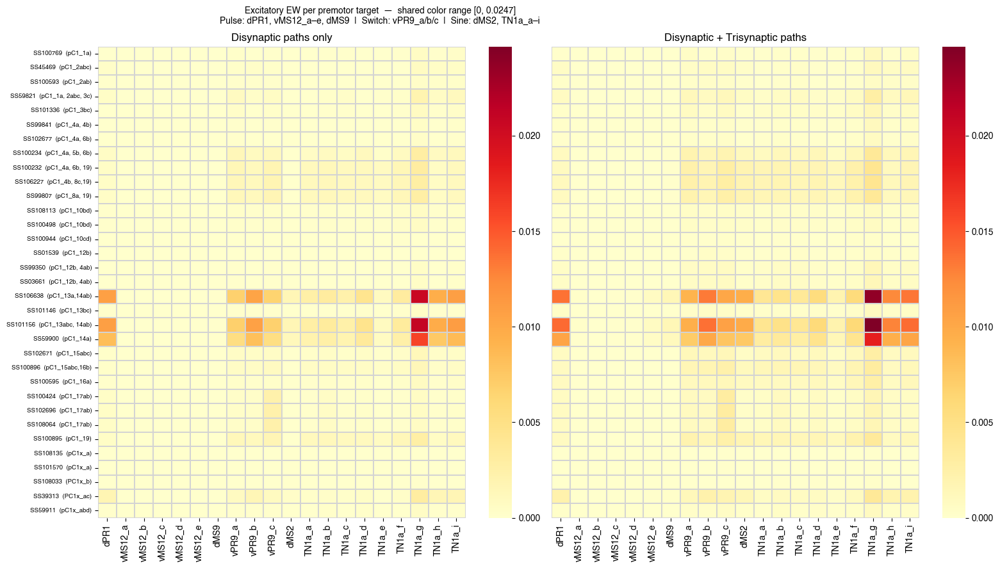

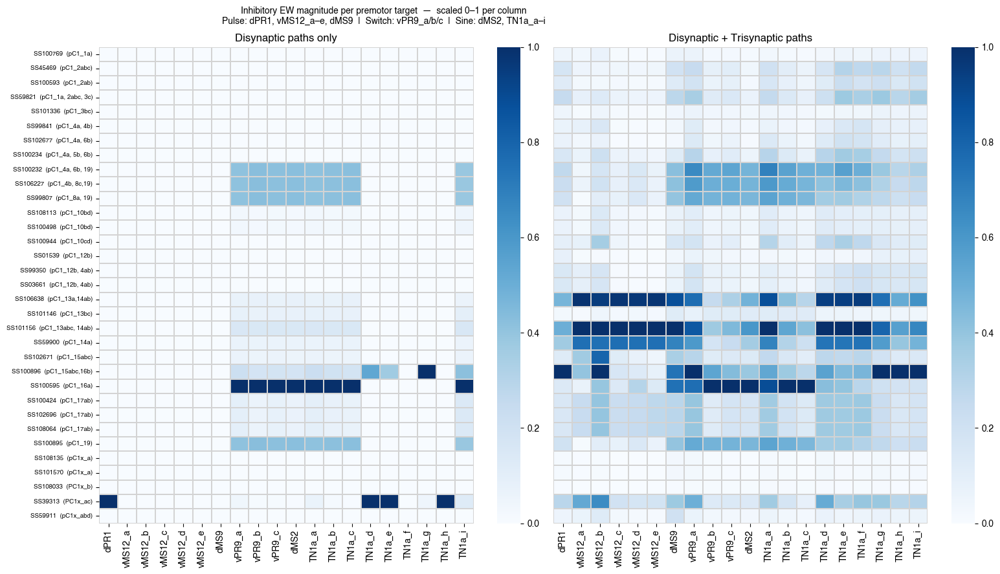

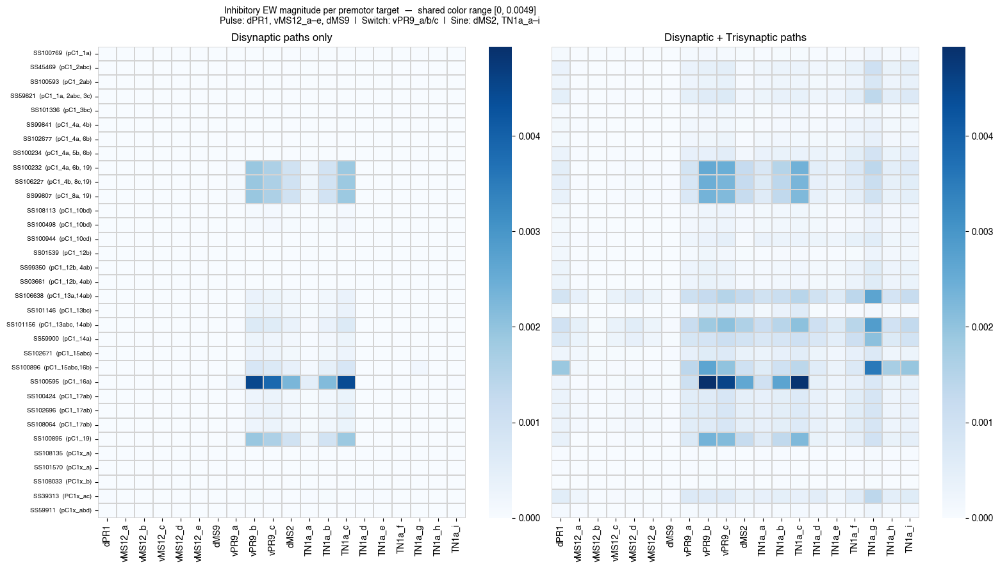

In [72]:
sum_cols = [f'sum_ew_{pm}' for pm in PREMOTOR_TARGETS]

def make_hm_data(ss_ew_pt, normalize_per_col=False, global_vmax=None):
    """Return (hm_data, vmax) ready for sns.heatmap.
    normalize_per_col: scale each column independently to [-1, 1].
    global_vmax: if given, use as symmetric color range (raw values).
    """
    hm = ss_ew_pt[sum_cols].copy()
    hm.columns = PREMOTOR_TARGETS
    if normalize_per_col:
        for col in hm.columns:
            v = hm[col].abs().max()
            if v > 0:
                hm[col] /= v
        return hm, 1.0
    else:
        vmax = global_vmax if global_vmax is not None else hm.abs().max().max()
        return hm, vmax

def plot_heatmap_pair(df_2hop, df_combined, normalize_per_col, global_vmax=None):
    ylabels = (df_2hop['LineName'] + '  (' + df_2hop['CellType'].str[:22] + ')').tolist()
    hm_2hop, vmax = make_hm_data(df_2hop,     normalize_per_col, global_vmax)
    hm_comb, _    = make_hm_data(df_combined, normalize_per_col, global_vmax)

    fig, axes = plt.subplots(1, 2, figsize=(20, 9))
    for ax, hm, show_y, title in zip(
        axes,
        [hm_2hop, hm_comb],
        [True, False],
        ['Disynaptic paths only', 'Disynaptic + Trisynaptic paths'],
    ):
        sns.heatmap(hm, ax=ax, cmap='RdBu_r', center=0, vmin=-vmax, vmax=vmax,
                    yticklabels=ylabels if show_y else False,
                    linewidths=0.3, linecolor='lightgray')
        ax.set_title(title)
        if show_y:
            ax.tick_params(axis='y', labelsize=7, rotation=0)
        ax.set_xlabel('')
    return fig

# ── Figure 1: per-column normalised (±1 per column) ──────────────────────────
fig1 = plot_heatmap_pair(ss_ew_pt_2hop, ss_ew_pt_combined, normalize_per_col=True)
fig1.suptitle('Signed EW per premotor target  —  scaled \u00b11 per column\n'
              'Pulse: dPR1, vMS12_a\u2013e, dMS9  |  Switch: vPR9_a/b/c  |  Sine: dMS2, TN1a_a\u2013i',
              fontsize=10)
fig1.tight_layout()
fig1.subplots_adjust(left=0.28)
fig1.savefig(RESULTS_DIR / 'SS_line_x_premotor_ew_heatmap_norm.pdf', bbox_inches='tight')
fig1.savefig(RESULTS_DIR / 'SS_line_x_premotor_ew_heatmap_norm.svg', bbox_inches='tight')
plt.show()

# ── Figure 2: shared symmetric color range across all columns ─────────────────
# vmax = max absolute value across all columns in both DataFrames
global_vmax = max(
    ss_ew_pt_2hop[sum_cols].abs().max().max(),
    ss_ew_pt_combined[sum_cols].abs().max().max(),
)
fig2 = plot_heatmap_pair(ss_ew_pt_2hop, ss_ew_pt_combined,
                         normalize_per_col=False, global_vmax=global_vmax)
fig2.suptitle(f'Signed EW per premotor target  —  shared color range [\u00b1{global_vmax:.4f}]\n'
              'Pulse: dPR1, vMS12_a\u2013e, dMS9  |  Switch: vPR9_a/b/c  |  Sine: dMS2, TN1a_a\u2013i',
              fontsize=10)
fig2.tight_layout()
fig2.subplots_adjust(left=0.28)
fig2.savefig(RESULTS_DIR / 'SS_line_x_premotor_ew_heatmap_shared.pdf', bbox_inches='tight')
fig2.savefig(RESULTS_DIR / 'SS_line_x_premotor_ew_heatmap_shared.svg', bbox_inches='tight')
plt.show()
pos_cols = [f'pos_ew_{pm}' for pm in PREMOTOR_TARGETS]
neg_cols = [f'neg_ew_{pm}' for pm in PREMOTOR_TARGETS]

def make_hm_data_ei(ss_ew_pt, col_prefix, normalize_per_col=False, global_vmax=None):
    """Return (hm_data, vmax) for excitatory (pos_ew) or inhibitory (neg_ew) columns."""
    cols = [f'{col_prefix}_{pm}' for pm in PREMOTOR_TARGETS]
    hm = ss_ew_pt[cols].copy()
    hm.columns = PREMOTOR_TARGETS
    if col_prefix == 'neg_ew':
        hm = hm.abs()  # show magnitude
    if normalize_per_col:
        for col in hm.columns:
            v = hm[col].max()
            if v > 0:
                hm[col] /= v
        return hm, 1.0
    else:
        vmax = global_vmax if global_vmax is not None else hm.max().max()
        return hm, vmax

def plot_heatmap_pair_ei(df_2hop, df_combined, col_prefix, cmap, normalize_per_col, global_vmax=None):
    ylabels = (df_2hop['LineName'] + '  (' + df_2hop['CellType'].str[:22] + ')').tolist()
    hm_2hop, vmax = make_hm_data_ei(df_2hop,     col_prefix, normalize_per_col, global_vmax)
    hm_comb, _    = make_hm_data_ei(df_combined, col_prefix, normalize_per_col, global_vmax)

    fig, axes = plt.subplots(1, 2, figsize=(20, 9))
    for ax, hm, show_y, title in zip(
        axes,
        [hm_2hop, hm_comb],
        [True, False],
        ['Disynaptic paths only', 'Disynaptic + Trisynaptic paths'],
    ):
        sns.heatmap(hm, ax=ax, cmap=cmap, vmin=0, vmax=vmax,
                    yticklabels=ylabels if show_y else False,
                    linewidths=0.3, linecolor='lightgray')
        ax.set_title(title)
        if show_y:
            ax.tick_params(axis='y', labelsize=7, rotation=0)
        ax.set_xlabel('')
    return fig

_pm_label = 'Pulse: dPR1, vMS12_a–e, dMS9  |  Switch: vPR9_a/b/c  |  Sine: dMS2, TN1a_a–i'

# ── Figure 3: Excitatory EW (positive path EW), per-column normalised ──────────────────────
fig3 = plot_heatmap_pair_ei(ss_ew_pt_2hop, ss_ew_pt_combined, 'pos_ew', 'YlOrRd',
                             normalize_per_col=True)
fig3.suptitle(f'Excitatory EW per premotor target  —  scaled 0–1 per column\n{_pm_label}',
              fontsize=10)
fig3.tight_layout()
fig3.subplots_adjust(left=0.28)
fig3.savefig(RESULTS_DIR / 'SS_line_x_premotor_excit_ew_heatmap_norm.pdf', bbox_inches='tight')
fig3.savefig(RESULTS_DIR / 'SS_line_x_premotor_excit_ew_heatmap_norm.svg', bbox_inches='tight')
plt.show()

# ── Figure 4: Excitatory EW, shared color range ─────────────────────────────────────
global_vmax_pos = max(
    ss_ew_pt_2hop[pos_cols].max().max(),
    ss_ew_pt_combined[pos_cols].max().max(),
)
fig4 = plot_heatmap_pair_ei(ss_ew_pt_2hop, ss_ew_pt_combined, 'pos_ew', 'YlOrRd',
                             normalize_per_col=False, global_vmax=global_vmax_pos)
fig4.suptitle(f'Excitatory EW per premotor target  —  shared color range [0, {global_vmax_pos:.4f}]\n{_pm_label}',
              fontsize=10)
fig4.tight_layout()
fig4.subplots_adjust(left=0.28)
fig4.savefig(RESULTS_DIR / 'SS_line_x_premotor_excit_ew_heatmap_shared.pdf', bbox_inches='tight')
fig4.savefig(RESULTS_DIR / 'SS_line_x_premotor_excit_ew_heatmap_shared.svg', bbox_inches='tight')
plt.show()

# ── Figure 5: Inhibitory EW magnitude (|neg path EW|), per-column normalised ────────────
fig5 = plot_heatmap_pair_ei(ss_ew_pt_2hop, ss_ew_pt_combined, 'neg_ew', 'Blues',
                             normalize_per_col=True)
fig5.suptitle(f'Inhibitory EW magnitude per premotor target  —  scaled 0–1 per column\n{_pm_label}',
              fontsize=10)
fig5.tight_layout()
fig5.subplots_adjust(left=0.28)
fig5.savefig(RESULTS_DIR / 'SS_line_x_premotor_inhib_ew_heatmap_norm.pdf', bbox_inches='tight')
fig5.savefig(RESULTS_DIR / 'SS_line_x_premotor_inhib_ew_heatmap_norm.svg', bbox_inches='tight')
plt.show()

# ── Figure 6: Inhibitory EW magnitude, shared color range ─────────────────────────────
global_vmax_neg = max(
    ss_ew_pt_2hop[neg_cols].abs().max().max(),
    ss_ew_pt_combined[neg_cols].abs().max().max(),
)
fig6 = plot_heatmap_pair_ei(ss_ew_pt_2hop, ss_ew_pt_combined, 'neg_ew', 'Blues',
                             normalize_per_col=False, global_vmax=global_vmax_neg)
fig6.suptitle(f'Inhibitory EW magnitude per premotor target  —  shared color range [0, {global_vmax_neg:.4f}]\n{_pm_label}',
              fontsize=10)
fig6.tight_layout()
fig6.subplots_adjust(left=0.28)
fig6.savefig(RESULTS_DIR / 'SS_line_x_premotor_inhib_ew_heatmap_shared.pdf', bbox_inches='tight')
fig6.savefig(RESULTS_DIR / 'SS_line_x_premotor_inhib_ew_heatmap_shared.svg', bbox_inches='tight')
plt.show()

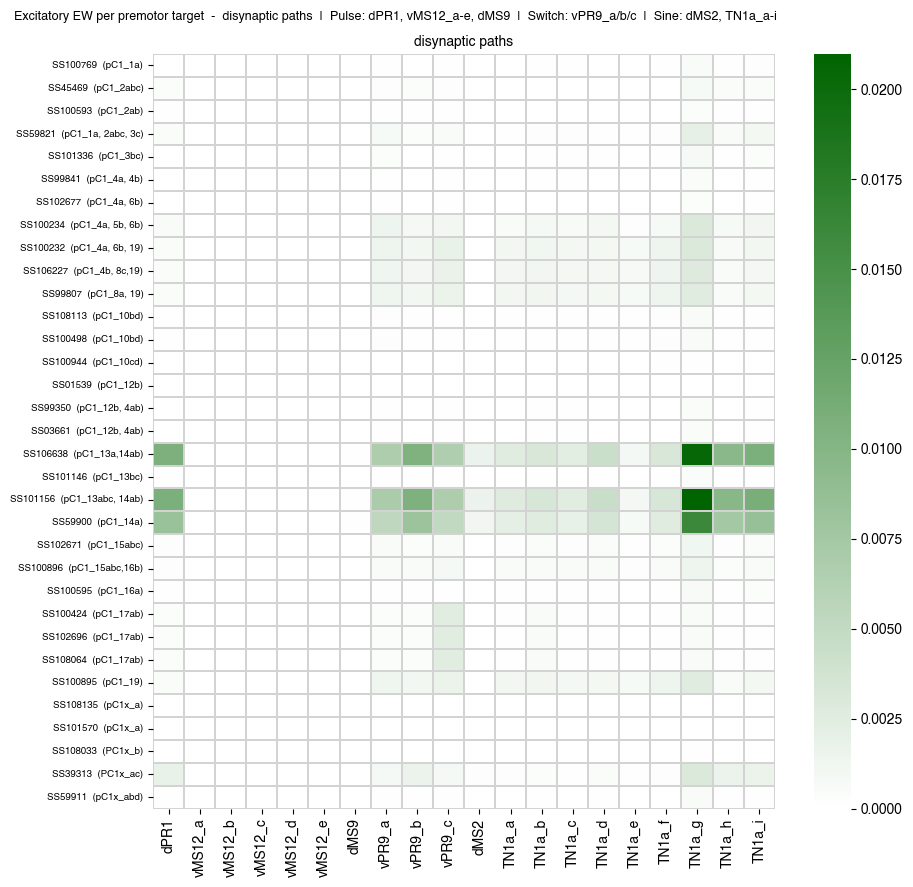

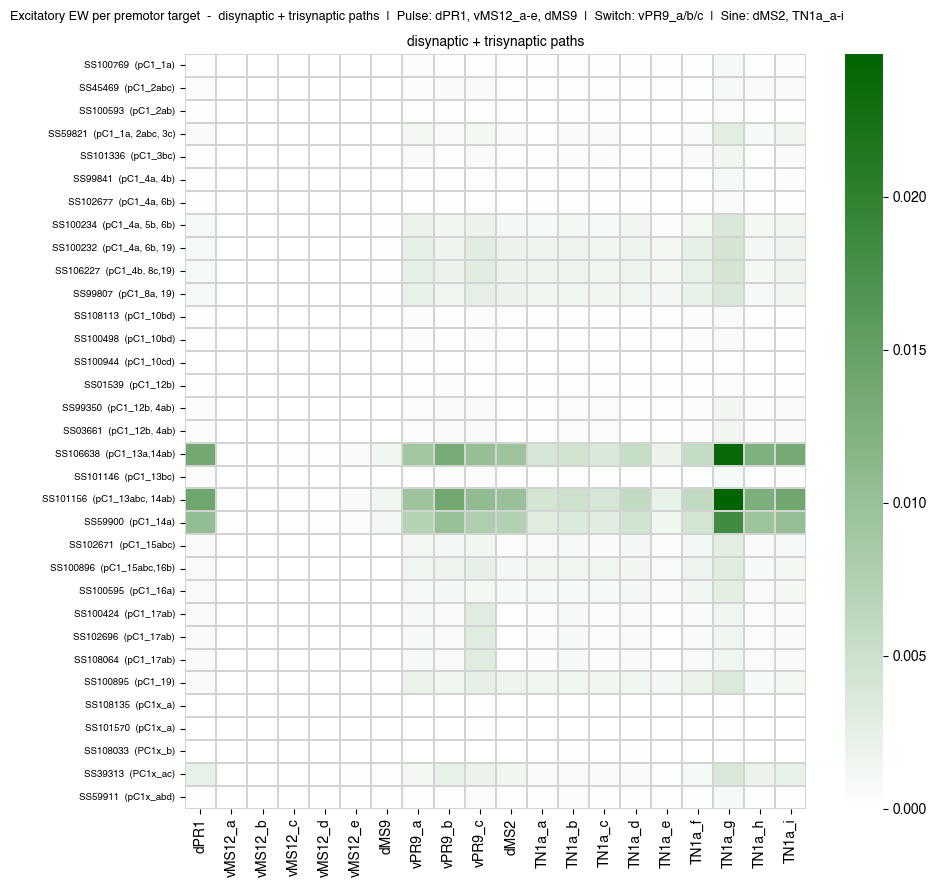

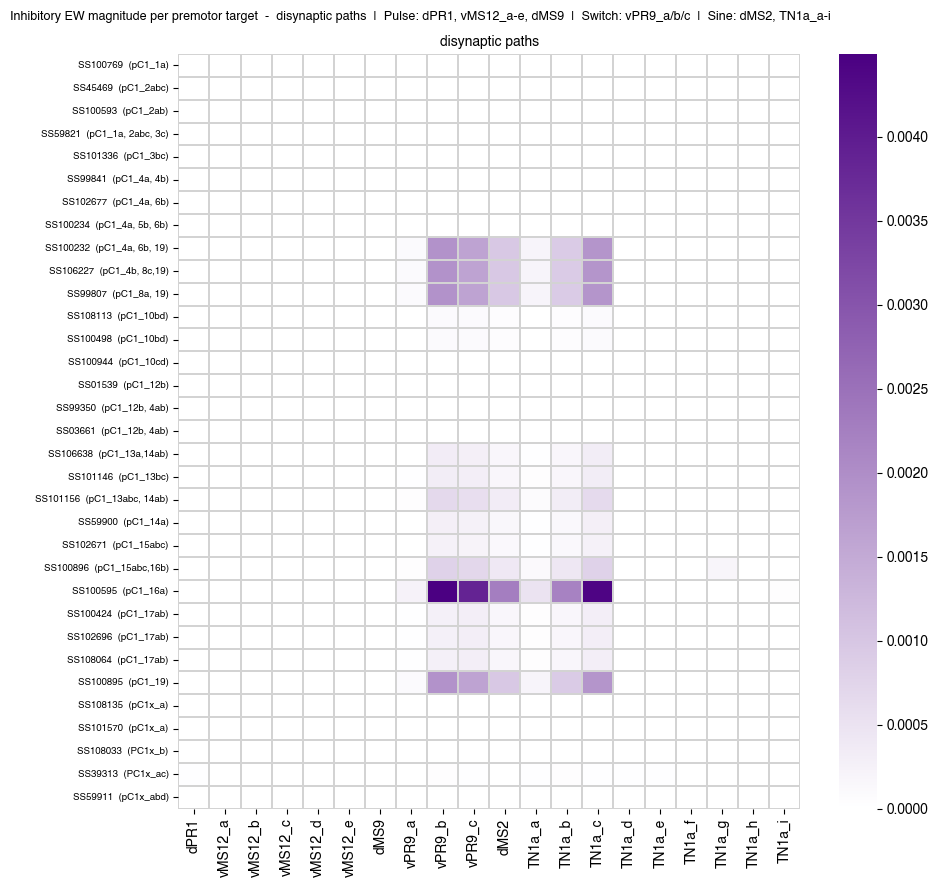

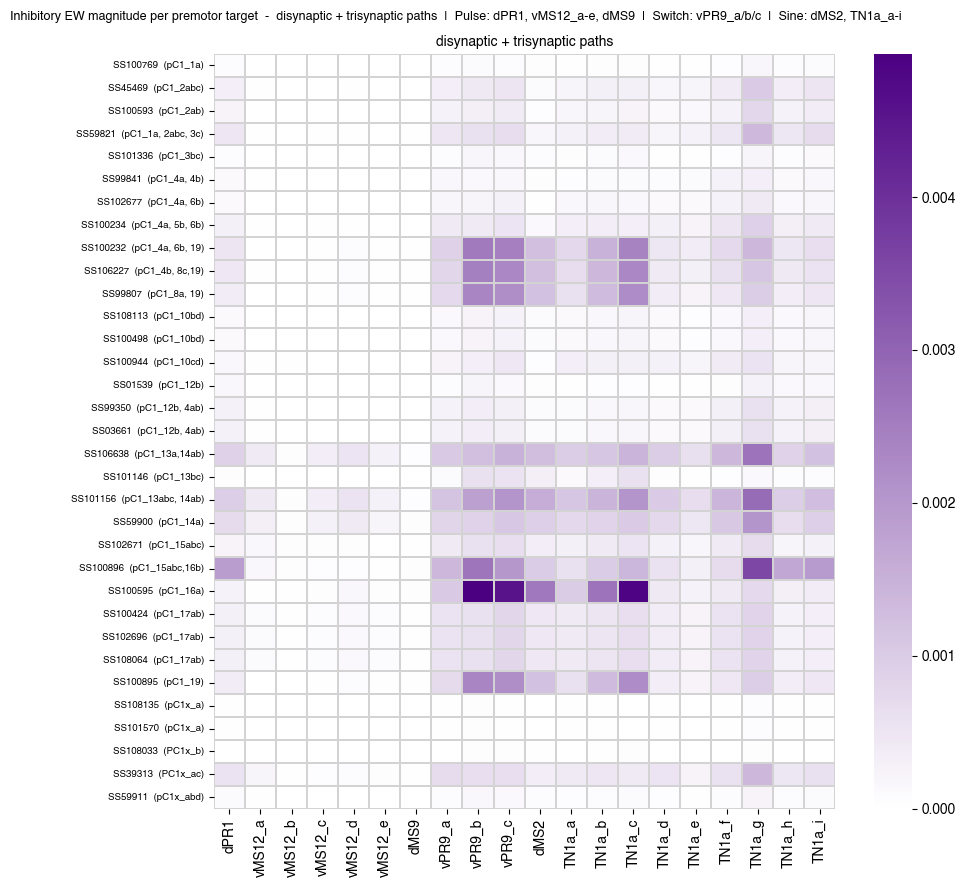

In [73]:
# ── Figures 7-10: Dedicated excitatory (green) and inhibitory (purple) heatmaps ─
# ── Custom colormaps for Section 7 heatmaps ─────────────────────────────
_hm_excit_cmap = LinearSegmentedColormap.from_list(
    'white_green', ['#ffffff', '#006400'], N=256)  # white → dark green
_hm_inhib_cmap = LinearSegmentedColormap.from_list(
    'white_purple', ['#ffffff', '#4b0082'], N=256)  # white → indigo/purple


def _single_heatmap(ss_ew_pt, col_prefix, cmap, ax, show_ylabels):
    cols = [f'{col_prefix}_{pm}' for pm in PREMOTOR_TARGETS]
    hm   = ss_ew_pt[cols].copy()
    hm.columns = PREMOTOR_TARGETS
    if col_prefix == 'neg_ew':
        hm = hm.abs()
    ylabels = (ss_ew_pt['LineName'] + '  (' + ss_ew_pt['CellType'].str[:22] + ')').tolist()
    sns.heatmap(hm, ax=ax, cmap=cmap, vmin=0, vmax=hm.values.max(),
                yticklabels=ylabels if show_ylabels else False,
                linewidths=0.3, linecolor='lightgray')
    if show_ylabels:
        ax.tick_params(axis='y', labelsize=7, rotation=0)
    ax.set_xlabel('')

_pm_lbl = 'Pulse: dPR1, vMS12_a-e, dMS9  |  Switch: vPR9_a/b/c  |  Sine: dMS2, TN1a_a-i'

for _col_prefix, _cmap, _label, _fname_2, _fname_comb in [
    ('pos_ew', _hm_excit_cmap, 'Excitatory EW per premotor target',
     'SS_line_x_premotor_excit_ew_2hop.pdf',
     'SS_line_x_premotor_excit_ew_combined.pdf'),
    ('neg_ew', _hm_inhib_cmap, 'Inhibitory EW magnitude per premotor target',
     'SS_line_x_premotor_inhib_ew_2hop.pdf',
     'SS_line_x_premotor_inhib_ew_combined.pdf'),
]:
    for _df_pt, _path_desc, _fname in [
        (ss_ew_pt_2hop,     'disynaptic paths',              _fname_2),
        (ss_ew_pt_combined, 'disynaptic + trisynaptic paths', _fname_comb),
    ]:
        fig, ax = plt.subplots(figsize=(11, 9))
        _single_heatmap(_df_pt, _col_prefix, _cmap, ax, show_ylabels=True)
        ax.set_title(_path_desc, fontsize=10)
        fig.suptitle(_label + '  -  ' + _path_desc + '  |  ' + _pm_lbl,
                     fontsize=9)
        fig.tight_layout()
        fig.subplots_adjust(left=0.28)
        fig.savefig(RESULTS_DIR / _fname, bbox_inches='tight')
        fig.savefig(RESULTS_DIR / _fname.replace('.pdf', '.svg'), bbox_inches='tight')
        plt.show()

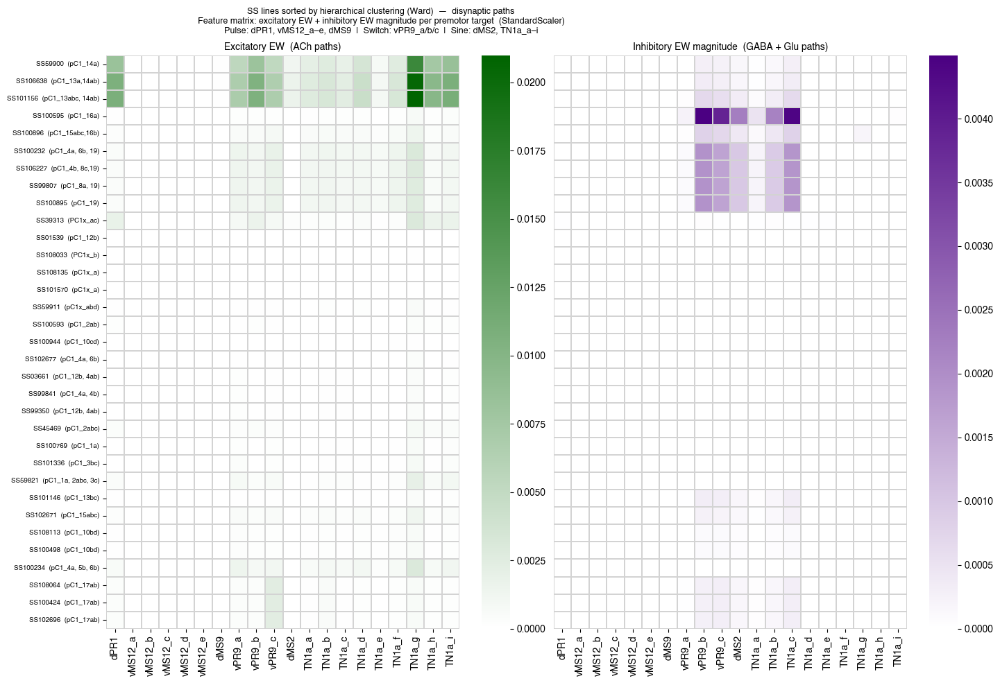

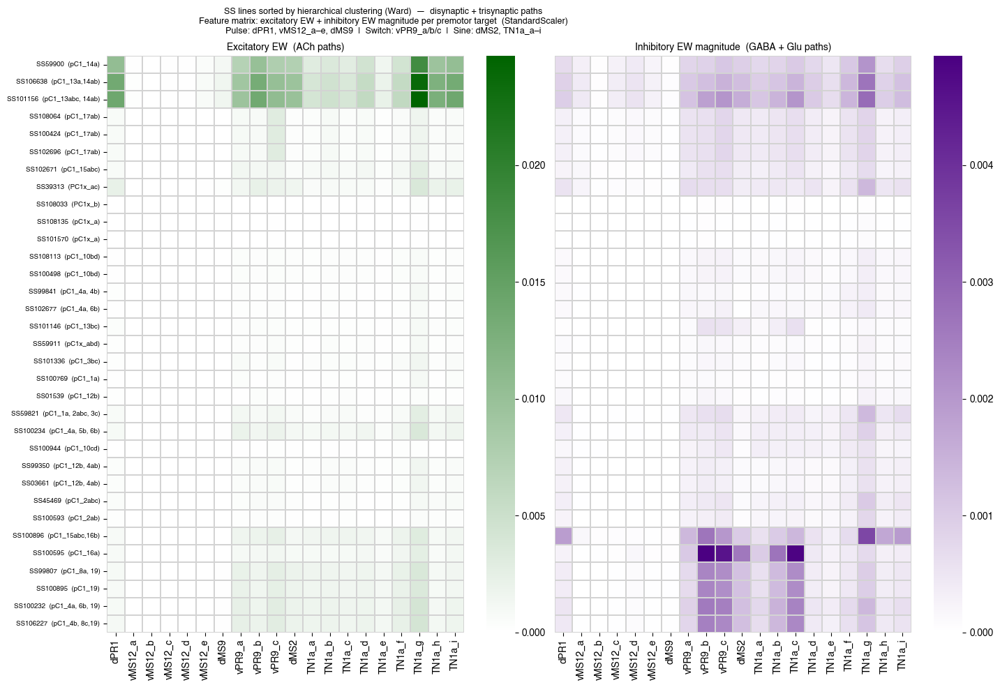

In [74]:
# ── Figure 7: Clustered side-by-side excitatory & inhibitory EW heatmaps ─────
# Feature matrix: pos_ew_{pm} columns (excitatory) stacked with |neg_ew_{pm}|
# (inhibitory magnitude), both from disynaptic paths (ss_ew_pt_2hop).
# Hierarchical clustering (Ward linkage) on StandardScaler-normalised features
# determines row order; the same order is applied to both heatmaps.

from scipy.cluster.hierarchy import linkage, leaves_list
from sklearn.preprocessing import StandardScaler as _SS7

_pos_cols_s7 = [f'pos_ew_{pm}' for pm in PREMOTOR_TARGETS]
_neg_cols_s7 = [f'neg_ew_{pm}' for pm in PREMOTOR_TARGETS]

# Combined feature matrix: excit + |inhib| per premotor target
_X_s7 = np.hstack([
    ss_ew_pt_2hop[_pos_cols_s7].values,
    ss_ew_pt_2hop[_neg_cols_s7].abs().values,
])
_X_s7_sc = _SS7().fit_transform(_X_s7)
_Z_s7    = linkage(_X_s7_sc, method='ward')
_row_ord = leaves_list(_Z_s7)   # row indices sorted by cluster order

# Reorder rows
_ss7 = ss_ew_pt_2hop.iloc[_row_ord].reset_index(drop=True)
_ylabels_s7 = (_ss7['LineName'] + '  (' + _ss7['CellType'].str[:22] + ')').tolist()

_hm_pos_s7 = pd.DataFrame(_ss7[_pos_cols_s7].values,       columns=PREMOTOR_TARGETS)
_hm_neg_s7 = pd.DataFrame(_ss7[_neg_cols_s7].abs().values,  columns=PREMOTOR_TARGETS)

_vmax_pos_s7 = _hm_pos_s7.values.max()
_vmax_neg_s7 = _hm_neg_s7.values.max()

fig7, (ax7e, ax7i) = plt.subplots(1, 2, figsize=(18, 10))

sns.heatmap(_hm_pos_s7, ax=ax7e,
            cmap=_hm_excit_cmap, vmin=0, vmax=_vmax_pos_s7,
            yticklabels=_ylabels_s7, linewidths=0.3, linecolor='lightgray')
ax7e.tick_params(axis='y', labelsize=7, rotation=0)
ax7e.set_title('Excitatory EW  (ACh paths)', fontsize=10)
ax7e.set_xlabel('')

sns.heatmap(_hm_neg_s7, ax=ax7i,
            cmap=_hm_inhib_cmap, vmin=0, vmax=_vmax_neg_s7,
            yticklabels=False, linewidths=0.3, linecolor='lightgray')
ax7i.set_title('Inhibitory EW magnitude  (GABA + Glu paths)', fontsize=10)
ax7i.set_xlabel('')

fig7.suptitle(
    'SS lines sorted by hierarchical clustering (Ward)  —  disynaptic paths\n'
    'Feature matrix: excitatory EW + inhibitory EW magnitude per premotor target  '
    '(StandardScaler)\n'
    'Pulse: dPR1, vMS12_a\u2013e, dMS9  |  Switch: vPR9_a/b/c  |  '
    'Sine: dMS2, TN1a_a\u2013i',
    fontsize=9)
fig7.tight_layout()
fig7.subplots_adjust(left=0.28)
matplotlib.rcParams['svg.fonttype'] = 'none'
fig7.savefig(RESULTS_DIR / 'SS_line_x_premotor_clustered_ei.pdf', bbox_inches='tight')
fig7.savefig(RESULTS_DIR / 'SS_line_x_premotor_clustered_ei.svg', bbox_inches='tight')
plt.show()

# ── Figure 8: Same clustering applied to combined di+trisynaptic paths ────────
_X_s7c = np.hstack([
    ss_ew_pt_combined[_pos_cols_s7].values,
    ss_ew_pt_combined[_neg_cols_s7].abs().values,
])
_X_s7c_sc = _SS7().fit_transform(_X_s7c)
_Z_s7c    = linkage(_X_s7c_sc, method='ward')
_row_ord_c = leaves_list(_Z_s7c)

_ss7c = ss_ew_pt_combined.iloc[_row_ord_c].reset_index(drop=True)
_ylabels_s7c = (_ss7c['LineName'] + '  (' + _ss7c['CellType'].str[:22] + ')').tolist()

_hm_pos_s7c = pd.DataFrame(_ss7c[_pos_cols_s7].values,      columns=PREMOTOR_TARGETS)
_hm_neg_s7c = pd.DataFrame(_ss7c[_neg_cols_s7].abs().values, columns=PREMOTOR_TARGETS)

fig8, (ax8e, ax8i) = plt.subplots(1, 2, figsize=(18, 10))

sns.heatmap(_hm_pos_s7c, ax=ax8e,
            cmap=_hm_excit_cmap, vmin=0, vmax=_hm_pos_s7c.values.max(),
            yticklabels=_ylabels_s7c, linewidths=0.3, linecolor='lightgray')
ax8e.tick_params(axis='y', labelsize=7, rotation=0)
ax8e.set_title('Excitatory EW  (ACh paths)', fontsize=10)
ax8e.set_xlabel('')

sns.heatmap(_hm_neg_s7c, ax=ax8i,
            cmap=_hm_inhib_cmap, vmin=0, vmax=_hm_neg_s7c.values.max(),
            yticklabels=False, linewidths=0.3, linecolor='lightgray')
ax8i.set_title('Inhibitory EW magnitude  (GABA + Glu paths)', fontsize=10)
ax8i.set_xlabel('')

fig8.suptitle(
    'SS lines sorted by hierarchical clustering (Ward)  \u2014  disynaptic + trisynaptic paths\n'
    'Feature matrix: excitatory EW + inhibitory EW magnitude per premotor target  '
    '(StandardScaler)\n'
    'Pulse: dPR1, vMS12_a\u2013e, dMS9  |  Switch: vPR9_a/b/c  |  '
    'Sine: dMS2, TN1a_a\u2013i',
    fontsize=9)
fig8.tight_layout()
fig8.subplots_adjust(left=0.28)
fig8.savefig(RESULTS_DIR / 'SS_line_x_premotor_clustered_ei_combined.pdf', bbox_inches='tight')
fig8.savefig(RESULTS_DIR / 'SS_line_x_premotor_clustered_ei_combined.svg', bbox_inches='tight')
plt.show()


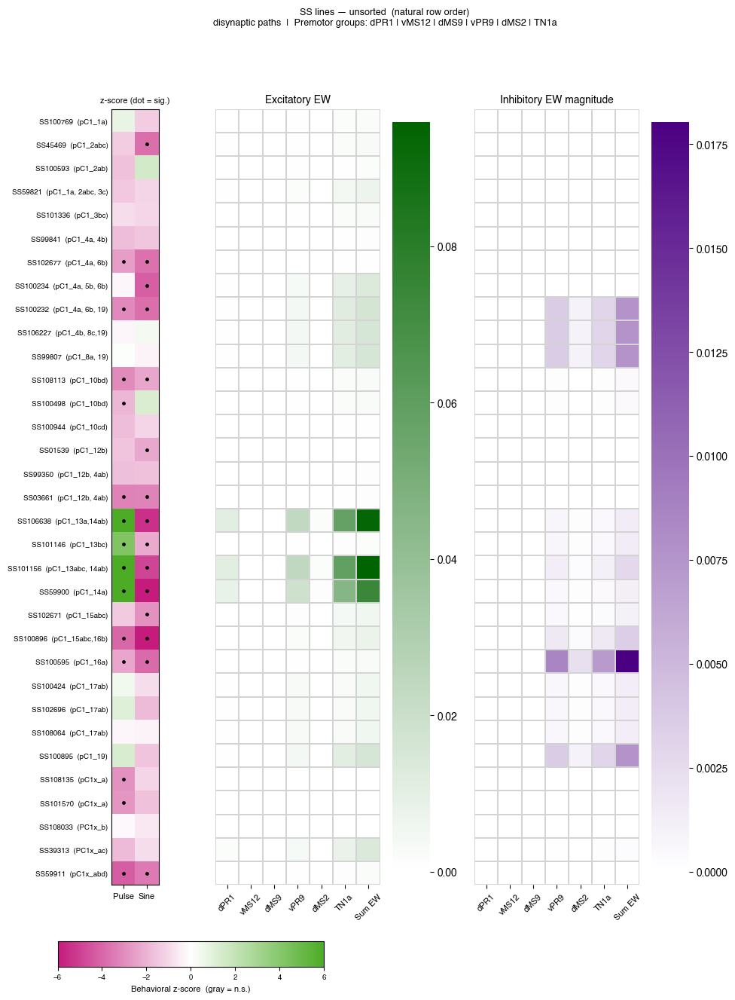

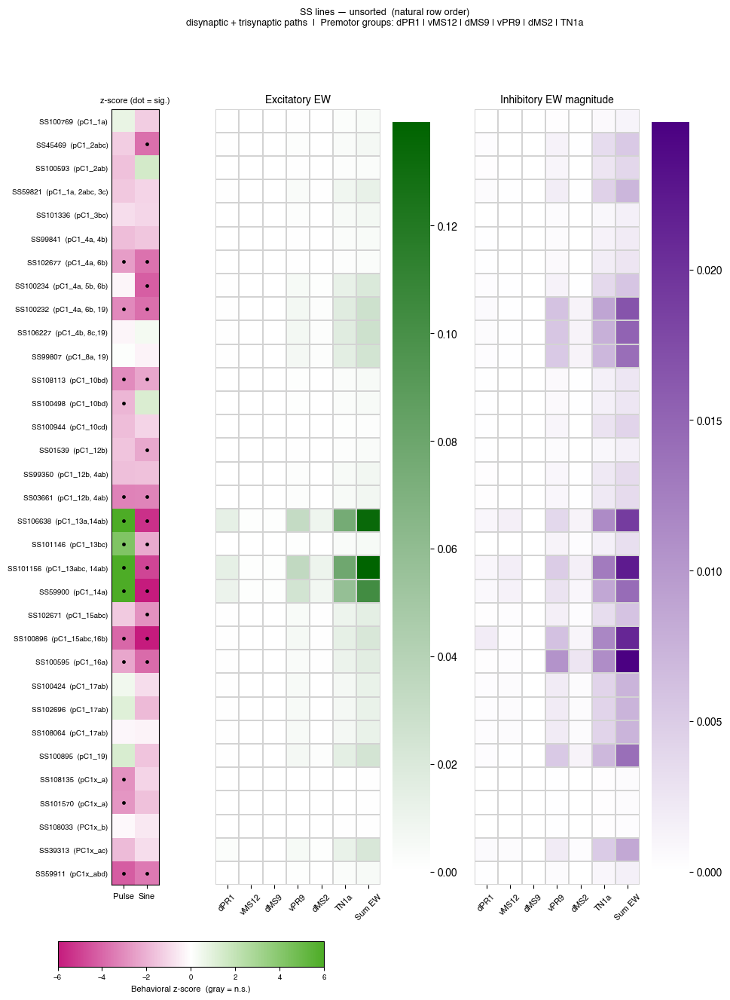

In [75]:
# ── Figures 9-10: Lines sorted by behavioral clustering × 6 premotor groups ──
# Cluster SS lines by pulse & sine z-scores + p-values (Ward hierarchical).
# Apply the same row order to excitatory (white→green) and inhibitory
# (white→purple) EW heatmaps aggregated across the 6 canonical premotor types.
# Two figures: disynaptic paths only, and disynaptic + trisynaptic combined.

from scipy.cluster.hierarchy import linkage as _lnk9, leaves_list as _ll9
from sklearn.preprocessing import StandardScaler as _SS9

# ── Premotor groups (19 subtypes → 6 canonical types) ─────────────────
# Adapt to whether PREMOTOR_TARGETS uses grouped or subtype names
if 'vMS12' in PREMOTOR_TARGETS:
    # Grouped notebooks: columns already at group level
    _PM_GROUPS9 = {pm: [pm] for pm in PREMOTOR_TARGETS}
else:
    # Subtype notebooks: aggregate 19 subtypes into 6 groups
    _PM_GROUPS9 = {
        'dPR1':  ['dPR1'],
        'vMS12': ['vMS12_a', 'vMS12_b', 'vMS12_c', 'vMS12_d', 'vMS12_e'],
        'dMS9':  ['dMS9'],
        'vPR9':  ['vPR9_a', 'vPR9_b', 'vPR9_c'],
        'dMS2':  ['dMS2'],
        'TN1a':  [f'TN1a_{s}' for s in 'abcdefghi'],
    }
_GRP_NAMES9 = list(_PM_GROUPS9.keys())

# ── Toggle: set False to skip behavioural clustering and keep natural row order
SORT_BY_BEH9 = False

def _agg_excit9(df_pt):
    return pd.DataFrame({
        g: df_pt[[f'pos_ew_{m}' for m in mems]].sum(axis=1).values
        for g, mems in _PM_GROUPS9.items()
    }, columns=_GRP_NAMES9)

def _agg_inhib9(df_pt):
    return pd.DataFrame({
        g: df_pt[[f'neg_ew_{m}' for m in mems]].abs().sum(axis=1).values
        for g, mems in _PM_GROUPS9.items()
    }, columns=_GRP_NAMES9)

# ── Behavioral clustering (activation z-scores + p-values) ────────────────
_beh9 = ss_ew_pt_2hop.merge(
    beh[['LineName', 'Pulse_Transient', 'Sine_Transient',
         'Pulse_pval_Transient', 'Sine_pval_Transient']],
    on='LineName', how='left')

_bfeat9   = _beh9[['Pulse_Transient', 'Sine_Transient',
                   'Pulse_pval_Transient', 'Sine_pval_Transient']].fillna(0.).values
_Z9       = _lnk9(_SS9().fit_transform(_bfeat9), method='ward')
_row_ord9 = _ll9(_Z9)   # same index array applied to both 2-hop and combined

# ── Sorted tables ─────────────────────────────────────────────
_sorted_lines9 = _beh9.iloc[_row_ord9]['LineName'].tolist()
_beh9_s = _beh9.iloc[_row_ord9].reset_index(drop=True)
_2hop_s = ss_ew_pt_2hop.set_index('LineName').loc[_sorted_lines9].reset_index()
_comb_s = ss_ew_pt_combined.set_index('LineName').loc[_sorted_lines9].reset_index()

_ylabels9 = (
    _beh9_s['LineName'] + '  (' + _beh9_s['CellType'].str[:22] + ')'
).tolist()

# ── Behavioral color strip ────────────────────────────────────────
_bwr9  = mcolors.LinearSegmentedColormap.from_list(
    'piyg9', ['#c51b7d', '#ffffff', '#4dac26'])
_vmx9  = 6.
_norm9 = mcolors.TwoSlopeNorm(vmin=-_vmx9, vcenter=0., vmax=_vmx9)
_psig9 = (_beh9_s['Pulse_pval_Transient'].abs() < 0.05).values
_ssig9 = (_beh9_s['Sine_pval_Transient'].abs()  < 0.05).values
_GRAY9 = np.array(mcolors.to_rgba('#cccccc'))

def _beh_col9(z_vals):
    return np.array([_bwr9(_norm9(float(v))) for v in z_vals])

# shape (n_lines, 2, 4): axis-1 col 0 = pulse, col 1 = sine
_strip9 = np.stack([
    _beh_col9(_beh9_s['Pulse_Transient'].values),
    _beh_col9(_beh9_s['Sine_Transient'].values),
], axis=1)

# ── Drawing function ─────────────────────────────────────────────────
def _draw_beh9(df_sorted, path_lbl, fname, sort_beh=True):
    # ── Row labels / behavioral strip: recompute if not sorting ──────────
    if sort_beh:
        _ylbls_l = _ylabels9
        _psig_l  = _psig9
        _ssig_l  = _ssig9
        _strip_l = _strip9
    else:
        _beh_ord9 = _beh9.set_index('LineName').loc[
            df_sorted['LineName'].tolist()].reset_index()
        _ylbls_l = (_beh_ord9['LineName'] + '  (' +
                    _beh_ord9['CellType'].str[:22] + ')').tolist()
        _psig_l  = (_beh_ord9['Pulse_pval_Transient'].abs() < 0.05).values
        _ssig_l  = (_beh_ord9['Sine_pval_Transient'].abs()  < 0.05).values
        _strip_l = np.stack([
            _beh_col9(_beh_ord9['Pulse_Transient'].values),
            _beh_col9(_beh_ord9['Sine_Transient'].values),
        ], axis=1)

    _he  = _agg_excit9(df_sorted)
    _hi  = _agg_inhib9(df_sorted)
    # Append sum-across-6-premotor-groups column (before vmax so scale includes it)
    _he['Sum EW'] = _he[_GRP_NAMES9].sum(axis=1)
    _hi['Sum EW'] = _hi[_GRP_NAMES9].sum(axis=1)
    _vme = float(_he.values.max()) if _he.values.max() > 0 else 1.
    _vmi = float(_hi.values.max()) if _hi.values.max() > 0 else 1.

    # Square cells: derive figsize from row/column counts
    _n9      = len(df_sorted)
    _nhm9    = len(_he.columns)   # 7 (6 PM groups + Sum EW)
    _nstrip9 = 2                  # Pulse | Sine
    _cs9     = 0.35               # cell size in inches
    _fw9     = (_nstrip9 + 2 * _nhm9) * _cs9 + 4.5
    _fh9     = _n9 * _cs9 + 2.0

    _fig9, (_ax_b9, _ax_e9, _ax_i9) = plt.subplots(
        1, 3,
        figsize=(_fw9, _fh9),
        gridspec_kw={'width_ratios': [_nstrip9, _nhm9, _nhm9], 'wspace': 0.05})

    # Behavioral strip (pulse | sine z-score, BWR; black dot = significant)
    _ax_b9.imshow(_strip_l, aspect='equal', interpolation='nearest')
    # Overlay black dots on significant entries
    for _col_i9, _sm_mask9 in enumerate([_psig_l, _ssig_l]):
        _sig_rows9 = np.where(_sm_mask9)[0]
        _ax_b9.scatter([_col_i9] * len(_sig_rows9), _sig_rows9,
                       c='black', s=12, zorder=5, linewidths=0)
    _ax_b9.set_xticks([0, 1])
    _ax_b9.set_xticklabels(['Pulse', 'Sine'], fontsize=8)
    _ax_b9.set_yticks(range(len(_ylbls_l)))
    _ax_b9.set_yticklabels(_ylbls_l, fontsize=7)
    _ax_b9.tick_params(axis='y', length=0)
    _ax_b9.set_title('z-score (dot = sig.)', fontsize=8)

    # Excitatory heatmap
    sns.heatmap(_he, ax=_ax_e9, cmap=_hm_excit_cmap,
                vmin=0, vmax=_vme, yticklabels=False,
                linewidths=0.3, linecolor='lightgray', square=True)
    _ax_e9.set_title('Excitatory EW', fontsize=10)
    _ax_e9.set_xlabel('')
    _ax_e9.tick_params(axis='x', labelsize=8, rotation=45)

    # Inhibitory heatmap
    sns.heatmap(_hi, ax=_ax_i9, cmap=_hm_inhib_cmap,
                vmin=0, vmax=_vmi, yticklabels=False,
                linewidths=0.3, linecolor='lightgray', square=True)
    _ax_i9.set_title('Inhibitory EW magnitude', fontsize=10)
    _ax_i9.set_xlabel('')
    _ax_i9.tick_params(axis='x', labelsize=8, rotation=45)

    _sort_desc9 = (
        'sorted by behavioural clustering  (Ward: pulse & sine z-scores + p-values)'
        if sort_beh else 'unsorted  (natural row order)')
    _fig9.suptitle(
        f'SS lines — {_sort_desc9}\n'
        + path_lbl + '  |  '
        'Premotor groups: dPR1 | vMS12 | dMS9 | vPR9 | dMS2 | TN1a',
        fontsize=9)

    # Horizontal colorbar for z-score strip
    _fig9.subplots_adjust(bottom=0.12)
    _sm_cb9 = plt.cm.ScalarMappable(cmap=_bwr9, norm=_norm9)
    _sm_cb9.set_array([])
    _cbar_ax9 = _fig9.add_axes([0.07, 0.04, 0.35, 0.025])
    _cbar9 = _fig9.colorbar(_sm_cb9, cax=_cbar_ax9, orientation='horizontal')
    _cbar9.set_label('Behavioral z-score  (gray = n.s.)', fontsize=8)
    _cbar9.ax.tick_params(labelsize=7)

    matplotlib.rcParams['svg.fonttype'] = 'none'
    _fname9 = fname if sort_beh else f'{fname}_unsorted'
    _fig9.savefig(RESULTS_DIR / f'{_fname9}.pdf', bbox_inches='tight')
    _fig9.savefig(RESULTS_DIR / f'{_fname9}.svg', bbox_inches='tight')
    plt.show()

_draw_beh9(_2hop_s if SORT_BY_BEH9 else ss_ew_pt_2hop,
           'disynaptic paths',
           'SS_line_x_pmgroups_beh_sorted_2hop',
           sort_beh=SORT_BY_BEH9)
_draw_beh9(_comb_s if SORT_BY_BEH9 else ss_ew_pt_combined,
           'disynaptic + trisynaptic paths',
           'SS_line_x_pmgroups_beh_sorted_combined',
           sort_beh=SORT_BY_BEH9)


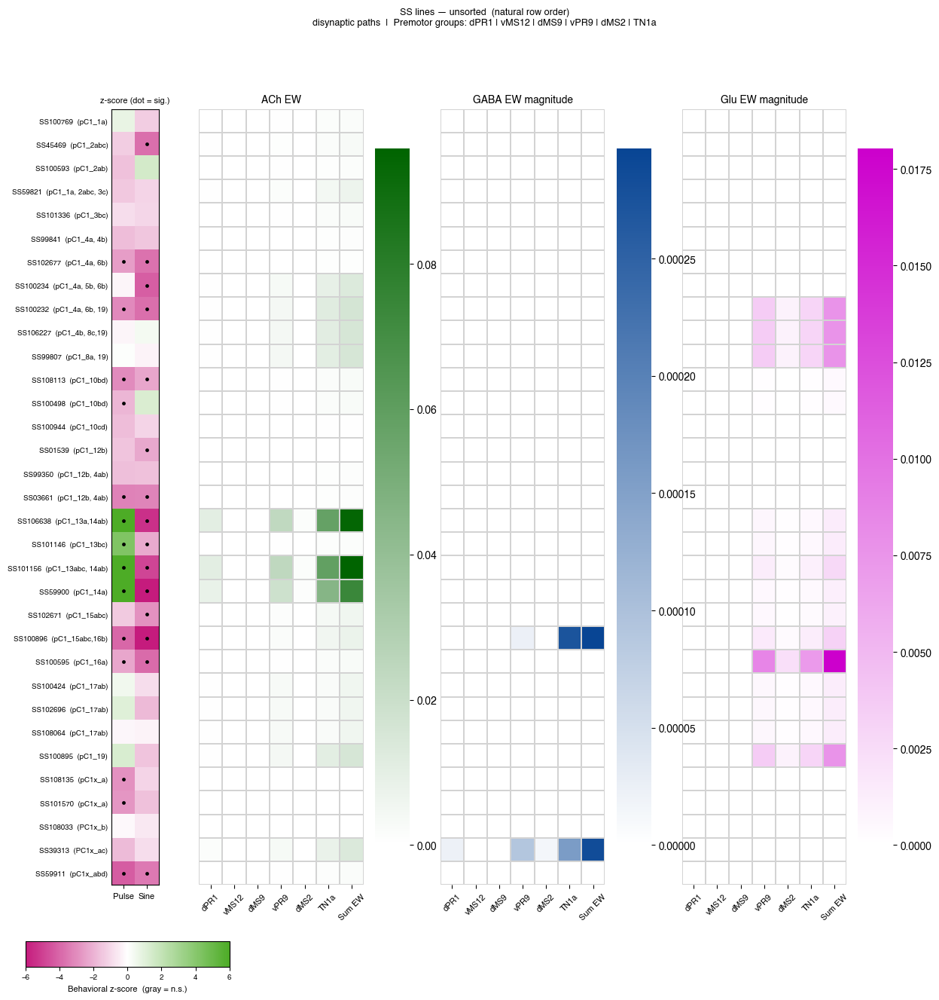

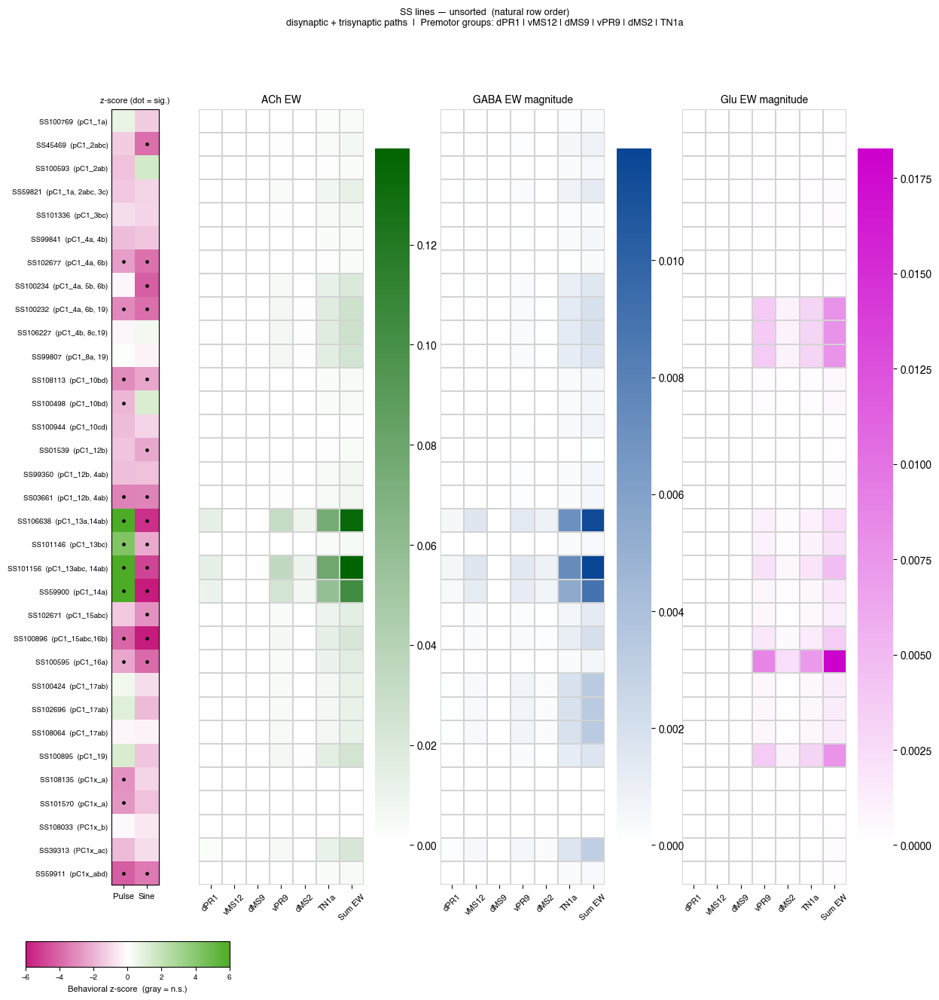

In [76]:
# ── Figures 9b-10b: per-NT EW heatmaps (ACh / GABA / Glu) × premotor groups ─
# Same layout as Figs 9-10; 3 EW panels instead of 2.
# ACh white→green  |  GABA white→blue  |  Glu white→magenta
# Row order controlled by the same SORT_BY_BEH9 flag defined in the cell above.

from matplotlib.colors import LinearSegmentedColormap as _LSC9b

_hm_gaba_cmap9b = _LSC9b.from_list('w_blue',   ['#ffffff', '#084594'], N=256)
_hm_glu_cmap9b  = _LSC9b.from_list('w_magenta', ['#ffffff', '#cc00cc'], N=256)

# ── Build per-NT per-premotor-target EW — disynaptic paths ───────────────────
_gaba_pm_2h = (
    merged_all[merged_all['inter_nt'] == 'gaba']
    .groupby(['src_type', 'premotor_type'])['path_ew'].sum()
    .to_dict()
)
_glu_pm_2h = (
    merged_all[merged_all['inter_nt'] == 'glutamate']
    .groupby(['src_type', 'premotor_type'])['path_ew'].sum()
    .to_dict()
)

# ── Add trisynaptic component (classified by inter2 NT) ──────────────────────
_gaba_pm_3h = {}
_glu_pm_3h  = {}
if 'merged_3a' in vars():
    _int2_nt_9b = merged_3a['inter2_type'].map(type_to_nt).fillna('other')
    _gaba_pm_3h = (
        merged_3a[(merged_3a['signed_path_ew'] < 0) & (_int2_nt_9b == 'gaba')]
        .groupby(['src_type', 'premotor_type'])['path_ew'].sum()
        .to_dict()
    )
    _glu_pm_3h = (
        merged_3a[(merged_3a['signed_path_ew'] < 0) & (_int2_nt_9b == 'glutamate')]
        .groupby(['src_type', 'premotor_type'])['path_ew'].sum()
        .to_dict()
    )

# ── Per-SS-line DataFrames: gaba_ew_{pm}, glu_ew_{pm} ────────────────────────
def _build_nt_df9b(gaba2, gaba3, glu2, glu3):
    rows = []
    for _, row in beh.iterrows():
        types = parse_pC1_types(str(row['CellType']))
        if not types:
            continue
        entry = {'LineName': row['LineName']}
        for pm_grp, pm_subs in PREMOTOR_GROUPS.items():
            entry[f'gaba_ew_{pm_grp}'] = sum(
                gaba2.get((t, sub), 0.) + gaba3.get((t, sub), 0.) for t in types for sub in pm_subs)
            entry[f'glu_ew_{pm_grp}']  = sum(
                glu2.get((t, sub),  0.) + glu3.get((t, sub),  0.) for t in types for sub in pm_subs)
        rows.append(entry)
    return pd.DataFrame(rows)

_nt_df_2h  = _build_nt_df9b(_gaba_pm_2h, {},          _glu_pm_2h, {})
_nt_df_cmb = _build_nt_df9b(_gaba_pm_2h, _gaba_pm_3h, _glu_pm_2h, _glu_pm_3h)

# Merge NT columns onto the EW-per-premotor tables; build sorted variants
_nt_2h_full    = ss_ew_pt_2hop.merge(_nt_df_2h,  on='LineName')
_nt_cmb_full   = ss_ew_pt_combined.merge(_nt_df_cmb, on='LineName')
_nt_2h_sorted  = _nt_2h_full.set_index('LineName').loc[_sorted_lines9].reset_index()
_nt_cmb_sorted = _nt_cmb_full.set_index('LineName').loc[_sorted_lines9].reset_index()

# ── Aggregation: per-premotor-group NT EW ────────────────────────────────────
def _agg_ach9b(df):
    return pd.DataFrame({
        g: df[[f'pos_ew_{m}'  for m in mems]].sum(axis=1).values
        for g, mems in _PM_GROUPS9.items()
    }, columns=_GRP_NAMES9)

def _agg_gaba9b(df):
    return pd.DataFrame({
        g: df[[f'gaba_ew_{m}' for m in mems]].abs().sum(axis=1).values
        for g, mems in _PM_GROUPS9.items()
    }, columns=_GRP_NAMES9)

def _agg_glu9b(df):
    return pd.DataFrame({
        g: df[[f'glu_ew_{m}'  for m in mems]].abs().sum(axis=1).values
        for g, mems in _PM_GROUPS9.items()
    }, columns=_GRP_NAMES9)

# ── Drawing function ──────────────────────────────────────────────────────────
def _draw_nt9b(df_full, path_lbl, fname, sort_beh=True):
    _hach  = _agg_ach9b(df_full)
    _hgaba = _agg_gaba9b(df_full)
    _hglu  = _agg_glu9b(df_full)

    _hach['Sum EW']  = _hach[_GRP_NAMES9].sum(axis=1)
    _hgaba['Sum EW'] = _hgaba[_GRP_NAMES9].sum(axis=1)
    _hglu['Sum EW']  = _hglu[_GRP_NAMES9].sum(axis=1)

    _vach  = float(_hach.values.max())  if _hach.values.max()  > 0 else 1.
    _vgaba = float(_hgaba.values.max()) if _hgaba.values.max() > 0 else 1.
    _vglu  = float(_hglu.values.max())  if _hglu.values.max()  > 0 else 1.

    # ── Row labels / strip ────────────────────────────────────────────────
    if sort_beh:
        _ylbls_l = _ylabels9
        _psig_l  = _psig9
        _ssig_l  = _ssig9
        _strip_l = _strip9
    else:
        _beh_o = _beh9.set_index('LineName').loc[
            df_full['LineName'].tolist()].reset_index()
        _ylbls_l = (_beh_o['LineName'] + '  (' +
                    _beh_o['CellType'].str[:22] + ')').tolist()
        _psig_l  = (_beh_o['Pulse_pval_Transient'].abs() < 0.05).values
        _ssig_l  = (_beh_o['Sine_pval_Transient'].abs()  < 0.05).values
        _strip_l = np.stack([
            _beh_col9(_beh_o['Pulse_Transient'].values),
            _beh_col9(_beh_o['Sine_Transient'].values),
        ], axis=1)

    # ── Figure layout (square cells, 4 panels) ────────────────────────────
    _n9      = len(df_full)
    _nhm9    = len(_hach.columns)   # 7 (6 PM groups + Sum EW)
    _nstrip9 = 2
    _cs9     = 0.35                 # cell size in inches — matches Figs 9-10
    _fw9     = (_nstrip9 + 3 * _nhm9) * _cs9 + 5.5
    _fh9     = _n9 * _cs9 + 2.0

    _fig9b, (_ax_b, _ax_a, _ax_g, _ax_l) = plt.subplots(
        1, 4,
        figsize=(_fw9, _fh9),
        gridspec_kw={'width_ratios': [_nstrip9, _nhm9, _nhm9, _nhm9], 'wspace': 0.05})

    # Behavioral strip
    _ax_b.imshow(_strip_l, aspect='equal', interpolation='nearest')
    for _ci9b, _mk9b in enumerate([_psig_l, _ssig_l]):
        _sr9b = np.where(_mk9b)[0]
        _ax_b.scatter([_ci9b] * len(_sr9b), _sr9b,
                      c='black', s=12, zorder=5, linewidths=0)
    _ax_b.set_xticks([0, 1])
    _ax_b.set_xticklabels(['Pulse', 'Sine'], fontsize=8)
    _ax_b.set_yticks(range(len(_ylbls_l)))
    _ax_b.set_yticklabels(_ylbls_l, fontsize=7)
    _ax_b.tick_params(axis='y', length=0)
    _ax_b.set_title('z-score (dot = sig.)', fontsize=8)

    # ACh heatmap (white → green)
    sns.heatmap(_hach, ax=_ax_a, cmap=_hm_excit_cmap,
                vmin=0, vmax=_vach, yticklabels=False,
                linewidths=0.3, linecolor='lightgray', square=True)
    _ax_a.set_title('ACh EW', fontsize=10)
    _ax_a.set_xlabel('')
    _ax_a.tick_params(axis='x', labelsize=8, rotation=45)

    # GABA heatmap (white → blue)
    sns.heatmap(_hgaba, ax=_ax_g, cmap=_hm_gaba_cmap9b,
                vmin=0, vmax=_vgaba, yticklabels=False,
                linewidths=0.3, linecolor='lightgray', square=True)
    _ax_g.set_title('GABA EW magnitude', fontsize=10)
    _ax_g.set_xlabel('')
    _ax_g.tick_params(axis='x', labelsize=8, rotation=45)

    # Glu heatmap (white → magenta)
    sns.heatmap(_hglu, ax=_ax_l, cmap=_hm_glu_cmap9b,
                vmin=0, vmax=_vglu, yticklabels=False,
                linewidths=0.3, linecolor='lightgray', square=True)
    _ax_l.set_title('Glu EW magnitude', fontsize=10)
    _ax_l.set_xlabel('')
    _ax_l.tick_params(axis='x', labelsize=8, rotation=45)

    _sort_desc9b = (
        'sorted by behavioural clustering  (Ward: pulse & sine z-scores + p-values)'
        if sort_beh else 'unsorted  (natural row order)')
    _fig9b.suptitle(
        f'SS lines — {_sort_desc9b}\n'
        + path_lbl + '  |  '
        'Premotor groups: dPR1 | vMS12 | dMS9 | vPR9 | dMS2 | TN1a',
        fontsize=9)

    _fig9b.subplots_adjust(bottom=0.12)
    _sm_cb9b = plt.cm.ScalarMappable(cmap=_bwr9, norm=_norm9)
    _sm_cb9b.set_array([])
    _cbar_ax9b = _fig9b.add_axes([0.05, 0.04, 0.20, 0.025])
    _cbar9b = _fig9b.colorbar(_sm_cb9b, cax=_cbar_ax9b, orientation='horizontal')
    _cbar9b.set_label('Behavioral z-score  (gray = n.s.)', fontsize=8)
    _cbar9b.ax.tick_params(labelsize=7)

    matplotlib.rcParams['svg.fonttype'] = 'none'
    _fname9b = fname if sort_beh else f'{fname}_unsorted'
    _fig9b.savefig(RESULTS_DIR / f'{_fname9b}.pdf', bbox_inches='tight')
    _fig9b.savefig(RESULTS_DIR / f'{_fname9b}.svg', bbox_inches='tight')
    plt.show()

_draw_nt9b(_nt_2h_sorted  if SORT_BY_BEH9 else _nt_2h_full,
           'disynaptic paths',
           'SS_line_x_pmgroups_nt_2hop',
           sort_beh=SORT_BY_BEH9)
_draw_nt9b(_nt_cmb_sorted if SORT_BY_BEH9 else _nt_cmb_full,
           'disynaptic + trisynaptic paths',
           'SS_line_x_pmgroups_nt_combined',
           sort_beh=SORT_BY_BEH9)


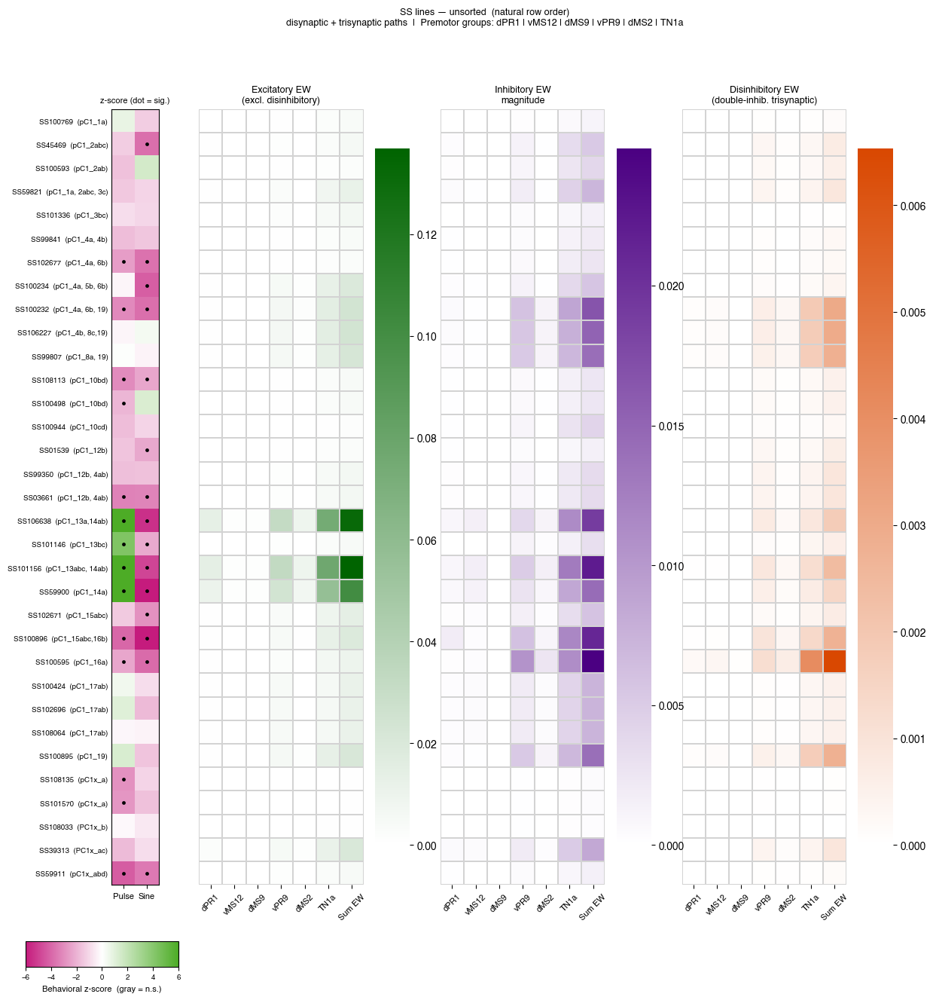

In [77]:
# ── Figure 10c: Excit / Inhib / Disinhibitory EW heatmaps — combined paths ───
# Like Figs 9-10 but with a 3rd bin: disinhibitory (double-inhibitory trisynaptic).
# - Excitatory: disynaptic + non-disinhibitory trisynaptic (net signed_path_ew > 0)
# - Inhibitory: all combined paths |neg EW| — unchanged from Fig 10
# - Disinhibitory: trisynaptic where inter1_sign < 0 AND inter2_sign < 0

from matplotlib.colors import LinearSegmentedColormap as _LSCdc

_hm_disinhib_cmap = _LSCdc.from_list(
    'w_orange', ['#ffffff', '#d94801'], N=256)   # white → orange

# ── Split trisynaptic paths into disinhibitory vs. non-disinhibitory ─────────
_3a_dis_dc   = merged_3a[(merged_3a['inter1_sign'] < 0) & (merged_3a['inter2_sign'] < 0)]
_3a_nodis_dc = merged_3a[~((merged_3a['inter1_sign'] < 0) & (merged_3a['inter2_sign'] < 0))]

# ── Build per-SS-line EW table (excit + inhib) without disinhibitory paths ───
_comb_nodis_dc = pd.concat([
    merged_all[['src_type', 'premotor_type', 'signed_path_ew']],
    _3a_nodis_dc[['src_type', 'premotor_type', 'signed_path_ew']],
], ignore_index=True)
_ss_nodis_dc = build_ss_ew_pt(_comb_nodis_dc)   # pos_ew_* and neg_ew_*

# ── Disinhibitory EW per SS line per premotor target ─────────────────────────
_dis_dict_dc = (
    _3a_dis_dc
    .groupby(['src_type', 'premotor_type'])['signed_path_ew']
    .sum().to_dict()
)
_dis_rows_dc = []
for _, _r_dc in beh.iterrows():
    _t_dc = parse_pC1_types(str(_r_dc['CellType']))
    if not _t_dc:
        continue
    _e_dc = {'LineName': _r_dc['LineName']}
    for pm_grp, pm_subs in PREMOTOR_GROUPS.items():
        _e_dc[f'disinhib_ew_{pm_grp}'] = sum(
            _dis_dict_dc.get((t, sub), 0.) for t in _t_dc for sub in pm_subs)
    _dis_rows_dc.append(_e_dc)
_df_dis_dc = pd.DataFrame(_dis_rows_dc)

# ── Merge all three bins ───────────────────────────────────────────────────────
_ss_dc = _ss_nodis_dc.merge(_df_dis_dc, on='LineName')
_ss_dc_sorted = _ss_dc.set_index('LineName').loc[_sorted_lines9].reset_index()

# ── Aggregation helpers ───────────────────────────────────────────────────────
def _agg_excit_dc(df):
    return pd.DataFrame({
        g: df[[f'pos_ew_{m}' for m in mems]].sum(axis=1).values
        for g, mems in _PM_GROUPS9.items()
    }, columns=_GRP_NAMES9)

def _agg_inhib_dc(df):
    return pd.DataFrame({
        g: df[[f'neg_ew_{m}' for m in mems]].abs().sum(axis=1).values
        for g, mems in _PM_GROUPS9.items()
    }, columns=_GRP_NAMES9)

def _agg_dis_dc(df):
    return pd.DataFrame({
        g: df[[f'disinhib_ew_{m}' for m in mems]].sum(axis=1).values
        for g, mems in _PM_GROUPS9.items()
    }, columns=_GRP_NAMES9)

# ── Drawing function ──────────────────────────────────────────────────────────
def _draw_dc(df_sorted, path_lbl, fname, sort_beh=True):
    _he_dc = _agg_excit_dc(df_sorted)
    _hi_dc = _agg_inhib_dc(df_sorted)
    _hd_dc = _agg_dis_dc(df_sorted)

    for _hdc in [_he_dc, _hi_dc, _hd_dc]:
        _hdc['Sum EW'] = _hdc[_GRP_NAMES9].sum(axis=1)

    _vme_dc = float(_he_dc.values.max()) if _he_dc.values.max() > 0 else 1.
    _vmi_dc = float(_hi_dc.values.max()) if _hi_dc.values.max() > 0 else 1.
    _vmd_dc = float(_hd_dc.values.max()) if _hd_dc.values.max() > 0 else 1.

    if sort_beh:
        _ylbls_l = _ylabels9
        _psig_l  = _psig9
        _ssig_l  = _ssig9
        _strip_l = _strip9
    else:
        _beh_o = _beh9.set_index('LineName').loc[
            df_sorted['LineName'].tolist()].reset_index()
        _ylbls_l = (_beh_o['LineName'] + '  (' +
                    _beh_o['CellType'].str[:22] + ')').tolist()
        _psig_l  = (_beh_o['Pulse_pval_Transient'].abs() < 0.05).values
        _ssig_l  = (_beh_o['Sine_pval_Transient'].abs()  < 0.05).values
        _strip_l = np.stack([
            _beh_col9(_beh_o['Pulse_Transient'].values),
            _beh_col9(_beh_o['Sine_Transient'].values),
        ], axis=1)

    _n_dc   = len(df_sorted)
    _nhm_dc = len(_he_dc.columns)   # 7 (6 PM groups + Sum EW)
    _ns_dc  = 2
    _cs_dc  = 0.35
    _fw_dc  = (_ns_dc + 3 * _nhm_dc) * _cs_dc + 5.5
    _fh_dc  = _n_dc * _cs_dc + 2.0

    _fig_dc, (_ax_b_dc, _ax_e_dc, _ax_i_dc, _ax_d_dc) = plt.subplots(
        1, 4,
        figsize=(_fw_dc, _fh_dc),
        gridspec_kw={'width_ratios': [_ns_dc, _nhm_dc, _nhm_dc, _nhm_dc],
                     'wspace': 0.05})

    # Behavioral strip
    _ax_b_dc.imshow(_strip_l, aspect='equal', interpolation='nearest')
    for _ci_dc, _mk_dc in enumerate([_psig_l, _ssig_l]):
        _sr_dc = np.where(_mk_dc)[0]
        _ax_b_dc.scatter([_ci_dc] * len(_sr_dc), _sr_dc,
                         c='black', s=12, zorder=5, linewidths=0)
    _ax_b_dc.set_xticks([0, 1])
    _ax_b_dc.set_xticklabels(['Pulse', 'Sine'], fontsize=8)
    _ax_b_dc.set_yticks(range(len(_ylbls_l)))
    _ax_b_dc.set_yticklabels(_ylbls_l, fontsize=7)
    _ax_b_dc.tick_params(axis='y', length=0)
    _ax_b_dc.set_title('z-score (dot = sig.)', fontsize=8)

    # Excitatory EW (white → green)
    sns.heatmap(_he_dc, ax=_ax_e_dc, cmap=_hm_excit_cmap,
                vmin=0, vmax=_vme_dc, yticklabels=False,
                linewidths=0.3, linecolor='lightgray', square=True)
    _ax_e_dc.set_title('Excitatory EW\n(excl. disinhibitory)', fontsize=9)
    _ax_e_dc.set_xlabel('')
    _ax_e_dc.tick_params(axis='x', labelsize=8, rotation=45)

    # Inhibitory EW (white → purple)
    sns.heatmap(_hi_dc, ax=_ax_i_dc, cmap=_hm_inhib_cmap,
                vmin=0, vmax=_vmi_dc, yticklabels=False,
                linewidths=0.3, linecolor='lightgray', square=True)
    _ax_i_dc.set_title('Inhibitory EW\nmagnitude', fontsize=9)
    _ax_i_dc.set_xlabel('')
    _ax_i_dc.tick_params(axis='x', labelsize=8, rotation=45)

    # Disinhibitory EW (white → orange)
    sns.heatmap(_hd_dc, ax=_ax_d_dc, cmap=_hm_disinhib_cmap,
                vmin=0, vmax=_vmd_dc, yticklabels=False,
                linewidths=0.3, linecolor='lightgray', square=True)
    _ax_d_dc.set_title('Disinhibitory EW\n(double-inhib. trisynaptic)', fontsize=9)
    _ax_d_dc.set_xlabel('')
    _ax_d_dc.tick_params(axis='x', labelsize=8, rotation=45)

    _sort_dc = (
        'sorted by behavioural clustering  (Ward: pulse & sine z-scores + p-values)'
        if sort_beh else 'unsorted  (natural row order)')
    _fig_dc.suptitle(
        f'SS lines \u2014 {_sort_dc}\n'
        + path_lbl + '  |  '
        'Premotor groups: dPR1 | vMS12 | dMS9 | vPR9 | dMS2 | TN1a',
        fontsize=9)

    _fig_dc.subplots_adjust(bottom=0.12)
    _sm_cb_dc = plt.cm.ScalarMappable(cmap=_bwr9, norm=_norm9)
    _sm_cb_dc.set_array([])
    _cbar_ax_dc = _fig_dc.add_axes([0.05, 0.04, 0.15, 0.025])
    _cbar_dc = _fig_dc.colorbar(_sm_cb_dc, cax=_cbar_ax_dc, orientation='horizontal')
    _cbar_dc.set_label('Behavioral z-score  (gray = n.s.)', fontsize=8)
    _cbar_dc.ax.tick_params(labelsize=7)

    matplotlib.rcParams['svg.fonttype'] = 'none'
    _fname_dc = fname if sort_beh else f'{fname}_unsorted'
    _fig_dc.savefig(RESULTS_DIR / f'{_fname_dc}.pdf', bbox_inches='tight')
    _fig_dc.savefig(RESULTS_DIR / f'{_fname_dc}.svg', bbox_inches='tight')
    plt.show()

_draw_dc(_ss_dc_sorted if SORT_BY_BEH9 else _ss_dc,
         'disynaptic + trisynaptic paths',
         'SS_line_x_pmgroups_excit_inhib_disinhib_combined',
         sort_beh=SORT_BY_BEH9)


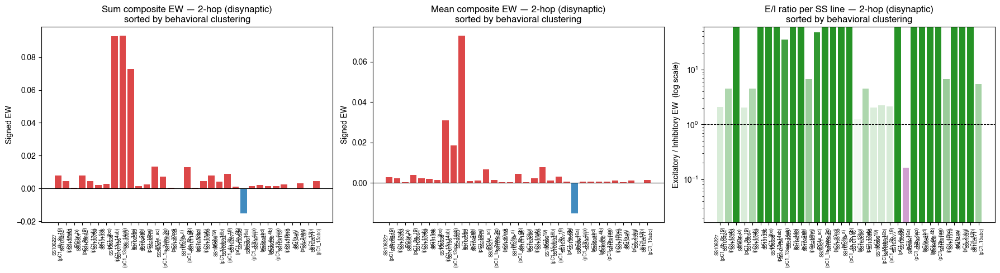

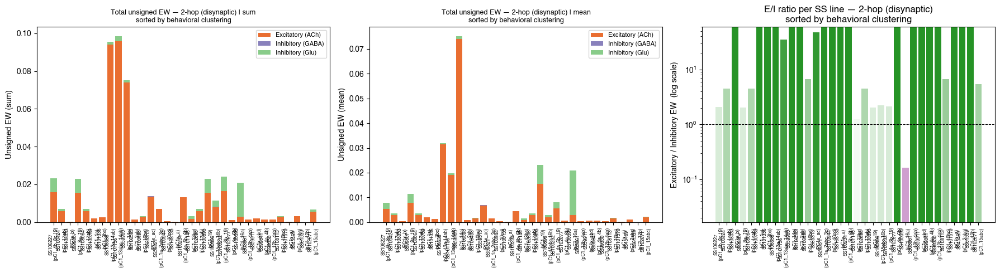

In [78]:
# ── Bar graphs sorted by behavioral clustering (end of Section 7) ────────────
# Replicates Section 5 bar charts using _sorted_lines9 order from Ward clustering

# ── Figure A: Sum composite EW (signed) ──────────────────────────────────────
_ew_bs   = ss_ew.set_index('LineName').reindex(_sorted_lines9).reset_index()
_xlbs    = (_ew_bs['LineName'] + '\n(' + _ew_bs['CellType'].str[:18] + ')').tolist()
_xbs     = range(len(_ew_bs))

fig_bs, axes_bs = plt.subplots(1, 3, figsize=(max(18, len(_ew_bs)*0.28), 5), sharey=False)

# Panel 1: sum composite EW
_col_bs = ['#d62728' if v >= 0 else '#1f77b4' for v in _ew_bs['composite_sum_ew_2hop']]
axes_bs[0].bar(_xbs, _ew_bs['composite_sum_ew_2hop'], color=_col_bs, alpha=0.85)
axes_bs[0].axhline(0, color='black', linewidth=0.8)
axes_bs[0].set_title('Sum composite EW — 2-hop (disynaptic)\nsorted by behavioral clustering')
axes_bs[0].set_ylabel('Signed EW')
axes_bs[0].set_xticks(list(_xbs)); axes_bs[0].set_xticklabels(_xlbs, rotation=90, fontsize=6)

# Panel 2: mean composite EW
_colm_bs = ['#d62728' if v >= 0 else '#1f77b4' for v in _ew_bs['composite_mean_ew_2hop']]
axes_bs[1].bar(_xbs, _ew_bs['composite_mean_ew_2hop'], color=_colm_bs, alpha=0.85)
axes_bs[1].axhline(0, color='black', linewidth=0.8)
axes_bs[1].set_title('Mean composite EW — 2-hop (disynaptic)\nsorted by behavioral clustering')
axes_bs[1].set_ylabel('Signed EW')
axes_bs[1].set_xticks(list(_xbs)); axes_bs[1].set_xticklabels(_xlbs, rotation=90, fontsize=6)

# Panel 3: E/I ratio in behavioral cluster order
_ss_ei_bs = pd.DataFrame([{
    'LineName': r['LineName'],
    'CellType':  r['CellType'],
    'excit_ew':  sum(excit_by_type.get(t, 0.) for t in parse_pC1_types(str(r['CellType']))),
    'inhib_ew':  sum(inhib_by_type.get(t, 0.) for t in parse_pC1_types(str(r['CellType']))),
} for _, r in _ew_bs.iterrows() if parse_pC1_types(str(r['CellType']))])
_ss_ei_bs['ei_ratio'] = (
    _ss_ei_bs['excit_ew'] / _ss_ei_bs['inhib_ew'].replace(0., float('nan'))
).fillna(float(EI_RATIO_MAX)).clip(lower=1./EI_RATIO_MAX, upper=float(EI_RATIO_MAX))
_ss_ei_bs['log_ei'] = np.log(_ss_ei_bs['ei_ratio'])
_log_mx_bs   = np.log(EI_RATIO_MAX)
_einorm_bs   = mcolors.TwoSlopeNorm(vmin=-_log_mx_bs, vcenter=0., vmax=_log_mx_bs)
_eicols_bs   = [mcolors.to_hex(PWG_CMAP(_einorm_bs(v))) for v in _ss_ei_bs['log_ei']]
_eilabels_bs = (_ss_ei_bs['LineName'] + '\n(' + _ss_ei_bs['CellType'].str[:18] + ')').tolist()
ax_ei_bs = axes_bs[2]
ax_ei_bs.bar(range(len(_ss_ei_bs)), _ss_ei_bs['ei_ratio'], color=_eicols_bs, alpha=0.85)
ax_ei_bs.axhline(1., color='black', linewidth=0.8, linestyle='--')
ax_ei_bs.set_yscale('log'); ax_ei_bs.set_ylim(1./EI_RATIO_MAX, EI_RATIO_MAX)
ax_ei_bs.set_title('E/I ratio per SS line — 2-hop (disynaptic)\nsorted by behavioral clustering')
ax_ei_bs.set_ylabel('Excitatory / Inhibitory EW  (log scale)')
ax_ei_bs.set_xticks(range(len(_ss_ei_bs))); ax_ei_bs.set_xticklabels(_eilabels_bs, rotation=90, fontsize=6)

plt.tight_layout()
matplotlib.rcParams['svg.fonttype'] = 'none'
fig_bs.savefig(RESULTS_DIR / 'SS_line_composite_ew_beh_sorted.pdf', bbox_inches='tight')
fig_bs.savefig(RESULTS_DIR / 'SS_line_composite_ew_beh_sorted.svg', bbox_inches='tight')
plt.show()

# ── Figure B: Total unsigned EW stacked bar ───────────────────────────────────
_ewu_bs  = ss_ew_unsigned.set_index('LineName').reindex(_sorted_lines9).reset_index()
_xlubs   = (_ewu_bs['LineName'] + '\n(' + _ewu_bs['CellType'].str[:18] + ')').tolist()
_xubs    = range(len(_ewu_bs))

fig_ubs, axes_ubs = plt.subplots(1, 3, figsize=(max(18, len(_ewu_bs)*0.28), 5), sharey=False)

for _ax_ubs, _use_mean_bs, _title_ubs, _ylabel_ubs in zip(
    [axes_ubs[0], axes_ubs[1]],
    [False, True],
    ['Total unsigned EW — 2-hop (disynaptic) | sum\nsorted by behavioral clustering',
     'Total unsigned EW — 2-hop (disynaptic) | mean\nsorted by behavioral clustering'],
    ['Unsigned EW (sum)', 'Unsigned EW (mean)'],
):
    _div_ubs = _ewu_bs['n_components'] if _use_mean_bs else 1
    _e_ubs  = _ewu_bs['excit_ew'] / _div_ubs
    _g_ubs  = _ewu_bs['gaba_ew']  / _div_ubs
    _gl_ubs = _ewu_bs['glu_ew']   / _div_ubs
    _ax_ubs.bar(_xubs, _e_ubs,  color='#e6550d', alpha=0.85, label='Excitatory (ACh)')
    _ax_ubs.bar(_xubs, _g_ubs,  bottom=_e_ubs,             color='#756bb1', alpha=0.85, label='Inhibitory (GABA)')
    _ax_ubs.bar(_xubs, _gl_ubs, bottom=_e_ubs + _g_ubs,    color='#74c476', alpha=0.85, label='Inhibitory (Glu)')
    _ax_ubs.axhline(0, color='black', linewidth=0.8)
    _ax_ubs.set_title(_title_ubs, fontsize=9); _ax_ubs.set_ylabel(_ylabel_ubs)
    _ax_ubs.set_xticks(list(_xubs)); _ax_ubs.set_xticklabels(_xlubs, rotation=90, fontsize=6)
    _ax_ubs.legend(fontsize=8, loc='upper right')

# Panel 3: E/I ratio for unsigned EW
_ss_eiupp = _ewu_bs.copy()
_ss_eiupp['inhib_ew'] = _ss_eiupp['gaba_ew'] + _ss_eiupp['glu_ew']
_ss_eiupp['ei_ratio'] = (
    _ss_eiupp['excit_ew'] / _ss_eiupp['inhib_ew'].replace(0., float('nan'))
).fillna(float(EI_RATIO_MAX)).clip(lower=1./EI_RATIO_MAX, upper=float(EI_RATIO_MAX))
_ss_eiupp['log_ei'] = np.log(_ss_eiupp['ei_ratio'])
_lmx_ubs    = np.log(EI_RATIO_MAX)
_einrm_ubs  = mcolors.TwoSlopeNorm(vmin=-_lmx_ubs, vcenter=0., vmax=_lmx_ubs)
_eicol_ubs  = [mcolors.to_hex(PWG_CMAP(_einrm_ubs(v))) for v in _ss_eiupp['log_ei']]
_eilbl_ubs  = (_ss_eiupp['LineName'] + '\n(' + _ss_eiupp['CellType'].str[:18] + ')').tolist()
ax_ei_ubs = axes_ubs[2]
ax_ei_ubs.bar(range(len(_ss_eiupp)), _ss_eiupp['ei_ratio'], color=_eicol_ubs, alpha=0.85)
ax_ei_ubs.axhline(1., color='black', linewidth=0.8, linestyle='--')
ax_ei_ubs.set_yscale('log'); ax_ei_ubs.set_ylim(1./EI_RATIO_MAX, EI_RATIO_MAX)
ax_ei_ubs.set_title('E/I ratio per SS line — 2-hop (disynaptic)\nsorted by behavioral clustering')
ax_ei_ubs.set_ylabel('Excitatory / Inhibitory EW  (log scale)')
ax_ei_ubs.set_xticks(range(len(_ss_eiupp))); ax_ei_ubs.set_xticklabels(_eilbl_ubs, rotation=90, fontsize=6)

plt.tight_layout()
matplotlib.rcParams['svg.fonttype'] = 'none'
fig_ubs.savefig(RESULTS_DIR / 'SS_line_unsigned_ew_beh_sorted.pdf', bbox_inches='tight')
fig_ubs.savefig(RESULTS_DIR / 'SS_line_unsigned_ew_beh_sorted.svg', bbox_inches='tight')
plt.show()


## Section 8: Clustering Analysis — Excit / Inhib EW per Premotor Target

Two clustering analyses using disynaptic EW per premotor target across SS lines.

**Analysis A** — 2 × N features: excitatory EW + inhibitory EW per premotor type (2 × 19 = 38).

**Analysis B** — 3 × N features: excitatory EW + GABA EW + Glu EW per premotor type (3 × 19 = 57).

Both analyses: (1) PCA scatter coloured by K-means cluster, pulse z-score, and sine z-score;
(2) hierarchical (Ward) dendrogram; (3) silhouette scores to select K.

In [79]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import dendrogram, linkage

# ── Merge SS line EW table with behavioral z-scores ──────────────────────────
_df_cl = ss_ew_pt_2hop.merge(
    beh[['LineName', 'Pulse_Transient', 'Sine_Transient',
         'Pulse_pval_Transient', 'Sine_pval_Transient']],
    on='LineName')
_df_cl['pulse_sig'] = _df_cl['Pulse_pval_Transient'].abs() < 0.05
_df_cl['sine_sig']  = _df_cl['Sine_pval_Transient'].abs()  < 0.05

# ── GABA and Glu EW per SS line x premotor target (from merged_all) ──────────
_gaba_pm = (
    merged_all[merged_all['inter_nt'] == 'gaba']
    .groupby(['src_type', 'premotor_type'])['path_ew'].sum()
    .to_dict()
)
_glu_pm = (
    merged_all[merged_all['inter_nt'] == 'glutamate']
    .groupby(['src_type', 'premotor_type'])['path_ew'].sum()
    .to_dict()
)

_rows_nt = []
for _, row in beh.iterrows():
    types = parse_pC1_types(str(row['CellType']))
    if not types:
        continue
    entry = {'LineName': row['LineName']}
    for pm_grp, pm_subs in PREMOTOR_GROUPS.items():
        entry[f'gaba_ew_{pm_grp}'] = sum(_gaba_pm.get((t, sub), 0.) for t in types for sub in pm_subs)
        entry[f'glu_ew_{pm_grp}']  = sum(_glu_pm.get((t, sub), 0.)  for t in types for sub in pm_subs)
    _rows_nt.append(entry)

_nt_pm = pd.DataFrame(_rows_nt)
_df_cl  = _df_cl.merge(_nt_pm, on='LineName')

print(f'{len(_df_cl)} SS lines ready for clustering')

# ── Shared BWR colormap for z-score colouring ─────────────────────────────────
_bwr_cl = mcolors.LinearSegmentedColormap.from_list(
    'bwr_cl', ['#0000ff', '#f7f7f7', '#ff0000'])
_vmax_cl = max(_df_cl['Pulse_Transient'].abs().max(),
               _df_cl['Sine_Transient'].abs().max())
_norm_cl  = mcolors.TwoSlopeNorm(vmin=-6, vcenter=0, vmax=6)
_GRAY_CL  = '#cccccc'

def _beh_colors(z_vals, sig_mask):
    rgba = np.array([_bwr_cl(_norm_cl(v)) for v in z_vals])
    rgba[~sig_mask] = np.array(mcolors.to_rgba(_GRAY_CL))
    return rgba

def _run_clustering(X_sc, k_range=range(2, 9), force_k=None):
    sil = {}
    for k in k_range:
        labs = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_sc)
        sil[k] = silhouette_samples(X_sc, labs)  # per-sample scores
    sil_best_k = max(sil, key=lambda k: sil[k].mean())  # silhouette-optimal K
    # explicit force_k arg wins; fall back to module-level FORCE_K; else auto
    _fk = force_k if force_k is not None else FORCE_K
    best_k = int(_fk) if _fk is not None else sil_best_k
    labels = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit_predict(X_sc)
    return labels, sil, best_k, sil_best_k

# ── Cluster-count override ───────────────────────────────────────────────────
# Set FORCE_K to an integer to pin the number of K-means clusters for every
# analysis in Sections 8 and 9.  Set to None to use automatic silhouette
# selection (best silhouette score across K = 2..6).
#
# *** After changing FORCE_K, re-run THIS cell (cell 36) before re-running
#     the analysis cells — the kernel must reload the function definitions. ***
FORCE_K = 5

# ── Concentric-circle marker sizes ─────────────────────────────────────────
# OUTER_MARKER_S controls the outer circle (pulse z-score).
# INNER_MARKER_S is derived as OUTER_MARKER_S // 4  (maintains the 4:1 ratio).
# Change OUTER_MARKER_S here, then re-run this cell to apply everywhere.
OUTER_MARKER_S = 280
INNER_MARKER_S = OUTER_MARKER_S // 4

_CLUSTER_COLORS = ['#e41a1c','#377eb8','#4daf4a','#984ea3','#ff7f00','#a65628','#f781bf','#999999']

def _plot_analysis(X_sc, feature_label, df, fname_stem, path_label='disynaptic', force_k=None):
    _pca    = PCA(n_components=2)
    _coords = _pca.fit_transform(X_sc)
    _var    = _pca.explained_variance_ratio_ * 100
    _labs, _sil, _best_k, _sil_best_k = _run_clustering(X_sc, force_k=force_k)
    _clr = np.array([_CLUSTER_COLORS[l] for l in _labs])
    _Z = linkage(X_sc, method='ward')

    # ── Cluster assignment table (built once, displayed at end) ──────────────
    _cluster_df = df[['LineName']].copy().reset_index(drop=True)
    _cluster_df['Cluster']   = _labs + 1          # 1-indexed
    _cluster_df['Sil_Score'] = _sil[_best_k]      # per-sample silhouette score
    _beh_show = [c for c in ['Pulse_Transient', 'Sine_Transient',
                              'Pulse_Transient_sil', 'Sine_Transient_sil']
                 if c in df.columns]
    for _bc in _beh_show:
        _cluster_df[_bc] = df[_bc].values
    _cluster_df = (_cluster_df
                   .sort_values(['Cluster', 'Sil_Score'], ascending=[True, False])
                   .reset_index(drop=True))

    fig, axes = plt.subplots(1, 4, figsize=(23, 6),
                             gridspec_kw={'width_ratios': [3, 3, 3, 2.5]})
    for ax, colors, title, sig in zip(
        axes[:3],
        [_clr,
         _beh_colors(df['Pulse_Transient'].values, df['pulse_sig'].values),
         _beh_colors(df['Sine_Transient'].values,  df['sine_sig'].values)],
        [f'K-means clusters  (K={_best_k})',
         'Pulse z-score  (gray = n.s.)',
         'Sine z-score  (gray = n.s.)'],
        [None, df['pulse_sig'].values, df['sine_sig'].values],
    ):
        ax.scatter(_coords[:, 0], _coords[:, 1], color=colors, s=60,
                   linewidths=0, zorder=2)
        _label_mask = (np.ones(len(df), dtype=bool) if sig is None else sig)
        for idx in np.where(_label_mask)[0]:
            ax.annotate(df.iloc[idx]['LineName'],
                        (_coords[idx, 0], _coords[idx, 1]),
                        fontsize=5, ha='left', va='bottom',
                        xytext=(2, 2), textcoords='offset points',
                        color='#333333', zorder=10)
        ax.axhline(0, color='gray', lw=0.4, ls='--')
        ax.axvline(0, color='gray', lw=0.4, ls='--')
        ax.set_xlabel(f'PC1  ({_var[0]:.1f}%)', fontsize=9)
        ax.set_ylabel(f'PC2  ({_var[1]:.1f}%)', fontsize=9)
        ax.set_title(title, fontsize=9)

    from matplotlib.patches import Patch
    axes[0].legend(
        handles=[Patch(facecolor=_CLUSTER_COLORS[k], label=f'Cluster {k+1}')
                 for k in range(_best_k)],
        fontsize=7, loc='best', frameon=True)

    _sm_cl = plt.cm.ScalarMappable(cmap=_bwr_cl, norm=_norm_cl)
    _sm_cl.set_array([])
    for ax in axes[1:3]:
        plt.colorbar(_sm_cl, ax=ax, shrink=0.55, pad=0.02).ax.tick_params(labelsize=7)

    ax_sil = axes[3]
    _ks = list(_sil.keys())
    _bar_cols = ['#2171b5' if k == _best_k else '#aaaaaa' for k in _ks]
    _sv = [np.mean(_sil[k]) for k in _ks]
    _se = [np.std(_sil[k], ddof=1) / np.sqrt(len(_sil[k])) for k in _ks]
    ax_sil.bar(_ks, _sv, color=_bar_cols, alpha=0.6, width=0.6,
               yerr=_se, capsize=4,
               error_kw=dict(elinewidth=0.8, ecolor='#333333', capthick=0.8))
    _rng_sil = np.random.default_rng(42)
    for _k_sil in _ks:
        _jit = _rng_sil.uniform(-0.15, 0.15, size=len(_sil[_k_sil]))
        ax_sil.scatter(np.full(len(_sil[_k_sil]), _k_sil) + _jit,
                       _sil[_k_sil],
                       color='black', s=20, alpha=0.7,
                       linewidths=0, zorder=5)
    ax_sil.set_xlabel('Number of clusters K', fontsize=9)
    ax_sil.set_ylabel('Silhouette score', fontsize=9)
    ax_sil.set_ylim(0, 1)
    _k_mode  = f'K={_best_k} (forced)' if FORCE_K is not None else f'K={_best_k} (auto)'
    _sil_leg = '  |  blue=plotted'
    ax_sil.set_title(f'Silhouette — {_k_mode}{_sil_leg}', fontsize=8)
    ax_sil.set_xticks(_ks)
    from scipy.stats import ttest_1samp as _ttest_sil
    print(f'\nSilhouette t-tests (H₀: mean=0, one-sided)  —  {feature_label}  ({path_label}):')
    print(f'  {"K":>3}  {"mean sil":>8}  {"t":>7}  {"p":>9}  sig')
    for _kt_s, _sv_ks, _se_ks in zip(_ks, _sv, _se):
        _t_s, _p_s = _ttest_sil(_sil[_kt_s], 0, alternative='greater')
        _sig_s = ('***' if _p_s < 0.001 else '**' if _p_s < 0.01
                  else '*' if _p_s < 0.05 else 'ns')
        print(f'  {_kt_s:>3}  {_sv_ks:>8.3f}  {_t_s:>7.2f}  {_p_s:>9.5f}  {_sig_s}')
        ax_sil.text(_kt_s, min(_sv_ks + _se_ks + 0.03, 0.93),
                    _sig_s, ha='center', va='bottom', fontsize=7, color='#333333')

    fig.suptitle(
        f'Clustering - {feature_label}  ({X_sc.shape[1]} features, {path_label})',
        fontsize=11)
    fig.tight_layout()
    matplotlib.rcParams['svg.fonttype'] = 'none'  # ensure editable text
    fig.savefig(RESULTS_DIR / f'{fname_stem}_pca_clusters.svg', bbox_inches='tight')
    plt.show()

    fig2, ax2 = plt.subplots(figsize=(max(10, len(df) * 0.35), 5))
    dendrogram(_Z, labels=df['LineName'].tolist(), ax=ax2,
               leaf_rotation=90, leaf_font_size=7,
               color_threshold=0.7 * max(_Z[:, 2]))
    ax2.set_title(f'Ward hierarchical clustering - {feature_label}', fontsize=10)
    ax2.set_ylabel('Distance', fontsize=9)
    fig2.tight_layout()
    fig2.savefig(RESULTS_DIR / f'{fname_stem}_dendrogram.pdf', bbox_inches='tight')
    fig2.savefig(RESULTS_DIR / f'{fname_stem}_dendrogram.svg', bbox_inches='tight')
    plt.show()

    # ── Figure 3: PC2 vs PC1 coloured by song z-score (concentric circles) ───
    _pz_s8   = df['Pulse_Transient'].values
    _sz_s8   = df['Sine_Transient'].values
    _psig_s8 = df['pulse_sig'].values
    _ssig_s8 = df['sine_sig'].values
    _any_s8  = _psig_s8 | _ssig_s8

    _pc_s8 = _beh_colors(_pz_s8, _psig_s8)
    _sc_s8 = _beh_colors(_sz_s8, _ssig_s8)

    _OUTER_S8 = OUTER_MARKER_S
    _INNER_S8 = INNER_MARKER_S
    # Draw each line's outer+inner as an atomic pair: bg first, fg last
    # Unique zorder per pair ensures no circle slips between another line's pair
    _ord_s8 = np.argsort(_any_s8.astype(int))  # bg (0) before fg (1)

    fig3, ax3 = plt.subplots(figsize=(8, 7))
    for _k_s8, _i_s8 in enumerate(_ord_s8):
        _zo_pair = 20 + _k_s8 * 2
        _ec_pair = '#444444' if _any_s8[_i_s8] else '#888888'
        ax3.scatter([_coords[_i_s8, 0]], [_coords[_i_s8, 1]],
                    c=[_pc_s8[_i_s8]], s=_OUTER_S8, zorder=_zo_pair,
                    edgecolors=_ec_pair, linewidths=0.5)
        ax3.scatter([_coords[_i_s8, 0]], [_coords[_i_s8, 1]],
                    c=[_sc_s8[_i_s8]], s=_INNER_S8, zorder=_zo_pair + 1,
                    edgecolors='none')

    for _j_s8 in range(len(df)):
        ax3.annotate(df.iloc[_j_s8]['LineName'],
                     (_coords[_j_s8, 0], _coords[_j_s8, 1]),
                     fontsize=5, xytext=(2, 2), textcoords='offset points',
                     color='#333333', ha='left', va='bottom', zorder=10)

    ax3.axhline(0, color='gray', lw=0.4, ls='--')
    ax3.axvline(0, color='gray', lw=0.4, ls='--')
    ax3.set_xlabel(f'PC1  ({_var[0]:.1f}%)', fontsize=10)
    ax3.set_ylabel(f'PC2  ({_var[1]:.1f}%)', fontsize=10)
    ax3.set_title(
        f'PC2 vs PC1 — {feature_label}  ({path_label})\n'
        f'outer = pulse z-score  |  inner = sine z-score  |  gray = n.s.',
        fontsize=9)
    ax3.spines["top"].set_visible(False)
    ax3.spines["right"].set_visible(False)
    ax3.set_box_aspect(1)

    _sm_s8 = plt.cm.ScalarMappable(cmap=_bwr_cl, norm=_norm_cl)
    _sm_s8.set_array([])
    _cbar_ax_s8 = fig3.add_axes([0.15, 0.04, 0.70, 0.025])
    _cbar_s8 = fig3.colorbar(_sm_s8, cax=_cbar_ax_s8, orientation='horizontal')
    _cbar_s8.set_label('z-score', fontsize=9)
    _cbar_s8.ax.tick_params(labelsize=8)

    matplotlib.rcParams['svg.fonttype'] = 'none'
    fig3.subplots_adjust(bottom=0.15)
    fig3.savefig(RESULTS_DIR / f'{fname_stem}_pca_zscore_concentric.svg',
                 bbox_inches='tight')
    plt.show()

    # ── Interactive Plotly version of PC2 vs PC1 z-score scatter ─────────────
    try:
        import plotly.graph_objects as _pgo

        def _to_hex_s8(rgba):
            return mcolors.to_hex(rgba)

        _pulse_hex_s8 = [_to_hex_s8(_pc_s8[i]) for i in range(len(df))]
        _sine_hex_s8  = [_to_hex_s8(_sc_s8[i]) for i in range(len(df))]

        _hover_s8 = [
            (f'<b>{df.iloc[i]["LineName"]}</b><br>'
             f'Pulse z: {_pz_s8[i]:.2f}{"  ★" if _psig_s8[i] else ""}<br>'
             f'Sine z: {_sz_s8[i]:.2f}{"  ★" if _ssig_s8[i] else ""}')
            for i in range(len(df))
        ]

        # Four traces: bg_outer → bg_inner → fg_outer → fg_inner
        # keeps each line's outer+inner pair visually together
        _bg_idx_pl = np.where(~_any_s8)[0]
        _fg_idx_pl = np.where( _any_s8)[0]

        _fig_pl = _pgo.Figure()

        # Trace 1: bg outer (pulse, n.s.) — bottom layer
        _fig_pl.add_trace(_pgo.Scatter(
            x=_coords[_bg_idx_pl, 0], y=_coords[_bg_idx_pl, 1],
            mode='markers',
            marker=dict(size=18,
                        color=[_pulse_hex_s8[i] for i in _bg_idx_pl],
                        line=dict(width=0.8, color='rgba(136,136,136,0.5)')),
            text=[_hover_s8[i] for i in _bg_idx_pl],
            hovertemplate='%{text}<extra></extra>',
            name='Outer: pulse z-score (n.s.)',
            showlegend=False,
        ))

        # Trace 2: bg inner (sine, n.s.)
        _fig_pl.add_trace(_pgo.Scatter(
            x=_coords[_bg_idx_pl, 0], y=_coords[_bg_idx_pl, 1],
            mode='markers',
            marker=dict(size=9,
                        color=[_sine_hex_s8[i] for i in _bg_idx_pl],
                        line=dict(width=0)),
            hoverinfo='skip',
            name='Inner: sine z-score (n.s.)',
            showlegend=False,
        ))

        # Trace 3: fg outer (pulse, any sig) — above bg pair
        _fig_pl.add_trace(_pgo.Scatter(
            x=_coords[_fg_idx_pl, 0], y=_coords[_fg_idx_pl, 1],
            mode='markers',
            marker=dict(size=18,
                        color=[_pulse_hex_s8[i] for i in _fg_idx_pl],
                        line=dict(width=0.8, color='rgba(68,68,68,0.8)')),
            text=[_hover_s8[i] for i in _fg_idx_pl],
            hovertemplate='%{text}<extra></extra>',
            name='Outer: pulse z-score',
        ))

        # Trace 4: fg inner (sine, any sig) — top layer
        _fig_pl.add_trace(_pgo.Scatter(
            x=_coords[_fg_idx_pl, 0], y=_coords[_fg_idx_pl, 1],
            mode='markers',
            marker=dict(size=9,
                        color=[_sine_hex_s8[i] for i in _fg_idx_pl],
                        line=dict(width=0)),
            hoverinfo='skip',
            name='Inner: sine z-score',
        ))

        _fig_pl.update_layout(
            title=dict(
                text=(f'PC2 vs PC1 — {feature_label}  ({path_label})<br>'
                      f'<sup>outer = pulse z-score | inner = sine z-score | '
                      f'gray = n.s. | hover for line name &amp; z-scores</sup>'),
                font=dict(size=13),
            ),
            xaxis=dict(
                title=f'PC1  ({_var[0]:.1f}%)',
                zeroline=True, zerolinecolor='lightgray', zerolinewidth=1,
                showgrid=True, gridcolor='rgba(200,200,200,0.4)',
            ),
            yaxis=dict(
                title=f'PC2  ({_var[1]:.1f}%)',
                zeroline=True, zerolinecolor='lightgray', zerolinewidth=1,
                showgrid=True, gridcolor='rgba(200,200,200,0.4)',
            ),
            hovermode='closest',
            plot_bgcolor='white',
            width=800, height=750,
        )

        _pl_html = RESULTS_DIR / f'{fname_stem}_pca_zscore_interactive.html'
        _fig_pl.write_html(str(_pl_html))
        print(f'Interactive plot saved → {_pl_html.name}')
    except ImportError:
        print('plotly not available — skipping interactive plot')

    # ── Figure 3b: PC2 vs PC1 — concentric circles + cluster hulls ──────
    import matplotlib.lines as _mlines8cc
    from matplotlib.patches import Patch as _Patch8cc

    fig3b, ax3b = plt.subplots(figsize=(8, 7))

    # Atomic concentric circles reusing _ord_s8; outer edge = cluster colour
    for _k8cc, _i8cc in enumerate(_ord_s8):
        _zo8cc = 20 + _k8cc * 2
        _ec8cc = _CLUSTER_COLORS[_labs[_i8cc]]
        ax3b.scatter([_coords[_i8cc, 0]], [_coords[_i8cc, 1]],
                     c=[_pc_s8[_i8cc]], s=_OUTER_S8,
                     zorder=_zo8cc, edgecolors=_ec8cc, linewidths=2.4)
        ax3b.scatter([_coords[_i8cc, 0]], [_coords[_i8cc, 1]],
                     c=[_sc_s8[_i8cc]], s=_INNER_S8,
                     zorder=_zo8cc + 1, edgecolors='none')

    # Labels (all lines, same as fig3)
    for _j8cc in range(len(df)):
        ax3b.annotate(df.iloc[_j8cc]['LineName'],
                      (_coords[_j8cc, 0], _coords[_j8cc, 1]),
                      fontsize=5, xytext=(2, 2), textcoords='offset points',
                      color='#333333', ha='left', va='bottom', zorder=200)

    ax3b.axhline(0, color='gray', lw=0.4, ls='--')
    ax3b.axvline(0, color='gray', lw=0.4, ls='--')
    ax3b.set_xlabel(f'PC1  ({_var[0]:.1f}%)', fontsize=10)
    ax3b.set_ylabel(f'PC2  ({_var[1]:.1f}%)', fontsize=10)
    ax3b.set_title(
        f'PC2 vs PC1 — {feature_label}  ({path_label})\n'
        f'K={_best_k} clusters  |  outer = pulse z-score  |  '
        f'inner = sine z-score  |  edge & hull = cluster',
        fontsize=9)
    ax3b.spines['top'].set_visible(False)
    ax3b.spines['right'].set_visible(False)
    ax3b.set_box_aspect(1)

    _leg8cc = (
        [_Patch8cc(facecolor=_CLUSTER_COLORS[c], edgecolor=_CLUSTER_COLORS[c],
                   alpha=0.5, label=f'Cluster {c + 1}')
         for c in range(_best_k)]
        + [_mlines8cc.Line2D([], [], marker='o', color='w',
               markerfacecolor='#888888', markeredgecolor='#555555',
               markersize=11, label='Outer: Pulse z-score'),
           _mlines8cc.Line2D([], [], marker='o', color='w',
               markerfacecolor='#888888', markeredgecolor='none',
               markersize=6,  label='Inner: Sine z-score'),
           _mlines8cc.Line2D([], [], marker='o', color='w',
               markerfacecolor=_GRAY_CL, markeredgecolor='none',
               markersize=8,  label='Gray fill = n.s.')]
    )
    ax3b.legend(handles=_leg8cc, fontsize=7, loc='upper left', framealpha=0.8)

    _sm8cc = plt.cm.ScalarMappable(cmap=_bwr_cl, norm=_norm_cl)
    _sm8cc.set_array([])
    _cbar_ax8cc = fig3b.add_axes([0.15, 0.04, 0.70, 0.025])
    _cbar8cc = fig3b.colorbar(_sm8cc, cax=_cbar_ax8cc, orientation='horizontal')
    _cbar8cc.set_label('z-score', fontsize=9)
    _cbar8cc.ax.tick_params(labelsize=8)

    matplotlib.rcParams['svg.fonttype'] = 'none'
    fig3b.subplots_adjust(bottom=0.15)
    fig3b.savefig(RESULTS_DIR / f'{fname_stem}_pca_zscore_concentric_clusters.svg',
                  bbox_inches='tight')
    plt.show()

    # ── Print + save cluster assignments ──────────────────────────────────────
    print(f'\nCluster assignments — {feature_label}  ({path_label}):')
    display(_cluster_df)
    _cluster_df.to_csv(
        RESULTS_DIR / f'{fname_stem}_cluster_assignments.csv', index=False)

def _plot_pc_beh_scatter(X_sc, df, analysis_label, fname_stem):
    from scipy.stats import spearmanr
    _pca4    = PCA(n_components=min(4, X_sc.shape[1]))
    _coords4 = _pca4.fit_transform(X_sc)
    _var4    = _pca4.explained_variance_ratio_ * 100

    _beh_cols = [
        ('Pulse_Transient', 'pulse_sig', 'Pulse z-score'),
        ('Sine_Transient',  'sine_sig',  'Sine z-score'),
    ]

    _n_pcs = min(4, _pca4.n_components_)
    fig, axes = plt.subplots(_n_pcs, 2, figsize=(10, _n_pcs * 4),
                             constrained_layout=True)

    for row_i in range(_n_pcs):
        for col_i, (beh_col, sig_col, beh_label) in enumerate(_beh_cols):
            ax   = axes[row_i, col_i]
            _x   = _coords4[:, row_i]
            _y   = df[beh_col].values
            _sig = df[sig_col].values

            _pt_colors = _beh_colors(_y, _sig)
            ax.scatter(_x[~_sig], _y[~_sig],
                       color=_GRAY_CL, s=35, zorder=1, linewidths=0)
            ax.scatter(_x[_sig],  _y[_sig],
                       color=_pt_colors[_sig], s=45, zorder=2, linewidths=0)

            for idx in np.where(_sig)[0]:
                ax.annotate(df.iloc[idx]['LineName'],
                            (_x[idx], _y[idx]),
                            fontsize=5, xytext=(2, 2),
                            textcoords='offset points',
                            color='#333333', ha='left', va='bottom')

            # Regression + Spearman using significant points only
            _xs, _ys = _x[_sig], _y[_sig]
            if len(_xs) >= 2:
                _m, _b = np.polyfit(_xs, _ys, 1)
                _xr    = np.linspace(_xs.min(), _xs.max(), 100)
                ax.plot(_xr, _m * _xr + _b,
                        color='#555555', lw=1.2, ls='--', zorder=3)
                _rho, _pval = spearmanr(_xs, _ys)
                _p_txt = f'p={_pval:.3f}' if _pval >= 0.001 else 'p<0.001'
                _annot_col = '#d62728' if _pval < 0.05 else '#555555'
                ax.text(0.05, 0.95,
                        f'Spearman r={_rho:.2f}, {_p_txt}  (sig. only, n={len(_xs)})',
                        transform=ax.transAxes, fontsize=7.5,
                        va='top', color=_annot_col)
            else:
                ax.text(0.05, 0.95, 'n.s. — too few sig. points',
                        transform=ax.transAxes, fontsize=7.5,
                        va='top', color='#aaaaaa')

            ax.axhline(0, color='gray', lw=0.5, ls=':')
            ax.axvline(0, color='gray', lw=0.5, ls=':')
            ax.set_xlabel(f'PC{row_i+1}  ({_var4[row_i]:.1f}%)', fontsize=9)
            ax.set_ylabel(beh_label, fontsize=9)
            ax.set_title(f'PC{row_i+1} vs {beh_label}', fontsize=9)

    fig.suptitle(
        f'PC coordinates vs behavioural z-scores - {analysis_label}',
        fontsize=10)
    fig.savefig(RESULTS_DIR / f'{fname_stem}_pc_beh_scatter.pdf',
                bbox_inches='tight')
    fig.savefig(RESULTS_DIR / f'{fname_stem}_pc_beh_scatter.svg', bbox_inches='tight')
    plt.show()

def _plot_pulse_sine_scatter(df, label, fname_stem):
    from scipy.stats import spearmanr
    _pulse = df['Pulse_Transient'].values
    _sine  = df['Sine_Transient'].values
    _psig  = df['pulse_sig'].values
    _ssig  = df['sine_sig'].values
    _either_sig = _psig | _ssig

    fig, ax = plt.subplots(figsize=(6, 6))

    # All points as filled circles; significant ones darker
    ax.scatter(_sine[~_either_sig], _pulse[~_either_sig],
               s=40, color='#aaaaaa', linewidths=0, zorder=1)
    ax.scatter(_sine[_either_sig],  _pulse[_either_sig],
               s=50, color='#333333', linewidths=0, zorder=2)

    # Label significant lines
    for idx in np.where(_either_sig)[0]:
        ax.annotate(df.iloc[idx]['LineName'],
                    (_sine[idx], _pulse[idx]),
                    fontsize=5.5, xytext=(3, 3),
                    textcoords='offset points',
                    color='#333333', ha='left', va='bottom')

    # Spearman on significant points only
    if _either_sig.sum() >= 2:
        _rho, _pval = spearmanr(_sine[_either_sig], _pulse[_either_sig])
        _p_txt = f'p={_pval:.3f}' if _pval >= 0.001 else 'p<0.001'
        _col   = '#d62728' if _pval < 0.05 else '#555555'
        ax.text(0.05, 0.95,
                f'Spearman r={_rho:.2f}, {_p_txt}  (sig. only, n={_either_sig.sum()})',
                transform=ax.transAxes, fontsize=8,
                va='top', color=_col)

    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.axvline(0, color='gray', lw=0.5, ls=':')
    ax.set_xlabel('Sine z-score', fontsize=10)
    ax.set_ylabel('Pulse z-score', fontsize=10)
    ax.set_title(f'Pulse vs Sine z-score  —  {label}', fontsize=10)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'{fname_stem}_pulse_vs_sine.pdf', bbox_inches='tight')
    fig.savefig(RESULTS_DIR / f'{fname_stem}_pulse_vs_sine.svg', bbox_inches='tight')
    plt.show()

def _plot_pca_3d(X_sc, df, analysis_label, fname_stem, force_k=None):
    """3D scatter of SS lines in PC1 × PC2 × PC3 space."""
    from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
    if X_sc.shape[1] < 3:
        print(f'_plot_pca_3d: need ≥3 features, got {X_sc.shape[1]} — skipping')
        return
    _pca3    = PCA(n_components=3)
    _coords3 = _pca3.fit_transform(X_sc)
    _var3    = _pca3.explained_variance_ratio_ * 100
    _labs3, _, _k3, _ = _run_clustering(X_sc, force_k=force_k)

    # Build (colors_rgba, sig_mask, title) for each panel
    _cluster_rgba = np.array([mcolors.to_rgba(_CLUSTER_COLORS[l]) for l in _labs3])
    _panel_specs = [(_cluster_rgba,
                     np.ones(len(df), dtype=bool),
                     f'K-means (K={_k3})')]
    for _bc, _sc_col, _lbl in (
        [('Pulse_Transient', 'pulse_sig',  'Pulse z-score (activation)'),
         ('Sine_Transient',  'sine_sig',   'Sine z-score (activation)')] +
        ([('Pulse_Transient_sil', 'pulse_sig_sil', 'Pulse z-score (silencing)'),
          ('Sine_Transient_sil',  'sine_sig_sil',  'Sine z-score (silencing)')]
         if 'Pulse_Transient_sil' in df.columns else [])
    ):
        _panel_specs.append((_beh_colors(df[_bc].values, df[_sc_col].values),
                             df[_sc_col].values.astype(bool),
                             _lbl))

    _np = len(_panel_specs)
    fig = plt.figure(figsize=(6 * _np, 6))

    for _pi, (_colors, _sig_mask, _title) in enumerate(_panel_specs):
        ax = fig.add_subplot(1, _np, _pi + 1, projection='3d')
        _is_cluster = (_pi == 0)

        if _is_cluster:
            ax.scatter(_coords3[:, 0], _coords3[:, 1], _coords3[:, 2],
                       c=_colors, s=40, linewidths=0, depthshade=True)
        else:
            _ns = ~_sig_mask
            if _ns.any():
                ax.scatter(_coords3[_ns, 0], _coords3[_ns, 1], _coords3[_ns, 2],
                           c=np.tile(mcolors.to_rgba(_GRAY_CL), (_ns.sum(), 1)),
                           s=25, linewidths=0, alpha=0.5, depthshade=True)
            if _sig_mask.any():
                ax.scatter(_coords3[_sig_mask, 0], _coords3[_sig_mask, 1],
                           _coords3[_sig_mask, 2],
                           c=_colors[_sig_mask], s=45, linewidths=0, depthshade=True)

        for _ii in range(len(df)):
            if _is_cluster or _sig_mask[_ii]:
                ax.text(_coords3[_ii, 0], _coords3[_ii, 1], _coords3[_ii, 2],
                        df.iloc[_ii]['LineName'], fontsize=4.5, color='#333333')

        ax.set_xlabel(f'PC1 ({_var3[0]:.1f}%)', fontsize=8, labelpad=3)
        ax.set_ylabel(f'PC2 ({_var3[1]:.1f}%)', fontsize=8, labelpad=3)
        ax.set_zlabel(f'PC3 ({_var3[2]:.1f}%)', fontsize=8, labelpad=3)
        ax.set_title(_title, fontsize=9)
        ax.tick_params(labelsize=6)

    fig.suptitle(f'PC1 \u00d7 PC2 \u00d7 PC3 \u2014 {analysis_label}', fontsize=10)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'{fname_stem}_pca_3d.pdf', bbox_inches='tight')
    fig.savefig(RESULTS_DIR / f'{fname_stem}_pca_3d.svg', bbox_inches='tight')
    plt.show()


33 SS lines ready for clustering



Silhouette t-tests (H₀: mean=0, one-sided)  —  Excitatory + Inhibitory EW  (disynaptic):
    K  mean sil        t          p  sig
    2     0.715    25.13    0.00000  ***
    3     0.721    23.06    0.00000  ***
    4     0.751    20.40    0.00000  ***
    5     0.750    16.78    0.00000  ***
    6     0.780    16.91    0.00000  ***
    7     0.623    11.08    0.00000  ***
    8     0.591    10.11    0.00000  ***


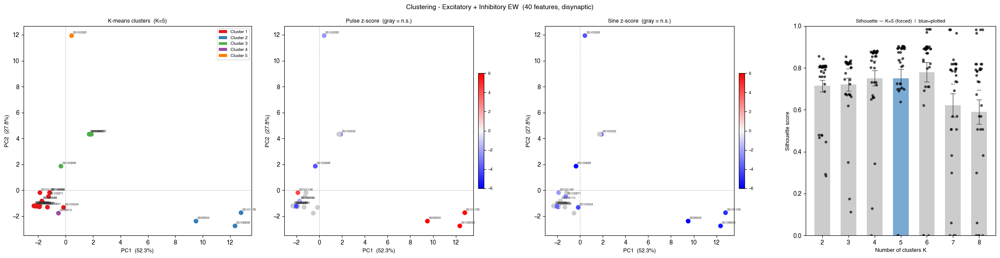

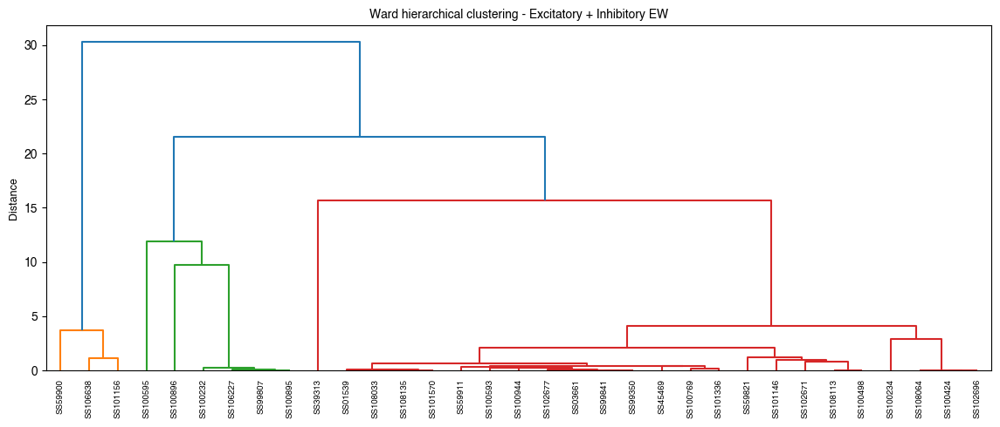

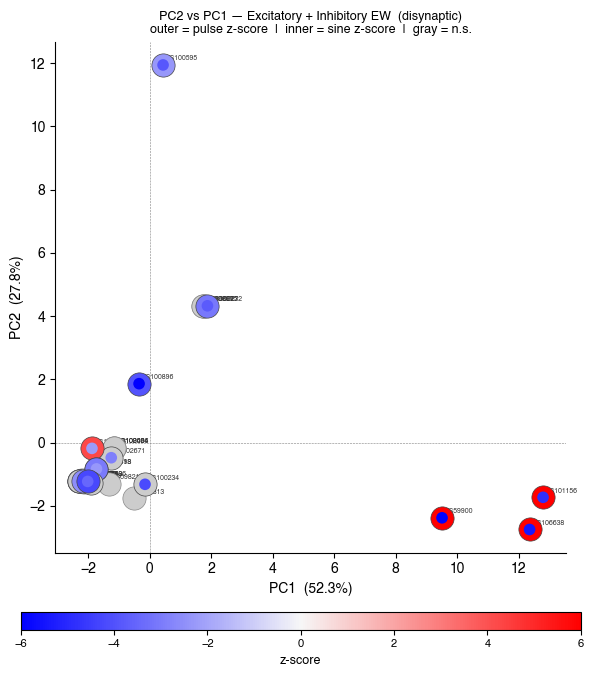

Interactive plot saved → clustering_excit_inhib_pca_zscore_interactive.html


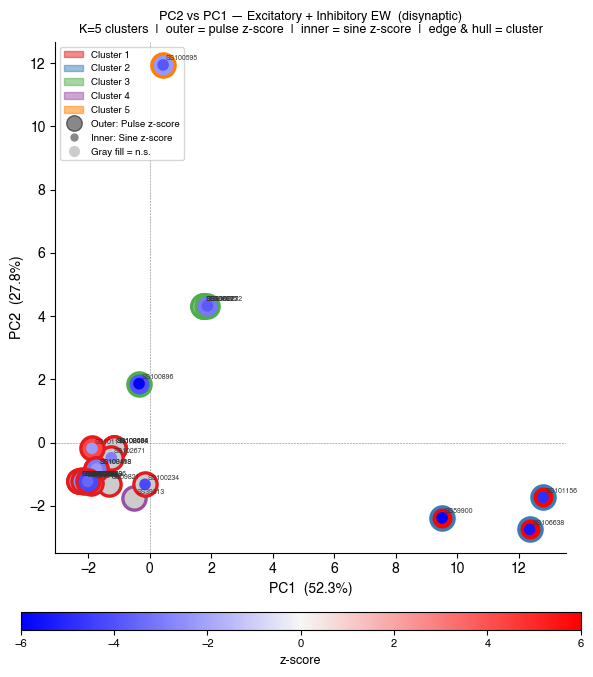


Cluster assignments — Excitatory + Inhibitory EW  (disynaptic):


,LineName,Cluster,Sil_Score,Pulse_Transient,Sine_Transient
0,SS99841,1,0.904912,-1.700832,-1.499713
1,SS99350,1,0.904912,-1.678569,-1.605630
2,SS03661,1,0.904912,-3.242428,-3.223896
3,SS102677,1,0.903463,-2.537946,-3.690735
4,SS100769,1,0.901066,0.735046,-1.283454
5,SS100593,1,0.898648,-1.596121,1.483027
6,SS100944,1,0.897679,-1.714604,-1.099071
7,SS59911,1,0.896901,-4.219345,-3.514400
8,SS108033,1,0.894396,-0.155461,-0.606917
9,SS108135,1,0.893787,-2.892074,-1.108433


In [80]:
# ── Analysis A: Excitatory + Inhibitory EW (38 features) ─────────────────────
# Each feature type scaled independently: excit block and inhib block
# separately standardised, preserving relative importance between NT classes.
_pos_feats = [f'pos_ew_{pm}' for pm in PREMOTOR_TARGETS]
_neg_feats = [f'neg_ew_{pm}' for pm in PREMOTOR_TARGETS]

_X_a_pos = _df_cl[_pos_feats].values.copy()
_X_a_neg = _df_cl[_neg_feats].abs().values
_X_a_sc = np.hstack([
    StandardScaler().fit_transform(_X_a_pos),
    StandardScaler().fit_transform(_X_a_neg),
])

_plot_analysis(_X_a_sc, 'Excitatory + Inhibitory EW', _df_cl,
               'clustering_excit_inhib', force_k=FORCE_K)


Silhouette t-tests (H₀: mean=0, one-sided)  —  Excitatory + GABA + Glu EW  (disynaptic):
    K  mean sil        t          p  sig
    2     0.683    21.70    0.00000  ***
    3     0.719    16.89    0.00000  ***
    4     0.737    20.28    0.00000  ***
    5     0.772    18.84    0.00000  ***
    6     0.780    16.91    0.00000  ***
    7     0.623    11.07    0.00000  ***
    8     0.590    10.11    0.00000  ***


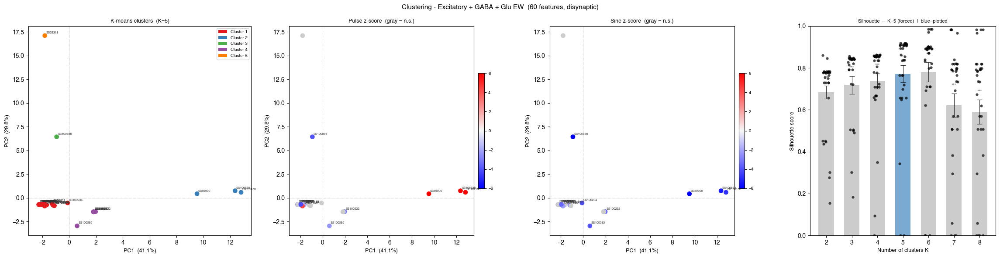

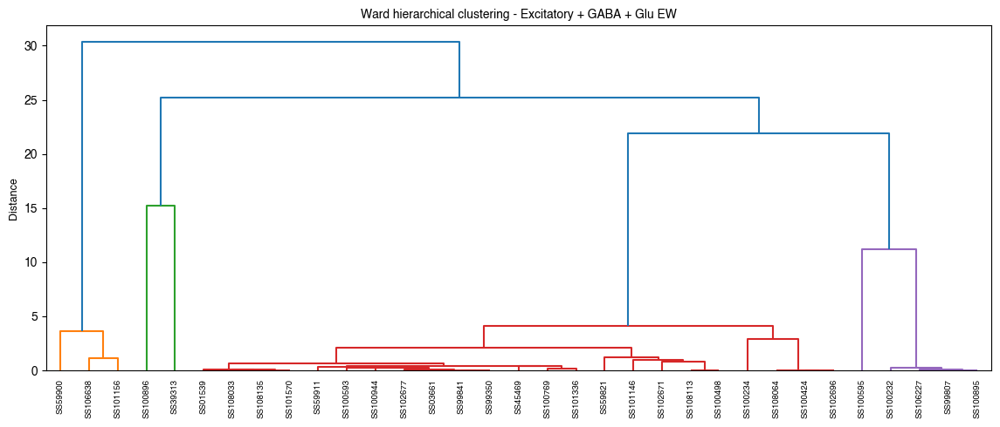

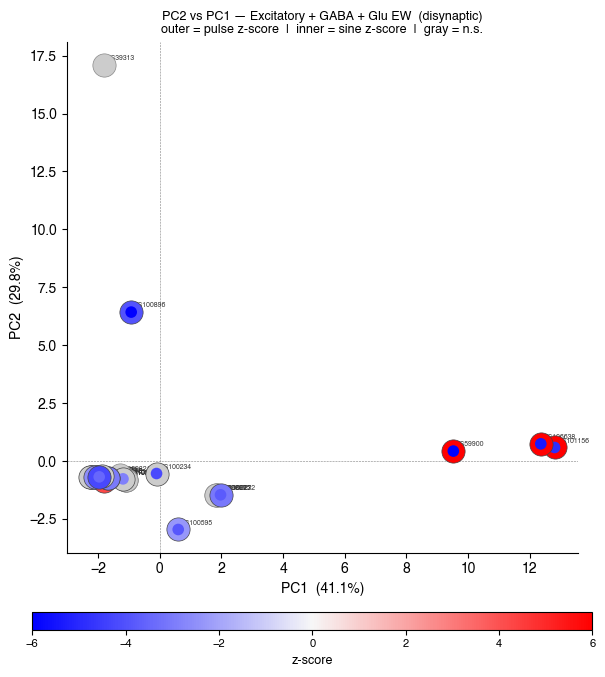

Interactive plot saved → clustering_excit_gaba_glu_pca_zscore_interactive.html


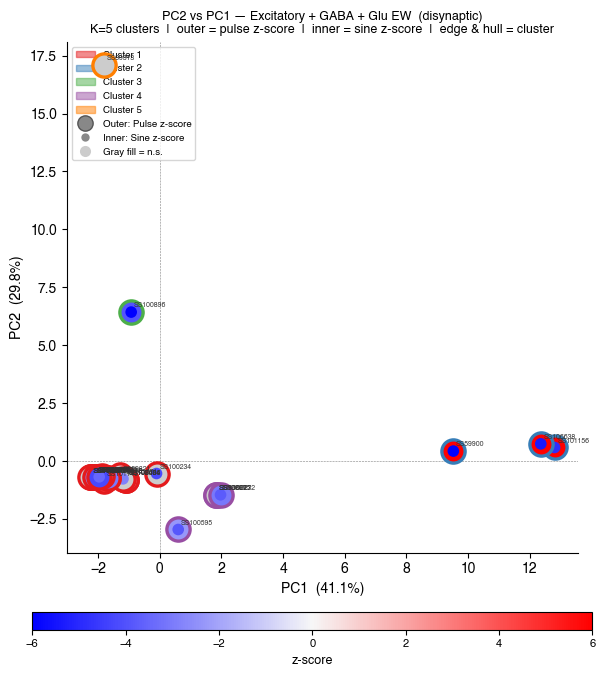


Cluster assignments — Excitatory + GABA + Glu EW  (disynaptic):


,LineName,Cluster,Sil_Score,Pulse_Transient,Sine_Transient
0,SS99841,1,0.918550,-1.700832,-1.499713
1,SS99350,1,0.918550,-1.678569,-1.605630
2,SS03661,1,0.918550,-3.242428,-3.223896
3,SS102677,1,0.917246,-2.537946,-3.690735
4,SS100769,1,0.915403,0.735046,-1.283454
5,SS100593,1,0.913041,-1.596121,1.483027
6,SS100944,1,0.912294,-1.714604,-1.099071
7,SS59911,1,0.911772,-4.219345,-3.514400
8,SS101336,1,0.909372,-0.867867,-1.068661
9,SS108033,1,0.909294,-0.155461,-0.606917


In [81]:
# ── Analysis B: Excitatory + GABA + Glu EW (57 features) ─────────────────────
# Each NT class scaled independently: excit, GABA, and Glu blocks
# separately standardised, preserving relative importance between NT classes.
_pos_feats  = [f'pos_ew_{pm}'  for pm in PREMOTOR_TARGETS]
_gaba_feats = [f'gaba_ew_{pm}' for pm in PREMOTOR_TARGETS]
_glu_feats  = [f'glu_ew_{pm}'  for pm in PREMOTOR_TARGETS]

_X_b_sc = np.hstack([
    StandardScaler().fit_transform(_df_cl[_pos_feats].values),
    StandardScaler().fit_transform(_df_cl[_gaba_feats].values),
    StandardScaler().fit_transform(_df_cl[_glu_feats].values),
])

_plot_analysis(_X_b_sc, 'Excitatory + GABA + Glu EW', _df_cl,
               'clustering_excit_gaba_glu', force_k=FORCE_K)

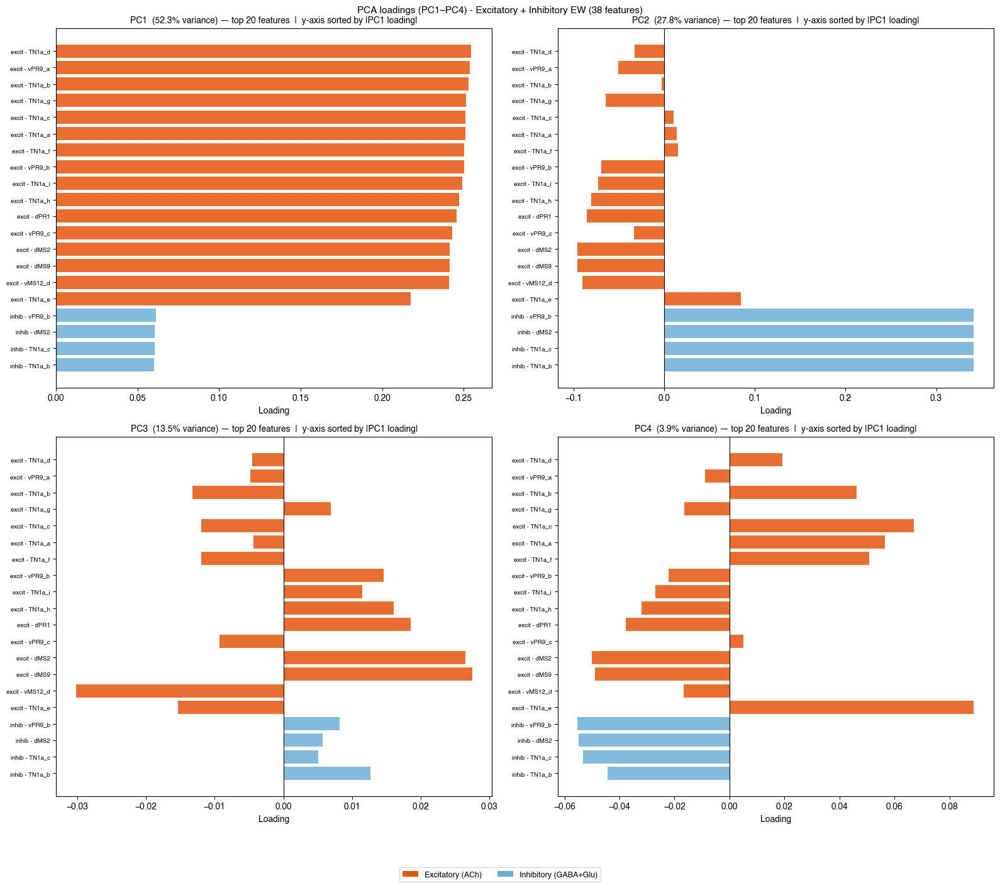

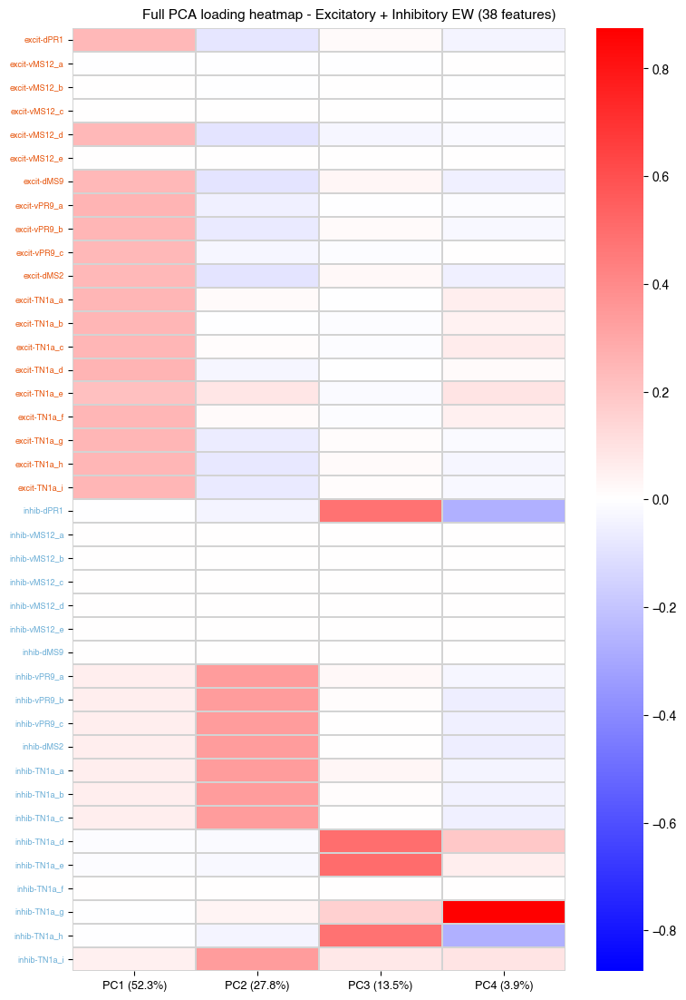

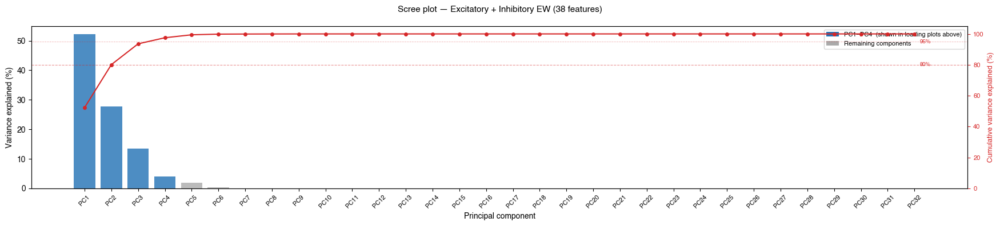

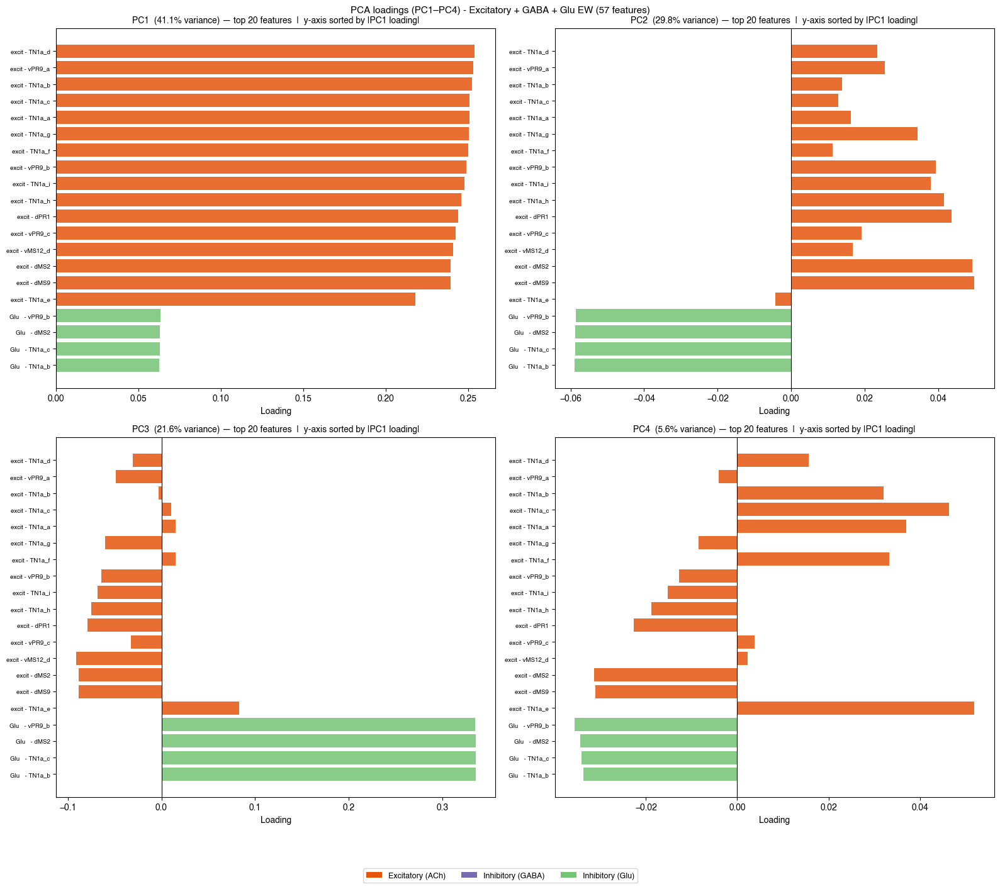

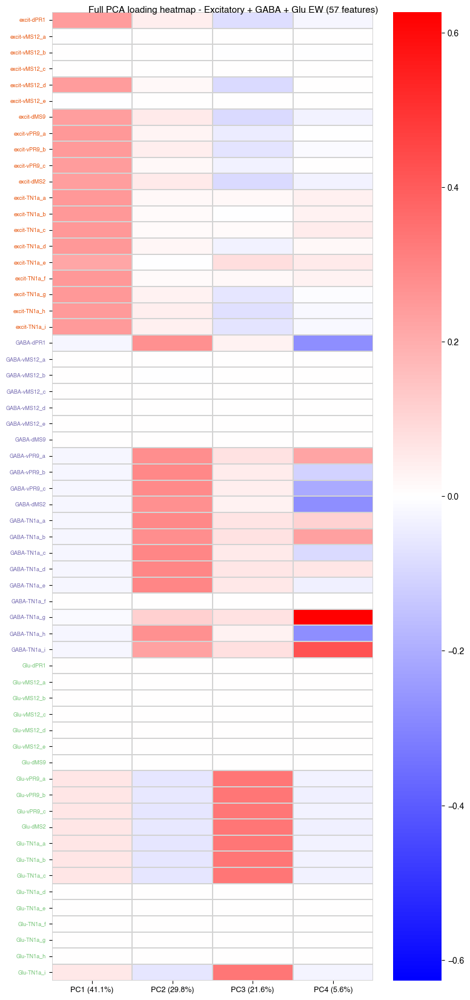

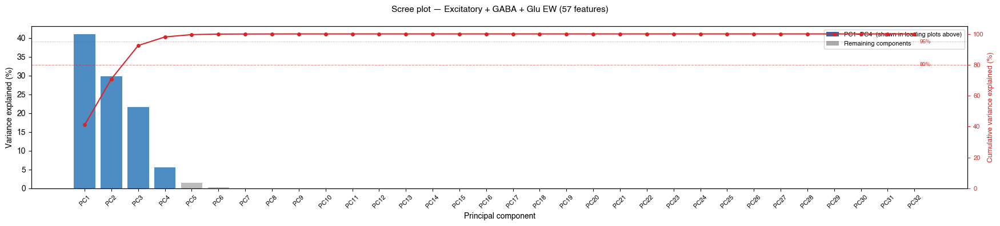

In [82]:
# ── PC1 / PC2 loading plots for both clustering analyses ─────────────────────
# For each analysis: (1) top-20 bar charts per PC; (2) full loading heatmap.

def _plot_loadings(X_sc, feature_names, feat_colors, analysis_label, fname_stem):
    """Bar charts + heatmap of PCA loadings for PC1 and PC2."""
    from sklearn.decomposition import PCA as _PCA
    _n_scree = min(X_sc.shape[0] - 1, X_sc.shape[1])  # max meaningful components
    _pca = _PCA(n_components=_n_scree)
    _pca.fit(X_sc)

    _top_n = 20

    # ── Figure A: 2×2 bar charts for PC1–PC4 ─────────────────────────────────
    _n_bar_pcs = min(4, _pca.n_components_)
    fig, axes  = plt.subplots(2, 2, figsize=(16, 14))
    axes_flat  = axes.flatten()
    for _ax_hide in axes_flat[_n_bar_pcs:]:
        _ax_hide.set_visible(False)
    # Canonical y-axis order: top-_top_n features by |PC1 loading|, fixed for all panels
    _pc1_abs    = np.abs(_pca.components_[0])
    _feat_ord   = np.argsort(_pc1_abs)[::-1][:_top_n]   # indices high→low
    _ord_feats  = [feature_names[i] for i in _feat_ord]
    _ord_cols   = [feat_colors[i]   for i in _feat_ord]

    for ax, pc_idx in zip(axes_flat, range(_n_bar_pcs)):
        _var_pct  = _pca.explained_variance_ratio_[pc_idx] * 100
        _load_map = dict(zip(feature_names, _pca.components_[pc_idx]))
        _load_df  = pd.DataFrame({
            'feature': _ord_feats,
            'loading': [_load_map[f] for f in _ord_feats],
            'color':   _ord_cols,
        }).iloc[::-1]   # reverse → PC1-top feature at top of barh

        ax.barh(range(len(_load_df)), _load_df['loading'],
                color=_load_df['color'], edgecolor='none', alpha=0.85)
        ax.set_yticks(range(len(_load_df)))
        ax.set_yticklabels(
            [f.replace('pos_ew_',  'excit - ')
              .replace('neg_ew_',  'inhib - ')
              .replace('gaba_ew_', 'GABA  - ')
              .replace('glu_ew_',  'Glu   - ')
             for f in _load_df['feature']],
            fontsize=7)
        ax.axvline(0, color='black', lw=0.8)
        ax.set_xlabel('Loading', fontsize=10)
        ax.set_title(
            f'PC{pc_idx+1}  ({_var_pct:.1f}% variance) '
            f'— top {_top_n} features  |  y-axis sorted by |PC1 loading|',
            fontsize=10)

    # Legend for feature types
    from matplotlib.patches import Patch
    _seen = {}
    _leg_handles = []
    for feat, col in zip(feature_names, feat_colors):
        _ftype = feat.split('_ew_')[0] + '_ew'
        if _ftype not in _seen:
            _seen[_ftype] = col
            _label = {'pos_ew': 'Excitatory (ACh)',
                      'neg_ew': 'Inhibitory (GABA+Glu)',
                      'gaba_ew': 'Inhibitory (GABA)',
                      'glu_ew':  'Inhibitory (Glu)'}.get(_ftype, _ftype)
            _leg_handles.append(Patch(facecolor=col, label=_label))
    fig.legend(handles=_leg_handles, loc='lower center', ncol=len(_leg_handles),
               fontsize=9, bbox_to_anchor=(0.5, -0.02), frameon=True)

    fig.suptitle(f'PCA loadings (PC1–PC4) - {analysis_label}', fontsize=11)
    fig.tight_layout(rect=[0, 0.04, 1, 1])
    matplotlib.rcParams['svg.fonttype'] = 'none'  # ensure editable text
    fig.savefig(RESULTS_DIR / f'{fname_stem}_loadings_bar.svg', bbox_inches='tight')
    plt.show()

    # ── Figure B: full loading heatmap (all features x PC1..PC_n) ────────────
    _n_pcs    = min(4, _pca.n_components_)
    _load_mat = pd.DataFrame(
        _pca.components_[:_n_pcs].T,
        index=[f.replace('pos_ew_',  'excit-')
                .replace('neg_ew_',  'inhib-')
                .replace('gaba_ew_', 'GABA-')
                .replace('glu_ew_',  'Glu-')
               for f in feature_names],
        columns=[f'PC{i+1} ({_pca.explained_variance_ratio_[i]*100:.1f}%)'
                 for i in range(_n_pcs)],
    )
    _abs_max = np.abs(_load_mat.values).max()

    fig2, ax2 = plt.subplots(figsize=(3 + _n_pcs * 1.2,
                                      max(8, len(feature_names) * 0.28)))
    sns.heatmap(_load_mat, ax=ax2, cmap=BWR_CMAP,  center=0,
                vmin=-_abs_max, vmax=_abs_max,
                linewidths=0.2, linecolor='lightgray',
                yticklabels=True, xticklabels=True)
    ax2.tick_params(axis='y', labelsize=6.5)
    ax2.tick_params(axis='x', labelsize=9)

    # Colour the y-tick labels by feature type
    for tick_label in ax2.get_yticklabels():
        _txt = tick_label.get_text()
        if _txt.startswith('excit'):
            tick_label.set_color('#e6550d')
        elif _txt.startswith('GABA'):
            tick_label.set_color('#756bb1')
        elif _txt.startswith('Glu'):
            tick_label.set_color('#74c476')
        else:
            tick_label.set_color('#6baed6')

    fig2.suptitle(f'Full PCA loading heatmap - {analysis_label}', fontsize=11)
    fig2.tight_layout()
    fig2.savefig(RESULTS_DIR / f'{fname_stem}_loadings_heatmap.pdf', bbox_inches='tight')
    fig2.savefig(RESULTS_DIR / f'{fname_stem}_loadings_heatmap.svg', bbox_inches='tight')
    plt.show()

    # ── Figure C: scree plot ──────────────────────────────────────────────────
    _ev    = _pca.explained_variance_ratio_ * 100
    _cumev = np.cumsum(_ev)
    _n_pl  = len(_ev)
    _n_sel = min(4, _n_pl)   # PCs highlighted in loading bar / heatmap figures

    fig3, ax3 = plt.subplots(figsize=(max(6, _n_pl * 0.55), 4))

    _bar_cols3 = ['#2171b5'] * _n_sel + ['#aaaaaa'] * (_n_pl - _n_sel)
    ax3.bar(range(1, _n_pl + 1), _ev, color=_bar_cols3,
            edgecolor='none', alpha=0.8, zorder=2)

    ax3b = ax3.twinx()
    ax3b.plot(range(1, _n_pl + 1), _cumev, 'o-',
              color='#d62728', lw=1.5, ms=4, zorder=5)
    ax3b.axhline(80, color='#d62728', lw=0.8, ls='--', alpha=0.5)
    ax3b.axhline(95, color='#d62728', lw=0.8, ls=':',  alpha=0.5)
    ax3b.text(_n_pl + 0.2, 80, '80%', fontsize=7, color='#d62728', va='center')
    ax3b.text(_n_pl + 0.2, 95, '95%', fontsize=7, color='#d62728', va='center')
    ax3b.set_ylim(0, 105)
    ax3b.set_ylabel('Cumulative variance explained (%)', fontsize=9,
                    color='#d62728')
    ax3b.tick_params(axis='y', colors='#d62728', labelsize=8)

    ax3.set_xlabel('Principal component', fontsize=10)
    ax3.set_ylabel('Variance explained (%)', fontsize=10)
    ax3.set_xticks(range(1, _n_pl + 1))
    ax3.set_xticklabels(
        [f'PC{i}' for i in range(1, _n_pl + 1)],
        rotation=45 if _n_pl > 8 else 0, fontsize=8)

    from matplotlib.patches import Patch as _PatchScree
    ax3.legend(handles=[
        _PatchScree(facecolor='#2171b5',
                    label=f'PC1–PC{_n_sel}  (shown in loading plots above)'),
        _PatchScree(facecolor='#aaaaaa', label='Remaining components'),
    ], fontsize=8, loc='upper right')

    fig3.suptitle(f'Scree plot — {analysis_label}', fontsize=11)
    fig3.tight_layout()
    matplotlib.rcParams['svg.fonttype'] = 'none'
    fig3.savefig(RESULTS_DIR / f'{fname_stem}_scree.pdf', bbox_inches='tight')
    fig3.savefig(RESULTS_DIR / f'{fname_stem}_scree.svg', bbox_inches='tight')
    plt.show()


# ── Analysis A: pos_ew + |neg_ew| ────────────────────────────────────────────
_pos_feats_a = [f'pos_ew_{pm}'  for pm in PREMOTOR_TARGETS]
_neg_feats_a = [f'neg_ew_{pm}'  for pm in PREMOTOR_TARGETS]
_feats_a     = _pos_feats_a + _neg_feats_a
_colors_a    = (['#e6550d'] * len(_pos_feats_a) +
                ['#6baed6'] * len(_neg_feats_a))

_X_a = np.hstack([_df_cl[_pos_feats_a].values,
                  _df_cl[_neg_feats_a].abs().values])
_X_a_sc = StandardScaler().fit_transform(_X_a)

_plot_loadings(_X_a_sc, _feats_a, _colors_a,
               'Excitatory + Inhibitory EW (38 features)',
               'clustering_excit_inhib')

# ── Analysis B: pos_ew + gaba_ew + glu_ew ────────────────────────────────────
_pos_feats_b  = [f'pos_ew_{pm}'  for pm in PREMOTOR_TARGETS]
_gaba_feats_b = [f'gaba_ew_{pm}' for pm in PREMOTOR_TARGETS]
_glu_feats_b  = [f'glu_ew_{pm}'  for pm in PREMOTOR_TARGETS]
_feats_b      = _pos_feats_b + _gaba_feats_b + _glu_feats_b
_colors_b     = (['#e6550d'] * len(_pos_feats_b) +
                 ['#756bb1'] * len(_gaba_feats_b) +
                 ['#74c476'] * len(_glu_feats_b))

_X_b = np.hstack([_df_cl[_pos_feats_b].values,
                  _df_cl[_gaba_feats_b].values,
                  _df_cl[_glu_feats_b].values])
_X_b_sc = StandardScaler().fit_transform(_X_b)

_plot_loadings(_X_b_sc, _feats_b, _colors_b,
               'Excitatory + GABA + Glu EW (57 features)',
               'clustering_excit_gaba_glu')

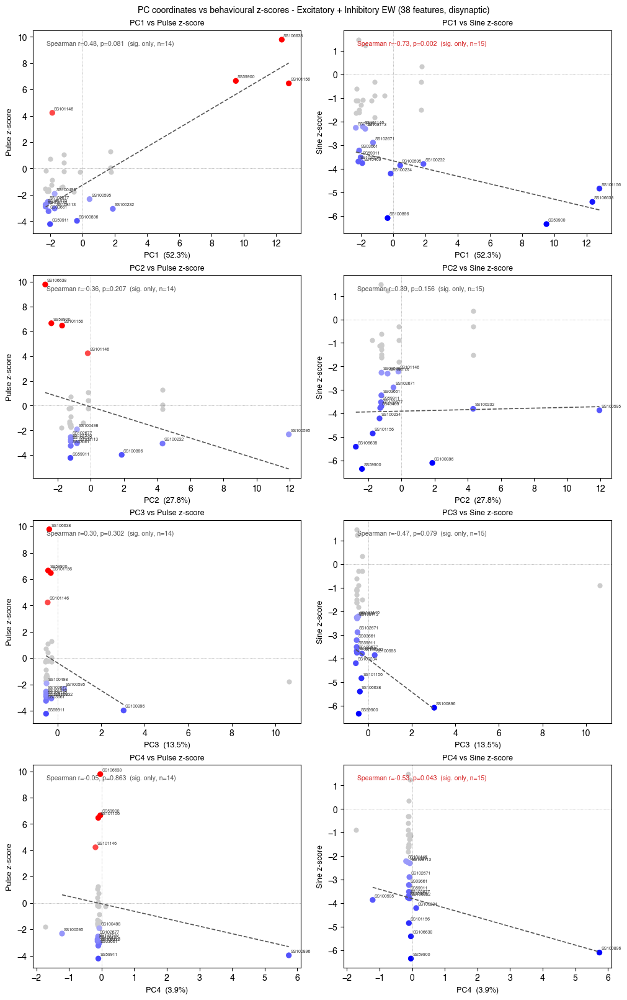

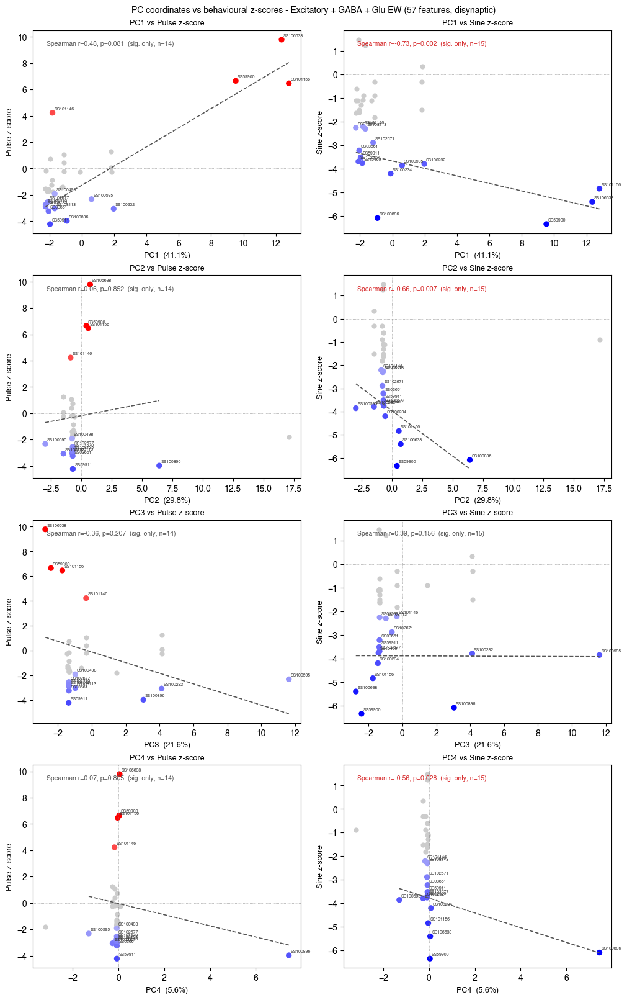

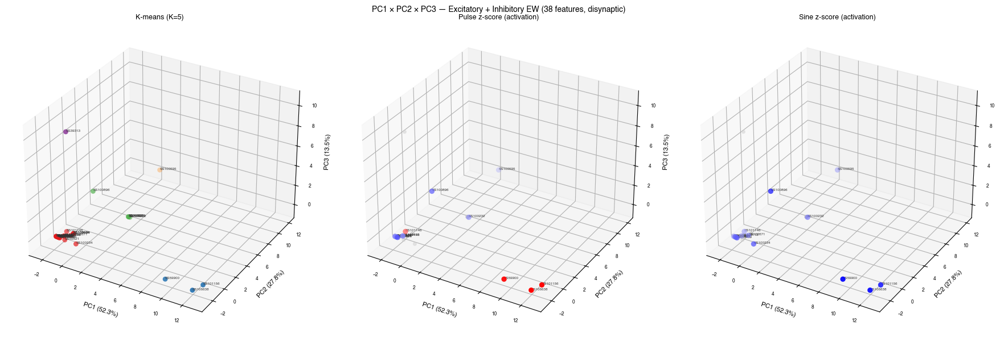

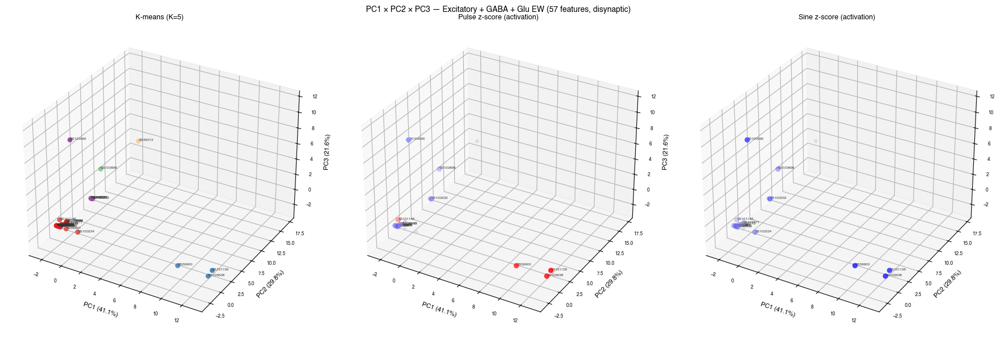

In [83]:
# ── PC vs behavioural z-score scatters — Section 8 (disynaptic) ────────────
_plot_pc_beh_scatter(_X_a_sc, _df_cl,
    'Excitatory + Inhibitory EW (38 features, disynaptic)',
    'clustering_excit_inhib')
_plot_pc_beh_scatter(_X_b_sc, _df_cl,
    'Excitatory + GABA + Glu EW (57 features, disynaptic)',
    'clustering_excit_gaba_glu')

# ── 3D PC scatter — Section 8 (disynaptic) ──────────────────────────────────
_plot_pca_3d(_X_a_sc, _df_cl,
    'Excitatory + Inhibitory EW (38 features, disynaptic)',
    'clustering_excit_inhib', force_k=FORCE_K)
_plot_pca_3d(_X_b_sc, _df_cl,
    'Excitatory + GABA + Glu EW (57 features, disynaptic)',
    'clustering_excit_gaba_glu', force_k=FORCE_K)

## Section 9: Clustering Analysis — Combined Disynaptic + Trisynaptic Paths

Same analyses as Section 8, but using per-premotor-target EW from both 2-hop and 3-hop paths (`ss_ew_pt_combined`).

**Analysis A** — 38 features: excitatory EW + inhibitory EW per premotor type (2 × 19).

**Analysis B** — 57 features: excitatory EW + GABA EW + Glu EW per premotor type (3 × 19).  
GABA/Glu for trisynaptic paths classified by the second interneuron (inter2) NT.

In [84]:
# ── Merge combined-path EW table with behavioral data ────────────────────────
_df_cl_comb = ss_ew_pt_combined.merge(
    beh[['LineName', 'Pulse_Transient', 'Sine_Transient',
         'Pulse_pval_Transient', 'Sine_pval_Transient']],
    on='LineName')
_df_cl_comb['pulse_sig'] = _df_cl_comb['Pulse_pval_Transient'].abs() < 0.05
_df_cl_comb['sine_sig']  = _df_cl_comb['Sine_pval_Transient'].abs()  < 0.05

# ── GABA / Glu EW per (src_type, premotor_type) — disynaptic component ───────
_gaba_pm_2 = (
    merged_all[merged_all['inter_nt'] == 'gaba']
    .groupby(['src_type', 'premotor_type'])['path_ew'].sum()
    .to_dict()
)
_glu_pm_2 = (
    merged_all[merged_all['inter_nt'] == 'glutamate']
    .groupby(['src_type', 'premotor_type'])['path_ew'].sum()
    .to_dict()
)

# ── GABA / Glu EW per (src_type, premotor_type) — trisynaptic component ──────
# Classify inhibitory trisynaptic paths by second interneuron (inter2) NT
_gaba_pm_3 = {}
_glu_pm_3  = {}
if 'merged_3a' in vars():
    _inter2_nt_9 = merged_3a['inter2_type'].map(type_to_nt).fillna('other')
    _gaba_pm_3 = (
        merged_3a[(merged_3a['signed_path_ew'] < 0) & (_inter2_nt_9 == 'gaba')]
        .groupby(['src_type', 'premotor_type'])['path_ew'].sum()
        .to_dict()
    )
    _glu_pm_3 = (
        merged_3a[(merged_3a['signed_path_ew'] < 0) & (_inter2_nt_9 == 'glutamate')]
        .groupby(['src_type', 'premotor_type'])['path_ew'].sum()
        .to_dict()
    )

# ── Combine disynaptic + trisynaptic GABA/Glu per SS line x premotor ─────────
_rows_nt_comb = []
for _, row in beh.iterrows():
    types = parse_pC1_types(str(row['CellType']))
    if not types:
        continue
    entry = {'LineName': row['LineName']}
    for pm_grp, pm_subs in PREMOTOR_GROUPS.items():
        entry[f'gaba_ew_{pm_grp}'] = sum(
            _gaba_pm_2.get((t, sub), 0.) + _gaba_pm_3.get((t, sub), 0.)
            for t in types for sub in pm_subs)
        entry[f'glu_ew_{pm_grp}']  = sum(
            _glu_pm_2.get((t, sub),  0.) + _glu_pm_3.get((t, sub),  0.)
            for t in types)
    _rows_nt_comb.append(entry)

_nt_pm_comb = pd.DataFrame(_rows_nt_comb)
_df_cl_comb = _df_cl_comb.merge(_nt_pm_comb, on='LineName')

print(f'{len(_df_cl_comb)} SS lines ready for clustering (combined paths)')

33 SS lines ready for clustering (combined paths)



Silhouette t-tests (H₀: mean=0, one-sided)  —  Excitatory + Inhibitory EW (38 features)  (disynaptic + trisynaptic):
    K  mean sil        t          p  sig
    2     0.735    31.26    0.00000  ***
    3     0.623    21.39    0.00000  ***
    4     0.515    14.27    0.00000  ***
    5     0.544    16.33    0.00000  ***
    6     0.563    14.09    0.00000  ***
    7     0.542    12.69    0.00000  ***
    8     0.449     9.52    0.00000  ***


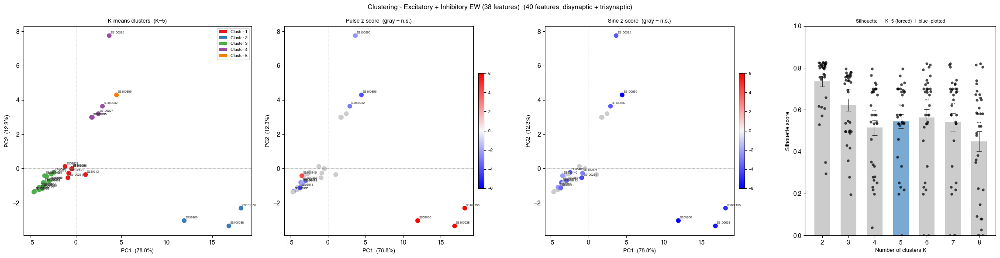

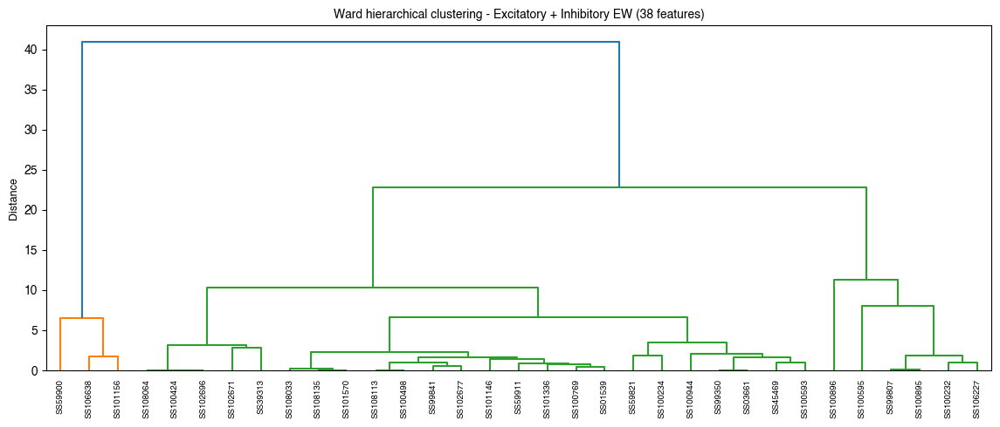

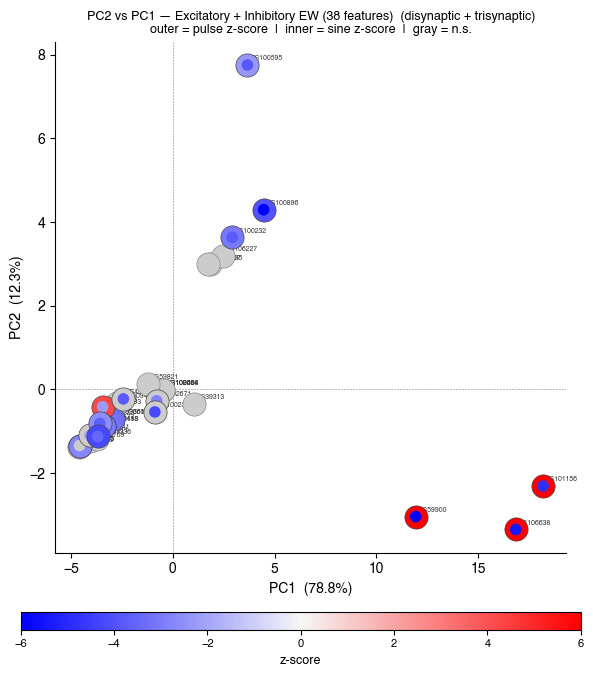

Interactive plot saved → clustering_combined_excit_inhib_pca_zscore_interactive.html


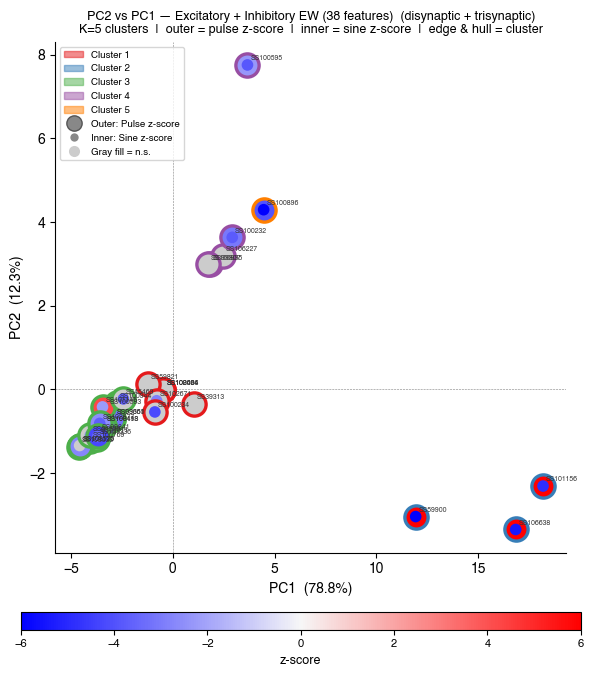


Cluster assignments — Excitatory + Inhibitory EW (38 features)  (disynaptic + trisynaptic):


,LineName,Cluster,Sil_Score,Pulse_Transient,Sine_Transient
0,SS100424,1,0.575182,0.425444,-0.886712
1,SS102696,1,0.575182,1.076156,-1.809562
2,SS108064,1,0.575182,-0.213571,-0.303228
3,SS39313,1,0.460309,-1.780260,-0.884367
4,SS102671,1,0.331117,-1.385192,-2.887090
5,SS100234,1,0.230114,-0.246399,-4.204242
6,SS59821,1,0.197545,-1.416699,-1.110792
7,SS106638,2,0.796111,9.788413,-5.406706
8,SS101156,2,0.763811,6.468442,-4.842355
9,SS59900,2,0.536066,6.655034,-6.348842


In [85]:
# ── Analysis A: Excitatory + Inhibitory EW (38 features) — combined paths ────
# Each feature type scaled independently: excit block and inhib block
# separately standardised, preserving relative importance between NT classes.
_pos_feats_c = [f'pos_ew_{pm}' for pm in PREMOTOR_TARGETS]
_neg_feats_c = [f'neg_ew_{pm}' for pm in PREMOTOR_TARGETS]

_X_ca_sc = np.hstack([
    StandardScaler().fit_transform(_df_cl_comb[_pos_feats_c].values),
    StandardScaler().fit_transform(_df_cl_comb[_neg_feats_c].abs().values),
])

_plot_analysis(
    _X_ca_sc,
    'Excitatory + Inhibitory EW (38 features)',
    _df_cl_comb,
    'clustering_combined_excit_inhib',
    path_label='disynaptic + trisynaptic',
    force_k=FORCE_K,
)


Silhouette t-tests (H₀: mean=0, one-sided)  —  Excitatory + GABA + Glu EW (57 features)  (disynaptic + trisynaptic):
    K  mean sil        t          p  sig
    2     0.734    42.29    0.00000  ***
    3     0.534    18.43    0.00000  ***
    4     0.562    13.02    0.00000  ***
    5     0.606    17.41    0.00000  ***
    6     0.628    14.35    0.00000  ***
    7     0.640    15.27    0.00000  ***
    8     0.614    13.47    0.00000  ***


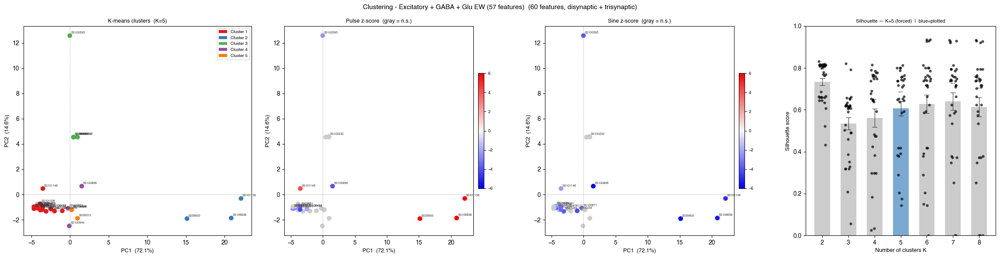

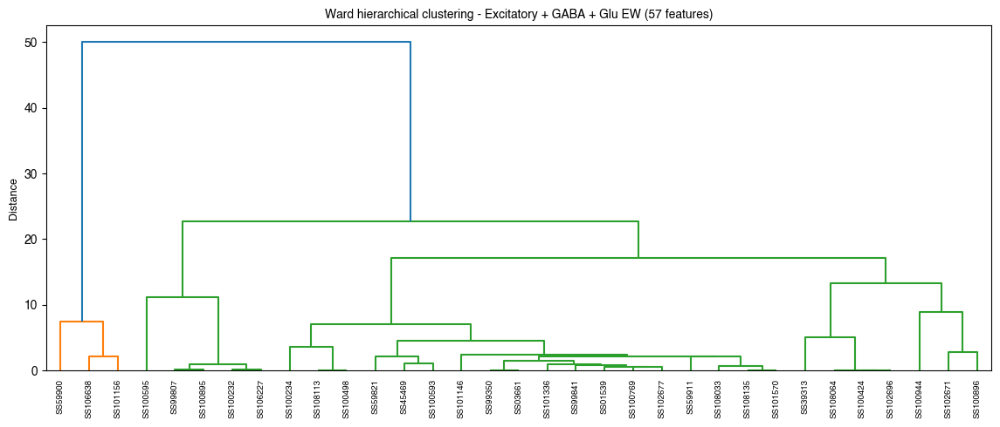

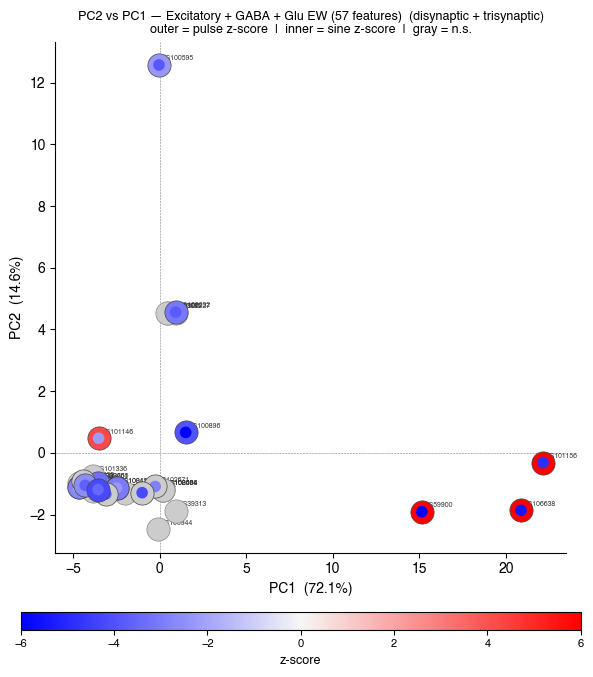

Interactive plot saved → clustering_combined_excit_gaba_glu_pca_zscore_interactive.html


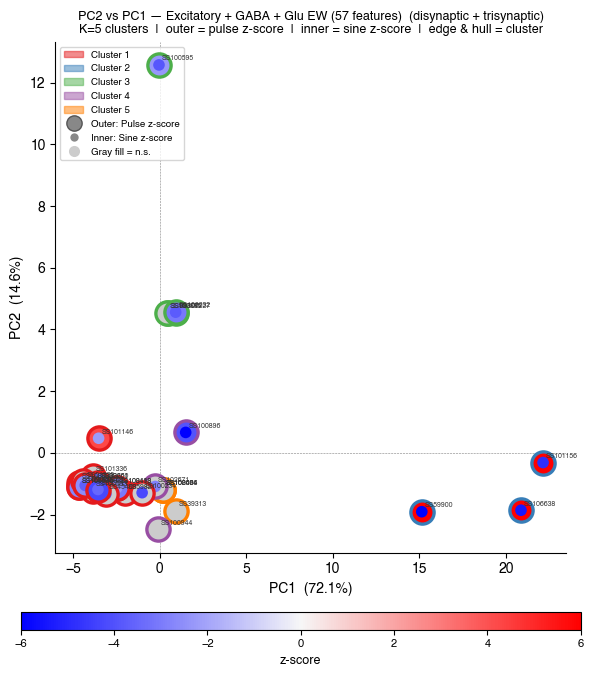


Cluster assignments — Excitatory + GABA + Glu EW (57 features)  (disynaptic + trisynaptic):


,LineName,Cluster,Sil_Score,Pulse_Transient,Sine_Transient
0,SS100769,1,0.765524,0.735046,-1.283454
1,SS102677,1,0.758654,-2.537946,-3.690735
2,SS01539,1,0.757712,-1.510278,-2.259955
3,SS101336,1,0.747888,-0.867867,-1.068661
4,SS108033,1,0.745067,-0.155461,-0.606917
5,SS99841,1,0.740721,-1.700832,-1.499713
6,SS108135,1,0.738479,-2.892074,-1.108433
7,SS101570,1,0.738479,-2.748687,-1.626315
8,SS99350,1,0.716854,-1.678569,-1.605630
9,SS03661,1,0.716854,-3.242428,-3.223896


In [86]:
# ── Analysis B: Excitatory + GABA + Glu EW (57 features) — combined paths ────
# Each NT class scaled independently: excit, GABA, and Glu blocks
# separately standardised, preserving relative importance between NT classes.
_pos_feats_cb  = [f'pos_ew_{pm}'  for pm in PREMOTOR_TARGETS]
_gaba_feats_cb = [f'gaba_ew_{pm}' for pm in PREMOTOR_TARGETS]
_glu_feats_cb  = [f'glu_ew_{pm}'  for pm in PREMOTOR_TARGETS]

_X_cb_sc = np.hstack([
    StandardScaler().fit_transform(_df_cl_comb[_pos_feats_cb].values),
    StandardScaler().fit_transform(_df_cl_comb[_gaba_feats_cb].values),
    StandardScaler().fit_transform(_df_cl_comb[_glu_feats_cb].values),
])

_plot_analysis(
    _X_cb_sc,
    'Excitatory + GABA + Glu EW (57 features)',
    _df_cl_comb,
    'clustering_combined_excit_gaba_glu',
    path_label='disynaptic + trisynaptic',
    force_k=FORCE_K,
)

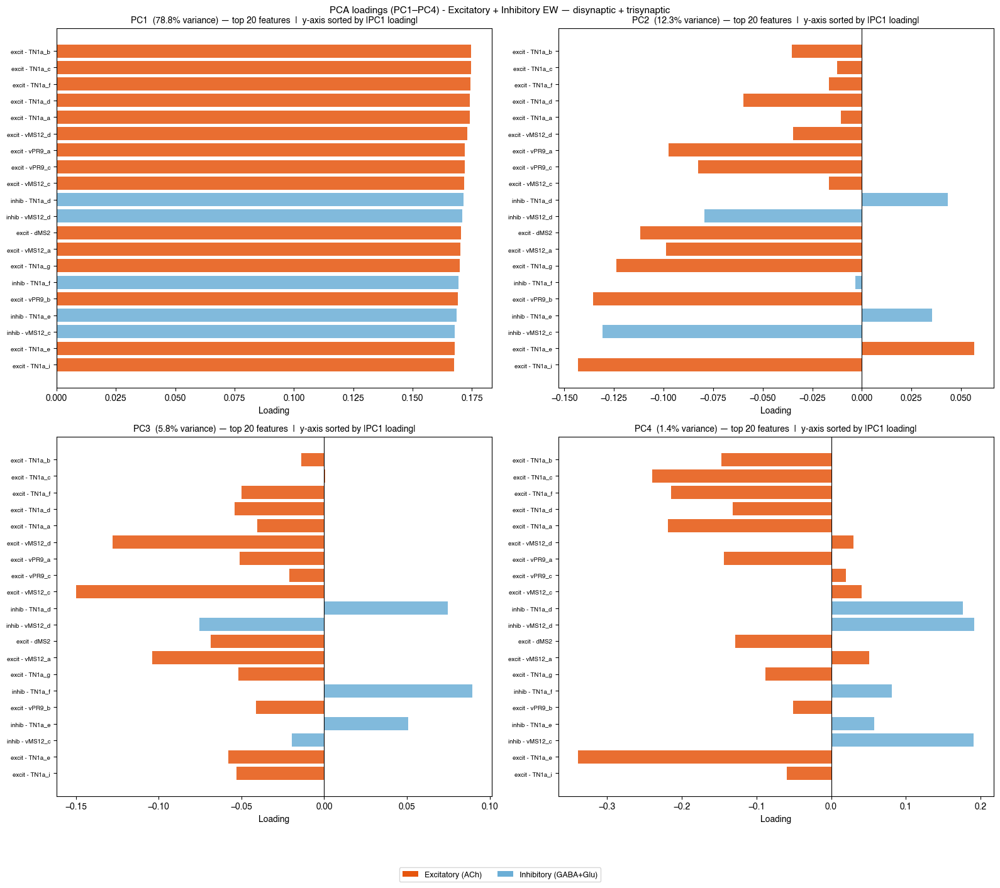

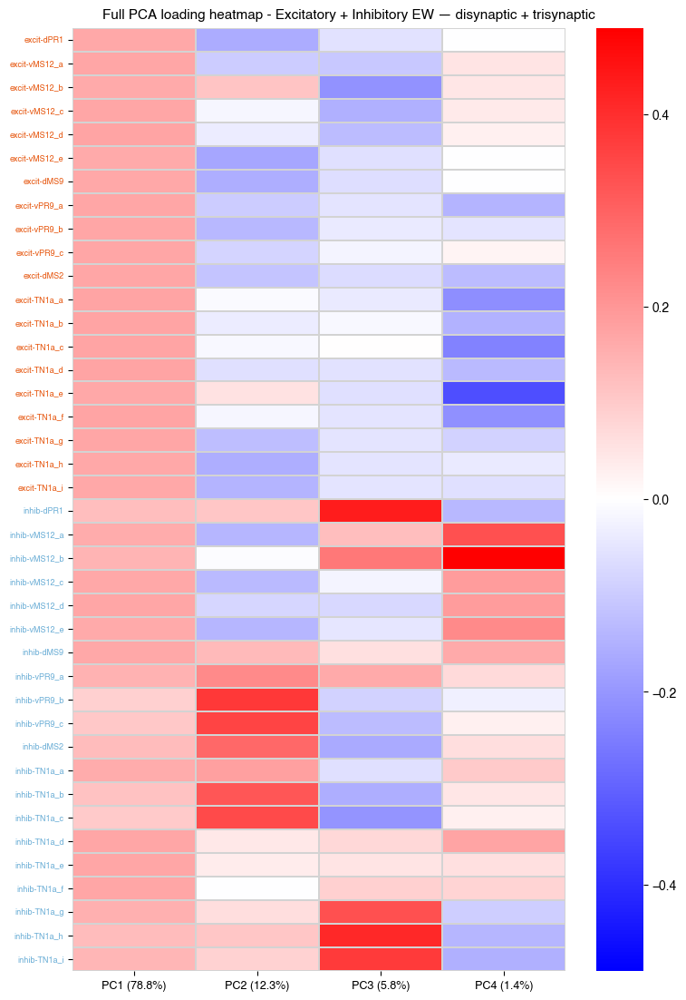

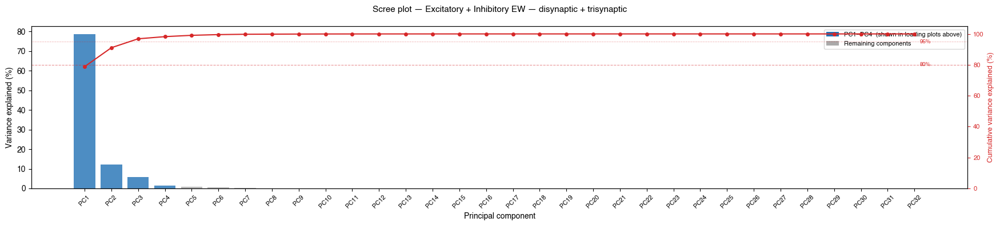

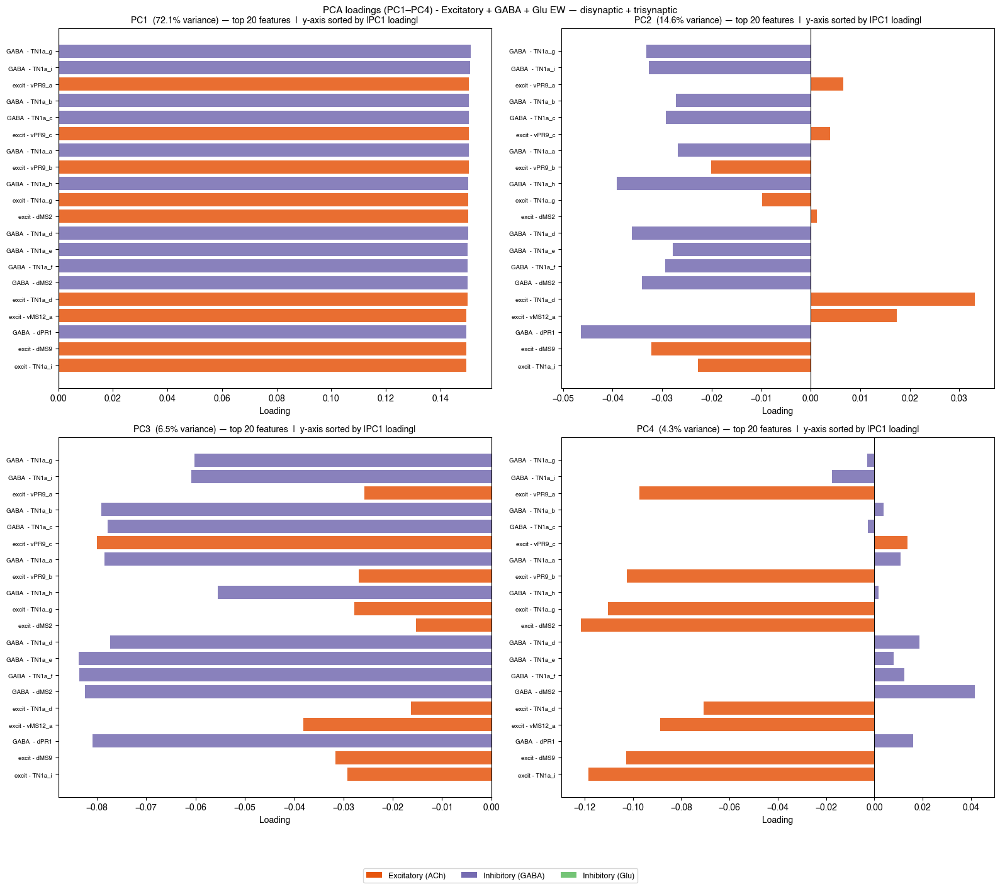

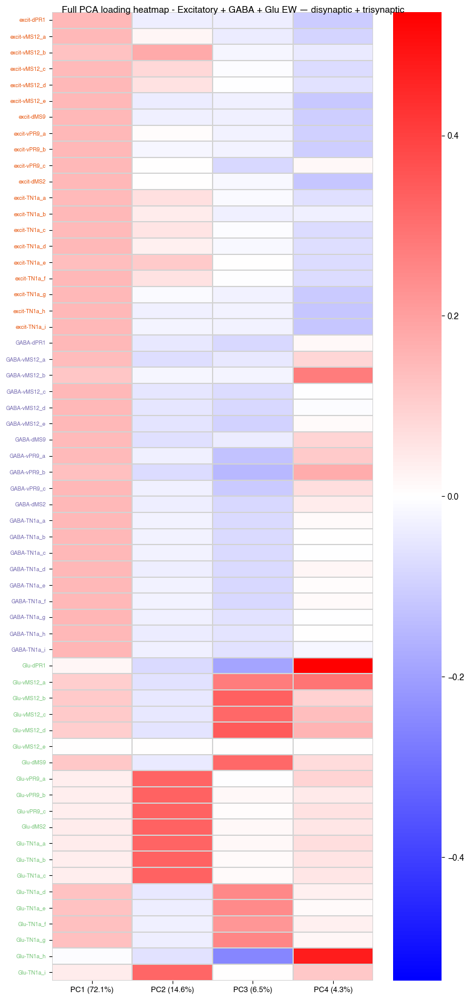

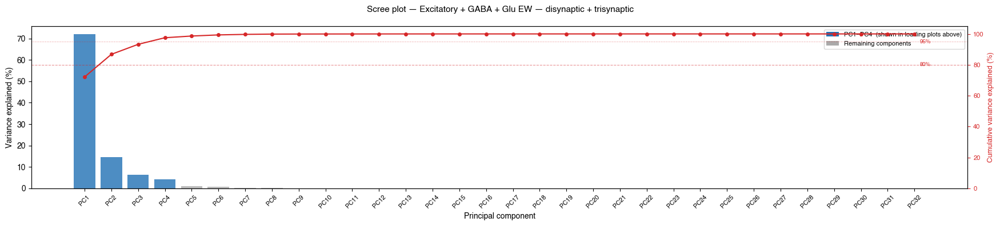

In [87]:
# ── PC1 / PC2 loading plots — combined paths ──────────────────────────────────
_feats_ca  = _pos_feats_c + _neg_feats_c
_colors_ca = (['#e6550d'] * len(_pos_feats_c) +
              ['#6baed6'] * len(_neg_feats_c))

_plot_loadings(_X_ca_sc, _feats_ca, _colors_ca,
               'Excitatory + Inhibitory EW — disynaptic + trisynaptic',
               'clustering_combined_excit_inhib')

_feats_cb  = _pos_feats_cb + _gaba_feats_cb + _glu_feats_cb
_colors_cb = (['#e6550d'] * len(_pos_feats_cb) +
              ['#756bb1'] * len(_gaba_feats_cb) +
              ['#74c476'] * len(_glu_feats_cb))

_plot_loadings(_X_cb_sc, _feats_cb, _colors_cb,
               'Excitatory + GABA + Glu EW — disynaptic + trisynaptic',
               'clustering_combined_excit_gaba_glu')

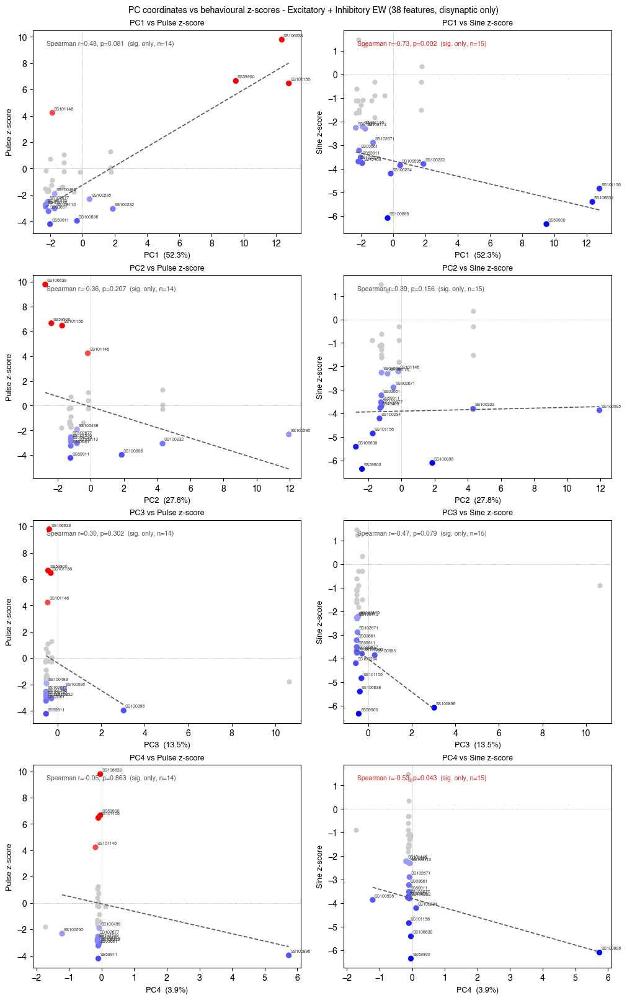

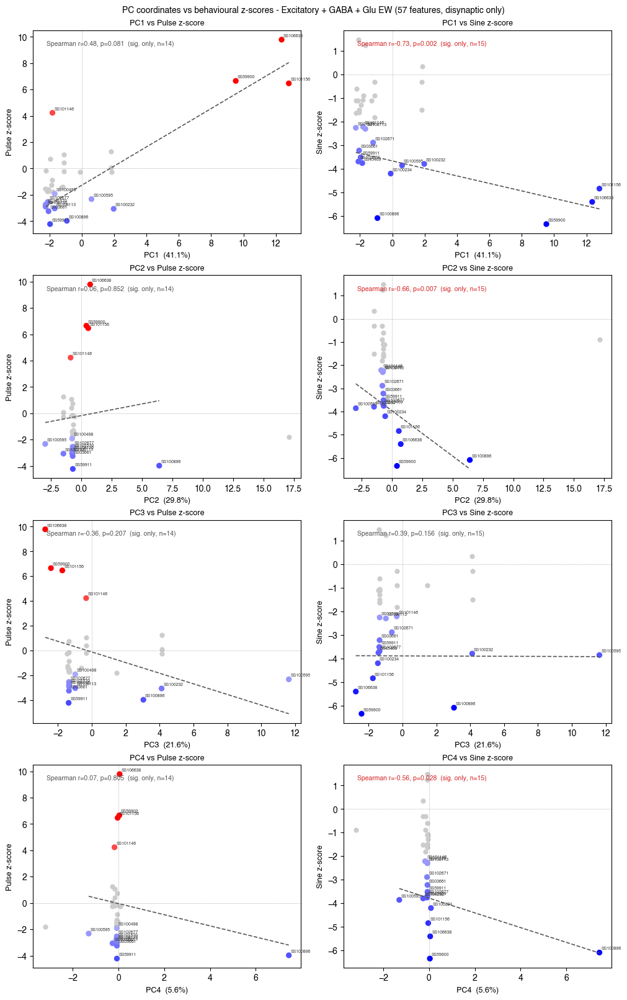

In [88]:
# ── PC vs behavioural z-score scatters — disynaptic only (comparison) ───────
# Same as Section 8 scatter but shown here alongside Section 9 combined results
# for direct comparison. Uses _X_a_sc / _X_b_sc and _df_cl (disynaptic data).
_plot_pc_beh_scatter(_X_a_sc, _df_cl,
    'Excitatory + Inhibitory EW (38 features, disynaptic only)',
    'clustering_excit_inhib')
_plot_pc_beh_scatter(_X_b_sc, _df_cl,
    'Excitatory + GABA + Glu EW (57 features, disynaptic only)',
    'clustering_excit_gaba_glu')

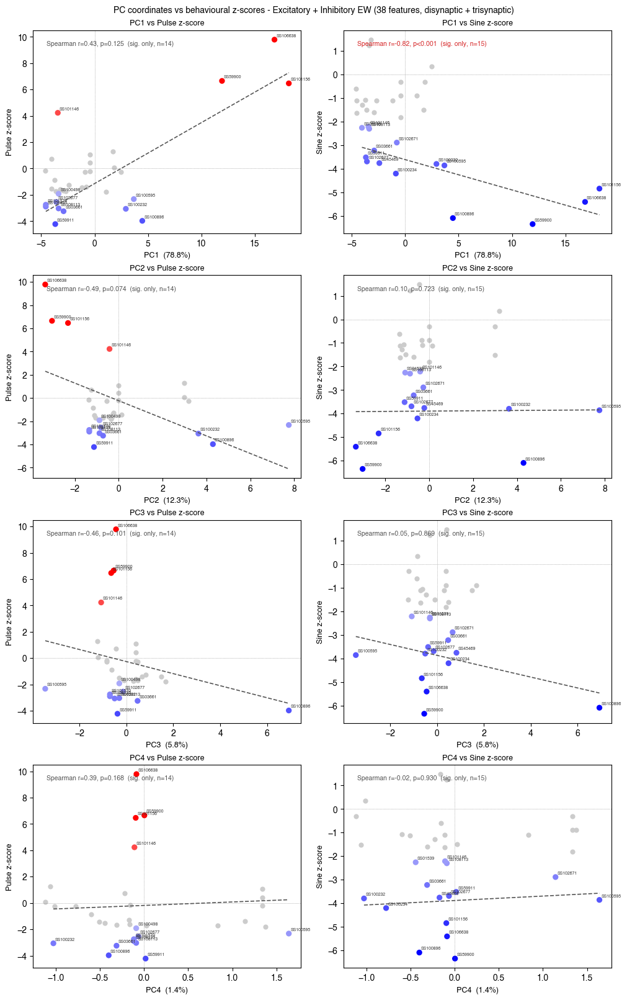

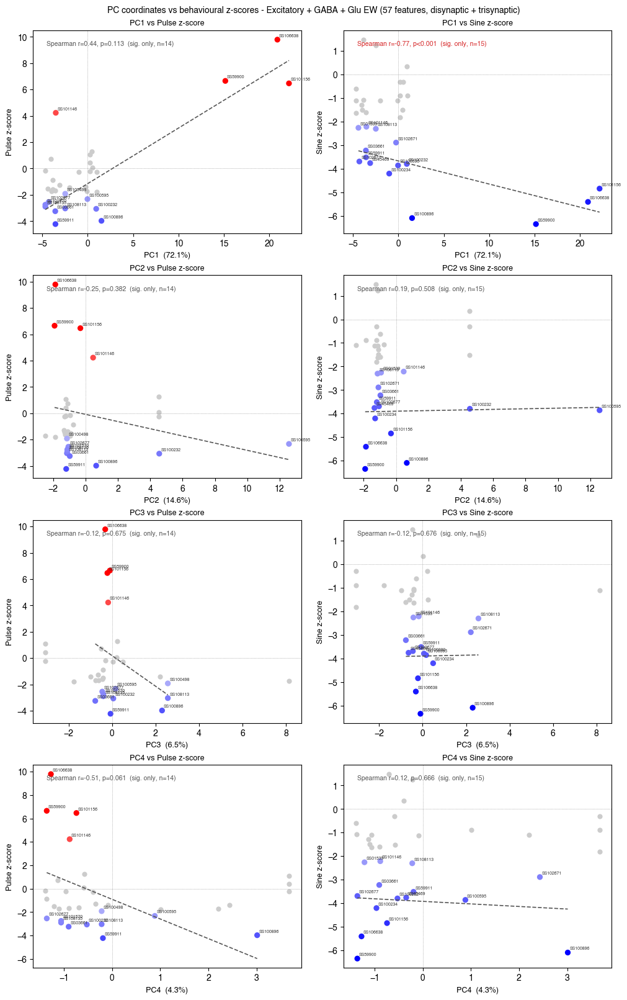

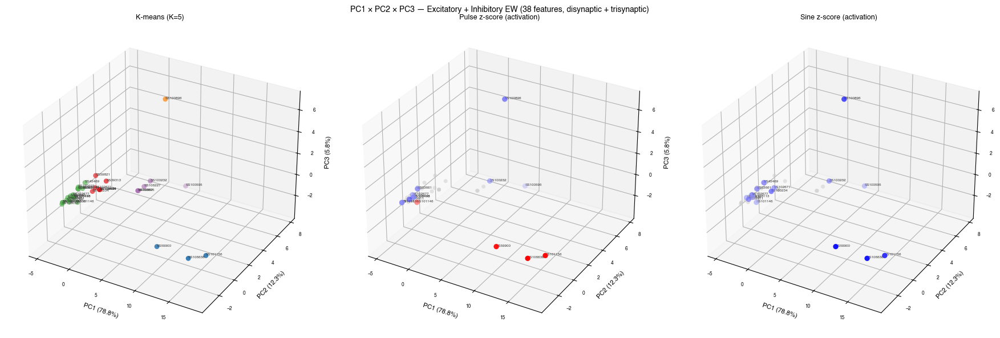

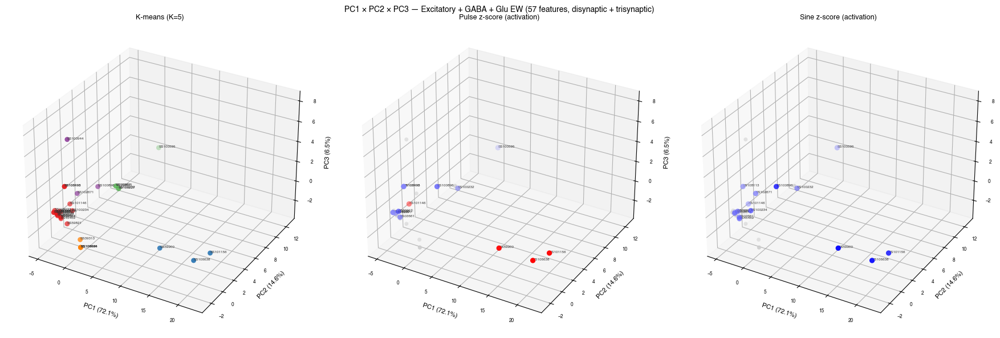

In [89]:
# ── PC vs behavioural z-score scatters — Section 9 (combined paths) ─────────
_plot_pc_beh_scatter(_X_ca_sc, _df_cl_comb,
    'Excitatory + Inhibitory EW (38 features, disynaptic + trisynaptic)',
    'clustering_combined_excit_inhib')
_plot_pc_beh_scatter(_X_cb_sc, _df_cl_comb,
    'Excitatory + GABA + Glu EW (57 features, disynaptic + trisynaptic)',
    'clustering_combined_excit_gaba_glu')

# ── 3D PC scatter — Section 9 (combined paths) ──────────────────────────────
_plot_pca_3d(_X_ca_sc, _df_cl_comb,
    'Excitatory + Inhibitory EW (38 features, disynaptic + trisynaptic)',
    'clustering_combined_excit_inhib', force_k=FORCE_K)
_plot_pca_3d(_X_cb_sc, _df_cl_comb,
    'Excitatory + GABA + Glu EW (57 features, disynaptic + trisynaptic)',
    'clustering_combined_excit_gaba_glu', force_k=FORCE_K)

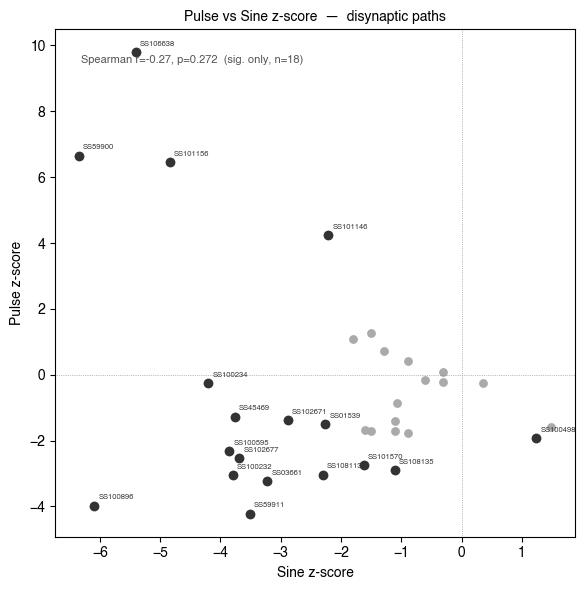

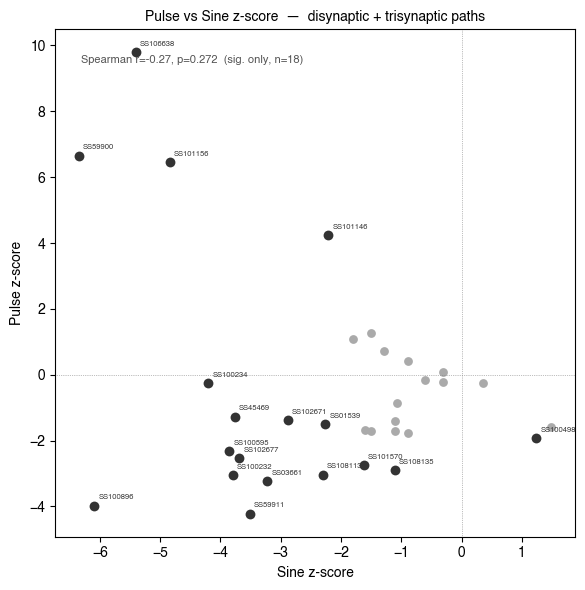

In [90]:
# ── Pulse z-score vs Sine z-score scatter — across all SS lines ─────────────
_plot_pulse_sine_scatter(
    _df_cl,
    'disynaptic paths',
    'pulse_vs_sine_disynaptic')
_plot_pulse_sine_scatter(
    _df_cl_comb,
    'disynaptic + trisynaptic paths',
    'pulse_vs_sine_combined')

## Section 10: Behavioural Z-score vs Total Unsigned EW

Scatter plots of Pulse and Sine z-scores against total unsigned EW per SS line
(excitatory EW + |inhibitory EW|, summed across all 19 premotor targets).
Regression and Spearman correlation computed on significant lines only (p < 0.05).
Shown for disynaptic paths and for combined disynaptic + trisynaptic paths.

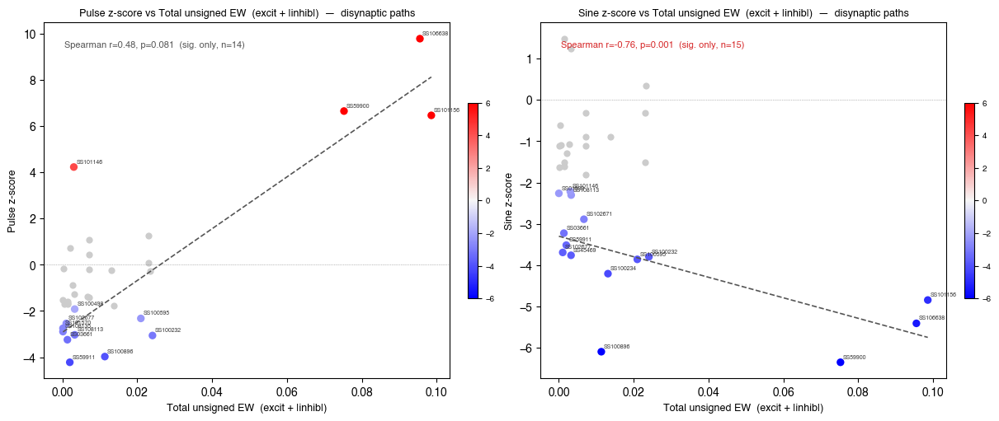

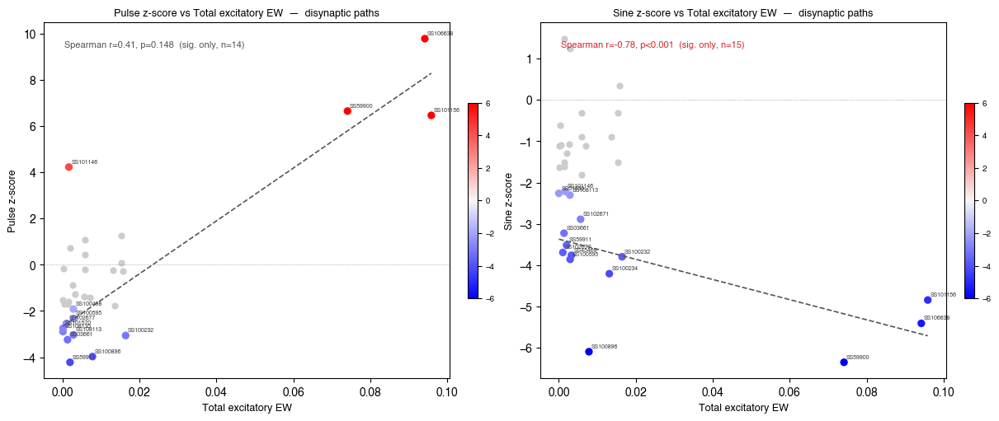

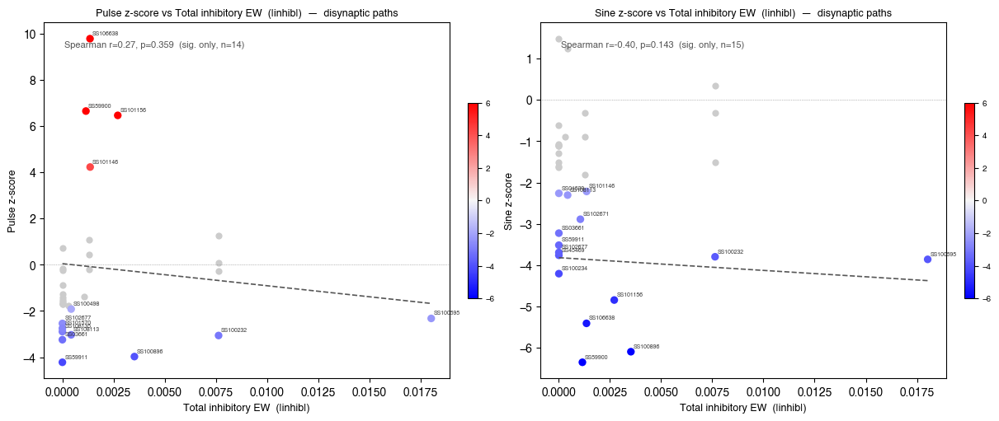

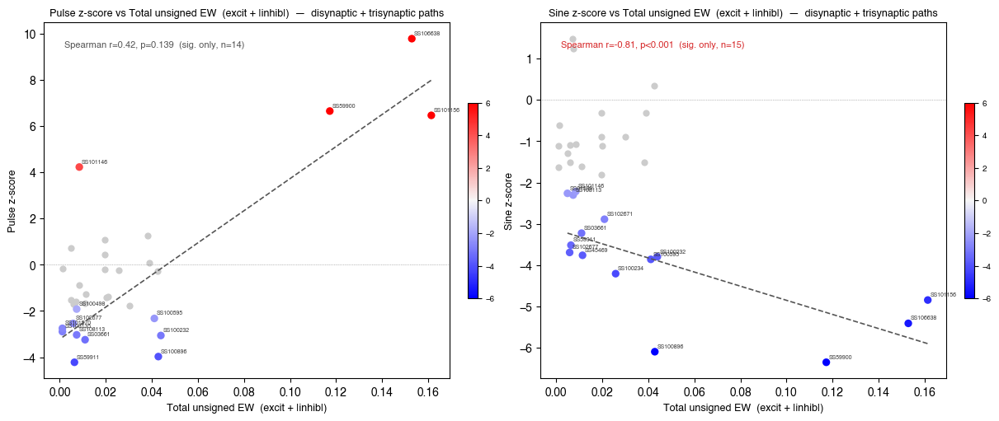

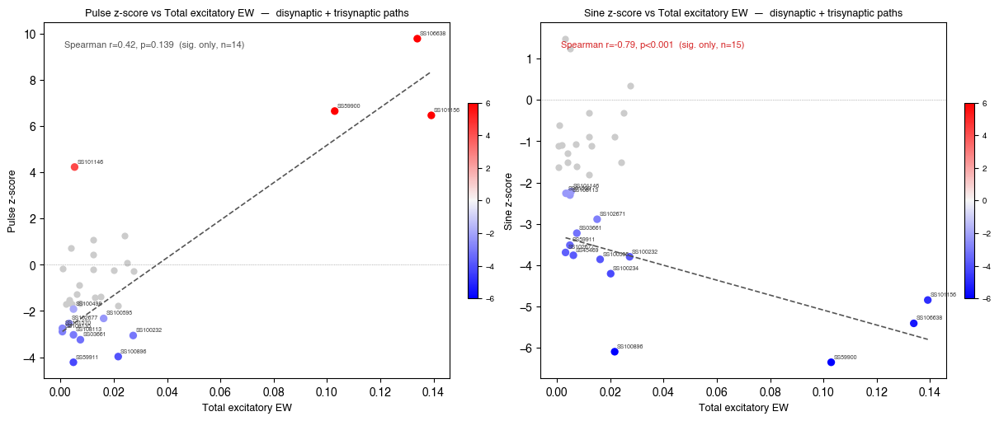

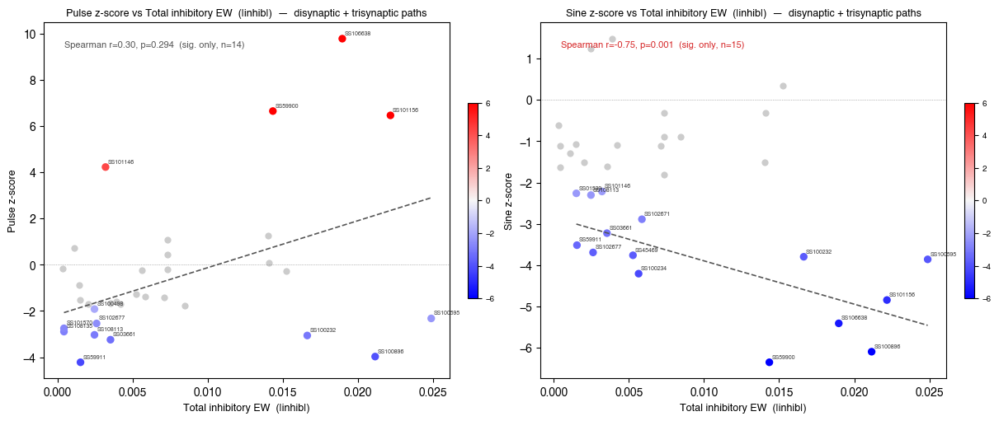

In [91]:
from scipy.stats import spearmanr as _spearmanr_ew

def _plot_ew_beh_scatter(df, ew_vals, ew_label, path_label, fname_stem):
    _beh_cols = [
        ('Pulse_Transient', 'pulse_sig', 'Pulse z-score'),
        ('Sine_Transient',  'sine_sig',  'Sine z-score'),
    ]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

    for ax, (beh_col, sig_col, beh_label) in zip(axes, _beh_cols):
        _y   = df[beh_col].values
        _sig = df[sig_col].values

        _pt_colors = _beh_colors(_y, _sig)
        ax.scatter(ew_vals[~_sig], _y[~_sig],
                   color=_GRAY_CL, s=35, zorder=1, linewidths=0)
        ax.scatter(ew_vals[_sig],  _y[_sig],
                   color=_pt_colors[_sig], s=45, zorder=2, linewidths=0)

        for idx in np.where(_sig)[0]:
            ax.annotate(df.iloc[idx]['LineName'],
                        (ew_vals[idx], _y[idx]),
                        fontsize=5, xytext=(2, 2),
                        textcoords='offset points',
                        color='#333333', ha='left', va='bottom')

        _xs, _ys = ew_vals[_sig], _y[_sig]
        if len(_xs) >= 2:
            _m, _b = np.polyfit(_xs, _ys, 1)
            _xr    = np.linspace(_xs.min(), _xs.max(), 100)
            ax.plot(_xr, _m * _xr + _b,
                    color='#555555', lw=1.2, ls='--', zorder=3)
            _rho, _pval = _spearmanr_ew(_xs, _ys)
            _p_txt = f'p={_pval:.3f}' if _pval >= 0.001 else 'p<0.001'
            _annot_col = '#d62728' if _pval < 0.05 else '#555555'
            ax.text(0.05, 0.95,
                    f'Spearman r={_rho:.2f}, {_p_txt}  (sig. only, n={len(_xs)})',
                    transform=ax.transAxes, fontsize=8,
                    va='top', color=_annot_col)
        else:
            ax.text(0.05, 0.95, 'n.s. — too few sig. points',
                    transform=ax.transAxes, fontsize=8, va='top', color='#aaaaaa')

        ax.axhline(0, color='gray', lw=0.5, ls=':')
        ax.set_xlabel(ew_label, fontsize=9)
        ax.set_ylabel(beh_label, fontsize=9)
        ax.set_title(f'{beh_label} vs {ew_label}  —  {path_label}', fontsize=9)

        _sm = plt.cm.ScalarMappable(cmap=_bwr_cl, norm=_norm_cl)
        _sm.set_array([])
        plt.colorbar(_sm, ax=ax, shrink=0.55, pad=0.02).ax.tick_params(labelsize=7)

    fig.savefig(RESULTS_DIR / f'{fname_stem}_ew_beh_scatter.pdf', bbox_inches='tight')
    fig.savefig(RESULTS_DIR / f'{fname_stem}_ew_beh_scatter.svg', bbox_inches='tight')
    plt.show()


# ── Precompute EW arrays for each path set ────────────────────────────────────
_pos_cols = [f'pos_ew_{pm}' for pm in PREMOTOR_TARGETS]
_neg_cols = [f'neg_ew_{pm}' for pm in PREMOTOR_TARGETS]

for _df, _plbl, _fstem in [
    (_df_cl,      'disynaptic paths',               'disynaptic'),
    (_df_cl_comb, 'disynaptic + trisynaptic paths',  'combined'),
]:
    _excit_ew = _df[_pos_cols].sum(axis=1).values
    _inhib_ew = _df[_neg_cols].abs().sum(axis=1).values
    _total_ew = _excit_ew + _inhib_ew

    _plot_ew_beh_scatter(
        _df, _total_ew, 'Total unsigned EW  (excit + |inhib|)', _plbl,
        f'{_fstem}_total')
    _plot_ew_beh_scatter(
        _df, _excit_ew, 'Total excitatory EW', _plbl,
        f'{_fstem}_excit')
    _plot_ew_beh_scatter(
        _df, _inhib_ew, 'Total inhibitory EW  (|inhib|)', _plbl,
        f'{_fstem}_inhib')

## Section 11: Behavioral Z-score Scatter — Signed EW vs Excitatory EW

For each SS line, plot Signed EW (sum, x-axis) against Excitatory EW (sum, y-axis).
Data points are drawn as two concentric circles:
- **Outer circle** — Pulse song z-score
- **Inner circle** — Sine song z-score

Color encodes the z-score magnitude/direction (BWR, centred at 0).  
Gray indicates a non-significant result (|p| ≥ 0.05).  
Left panel: disynaptic paths only.  Right panel: disynaptic + trisynaptic combined.

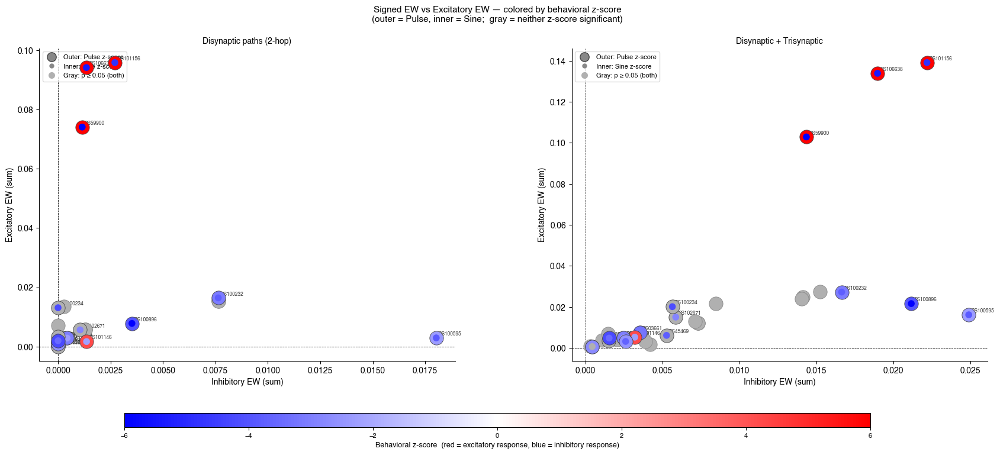

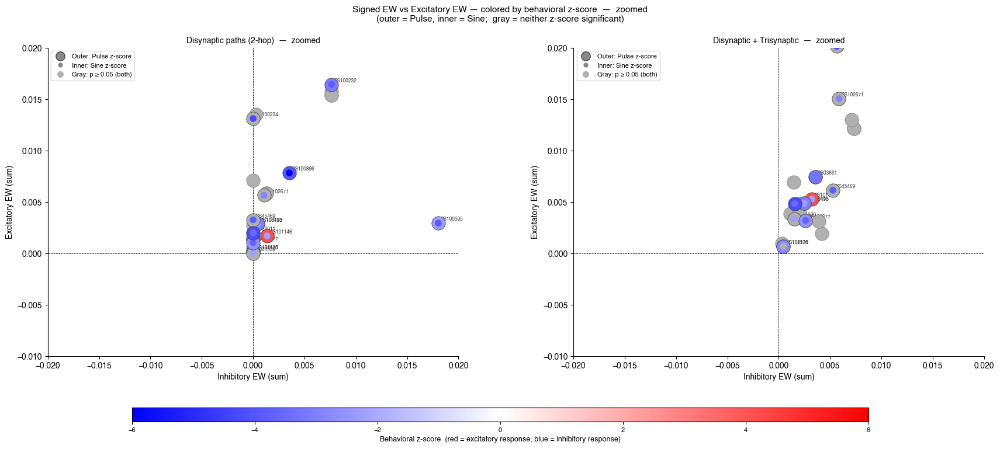

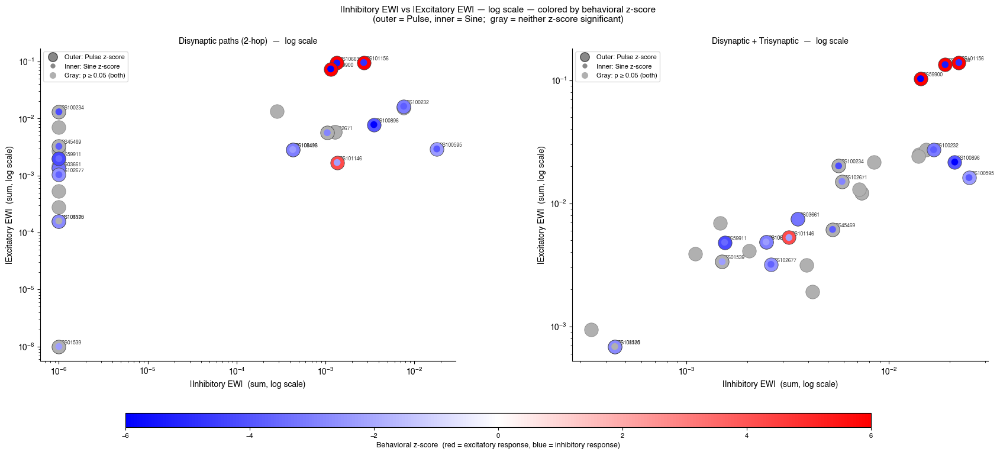

In [92]:
# ── Section 11: Behavioral z-score scatter — Signed EW vs Excitatory EW ──────
# Outer circle = Pulse song z-score; Inner circle = Sine song z-score.
# BWR_CMAP centred at 0; gray = not significant (|p| >= 0.05).
# Insignificant points (both z-scores n.s.) are plotted behind significant ones.
# Labels shown only when at least one z-score is significant.
# Two figure pairs: full range + zoomed (x: ±0.02, y: -0.01..+0.02).
matplotlib.rcParams['svg.fonttype'] = 'none'   # editable text in SVG / Illustrator

_s11_csv = BEHAVIORAL_REPO / 'data' / 'CourtingMaleActivation_ZScores_pValues.csv'
_beh11   = pd.read_csv(_s11_csv)

# Trisynaptic excitatory EW per src_type (signed_path_ew > 0 → excitatory)
_excit3a_s11 = (merged_3a[merged_3a['signed_path_ew'] > 0]
                .groupby('src_type')['path_ew'].sum().to_dict())
_inhib3a_s11 = (merged_3a[merged_3a['signed_path_ew'] < 0]
                .groupby('src_type')['path_ew'].sum().to_dict())

# ── Build per-line EW + z-score table ────────────────────────────────────────
_rows_s11 = []
for _, _r11 in _beh11.iterrows():
    _t11 = parse_pC1_types(str(_r11['CellType']))
    if not _t11:
        continue
    _rows_s11.append({
        'LineName':    _r11['LineName'],
        'CellType':    _r11['CellType'],
        'Pulse_z':     float(_r11['Pulse_Transient']),
        'Pulse_p':     float(_r11['Pulse_pval_Transient'])
                       if pd.notna(_r11['Pulse_pval_Transient']) else 1.0,
        'Sine_z':      float(_r11['Sine_Transient']),
        'Sine_p':      float(_r11['Sine_pval_Transient'])
                       if pd.notna(_r11['Sine_pval_Transient'])  else 1.0,
        'inhib_ew_2':  sum(inhib_by_type.get(t, 0.)                            for t in _t11),
        'excit_ew_2':  sum(excit_by_type.get(t, 0.)                            for t in _t11),
        'inhib_ew_c':  sum(inhib_by_type.get(t, 0.) + _inhib3a_s11.get(t, 0.) for t in _t11),
        'excit_ew_c':  sum(excit_by_type.get(t, 0.) + _excit3a_s11.get(t, 0.) for t in _t11),
    })

_df11 = pd.DataFrame(_rows_s11).reset_index(drop=True)
_df11['pulse_sig'] = _df11['Pulse_p'].abs() < 0.05
_df11['sine_sig']  = _df11['Sine_p'].abs()  < 0.05
_df11['any_sig']   = _df11['pulse_sig'] | _df11['sine_sig']

# ── Colour normalisation: symmetric around 0, max = max |significant z| ──────
_z_sig11 = pd.concat([_df11.loc[_df11['pulse_sig'], 'Pulse_z'],
                       _df11.loc[_df11['sine_sig'],  'Sine_z']])
_z_max11  = 6.0
_z_norm11 = mcolors.TwoSlopeNorm(vmin=-6, vcenter=0., vmax=6)

_GRAY_S11  = '#b0b0b0'
_pulse_c11 = [mcolors.to_hex(BWR_CMAP(_z_norm11(z))) if s else _GRAY_S11
              for z, s in zip(_df11['Pulse_z'], _df11['pulse_sig'])]
_sine_c11  = [mcolors.to_hex(BWR_CMAP(_z_norm11(z))) if s else _GRAY_S11
              for z, s in zip(_df11['Sine_z'],  _df11['sine_sig'])]

_OUTER_S11 = OUTER_MARKER_S
_INNER_S11 = INNER_MARKER_S

import matplotlib.lines as _mlines11

def _draw_s11_panel(ax, x_col, y_col, title, xlim=None, ylim=None, log_scale=False):
    """Draw one scatter panel; insig points go behind sig points."""
    _x  = _df11[x_col].values
    _y  = _df11[y_col].values
    if log_scale:          # absolute values + small floor so log(0) is avoided
        _x = np.abs(_x) + 1e-6
        _y = np.abs(_y) + 1e-6
    # Draw each line's outer+inner as an atomic pair: bg first, fg last
    _any_arr11 = _df11['any_sig'].values
    _ord11     = np.argsort(_any_arr11.astype(int))  # bg (0) before fg (1)
    _fg = list(np.where(_any_arr11)[0])              # used for labels below

    for _k11, _i11 in enumerate(_ord11):
        _zo_pair11 = 20 + _k11 * 2
        _ec_pair11 = '#444444' if _any_arr11[_i11] else '#888888'
        ax.scatter([_x[_i11]], [_y[_i11]],
                   c=[_pulse_c11[_i11]], s=_OUTER_S11, zorder=_zo_pair11,
                   edgecolors=_ec_pair11, linewidths=0.6)
        ax.scatter([_x[_i11]], [_y[_i11]],
                   c=[_sine_c11[_i11]], s=_INNER_S11, zorder=_zo_pair11 + 1,
                   edgecolors='none')

    # Labels only for lines with at least one significant z-score
    for i in _fg:
        ax.annotate(_df11.loc[i, 'LineName'], (_x[i], _y[i]),
                    xytext=(3, 3), textcoords='offset points',
                    fontsize=6, color='#333333', zorder=6,
                    fontfamily='Helvetica')

    if not log_scale:
        ax.axhline(0, color='black', linewidth=0.6, linestyle='--', zorder=1)
        ax.axvline(0, color='black', linewidth=0.6, linestyle='--', zorder=1)
    if log_scale:
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel('|Inhibitory EW|  (sum, log scale)', fontsize=10)
        ax.set_ylabel('|Excitatory EW|  (sum, log scale)', fontsize=10)
    else:
        ax.set_xlabel('Inhibitory EW (sum)', fontsize=10)
        ax.set_ylabel('Excitatory EW (sum)', fontsize=10)
    ax.set_title(title, fontsize=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if xlim is not None: ax.set_xlim(xlim)
    if ylim is not None: ax.set_ylim(ylim)

    ax.legend(handles=[
        _mlines11.Line2D([], [], marker='o', color='w',
            markerfacecolor='#888888', markeredgecolor='#444444',
            markersize=11, label='Outer: Pulse z-score'),
        _mlines11.Line2D([], [], marker='o', color='w',
            markerfacecolor='#888888', markeredgecolor='none',
            markersize=6,  label='Inner: Sine z-score'),
        _mlines11.Line2D([], [], marker='o', color='w',
            markerfacecolor=_GRAY_S11, markeredgecolor='none',
            markersize=8,  label='Gray: p ≥ 0.05 (both)'),
    ], fontsize=8, loc='upper left', framealpha=0.7)

# ── Shared colorbar ScalarMappable ───────────────────────────────────────────
_sm11 = plt.cm.ScalarMappable(
    cmap=BWR_CMAP,
    norm=mcolors.Normalize(vmin=-_z_max11, vmax=_z_max11))
_sm11.set_array([])
_cbar_lbl11 = 'Behavioral z-score  (red = excitatory response, blue = inhibitory response)'

# ── Two figure pairs: full range and zoomed ───────────────────────────────────
for _xlim, _ylim, _fname, _zoom_tag in [
    (None,              None,           'EW_scatter_beh_zscore',      ''),
    ((-0.02, 0.02),     (-0.01, 0.02),  'EW_scatter_beh_zscore_zoom', '  —  zoomed'),
]:
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    fig.suptitle(
        'Signed EW vs Excitatory EW — colored by behavioral z-score' + _zoom_tag + '\n'
        '(outer = Pulse, inner = Sine;  gray = neither z-score significant)',
        fontsize=11)
    # Reserve space at bottom for colorbar; do NOT call tight_layout
    fig.subplots_adjust(left=0.07, right=0.96, top=0.89,
                        bottom=0.23, wspace=0.28)

    _draw_s11_panel(axes[0], 'inhib_ew_2', 'excit_ew_2',
                    'Disynaptic paths (2-hop)' + _zoom_tag, _xlim, _ylim)
    _draw_s11_panel(axes[1], 'inhib_ew_c', 'excit_ew_c',
                    'Disynaptic + Trisynaptic' + _zoom_tag, _xlim, _ylim)

    # Colorbar well below the axes in the reserved space
    _cbar_ax11 = fig.add_axes([0.15, 0.09, 0.70, 0.03])
    _cbar11    = fig.colorbar(_sm11, cax=_cbar_ax11, orientation='horizontal')
    _cbar11.set_label(_cbar_lbl11, fontsize=9)
    _cbar11.ax.tick_params(labelsize=8)

    plt.savefig(RESULTS_DIR / f'{_fname}.svg')
    plt.show()

# ── Log-scale version (absolute values) ──────────────────────────────────────
fig_log, axes_log = plt.subplots(1, 2, figsize=(18, 8))
fig_log.suptitle(
    '|Inhibitory EW| vs |Excitatory EW| — log scale — colored by behavioral z-score\n'
    '(outer = Pulse, inner = Sine;  gray = neither z-score significant)',
    fontsize=11)
fig_log.subplots_adjust(left=0.07, right=0.96, top=0.89,
                        bottom=0.23, wspace=0.28)
_draw_s11_panel(axes_log[0], 'inhib_ew_2', 'excit_ew_2',
                'Disynaptic paths (2-hop)  —  log scale',
                log_scale=True)
_draw_s11_panel(axes_log[1], 'inhib_ew_c', 'excit_ew_c',
                'Disynaptic + Trisynaptic  —  log scale',
                log_scale=True)
_cbar_ax_log = fig_log.add_axes([0.15, 0.09, 0.70, 0.03])
_cbar_log    = fig_log.colorbar(_sm11, cax=_cbar_ax_log, orientation='horizontal')
_cbar_log.set_label(_cbar_lbl11, fontsize=9)
_cbar_log.ax.tick_params(labelsize=8)
matplotlib.rcParams['svg.fonttype'] = 'none'
fig_log.savefig(RESULTS_DIR / 'EW_scatter_beh_zscore_log.pdf', bbox_inches='tight')
fig_log.savefig(RESULTS_DIR / 'EW_scatter_beh_zscore_log.svg', bbox_inches='tight')
plt.show()



Silhouette t-tests (H₀: mean=0, one-sided)  —  disynaptic paths:
    K  mean sil        t          p  sig
    2     0.707    11.62    0.00000  ***
    3     0.828    34.06    0.00000  ***
    4     0.830    23.92    0.00000  ***
    5     0.649    11.33    0.00000  ***
    6     0.615    10.25    0.00000  ***
    7     0.621    11.36    0.00000  ***
    8     0.689    13.02    0.00000  ***


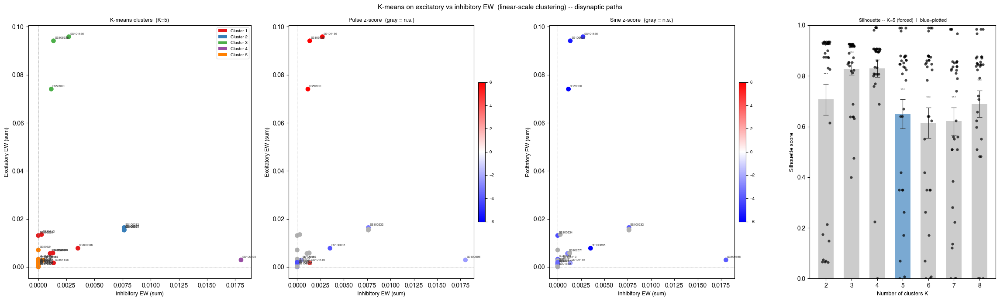


Cluster assignments -- disynaptic paths (linear scale):


,LineName,CellType,Pulse_z,Sine_z,inhib_ew_2,excit_ew_2,Cluster,Sil_Score
0,SS100424,pC1_17ab,0.425444,-0.886712,0.001287,0.005812,1,0.349791
1,SS102696,pC1_17ab,1.076156,-1.809562,0.001287,0.005812,1,0.349791
2,SS108064,pC1_17ab,-0.213571,-0.303228,0.001287,0.005812,1,0.349791
3,SS100896,"pC1_15abc,16b",-3.972192,-6.093087,0.003521,0.007816,1,0.262484
4,SS102671,pC1_15abc,-1.385192,-2.887090,0.001050,0.005638,1,0.171528
5,SS39313,PC1x_ac,-1.780260,-0.884367,0.000286,0.013510,1,0.069239
6,SS101146,pC1_13bc,4.232174,-2.214975,0.001357,0.001690,1,0.007297
7,SS100234,"pC1_4a, 5b, 6b",-0.246399,-4.204242,0.000000,0.013111,1,-0.048919
8,SS106227,"pC1_4b, 8c,19",-0.253757,0.351243,0.007634,0.015701,2,0.989580
9,SS99807,"pC1_8a, 19",0.079995,-0.302893,0.007634,0.015397,2,0.989565


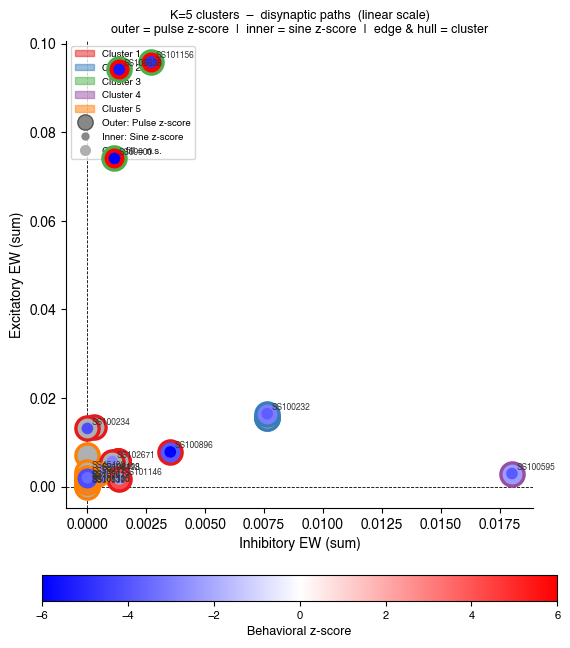


Silhouette t-tests (H₀: mean=0, one-sided)  —  disynaptic paths:
    K  mean sil        t          p  sig
    2     0.637    31.55    0.00000  ***
    3     0.648    23.54    0.00000  ***
    4     0.557    17.45    0.00000  ***
    5     0.537    17.31    0.00000  ***
    6     0.572    15.48    0.00000  ***
    7     0.586    14.35    0.00000  ***
    8     0.590    12.82    0.00000  ***


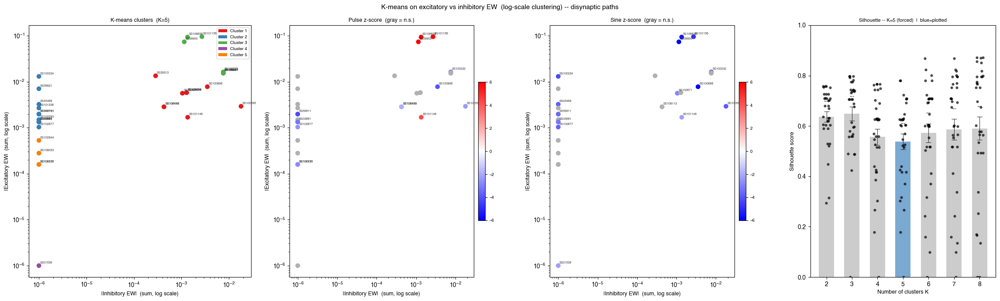


Cluster assignments -- disynaptic paths (log scale):


,LineName,CellType,Pulse_z,Sine_z,inhib_ew_2,excit_ew_2,Cluster,Sil_Score
0,SS102671,pC1_15abc,-1.385192,-2.887090,0.001050,0.005638,1,0.630476
1,SS100424,pC1_17ab,0.425444,-0.886712,0.001287,0.005812,1,0.626483
2,SS102696,pC1_17ab,1.076156,-1.809562,0.001287,0.005812,1,0.626483
3,SS108064,pC1_17ab,-0.213571,-0.303228,0.001287,0.005812,1,0.626483
4,SS108113,pC1_10bd,-3.031310,-2.302295,0.000429,0.002857,1,0.623933
5,SS100498,pC1_10bd,-1.915912,1.238219,0.000429,0.002857,1,0.623933
6,SS101146,pC1_13bc,4.232174,-2.214975,0.001357,0.001690,1,0.569575
7,SS100595,pC1_16a,-2.320791,-3.857951,0.018026,0.002931,1,0.303414
8,SS100896,"pC1_15abc,16b",-3.972192,-6.093087,0.003521,0.007816,1,0.266091
9,SS39313,PC1x_ac,-1.780260,-0.884367,0.000286,0.013510,1,0.177596


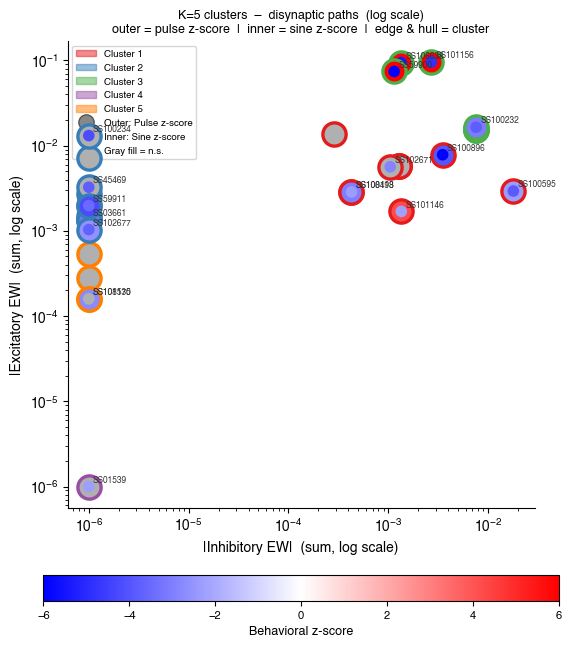


Silhouette t-tests (H₀: mean=0, one-sided)  —  disynaptic + trisynaptic paths:
    K  mean sil        t          p  sig
    2     0.664    13.85    0.00000  ***
    3     0.723    33.85    0.00000  ***
    4     0.624    23.58    0.00000  ***
    5     0.652    23.58    0.00000  ***
    6     0.634    19.13    0.00000  ***
    7     0.551    14.89    0.00000  ***
    8     0.515    12.04    0.00000  ***


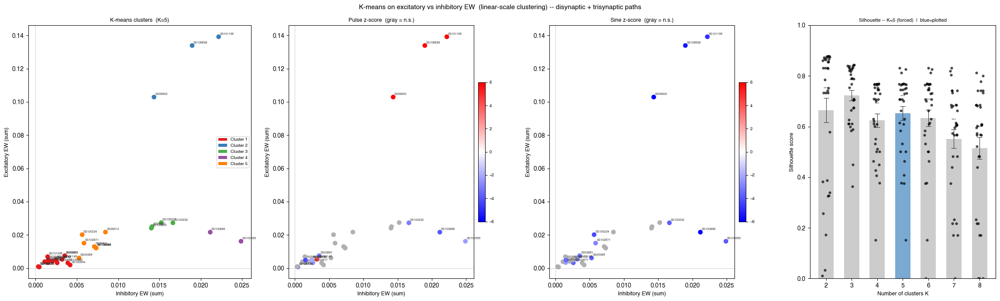


Cluster assignments -- disynaptic + trisynaptic paths (linear scale):


,LineName,CellType,Pulse_z,Sine_z,inhib_ew_c,excit_ew_c,Cluster,Sil_Score
0,SS01539,pC1_12b,-1.510278,-2.259955,0.001499,0.003351,1,0.769038
1,SS99841,"pC1_4a, 4b",-1.700832,-1.499713,0.002038,0.004085,1,0.768317
2,SS59911,pC1x_abd,-4.219345,-3.514400,0.001541,0.004817,1,0.765939
3,SS100769,pC1_1a,0.735046,-1.283454,0.001102,0.003875,1,0.751847
4,SS108113,pC1_10bd,-3.031310,-2.302295,0.002472,0.004849,1,0.744598
5,SS100498,pC1_10bd,-1.915912,1.238219,0.002472,0.004849,1,0.744598
6,SS101336,pC1_3bc,-0.867867,-1.068661,0.001462,0.006896,1,0.731693
7,SS102677,"pC1_4a, 6b",-2.537946,-3.690735,0.002613,0.003190,1,0.730671
8,SS108135,pC1x_a,-2.892074,-1.108433,0.000441,0.000684,1,0.707317
9,SS101570,pC1x_a,-2.748687,-1.626315,0.000441,0.000684,1,0.707317


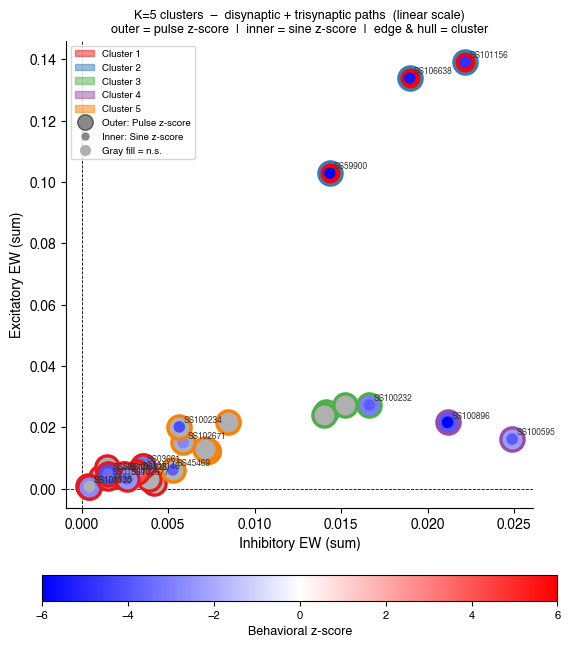


Silhouette t-tests (H₀: mean=0, one-sided)  —  disynaptic + trisynaptic paths:
    K  mean sil        t          p  sig
    2     0.547    24.93    0.00000  ***
    3     0.587    19.86    0.00000  ***
    4     0.609    22.68    0.00000  ***
    5     0.600    16.00    0.00000  ***
    6     0.559    13.04    0.00000  ***
    7     0.587    15.97    0.00000  ***
    8     0.572    14.72    0.00000  ***


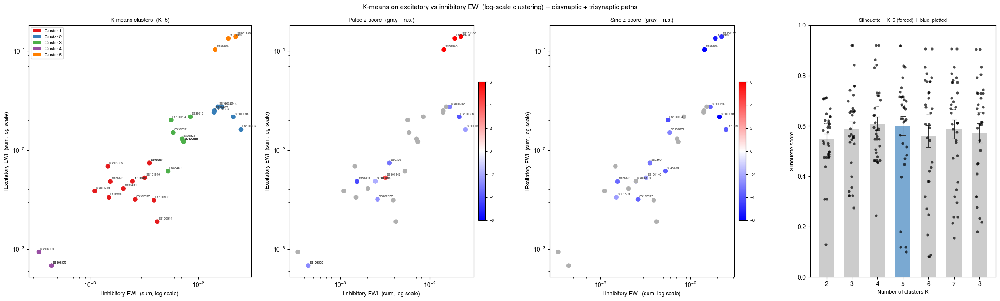


Cluster assignments -- disynaptic + trisynaptic paths (log scale):


,LineName,CellType,Pulse_z,Sine_z,inhib_ew_c,excit_ew_c,Cluster,Sil_Score
0,SS99841,"pC1_4a, 4b",-1.700832,-1.499713,0.002038,0.004085,1,0.667027
1,SS108113,pC1_10bd,-3.031310,-2.302295,0.002472,0.004849,1,0.630339
2,SS100498,pC1_10bd,-1.915912,1.238219,0.002472,0.004849,1,0.630339
3,SS59911,pC1x_abd,-4.219345,-3.514400,0.001541,0.004817,1,0.627136
4,SS102677,"pC1_4a, 6b",-2.537946,-3.690735,0.002613,0.003190,1,0.620342
5,SS01539,pC1_12b,-1.510278,-2.259955,0.001499,0.003351,1,0.616427
6,SS101336,pC1_3bc,-0.867867,-1.068661,0.001462,0.006896,1,0.518119
7,SS100769,pC1_1a,0.735046,-1.283454,0.001102,0.003875,1,0.484973
8,SS101146,pC1_13bc,4.232174,-2.214975,0.003208,0.005265,1,0.470232
9,SS100593,pC1_2ab,-1.596121,1.483027,0.003906,0.003133,1,0.447707


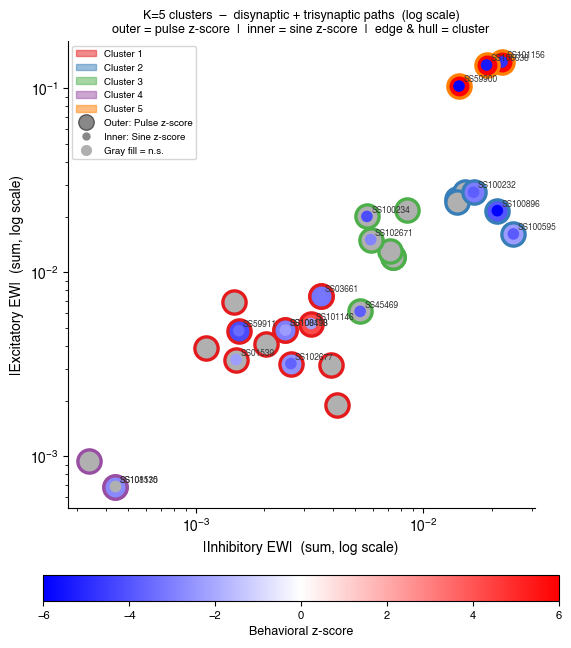

In [93]:
# -- Section 11 K-means: clustering in excit vs inhib EW space ----
# K-means run in both linear and log scale.
# Log-scale version: features = log(|EW| + 1e-6), axes shown in log scale.
# Uses FORCE_K and _run_clustering / _CLUSTER_COLORS from Section 8.
# Outputs: 4-panel figures + cluster-assignment CSVs for each combo.

from sklearn.preprocessing import StandardScaler as _SS11km
from matplotlib.patches import Patch as _Patch11km

def _beh11km_col(z_vals, sig_mask):
    return np.array([
        mcolors.to_rgba(mcolors.to_hex(BWR_CMAP(_z_norm11(float(v))))) if s
        else mcolors.to_rgba(_GRAY_S11)
        for v, s in zip(z_vals, sig_mask)
    ])

for _xcol11, _ycol11, _plbl11, _fn11 in [
    ("inhib_ew_2", "excit_ew_2",
     "disynaptic paths",               "EW_scatter_kmeans_2hop"),
    ("inhib_ew_c", "excit_ew_c",
     "disynaptic + trisynaptic paths",  "EW_scatter_kmeans_combined"),
]:
    for _log11, _stag11 in [(False, "linear"), (True, "log")]:

        # -- Feature matrix --------------------------------------------------
        _X11km = np.column_stack([_df11[_xcol11].values,
                                   _df11[_ycol11].values])
        if _log11:
            _X11km = np.log(np.abs(_X11km) + 1e-6)
        _Xsc11  = _SS11km().fit_transform(_X11km)
        _labs11, _sil11, _k11, _sk11 = _run_clustering(_Xsc11)

        # -- Plot coordinates (log: abs + floor) ----------------------------
        if _log11:
            _xvals = np.abs(_df11[_xcol11].values) + 1e-6
            _yvals = np.abs(_df11[_ycol11].values) + 1e-6
            _xlabel = "|Inhibitory EW|  (sum, log scale)"
            _ylabel = "|Excitatory EW|  (sum, log scale)"
        else:
            _xvals = _df11[_xcol11].values
            _yvals = _df11[_ycol11].values
            _xlabel = "Inhibitory EW (sum)"
            _ylabel = "Excitatory EW (sum)"

        _clr11 = np.array([_CLUSTER_COLORS[l] for l in _labs11])
        _pc11  = _beh11km_col(_df11["Pulse_z"].values, _df11["pulse_sig"].values)
        _sc11  = _beh11km_col(_df11["Sine_z"].values,  _df11["sine_sig"].values)

        fig11k, axes11k = plt.subplots(
            1, 4, figsize=(23, 7),
            gridspec_kw={"width_ratios": [3, 3, 3, 2.5]})

        for _axk, _cols, _ttl, _smask in zip(
            axes11k[:3],
            [_clr11, _pc11, _sc11],
            [f"K-means clusters  (K={_k11})",
             "Pulse z-score  (gray = n.s.)",
             "Sine z-score  (gray = n.s.)"],
            [None, _df11["pulse_sig"].values, _df11["sine_sig"].values],
        ):
            _axk.scatter(_xvals, _yvals, color=_cols, s=60,
                         linewidths=0, zorder=2)
            _lmask = (np.ones(len(_df11), dtype=bool)
                      if _smask is None else _smask)
            for _idx in np.where(_lmask)[0]:
                _axk.annotate(
                    _df11.iloc[_idx]["LineName"],
                    (_xvals[_idx], _yvals[_idx]),
                    fontsize=5, ha="left", va="bottom",
                    xytext=(2, 2), textcoords="offset points",
                    color="#333333", zorder=10)
            if _log11:
                _axk.set_xscale("log")
                _axk.set_yscale("log")
            else:
                _axk.axhline(0, color="gray", lw=0.4, ls="--")
                _axk.axvline(0, color="gray", lw=0.4, ls="--")
            _axk.set_xlabel(_xlabel, fontsize=9)
            _axk.set_ylabel(_ylabel, fontsize=9)
            _axk.set_title(_ttl, fontsize=9)

        axes11k[0].legend(
            handles=[_Patch11km(facecolor=_CLUSTER_COLORS[k], label=f"Cluster {k+1}")
                     for k in range(_k11)],
            fontsize=7, loc="best", frameon=True)

        _sm11k = plt.cm.ScalarMappable(
            cmap=BWR_CMAP,
            norm=mcolors.Normalize(vmin=-_z_max11, vmax=_z_max11))
        _sm11k.set_array([])
        for _axcb in axes11k[1:3]:
            plt.colorbar(_sm11k, ax=_axcb, shrink=0.55,
                         pad=0.02).ax.tick_params(labelsize=7)

        # Silhouette bar plot — mean score per K with individual points
        _ks11    = list(_sil11.keys())
        _bcols = ["#2171b5" if k == _k11 else "#aaaaaa" for k in _ks11]
        _sv11 = [np.mean(_sil11[k]) for k in _ks11]
        _se11 = [np.std(_sil11[k], ddof=1) / np.sqrt(len(_sil11[k])) for k in _ks11]
        axes11k[3].bar(_ks11, _sv11, color=_bcols, alpha=0.6, width=0.6,
                       yerr=_se11, capsize=4,
                       error_kw=dict(elinewidth=0.8, ecolor='#333333', capthick=0.8))
        _rng11k = np.random.default_rng(42)
        for _k11i in _ks11:
            _jit11 = _rng11k.uniform(-0.15, 0.15, size=len(_sil11[_k11i]))
            axes11k[3].scatter(np.full(len(_sil11[_k11i]), _k11i) + _jit11,
                               _sil11[_k11i],
                               color="black", s=20, alpha=0.7,
                               linewidths=0, zorder=5)
        axes11k[3].set_xlabel("Number of clusters K", fontsize=9)
        axes11k[3].set_ylabel("Silhouette score", fontsize=9)
        axes11k[3].set_ylim(0, 1)
        _km_mode = (f"K={_k11} (forced)" if FORCE_K is not None
                    else f"K={_k11} (auto)")
        _sil_tag = "  |  blue=plotted"
        axes11k[3].set_title(f"Silhouette -- {_km_mode}{_sil_tag}", fontsize=8)
        axes11k[3].set_xticks(_ks11)
        from scipy.stats import ttest_1samp as _ttest11
        print(f'\nSilhouette t-tests (H₀: mean=0, one-sided)  —  {_plbl11}:')
        print(f'  {"K":>3}  {"mean sil":>8}  {"t":>7}  {"p":>9}  sig')
        for _kt11, _sv11k, _se11k in zip(_ks11, _sv11, _se11):
            _t11, _p11 = _ttest11(_sil11[_kt11], 0, alternative='greater')
            _sig11 = ('***' if _p11 < 0.001 else '**' if _p11 < 0.01
                      else '*' if _p11 < 0.05 else 'ns')
            print(f'  {_kt11:>3}  {_sv11k:>8.3f}  {_t11:>7.2f}  {_p11:>9.5f}  {_sig11}')
            axes11k[3].text(_kt11, min(_sv11k + _se11k + 0.03, 0.93),
                            _sig11, ha='center', va='bottom', fontsize=7, color='#333333')

        _scale_lbl = "log-scale clustering" if _log11 else "linear-scale clustering"
        fig11k.suptitle(
            f"K-means on excitatory vs inhibitory EW  ({_scale_lbl}) -- {_plbl11}",
            fontsize=11)
        fig11k.tight_layout()
        matplotlib.rcParams["svg.fonttype"] = "none"
        _fn11_s = f"{_fn11}_{_stag11}"
        fig11k.savefig(RESULTS_DIR / f"{_fn11_s}.pdf", bbox_inches="tight")
        fig11k.savefig(RESULTS_DIR / f"{_fn11_s}.svg",  bbox_inches="tight")
        plt.show()

        # Cluster assignment table
        _cdf11 = _df11[["LineName", "CellType",
                         "Pulse_z", "Sine_z", _xcol11, _ycol11]].copy()
        _cdf11["Cluster"]   = _labs11 + 1
        _cdf11["Sil_Score"] = _sil11[_k11]      # per-sample silhouette score
        _cdf11 = (_cdf11.sort_values(["Cluster", "Sil_Score"],
                                      ascending=[True, False])
                         .reset_index(drop=True))
        print(f"\nCluster assignments -- {_plbl11} ({_stag11} scale):")
        display(_cdf11)
        _cdf11.to_csv(
            RESULTS_DIR / f"{_fn11_s}_cluster_assignments.csv", index=False)

        # ── Concentric-circle scatter with cluster hulls & edges ──────────
        _fig_cc11, _ax_cc11 = plt.subplots(figsize=(9, 8))


        # Atomic concentric circles: outer edge = cluster colour
        _any_cc11 = _df11["any_sig"].values
        _ord_cc11 = np.argsort(_any_cc11.astype(int))
        _fg_cc11  = list(np.where(_any_cc11)[0])
        for _kcc11, _icc11 in enumerate(_ord_cc11):
            _zo_cc11 = 20 + _kcc11 * 2
            _ec_cc11 = _CLUSTER_COLORS[_labs11[_icc11]]
            _ax_cc11.scatter([_xvals[_icc11]], [_yvals[_icc11]],
                             c=[_pulse_c11[_icc11]], s=_OUTER_S11,
                             zorder=_zo_cc11,
                             edgecolors=_ec_cc11, linewidths=2.4)
            _ax_cc11.scatter([_xvals[_icc11]], [_yvals[_icc11]],
                             c=[_sine_c11[_icc11]], s=_INNER_S11,
                             zorder=_zo_cc11 + 1, edgecolors="none")

        # Labels for significant lines
        for _icc11 in _fg_cc11:
            _ax_cc11.annotate(
                _df11.loc[_icc11, "LineName"],
                (_xvals[_icc11], _yvals[_icc11]),
                xytext=(3, 3), textcoords="offset points",
                fontsize=6, color="#333333", zorder=200)

        if _log11:
            _ax_cc11.set_xscale("log")
            _ax_cc11.set_yscale("log")
            _ax_cc11.set_xlabel("|Inhibitory EW|  (sum, log scale)", fontsize=10)
            _ax_cc11.set_ylabel("|Excitatory EW|  (sum, log scale)", fontsize=10)
        else:
            _ax_cc11.axhline(0, color="black", lw=0.6, ls="--", zorder=1)
            _ax_cc11.axvline(0, color="black", lw=0.6, ls="--", zorder=1)
            _ax_cc11.set_xlabel("Inhibitory EW (sum)", fontsize=10)
            _ax_cc11.set_ylabel("Excitatory EW (sum)", fontsize=10)

        _ax_cc11.set_title(
            f"K={_k11} clusters  –  {_plbl11}  ({_stag11} scale)\n"
            f"outer = pulse z-score  |  inner = sine z-score  "
            f"|  edge & hull = cluster",
            fontsize=9)
        _ax_cc11.spines["top"].set_visible(False)
        _ax_cc11.spines["right"].set_visible(False)
        _ax_cc11.set_box_aspect(1)

        _leg_cc11 = (
            [_Patch11km(facecolor=_CLUSTER_COLORS[c],
                        edgecolor=_CLUSTER_COLORS[c],
                        alpha=0.5, label=f"Cluster {c + 1}")
             for c in range(_k11)]
            + [_mlines11.Line2D([], [], marker="o", color="w",
                   markerfacecolor="#888888", markeredgecolor="#555555",
                   markersize=11, label="Outer: Pulse z-score"),
               _mlines11.Line2D([], [], marker="o", color="w",
                   markerfacecolor="#888888", markeredgecolor="none",
                   markersize=6,  label="Inner: Sine z-score"),
               _mlines11.Line2D([], [], marker="o", color="w",
                   markerfacecolor=_GRAY_S11, markeredgecolor="none",
                   markersize=8,  label="Gray fill = n.s.")]
        )
        _ax_cc11.legend(handles=_leg_cc11, fontsize=7,
                        loc="upper left", framealpha=0.8)

        _sm_cc11 = plt.cm.ScalarMappable(
            cmap=BWR_CMAP,
            norm=mcolors.Normalize(vmin=-_z_max11, vmax=_z_max11))
        _sm_cc11.set_array([])
        _fig_cc11.subplots_adjust(bottom=0.18)
        _cbar_cc11 = _fig_cc11.colorbar(
            _sm_cc11, ax=_ax_cc11,
            orientation="horizontal", pad=0.12, fraction=0.046)
        _cbar_cc11.set_label("Behavioral z-score", fontsize=9)
        _cbar_cc11.ax.tick_params(labelsize=8)

        matplotlib.rcParams["svg.fonttype"] = "none"
        _fn_cc11 = f"{_fn11}_{_stag11}_beh_zscore_concentric"
        _fig_cc11.savefig(RESULTS_DIR / f"{_fn_cc11}.pdf", bbox_inches="tight")
        _fig_cc11.savefig(RESULTS_DIR / f"{_fn_cc11}.svg",  bbox_inches="tight")
        plt.show()


## Section 12: Silhouette Score Comparison Across Clustering Conditions

Two separate comparisons (conditions within each group share the same feature space):

**Group A — Summed EW (2D):** Disynaptic vs Di+Trisynaptic paths  
**Group B — Per-premotor EW (high-dimensional):** Excit+Inhib (38D) and Excit+GABA+Glu (57D) × Disynaptic vs Di+Trisynaptic paths

Solid lines = disynaptic; dashed lines = di+trisynaptic.  
Shaded bands = ±1 SD across lines.  Filled markers = optimal K per condition.

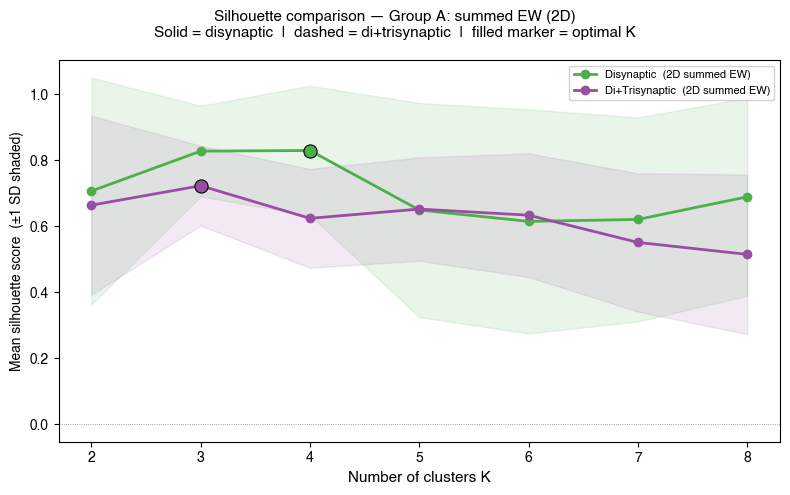

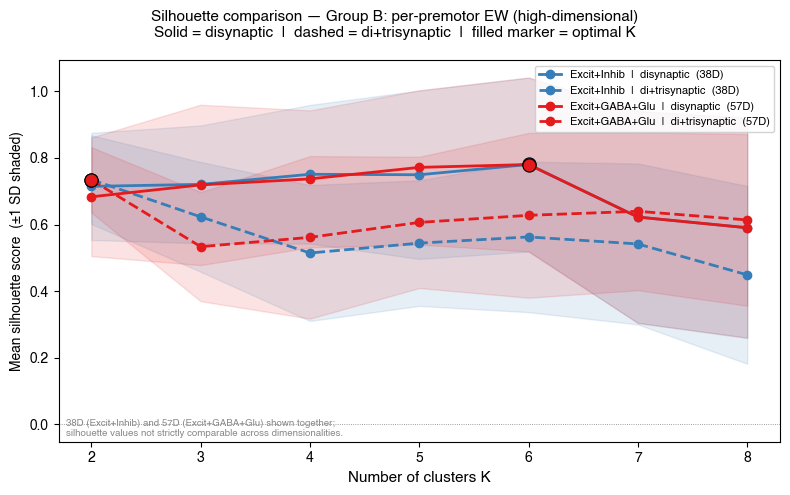

In [94]:
# ── Section 12: silhouette comparison across conditions ─────────────────────
# Group A: conditions 1 & 2 — 2D summed excit vs inhib EW
# Group B: conditions 3–6 — per-premotor EW, high-dimensional
# K range: 2–8  (extended beyond the default 2–6 used in earlier sections)

from sklearn.preprocessing import StandardScaler as _SS12
from sklearn.cluster import KMeans as _KM12
from sklearn.metrics import silhouette_samples as _ss12

_K12 = range(2, 9)

# ── 2D feature matrices (linear scale, matching Section 11 K-means) ─────────
_X12_2hop = _SS12().fit_transform(
    np.column_stack([_df11["inhib_ew_2"].values, _df11["excit_ew_2"].values]))
_X12_comb = _SS12().fit_transform(
    np.column_stack([_df11["inhib_ew_c"].values, _df11["excit_ew_c"].values]))

# ── Conditions ───────────────────────────────────────────────────────────────
_grp_A = [
    (_X12_2hop, "Disynaptic  (2D summed EW)",         "#4daf4a", "-"),
    (_X12_comb, "Di+Trisynaptic  (2D summed EW)",     "#984ea3", "-"),
]
_grp_B = [
    (_X_a_sc,  "Excit+Inhib  |  disynaptic  (38D)",         "#377eb8", "-"),
    (_X_ca_sc, "Excit+Inhib  |  di+trisynaptic  (38D)",     "#377eb8", "--"),
    (_X_b_sc,  "Excit+GABA+Glu  |  disynaptic  (57D)",     "#e41a1c", "-"),
    (_X_cb_sc, "Excit+GABA+Glu  |  di+trisynaptic  (57D)", "#e41a1c", "--"),
]

def _sil_profile12(X_sc, k_range):
    """Dict k -> per-sample silhouette array."""
    out = {}
    for k in k_range:
        labs = _KM12(n_clusters=k, random_state=42, n_init=10).fit_predict(X_sc)
        out[k] = _ss12(X_sc, labs)
    return out

def _draw_sil_cmp12(conds, title, fname, note=None):
    ks = list(_K12)
    fig12, ax12 = plt.subplots(figsize=(8, 5))
    for _X, _lbl, _col, _ls in conds:
        _prof = _sil_profile12(_X, _K12)
        _mn   = np.array([_prof[k].mean() for k in ks])
        _sd   = np.array([_prof[k].std()  for k in ks])
        ax12.plot(ks, _mn, color=_col, ls=_ls, lw=2,
                  marker="o", ms=6, label=_lbl)
        ax12.fill_between(ks, _mn - _sd, _mn + _sd,
                          color=_col, alpha=0.12)
        _best = ks[int(np.argmax(_mn))]
        ax12.scatter([_best], [_mn[ks.index(_best)]],
                     color=_col, s=90, zorder=5,
                     edgecolors="black", lw=0.8)
    ax12.set_xlabel("Number of clusters K", fontsize=11)
    ax12.set_ylabel("Mean silhouette score  (\u00b11 SD shaded)", fontsize=10)
    ax12.set_xticks(ks)
    ax12.axhline(0, color="gray", lw=0.6, ls=":")
    ax12.legend(fontsize=8, loc="best", framealpha=0.85)
    if note:
        ax12.text(0.01, 0.01, note, transform=ax12.transAxes,
                  fontsize=7, color="#888888", va="bottom", style="italic")
    fig12.suptitle(title, fontsize=11)
    fig12.tight_layout()
    matplotlib.rcParams["svg.fonttype"] = "none"
    fig12.savefig(RESULTS_DIR / f"{fname}.pdf", bbox_inches="tight")
    fig12.savefig(RESULTS_DIR / f"{fname}.svg", bbox_inches="tight")
    plt.show()

_draw_sil_cmp12(
    _grp_A,
    "Silhouette comparison — Group A: summed EW (2D)\n"
    "Solid = disynaptic  |  dashed = di+trisynaptic  |  filled marker = optimal K",
    "silhouette_comparison_2D",
)

_draw_sil_cmp12(
    _grp_B,
    "Silhouette comparison — Group B: per-premotor EW (high-dimensional)\n"
    "Solid = disynaptic  |  dashed = di+trisynaptic  |  filled marker = optimal K",
    "silhouette_comparison_highD",
    note="38D (Excit+Inhib) and 57D (Excit+GABA+Glu) shown together;\n"
         "silhouette values not strictly comparable across dimensionalities.",
)


## Section 13: Paper Summary Figures

Three-panel publication figures for each clustering condition.
**A** — PC2 vs PC1 scatter with concentric circles (outer = pulse z-score, inner = sine z-score, edge = cluster assignment, auto K).  
**B** — Silhouette bar chart with SEM error bars and individual data points; blue bar = plotted K.  
**C** — Full PCA loading heatmap (PC1–PC4).


Silhouette t-tests (H₀: mean=0, one-sided)  —  Excitatory + Inhibitory EW  (Disynaptic paths):
    K  mean sil        t          p  sig
    2     0.715    25.13    0.00000  ***
    3     0.721    23.06    0.00000  ***
    4     0.751    20.40    0.00000  ***
    5     0.750    16.78    0.00000  ***
    6     0.780    16.91    0.00000  ***
    7     0.623    11.08    0.00000  ***
    8     0.591    10.11    0.00000  ***


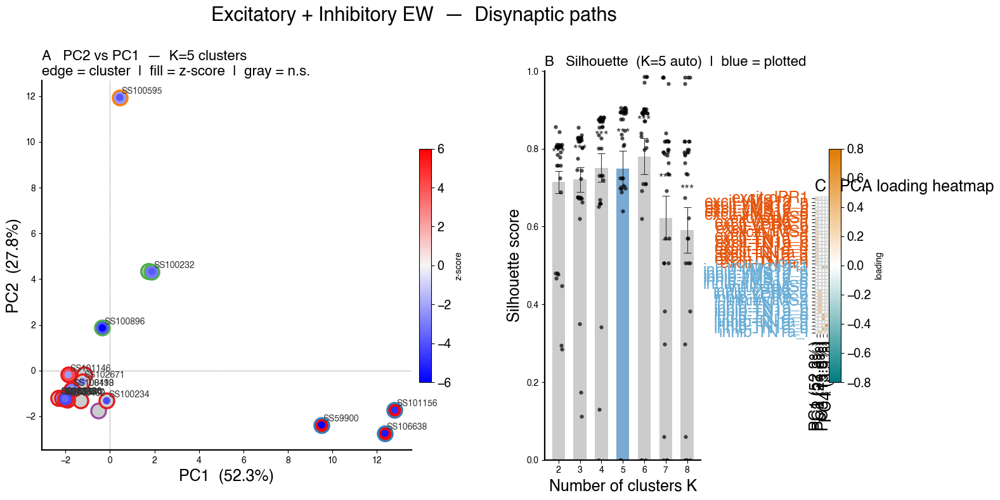


Silhouette t-tests (H₀: mean=0, one-sided)  —  ACh + GABA + Glu EW  (Disynaptic paths):
    K  mean sil        t          p  sig
    2     0.683    21.70    0.00000  ***
    3     0.719    16.89    0.00000  ***
    4     0.737    20.28    0.00000  ***
    5     0.772    18.84    0.00000  ***
    6     0.780    16.91    0.00000  ***
    7     0.623    11.07    0.00000  ***
    8     0.590    10.11    0.00000  ***


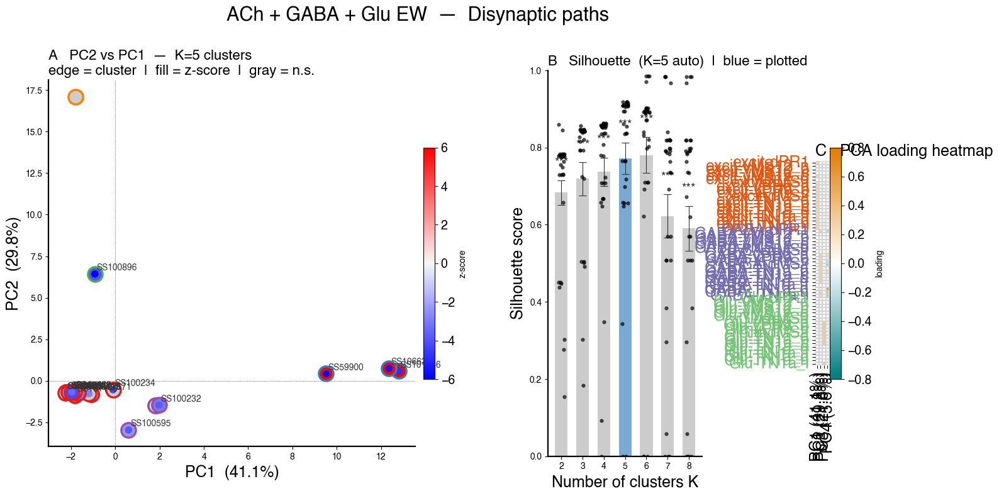


Silhouette t-tests (H₀: mean=0, one-sided)  —  Excitatory + Inhibitory EW  (Disynaptic + Trisynaptic paths):
    K  mean sil        t          p  sig
    2     0.735    31.26    0.00000  ***
    3     0.623    21.39    0.00000  ***
    4     0.515    14.27    0.00000  ***
    5     0.544    16.33    0.00000  ***
    6     0.563    14.09    0.00000  ***
    7     0.542    12.69    0.00000  ***
    8     0.449     9.52    0.00000  ***


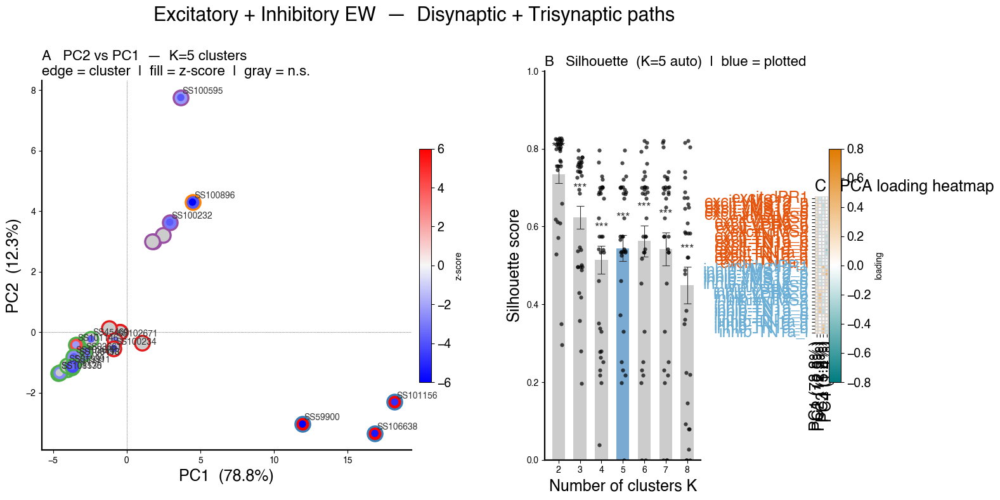

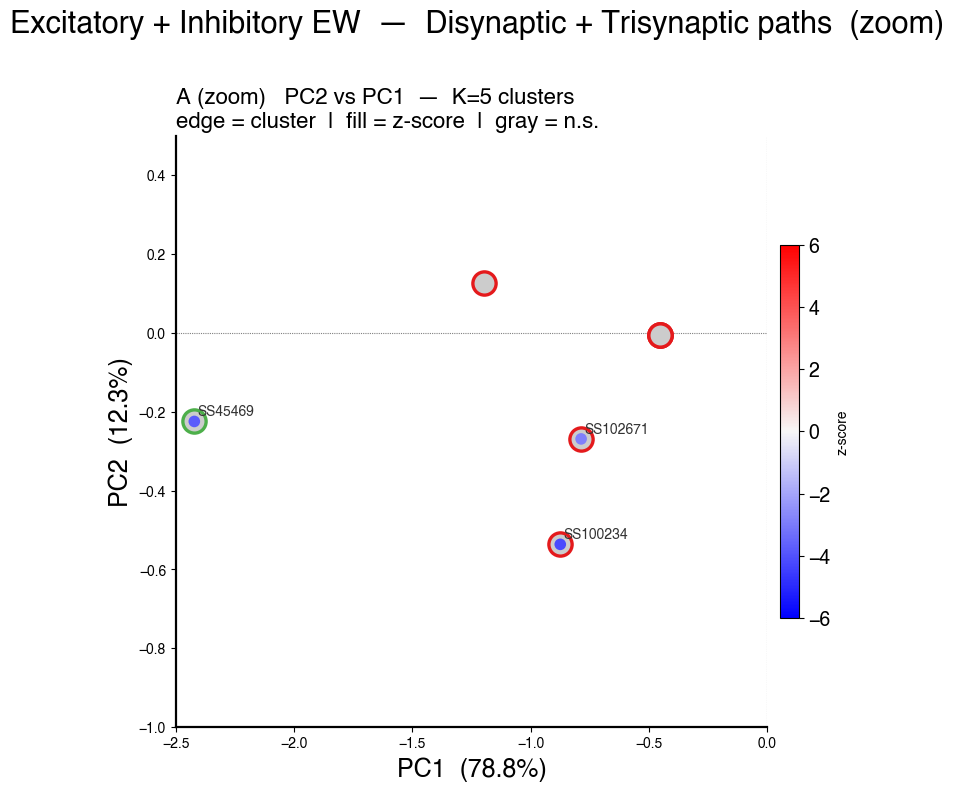


Silhouette t-tests (H₀: mean=0, one-sided)  —  ACh + GABA + Glu EW  (Disynaptic + Trisynaptic paths):
    K  mean sil        t          p  sig
    2     0.734    42.29    0.00000  ***
    3     0.534    18.43    0.00000  ***
    4     0.562    13.02    0.00000  ***
    5     0.606    17.41    0.00000  ***
    6     0.628    14.35    0.00000  ***
    7     0.640    15.27    0.00000  ***
    8     0.614    13.47    0.00000  ***


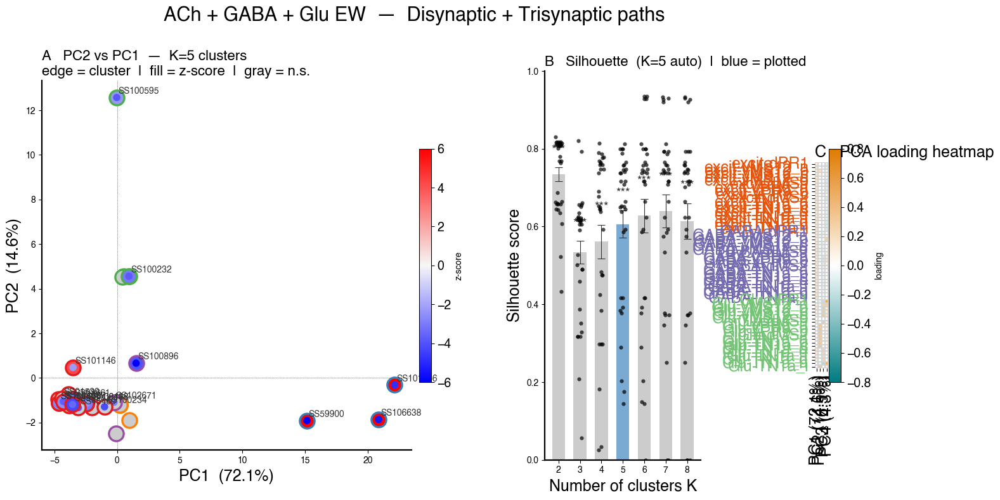

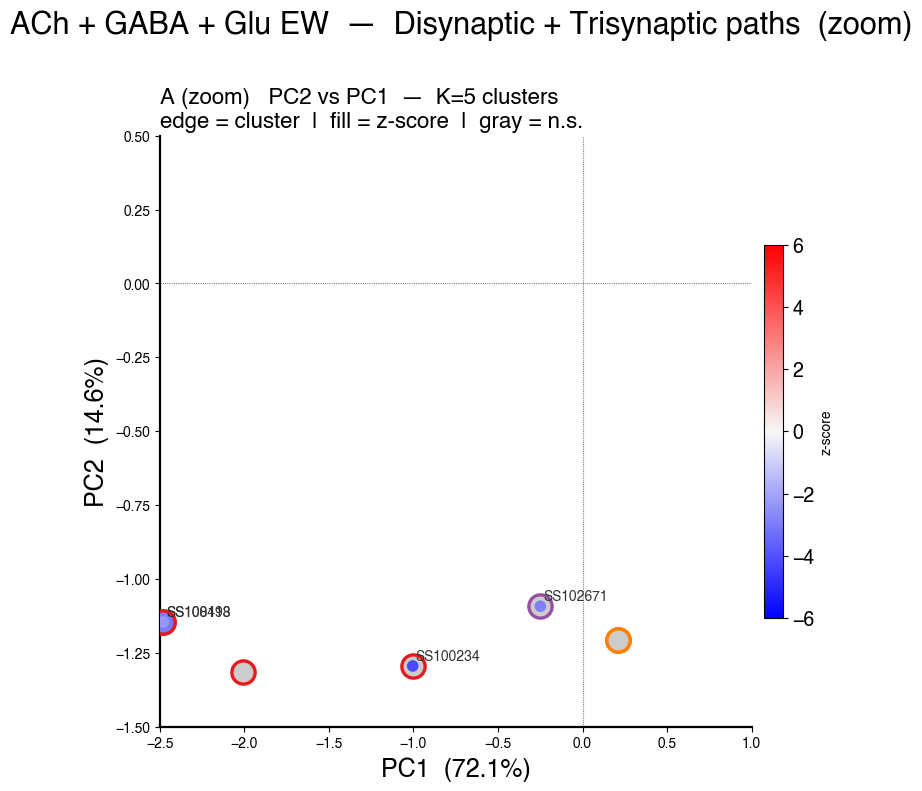


Silhouette t-tests (H₀: mean=0, one-sided)  —  Excit + Inhib + Disinhibitory EW  (Disynaptic + Trisynaptic paths):
    K  mean sil        t          p  sig
    2     0.605    11.05    0.00000  ***
    3     0.686    23.75    0.00000  ***
    4     0.667    22.83    0.00000  ***
    5     0.674    19.13    0.00000  ***
    6     0.502    11.91    0.00000  ***
    7     0.475    10.94    0.00000  ***
    8     0.433     9.20    0.00000  ***


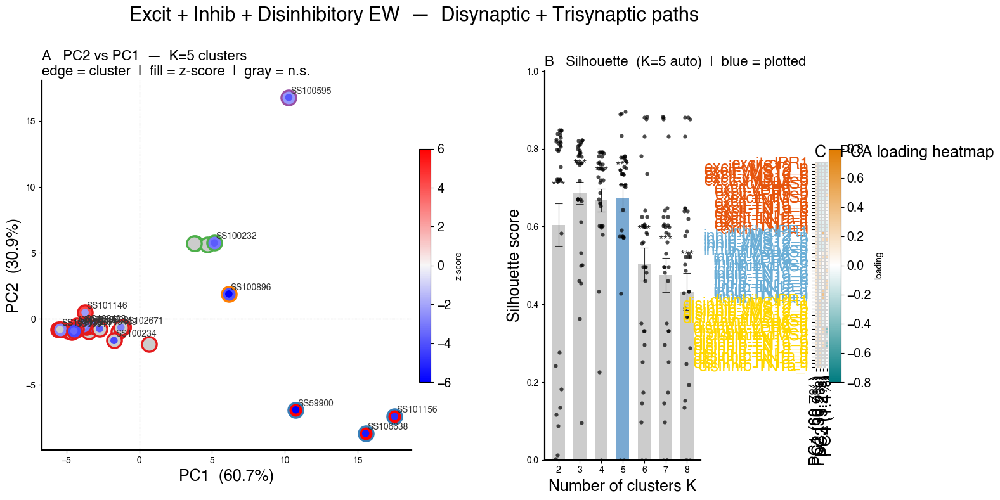


Adjusted Rand Index — Optimal K per condition:
  (1.000 = identical  |  ~0.000 = chance-level)

                                  C1 Dysyn Excit/Inhib     (K=5)   C2 Dysyn ACh/Glu/GABA   (K=5)  C5 Comb  Excit/Inhib/Dis (K=5)
C1 Dysyn Excit/Inhib     (K=5)                             1.000                           0.970                           0.898
C2 Dysyn ACh/Glu/GABA   (K=5)                              0.970                           1.000                           0.898
C5 Comb  Excit/Inhib/Dis (K=5)                             0.898                           0.898                           1.000

Adjusted Rand Index — Fixed K=5 (mode of optimal Ks [5, 5, 5]):
  (1.000 = identical  |  ~0.000 = chance-level)

                                  C1 Dysyn Excit/Inhib     (K=5)   C2 Dysyn ACh/Glu/GABA   (K=5)  C5 Comb  Excit/Inhib/Dis (K=5)
C1 Dysyn Excit/Inhib     (K=5)                             1.000                           0.970                           0.898
C2 Dysyn ACh/Gl

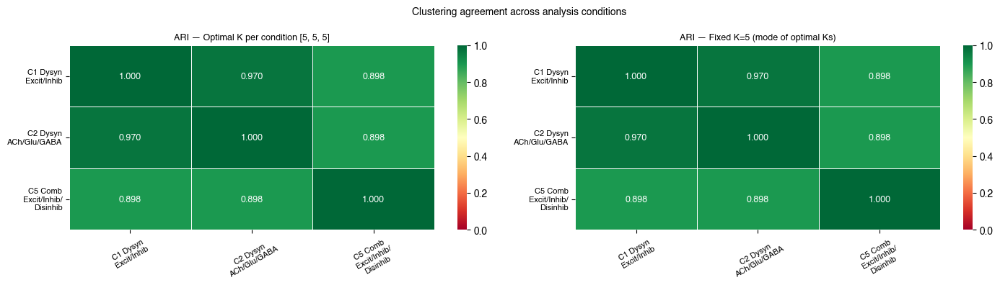

In [95]:
# ── Section 13: Paper summary figures ───────────────────────────────────────
# 3-panel layout per condition:
#   A (top-left)   — PC2 vs PC1, concentric circles, cluster-colored outlines
#   B (bottom-left)— Silhouette bar plot with error bars + individual points
#   C (right)      — PCA loading heatmap (PC1–PC4)
# Clustering always uses force_k=None (auto silhouette selection).

import matplotlib.lines as _mln13
from matplotlib.patches import Patch as _Patch13

def _make_paper_fig(X_sc, df, feature_names, feat_colors,
                    analysis_label, path_label, fname_stem,
                    ref_nf=None, font_scale=1.0,
                    zoom_xlim=None, zoom_ylim=None):
    """
    3-panel publication figure.
    A (top-left):    PC2 vs PC1, concentric circles, cluster-colored edges.
    B (bottom-left): Silhouette bar plot, SEM error bars, individual points.
    C (right):       PCA loading heatmap (PC1–PC4).
    Clustering: force_k=None (auto silhouette selection, independent of FORCE_K).
    """
    # ── Font sizes (scaled) ─────────────────────────────────────────────────
    _fs5,  _fs65, _fs7  = [round(x * font_scale) for x in [5, 6.5, 7]]
    _fs8,  _fs9,  _fs11 = [round(x * font_scale) for x in [8, 9, 11]]
    _load_cmap13 = LinearSegmentedColormap.from_list(
        'teal_amber', ['#007C80', '#ffffff', '#E07B00'])

    # ── PCA 2D (scatter) + full PCA (heatmap) + clustering ───────────────────
    _pca2_13   = PCA(n_components=2)
    _crd2_13   = _pca2_13.fit_transform(X_sc)
    _var2_13   = _pca2_13.explained_variance_ratio_ * 100

    _n_full_13 = min(X_sc.shape[0] - 1, X_sc.shape[1])
    _pcaf_13   = PCA(n_components=_n_full_13)
    _pcaf_13.fit(X_sc)

    _labs13, _sil13, _k13, _ = _run_clustering(X_sc, force_k=None)

    _any13  = df['pulse_sig'].values | df['sine_sig'].values
    _ord13  = np.argsort(_any13.astype(int))
    _pc13   = _beh_colors(df['Pulse_Transient'].values, df['pulse_sig'].values)
    _sc13   = _beh_colors(df['Sine_Transient'].values,  df['sine_sig'].values)

    # ── Figure sizing — 1×3 row layout ──────────────────────────────────────
    _nf13     = len(feature_names)
    _npcs13   = min(4, _pcaf_13.n_components_)
    _silw13   = 2.25 * 1.25                        # silhouette panel width (+25%)
    _nf_ref13 = ref_nf if ref_nf is not None else _nf13  # reference row count
    _fh13     = max(5., min(8., _nf_ref13 * 0.12)) + 1.5  # height from reference rows
    # scatter width: square axes (≈ inner height) + thin vertical colorbar clearance
    _axes_h13 = _fh13 * 0.78                     # inner axes height (gridspec top−bottom)
    _scw13    = _axes_h13 + 0.25                # axes square + ~0.25 in for colorbar
    _hmw13    = _scw13 * _npcs13 / _nf_ref13     # heatmap width from reference rows
    _wspace13 = 0.38 + 0.22 * (font_scale - 1.0)   # grows with font size
    _fw13     = _scw13 + _silw13 + _hmw13 + 1.5 + 2.5 * (font_scale - 1.0)

    fig13 = plt.figure(figsize=(_fw13, _fh13))
    gs13  = fig13.add_gridspec(
        1, 3,
        width_ratios=[_scw13, _silw13, _hmw13],
        wspace=_wspace13,
        left=0.09, right=0.97, top=0.90, bottom=0.12,
    )
    ax_A13 = fig13.add_subplot(gs13[0, 0])
    ax_B13 = fig13.add_subplot(gs13[0, 1])
    ax_C13 = fig13.add_subplot(gs13[0, 2])
    # Match B and C box heights to A's square box side
    ax_B13.set_box_aspect(_scw13 / _silw13)
    ax_C13.set_box_aspect(_nf13 / _npcs13)  # square cells regardless of row count

    # ── Panel A: concentric circles, cluster-colored outlines ────────────────
    for _k13i, _i13 in enumerate(_ord13):
        _zo13  = 20 + _k13i * 2
        _ec13  = _CLUSTER_COLORS[_labs13[_i13]]
        ax_A13.scatter([_crd2_13[_i13, 0]], [_crd2_13[_i13, 1]],
                       c=[_pc13[_i13]], s=OUTER_MARKER_S, zorder=_zo13,
                       edgecolors=_ec13, linewidths=2.4)
        ax_A13.scatter([_crd2_13[_i13, 0]], [_crd2_13[_i13, 1]],
                       c=[_sc13[_i13]], s=INNER_MARKER_S, zorder=_zo13 + 1,
                       edgecolors='none')
    for _j13 in np.where(_any13)[0]:
        ax_A13.annotate(df.iloc[_j13]['LineName'],
                        (_crd2_13[_j13, 0], _crd2_13[_j13, 1]),
                        fontsize=_fs5, xytext=(2, 2), textcoords='offset points',
                        color='#333333', ha='left', va='bottom', zorder=200)
    ax_A13.axhline(0, color='gray', lw=0.8, ls=(0, (1, 1)))
    ax_A13.axvline(0, color='gray', lw=0.8, ls=(0, (1, 1)))
    ax_A13.set_xlabel(f'PC1  ({_var2_13[0]:.1f}%)', fontsize=_fs9)
    ax_A13.set_ylabel(f'PC2  ({_var2_13[1]:.1f}%)', fontsize=_fs9)
    ax_A13.set_title(
        f'A   PC2 vs PC1  —  K={_k13} clusters\n'
        f'edge = cluster  |  fill = z-score  |  gray = n.s.',
        fontsize=_fs8, loc='left')
    ax_A13.spines['top'].set_visible(False)
    ax_A13.spines['right'].set_visible(False)
    ax_A13.set_box_aspect(1)
    for _spA in ['bottom', 'left']:
        ax_A13.spines[_spA].set_linewidth(1.6)


    _sm13 = plt.cm.ScalarMappable(cmap=_bwr_cl, norm=_norm_cl)
    _sm13.set_array([])
    _cbA13 = plt.colorbar(_sm13, ax=ax_A13, orientation='vertical',
                           shrink=0.6, fraction=0.03, pad=0.02,
                           label='z-score')
    _cbA13.ax.tick_params(labelsize=_fs7)
    for _sp13a in _cbA13.ax.spines.values():
        _sp13a.set_edgecolor('black'); _sp13a.set_linewidth(0.8)

    # ── Panel B: silhouette bar plot ─────────────────────────────────────────
    _ks13   = list(_sil13.keys())
    _bc13   = ['#2171b5' if k == _k13 else '#aaaaaa' for k in _ks13]
    _sv13   = [np.mean(_sil13[k]) for k in _ks13]
    _se13   = [np.std(_sil13[k], ddof=1) / np.sqrt(len(_sil13[k])) for k in _ks13]
    ax_B13.bar(_ks13, _sv13, color=_bc13, alpha=0.6, width=0.6,
               yerr=_se13, capsize=4,
               error_kw=dict(elinewidth=0.8, ecolor='#333333', capthick=0.8))
    _rng13 = np.random.default_rng(42)
    for _ki13 in _ks13:
        _jit13 = _rng13.uniform(-0.15, 0.15, size=len(_sil13[_ki13]))
        ax_B13.scatter(np.full(len(_sil13[_ki13]), _ki13) + _jit13,
                       _sil13[_ki13],
                       color='black', s=20, alpha=0.7, linewidths=0, zorder=5)
    ax_B13.set_xlabel('Number of clusters K', fontsize=_fs9)
    ax_B13.set_ylabel('Silhouette score', fontsize=_fs9)
    ax_B13.set_ylim(0, 1)
    ax_B13.set_xticks(_ks13)
    from scipy.stats import ttest_1samp as _ttest13
    print(f'\nSilhouette t-tests (H₀: mean=0, one-sided)  —  {analysis_label}  ({path_label}):')
    print(f'  {"K":>3}  {"mean sil":>8}  {"t":>7}  {"p":>9}  sig')
    for _kt13b, _sv13b, _se13b in zip(_ks13, _sv13, _se13):
        _t13b, _p13b = _ttest13(_sil13[_kt13b], 0, alternative='greater')
        _sig13b = ('***' if _p13b < 0.001 else '**' if _p13b < 0.01
                   else '*' if _p13b < 0.05 else 'ns')
        print(f'  {_kt13b:>3}  {_sv13b:>8.3f}  {_t13b:>7.2f}  {_p13b:>9.5f}  {_sig13b}')
        ax_B13.text(_kt13b, min(_sv13b + _se13b + 0.03, 0.93),
                    _sig13b, ha='center', va='bottom', fontsize=_fs7, color='#333333')
    ax_B13.set_title(f'B   Silhouette  (K={_k13} auto)  |  blue = plotted',
                     fontsize=_fs8, loc='left')
    ax_B13.spines['top'].set_visible(False)
    ax_B13.spines['right'].set_visible(False)
    for _spB in ['bottom', 'left']:
        ax_B13.spines[_spB].set_linewidth(1.6)

    # ── Panel C: PCA loading heatmap ─────────────────────────────────────────
    _lmat13 = pd.DataFrame(
        _pcaf_13.components_[:_npcs13].T,
        index=[f.replace('pos_ew_',  'excit-')
                .replace('neg_ew_',  'inhib-')
                .replace('gaba_ew_', 'GABA-')
                .replace('glu_ew_',  'Glu-')
                .replace('ew__',          '')
                .replace('disinhibitory_ew_', 'disinhib-')
               for f in feature_names],
        columns=[f'PC{i+1} ({_pcaf_13.explained_variance_ratio_[i]*100:.1f}%)'
                 for i in range(_npcs13)],
    )
    sns.heatmap(_lmat13, ax=ax_C13, cmap=_load_cmap13, center=0,
                vmin=-0.8, vmax=0.8,
                linewidths=0.2, linecolor='lightgray',
                yticklabels=True, xticklabels=True,
                cbar=False)
    ax_C13.tick_params(axis='y', labelsize=_fs9)
    ax_C13.tick_params(axis='x', labelsize=_fs9)
    _smC13 = plt.cm.ScalarMappable(cmap=_load_cmap13,
                                    norm=plt.Normalize(vmin=-0.8, vmax=0.8))
    _smC13.set_array([])
    _cbC13 = plt.colorbar(_smC13, ax=ax_C13, orientation='vertical',
                           shrink=0.6, fraction=0.03 * _nf_ref13 / _npcs13,
                           pad=0.02, label='loading')
    _cbC13.ax.tick_params(labelsize=_fs7)
    for _sp13c in _cbC13.ax.spines.values():
        _sp13c.set_edgecolor('black'); _sp13c.set_linewidth(0.8)
    for _tl13 in ax_C13.get_yticklabels():
        _t13 = _tl13.get_text()
        if   _t13.startswith('excit'): _tl13.set_color('#e6550d')
        elif _t13.startswith('GABA'):  _tl13.set_color('#756bb1')
        elif _t13.startswith('Glu'):   _tl13.set_color('#74c476')
        elif _t13.startswith('inhib'):    _tl13.set_color('#6baed6')
        elif _t13.startswith('disinhib'): _tl13.set_color('#FFD700')
    ax_C13.set_title('C   PCA loading heatmap', fontsize=_fs9, loc='left')

    # ── Suptitle + save ───────────────────────────────────────────────────────
    fig13.suptitle(f'{analysis_label}  —  {path_label}',
                   fontsize=_fs11, fontweight='bold')
    matplotlib.rcParams['svg.fonttype'] = 'none'
    fig13.savefig(RESULTS_DIR / f'{fname_stem}_paper_fig.pdf', bbox_inches='tight')
    fig13.savefig(RESULTS_DIR / f'{fname_stem}_paper_fig.svg', bbox_inches='tight')
    plt.show()

    # ── Optional zoom figure (panel A) ───────────────────────────────────────
    if zoom_xlim is not None or zoom_ylim is not None:
        _zfw13 = _scw13 + 1.0
        _zfh13 = _fh13
        _zfig13 = plt.figure(figsize=(_zfw13, _zfh13))
        _zax13  = _zfig13.add_subplot(111)
        _zax13.set_box_aspect(1)
        for _k13i, _i13 in enumerate(_ord13):
            _zo13z = 20 + _k13i * 2
            _ec13z = _CLUSTER_COLORS[_labs13[_i13]]
            _zax13.scatter([_crd2_13[_i13, 0]], [_crd2_13[_i13, 1]],
                           c=[_pc13[_i13]], s=OUTER_MARKER_S, zorder=_zo13z,
                           edgecolors=_ec13z, linewidths=2.4)
            _zax13.scatter([_crd2_13[_i13, 0]], [_crd2_13[_i13, 1]],
                           c=[_sc13[_i13]], s=INNER_MARKER_S, zorder=_zo13z + 1,
                           edgecolors='none')
        for _j13z in np.where(_any13)[0]:
            _zax13.annotate(df.iloc[_j13z]['LineName'],
                            (_crd2_13[_j13z, 0], _crd2_13[_j13z, 1]),
                            fontsize=_fs5, xytext=(2, 2), textcoords='offset points',
                            color='#333333', ha='left', va='bottom', zorder=200)
        _zax13.axhline(0, color='gray', lw=0.8, ls=(0, (1, 1)))
        _zax13.axvline(0, color='gray', lw=0.8, ls=(0, (1, 1)))
        if zoom_xlim is not None:
            _zax13.set_xlim(zoom_xlim)
        if zoom_ylim is not None:
            _zax13.set_ylim(zoom_ylim)
        _zax13.set_xlabel(f'PC1  ({_var2_13[0]:.1f}%)', fontsize=_fs9)
        _zax13.set_ylabel(f'PC2  ({_var2_13[1]:.1f}%)', fontsize=_fs9)
        _zax13.set_title(
            f'A (zoom)   PC2 vs PC1  —  K={_k13} clusters\n'
            f'edge = cluster  |  fill = z-score  |  gray = n.s.',
            fontsize=_fs8, loc='left')
        _zax13.spines['top'].set_visible(False)
        _zax13.spines['right'].set_visible(False)
        for _spZ in ['bottom', 'left']:
            _zax13.spines[_spZ].set_linewidth(1.6)
        _zsm13 = plt.cm.ScalarMappable(cmap=_bwr_cl, norm=_norm_cl)
        _zsm13.set_array([])
        _zcb13 = plt.colorbar(_zsm13, ax=_zax13, orientation='vertical',
                              shrink=0.6, fraction=0.03, pad=0.02, label='z-score')
        _zcb13.ax.tick_params(labelsize=_fs7)
        for _sp13z in _zcb13.ax.spines.values():
            _sp13z.set_edgecolor('black'); _sp13z.set_linewidth(0.8)
        _zfig13.suptitle(f'{analysis_label}  —  {path_label}  (zoom)',
                         fontsize=_fs11, fontweight='bold')
        _zfig13.savefig(RESULTS_DIR / f'{fname_stem}_paper_fig_zoom.pdf', bbox_inches='tight')
        _zfig13.savefig(RESULTS_DIR / f'{fname_stem}_paper_fig_zoom.svg', bbox_inches='tight')
        plt.show()

    return _labs13, _k13

# ── 4 conditions — EW analysis (Sections 8 & 9) ──────────────────────────────
# Block-scaled disynaptic matrices (matching _plot_analysis calls in cells 41/42;
# cell 43 overwrites _X_a_sc/_X_b_sc with single-scaler so we rebuild here).
_pos_f13  = [f'pos_ew_{pm}'  for pm in PREMOTOR_TARGETS]
_neg_f13  = [f'neg_ew_{pm}'  for pm in PREMOTOR_TARGETS]
_gaba_f13 = [f'gaba_ew_{pm}' for pm in PREMOTOR_TARGETS]
_glu_f13  = [f'glu_ew_{pm}'  for pm in PREMOTOR_TARGETS]

_X13_1 = np.hstack([
    StandardScaler().fit_transform(_df_cl[_pos_f13].values),
    StandardScaler().fit_transform(_df_cl[_neg_f13].abs().values),
])
_X13_2 = np.hstack([
    StandardScaler().fit_transform(_df_cl[_pos_f13].values),
    StandardScaler().fit_transform(_df_cl[_gaba_f13].values),
    StandardScaler().fit_transform(_df_cl[_glu_f13].values),
])
_feats13_1 = _pos_f13 + _neg_f13
_cols13_1  = ['#e6550d'] * len(_pos_f13) + ['#6baed6'] * len(_neg_f13)
_feats13_2 = _pos_f13 + _gaba_f13 + _glu_f13
_cols13_2  = (['#e6550d'] * len(_pos_f13) +
               ['#756bb1'] * len(_gaba_f13) +
               ['#74c476'] * len(_glu_f13))


# ── Condition 5: Disynaptic + Trisynaptic — Excit / Inhib / Disinhibitory ────
_3a_disinhib_c5   = merged_3a[(merged_3a['inter1_sign'] < 0) & (merged_3a['inter2_sign'] < 0)]
_3a_nodisinhib_c5 = merged_3a[~((merged_3a['inter1_sign'] < 0) & (merged_3a['inter2_sign'] < 0))]

_combined_c5 = pd.concat([
    merged_all[['src_type', 'premotor_type', 'signed_path_ew']],
    _3a_nodisinhib_c5[['src_type', 'premotor_type', 'signed_path_ew']]
], ignore_index=True)
_ss_c5 = build_ss_ew_pt(_combined_c5)

_df_cc = _ss_c5.merge(
    beh[['LineName', 'Pulse_Transient', 'Sine_Transient',
         'Pulse_pval_Transient', 'Sine_pval_Transient']], on='LineName')
_df_cc['pulse_sig'] = _df_cc['Pulse_pval_Transient'].abs() < 0.05
_df_cc['sine_sig']  = _df_cc['Sine_pval_Transient'].abs()  < 0.05

# Build disinhibitory EW per SS line per premotor target
_disinhib_dict5 = (
    _3a_disinhib_c5
    .groupby(['src_type', 'premotor_type'])['signed_path_ew']
    .sum().to_dict()
)
_disinhib_rows5 = []
for _, _row5 in beh.iterrows():
    _types5 = parse_pC1_types(str(_row5['CellType']))
    if not _types5:
        continue
    _entry5 = {'LineName': _row5['LineName']}
    for pm_grp, pm_subs in PREMOTOR_GROUPS.items():
        _entry5[f'disinhibitory_ew_{pm_grp}'] = sum(
            _disinhib_dict5.get((t, sub), 0.) for t in _types5 for sub in pm_subs)
    _disinhib_rows5.append(_entry5)
_df_cc = _df_cc.merge(pd.DataFrame(_disinhib_rows5), on='LineName')

_pos_feats_cc = [f'pos_ew_{pm}'           for pm in PREMOTOR_TARGETS]
_neg_feats_cc = [f'neg_ew_{pm}'           for pm in PREMOTOR_TARGETS]
_dis_feats_cc = [f'disinhibitory_ew_{pm}' for pm in PREMOTOR_TARGETS]
_feats_cc     = _pos_feats_cc + _neg_feats_cc + _dis_feats_cc   # 18 features
_colors_cc    = (['#e6550d'] * len(_pos_feats_cc) +   # orange  — excitatory
                 ['#6baed6'] * len(_neg_feats_cc) +   # blue    — inhibitory
                 ['#FFD700'] * len(_dis_feats_cc))    # gold    — disinhibitory

_X_cc_sc = np.hstack([
    StandardScaler().fit_transform(_df_cc[_pos_feats_cc].values),
    StandardScaler().fit_transform(_df_cc[_neg_feats_cc].abs().values),
    StandardScaler().fit_transform(_df_cc[_dis_feats_cc].values),
])

# Shared panel sizing: reference row count = max features across all 5 conditions
_ref_nf13 = max(len(_feats13_1), len(_feats13_2), len(_feats_ca), len(_feats_cb), len(_feats_cc))

# Condition 1: Disynaptic — Excitatory + Inhibitory EW
_labs13_c1, _k13_c1 = _make_paper_fig(_X13_1, _df_cl, _feats13_1, _cols13_1,
                'Excitatory + Inhibitory EW', 'Disynaptic paths',
                'paper_dysyn_excit_inhib', ref_nf=_ref_nf13, font_scale=2.0)

# Condition 2: Disynaptic — ACh + GABA + Glu EW
_labs13_c2, _k13_c2 = _make_paper_fig(_X13_2, _df_cl, _feats13_2, _cols13_2,
                'ACh + GABA + Glu EW', 'Disynaptic paths',
                'paper_dysyn_nt', ref_nf=_ref_nf13, font_scale=2.0)

# Condition 3: Disynaptic + Trisynaptic — Excitatory + Inhibitory EW
# _X_ca_sc / _feats_ca / _colors_ca from Section 9 loading cell (not overwritten)
_labs13_c3, _k13_c3 = _make_paper_fig(_X_ca_sc, _df_cl_comb, _feats_ca, _colors_ca,
                'Excitatory + Inhibitory EW', 'Disynaptic + Trisynaptic paths',
                'paper_comb_excit_inhib', ref_nf=_ref_nf13, font_scale=2.0,
                zoom_xlim=(-2.5, 0.), zoom_ylim=(-1., 0.5))

# Condition 4: Disynaptic + Trisynaptic — ACh + GABA + Glu EW
_labs13_c4, _k13_c4 = _make_paper_fig(_X_cb_sc, _df_cl_comb, _feats_cb, _colors_cb,
                'ACh + GABA + Glu EW', 'Disynaptic + Trisynaptic paths',
                'paper_comb_nt', ref_nf=_ref_nf13, font_scale=2.0,
                zoom_xlim=(-2.5, 1.), zoom_ylim=(-1.5, 0.5))

# Condition 5: Disynaptic + Trisynaptic — Excit + Inhib + Disinhibitory EW
_labs13_c5, _k13_c5 = _make_paper_fig(_X_cc_sc, _df_cc, _feats_cc, _colors_cc,
                'Excit + Inhib + Disinhibitory EW', 'Disynaptic + Trisynaptic paths',
                'paper_comb_excit_inhib_disinhibitory', ref_nf=_ref_nf13, font_scale=2.0)
# ── ARI: optimal-K and fixed-K comparisons ───────────────────────────────────
from sklearn.metrics import adjusted_rand_score as _ari13
from collections import Counter as _Counter13

# ── Select which conditions to include in the ARI heatmap (any subset of 1–5) ─
_ari_conditions = [1, 2, 5]   # ← edit this list to change which conditions appear

# Full registry of all 5 conditions
_all_labs13  = [_labs13_c1, _labs13_c2, _labs13_c3, _labs13_c4, _labs13_c5]
_all_ks13    = [_k13_c1,    _k13_c2,    _k13_c3,    _k13_c4,    _k13_c5   ]
_all_X13     = [_X13_1,     _X13_2,     _X_ca_sc,   _X_cb_sc,   _X_cc_sc  ]
_all_short13 = ['C1 Dysyn\nExcit/Inhib',   'C2 Dysyn\nACh/Glu/GABA',
                'C3 Comb\nExcit/Inhib',    'C4 Comb\nACh/Glu/GABA',
                'C5 Comb\nExcit/Inhib/\nDisinhib']
_all_full13  = ['C1 Dysyn Excit/Inhib    ',
                'C2 Dysyn ACh/Glu/GABA  ',
                'C3 Comb  Excit/Inhib   ',
                'C4 Comb  ACh/Glu/GABA  ',
                'C5 Comb  Excit/Inhib/Dis']

_idx13       = [c - 1 for c in _ari_conditions]
_opt_labs13  = [_all_labs13[i]  for i in _idx13]
_opt_ks13    = [_all_ks13[i]    for i in _idx13]
_X_ari13     = [_all_X13[i]     for i in _idx13]
_short_lbl13 = [_all_short13[i] for i in _idx13]
_full_lbl13  = [f'{_all_full13[i]} (K={_all_ks13[i]})' for i in _idx13]
_nc13 = len(_opt_labs13)
_ari_opt13 = np.array([[1. if i == j else _ari13(_opt_labs13[i], _opt_labs13[j])
                        for j in range(_nc13)] for i in range(_nc13)])

# Fixed-K labels and matrix (K = mode of optimal Ks)
_k_cnt13   = _Counter13(_opt_ks13)
_k_fixed13 = min(k for k, c in _k_cnt13.items() if c == max(_k_cnt13.values()))
_fk_labs13 = [_run_clustering(X, force_k=_k_fixed13)[0] for X in _X_ari13]
_ari_fk13  = np.array([[1. if i == j else _ari13(_fk_labs13[i], _fk_labs13[j])
                        for j in range(_nc13)] for i in range(_nc13)])

_w13 = max(len(l) for l in _full_lbl13) + 2
for _title13, _mat13, _lk13 in [
    ('Optimal K per condition', _ari_opt13, str(_opt_ks13)),
    (f'Fixed K={_k_fixed13} (mode of optimal Ks {_opt_ks13})', _ari_fk13, ''),
]:
    print(f'\nAdjusted Rand Index — {_title13}:')
    print('  (1.000 = identical  |  ~0.000 = chance-level)\n')
    print(' ' * _w13 + ''.join(f'{l:>{_w13}}' for l in _full_lbl13))
    for _i13, _lbl_i in enumerate(_full_lbl13):
        print(f'{_lbl_i:<{_w13}}'
              + ''.join(f'{_mat13[_i13, _j13]:>{_w13}.3f}'
                        for _j13 in range(_nc13)))
_fw_ari13 = 4 + 3.5 * _nc13
_fh_ari13 = max(3, _nc13 + 1)
_fig_ari13, _axs_ari13 = plt.subplots(1, 2, figsize=(_fw_ari13, _fh_ari13))
for _ax13, _mat13, _ttl13 in zip(
        _axs_ari13,
        [_ari_opt13, _ari_fk13],
        [f'ARI — Optimal K per condition {_opt_ks13}',
         f'ARI — Fixed K={_k_fixed13} (mode of optimal Ks)']):
    _df_ari13 = pd.DataFrame(_mat13,
                             index=_short_lbl13, columns=_short_lbl13)
    sns.heatmap(_df_ari13, ax=_ax13, vmin=0, vmax=1, cmap='RdYlGn',
                annot=True, fmt='.3f', linewidths=0.5, linecolor='white',
                annot_kws={'size': 9})
    _ax13.set_title(_ttl13, fontsize=9)
    _ax13.tick_params(axis='x', labelsize=8, rotation=30)
    _ax13.tick_params(axis='y', labelsize=8, rotation=0)
_fig_ari13.suptitle('Clustering agreement across analysis conditions',
                    fontsize=10, fontweight='bold')
_fig_ari13.tight_layout()
matplotlib.rcParams['svg.fonttype'] = 'none'
_fig_ari13.savefig(RESULTS_DIR / 'paper_ari_heatmaps.pdf', bbox_inches='tight')
_fig_ari13.savefig(RESULTS_DIR / 'paper_ari_heatmaps.svg', bbox_inches='tight')
plt.show()

